In [30]:
мец патмуцюн покрик кахакум


from dotenv import load_dotenv
import os
import clickhouse_connect
import pandas as pd

# Загружаем .env
load_dotenv(".env")

CLICKHOUSE_HOST = os.getenv("CLICKHOUSE_HOST")
CLICKHOUSE_PORT = int(os.getenv("CLICKHOUSE_PORT", "8123"))
CLICKHOUSE_DB = os.getenv("CLICKHOUSE_DB", "polyk")
CLICKHOUSE_USER = os.getenv("CLICKHOUSE_USER")
CLICKHOUSE_PASSWORD = os.getenv("CLICKHOUSE_PASSWORD")

c = clickhouse_connect.get_client(
    host=CLICKHOUSE_HOST,
    port=CLICKHOUSE_PORT,
    username=CLICKHOUSE_USER,
    password=CLICKHOUSE_PASSWORD,
    database=CLICKHOUSE_DB,
)

print("Connected to:", CLICKHOUSE_DB)

SyntaxError: invalid syntax (1655288909.py, line 1)

In [ ]:


from dotenv import load_dotenv
import os
import clickhouse_connect
import pandas as pd

# Загружаем .env
load_dotenv(".env")

CLICKHOUSE_HOST = os.getenv("CLICKHOUSE_HOST")
CLICKHOUSE_PORT = int(os.getenv("CLICKHOUSE_PORT", "8123"))
CLICKHOUSE_DB = os.getenv("CLICKHOUSE_DB", "polyk")
CLICKHOUSE_USER = os.getenv("CLICKHOUSE_USER")
CLICKHOUSE_PASSWORD = os.getenv("CLICKHOUSE_PASSWORD")

c = clickhouse_connect.get_client(
    host=CLICKHOUSE_HOST,
    port=CLICKHOUSE_PORT,
    username=CLICKHOUSE_USER,
    password=CLICKHOUSE_PASSWORD,
    database=CLICKHOUSE_DB,
)

print("Connected to:", CLICKHOUSE_DB)

Connected to: polyk


In [ ]:
q = "SELECT * FROM polyk.pm_top_of_book ORDER BY event_ts_ms DESC LIMIT 20"
res = client.query(q)
import pandas as pd
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


NameError: name 'client' is not defined

In [ ]:
q = "SELECT * FROM polyk.pm_top_of_book ORDER BY event_ts_ms DESC LIMIT 20"
res = c.query(q)
import pandas as pd
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


,ingest_time,market,event_ts_ms,asset_id,outcome,best_bid_price,best_bid_size,best_ask_price,best_ask_size,source
0,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100661018,1019296209389274395304303501832959150233627133...,UP,0.61,121.74,0.63,1124.00,orderbook
1,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,74.23,orderbook
2,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,2879903950077237607002215362357017698383898408...,DOWN,0.38,74.23,0.39,38.00,orderbook
3,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,2879903950077237607002215362357017698383898408...,DOWN,0.38,76.98,0.39,38.00,orderbook
4,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,76.98,orderbook
5,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660695,2879903950077237607002215362357017698383898408...,DOWN,0.38,71.98,0.39,48.00,orderbook
6,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660695,1019296209389274395304303501832959150233627133...,UP,0.61,48.00,0.62,71.98,orderbook
7,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660688,2879903950077237607002215362357017698383898408...,DOWN,0.38,71.98,0.39,53.00,orderbook
8,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660688,1019296209389274395304303501832959150233627133...,UP,0.61,53.00,0.62,71.98,orderbook
9,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660519,2879903950077237607002215362357017698383898408...,DOWN,0.38,102.98,0.39,60.48,orderbook


In [ ]:
c.command("SET asterisk_include_materialized_columns = 1")


DatabaseError: HTTP driver received HTTP status 404, server response: Code: 115, e.displayText() = DB::Exception: Unknown setting asterisk_include_materialized_columns, e.what() = DB::Exception (for url http://89.169.153.71:8123)

In [ ]:
c = clickhouse_connect.get_client(..., settings={"asterisk_include_materialized_columns": 1})


TypeError: create_client() takes 0 positional arguments but 1 positional argument (and 1 keyword-only argument) were given

In [ ]:
c.query("DESCRIBE TABLE polyk.pm_top_of_book").result_rows


[('ingest_time', 'DateTime', '', '', ''),
 ('market', 'String', '', '', ''),
 ('event_ts_ms', 'UInt64', '', '', ''),
 ('asset_id', 'String', '', '', ''),
 ('outcome', 'String', '', '', ''),
 ('best_bid_price', 'Float64', '', '', ''),
 ('best_bid_size', 'Float64', '', '', ''),
 ('best_ask_price', 'Float64', '', '', ''),
 ('best_ask_size', 'Float64', '', '', ''),
 ('source', 'String', '', '', ''),
 ('event_time_msk',
  'DateTime',
  'MATERIALIZED',
  "toTimeZone(toDateTime(event_ts_ms / 1000), 'Europe/Moscow')",
  '')]

In [ ]:
q = """
SELECT ingest_time, market, event_ts_ms, event_time_msk, asset_id, outcome,
       best_bid_price, best_bid_size, best_ask_price, best_ask_size, source
FROM polyk.pm_top_of_book
ORDER BY event_ts_ms DESC
LIMIT 20
"""
res = c.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df





,ingest_time,market,event_ts_ms,event_time_msk,asset_id,outcome,best_bid_price,best_bid_size,best_ask_price,best_ask_size,source
0,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100661018,2026-02-14 20:24:21,1019296209389274395304303501832959150233627133...,UP,0.61,121.74,0.63,1124.00,orderbook
1,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,74.23,orderbook
2,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,74.23,0.39,38.00,orderbook
3,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,76.98,0.39,38.00,orderbook
4,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,76.98,orderbook
5,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660695,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,71.98,0.39,48.00,orderbook
6,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660695,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,48.00,0.62,71.98,orderbook
7,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660688,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,71.98,0.39,53.00,orderbook
8,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660688,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,53.00,0.62,71.98,orderbook
9,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660519,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,102.98,0.39,60.48,orderbook


In [ ]:
df

,ingest_time,market,event_ts_ms,event_time_msk,asset_id,outcome,best_bid_price,best_bid_size,best_ask_price,best_ask_size,source
0,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100661018,2026-02-14 20:24:21,1019296209389274395304303501832959150233627133...,UP,0.61,121.74,0.63,1124.00,orderbook
1,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,74.23,orderbook
2,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,74.23,0.39,38.00,orderbook
3,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,76.98,0.39,38.00,orderbook
4,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,76.98,orderbook
5,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660695,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,71.98,0.39,48.00,orderbook
6,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660695,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,48.00,0.62,71.98,orderbook
7,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660688,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,71.98,0.39,53.00,orderbook
8,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660688,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,53.00,0.62,71.98,orderbook
9,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660519,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,102.98,0.39,60.48,orderbook


In [ ]:
q = """
SELECT ingest_time, market, event_ts_ms, event_time_msk, asset_id, outcome,
       best_bid_price, best_bid_size, best_ask_price, best_ask_size, source
FROM polyk.pm_top_of_book
ORDER BY event_ts_ms DESC
LIMIT 200
"""
res = c.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


,ingest_time,market,event_ts_ms,event_time_msk,asset_id,outcome,best_bid_price,best_bid_size,best_ask_price,best_ask_size,source
0,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100661018,2026-02-14 20:24:21,1019296209389274395304303501832959150233627133...,UP,0.61,121.74,0.63,1124.00,orderbook
1,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,74.23,0.39,38.00,orderbook
2,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660853,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,74.23,orderbook
3,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,2026-02-14 20:24:20,2879903950077237607002215362357017698383898408...,DOWN,0.38,76.98,0.39,38.00,orderbook
4,2026-02-14 20:24:52,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100660841,2026-02-14 20:24:20,1019296209389274395304303501832959150233627133...,UP,0.61,38.00,0.62,76.98,orderbook
...,...,...,...,...,...,...,...,...,...,...,...
195,2026-02-14 20:24:03,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100598392,2026-02-14 20:23:18,2879903950077237607002215362357017698383898408...,DOWN,0.29,270.24,0.30,158.00,orderbook
196,2026-02-14 20:24:03,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100598392,2026-02-14 20:23:18,1019296209389274395304303501832959150233627133...,UP,0.70,158.00,0.71,270.24,orderbook
197,2026-02-14 20:24:03,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100598359,2026-02-14 20:23:18,1019296209389274395304303501832959150233627133...,UP,0.70,114.00,0.71,270.24,orderbook
198,2026-02-14 20:24:03,0xea3f69d9a3123f617d08cd3ea51f0b25f9d1552c949e...,1771100598359,2026-02-14 20:23:18,2879903950077237607002215362357017698383898408...,DOWN,0.29,270.24,0.30,114.00,orderbook


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT market, trade_price_up, model_prob_up, sigma, abs_edge, ingest_time
FROM polyk.pm_mispricing_events
ORDER BY ingest_time DESC
LIMIT 20
""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


DatabaseError: HTTP driver received HTTP status 400, server response: Code: 62, e.displayText() = DB::Exception: Syntax error (Multi-statements are not allowed): failed at position 67 (end of query) (line 2, col 66): ;


 FORMAT Native. , e.what() = DB::Exception (for url http://89.169.153.71:8123)

In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  market,
  trade_price_up,
  best_bid_price,
  best_ask_price,
  model_prob_up,
  abs_edge
FROM polyk.pm_mispricing_events
ORDER BY ingest_time DESC
LIMIT 20

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


,market,trade_price_up,model_prob_up,sigma,abs_edge,ingest_time
0,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.65,0.499160,0.991342,0.150840,2026-02-16 16:00:48+03:00
1,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.58,0.499160,0.991342,0.080840,2026-02-16 16:00:48+03:00
2,0xf6b3bebf2e3c8fd3ab919a8d311bb3532d4784f28f8a...,0.32,0.498533,1.404312,0.178533,2026-02-16 16:00:48+03:00
3,0x4fde5a2d8a6f42a11df822766030ea33e6e0b013c533...,0.30,0.495046,1.404312,0.195046,2026-02-16 16:00:48+03:00
4,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.66,0.499160,0.991342,0.160840,2026-02-16 16:00:48+03:00
5,0xf6b3bebf2e3c8fd3ab919a8d311bb3532d4784f28f8a...,0.31,0.498533,1.404312,0.188533,2026-02-16 16:00:48+03:00
6,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.64,0.499160,0.991342,0.140840,2026-02-16 16:00:48+03:00
7,0x4fde5a2d8a6f42a11df822766030ea33e6e0b013c533...,0.27,0.495046,1.404312,0.225046,2026-02-16 16:00:48+03:00
8,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.66,0.499160,0.991342,0.160840,2026-02-16 16:00:48+03:00
9,0xf6b3bebf2e3c8fd3ab919a8d311bb3532d4784f28f8a...,0.32,0.498533,1.404312,0.178533,2026-02-16 16:00:48+03:00


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  market,
  trade_price_up,
  best_bid_price,
  best_ask_price,
  model_prob_up,
  abs_edge
FROM polyk.pm_mispricing_events
ORDER BY ingest_time DESC
LIMIT 20

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df

local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


,market,trade_price_up,best_bid_price,best_ask_price,model_prob_up,abs_edge
0,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.65,0.73,0.74,0.499160,0.150840
1,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.58,0.73,0.74,0.499160,0.080840
2,0xf6b3bebf2e3c8fd3ab919a8d311bb3532d4784f28f8a...,0.32,0.35,0.36,0.498533,0.178533
3,0x4fde5a2d8a6f42a11df822766030ea33e6e0b013c533...,0.30,0.50,0.51,0.495046,0.195046
4,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.66,0.73,0.74,0.499160,0.160840
5,0xf6b3bebf2e3c8fd3ab919a8d311bb3532d4784f28f8a...,0.31,0.35,0.36,0.498533,0.188533
6,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.64,0.73,0.74,0.499160,0.140840
7,0x4fde5a2d8a6f42a11df822766030ea33e6e0b013c533...,0.27,0.50,0.51,0.495046,0.225046
8,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.66,0.73,0.74,0.499160,0.160840
9,0xf6b3bebf2e3c8fd3ab919a8d311bb3532d4784f28f8a...,0.32,0.35,0.36,0.498533,0.178533


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  market,
  trade_price_up,
  best_bid_price,
  best_ask_price,
  model_prob_up,
  abs_edge
FROM polyk.pm_mispricing_events
ORDER BY ingest_time DESC
LIMIT 20

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df

local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


DatabaseError: HTTP driver received HTTP status 404, server response: Code: 47, e.displayText() = DB::Exception: Unknown identifier: trade_price_up, e.what() = DB::Exception (for url http://89.169.153.71:8123)

In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  market,
  trade_price_up,
  best_bid_price,
  best_ask_price,
  model_prob_up,
  abs_edge
FROM polyk.pm_mispricing_events
ORDER BY ingest_time DESC
LIMIT 20

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df

local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


DatabaseError: HTTP driver received HTTP status 404, server response: Code: 47, e.displayText() = DB::Exception: Unknown identifier: trade_price_up, e.what() = DB::Exception (for url http://89.169.153.71:8123)

In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  gamma_market_id,
  event_ts_ms,
  asset_id,
  outcome,
  trade_size_up,
  trade_hash,
  best_bid_price,
  best_ask_price,
  current_price,
  strike_price,
  symbol,
  timeframe,
  end_ts_ms
FROM polyk.pm_up_enriched_events
ORDER BY ingest_time DESC
LIMIT 200

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df

local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


,market,best_bid_price,best_ask_price,model_prob_up,abs_edge
0,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
1,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
2,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
3,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
4,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
5,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
6,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
7,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
8,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.00000,0.74000
9,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.00000,0.74000


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  gamma_market_id,
  event_ts_ms,
  asset_id,
  outcome,
  trade_size_up,
  trade_hash,
  best_bid_price,
  best_ask_price,
  current_price,
  strike_price,
  symbol,
  timeframe,
  end_ts_ms
FROM polyk.pm_up_enriched_events
ORDER BY ingest_time DESC
LIMIT 200

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df

local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


,market,best_bid_price,best_ask_price,model_prob_up,abs_edge
0,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
1,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
2,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
3,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
4,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
5,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
6,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
7,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
8,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.00000,0.74000
9,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.00000,0.74000


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  gamma_market_id,
  event_ts_ms,
  asset_id,
  outcome,
  trade_size_up,
  trade_hash,
  best_bid_price,
  best_ask_price,
  current_price,
  strike_price,
  symbol,
  timeframe,
  end_ts_ms
FROM polyk.pm_up_enriched_events
ORDER BY ingest_time DESC
LIMIT 200

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df

local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


,market,best_bid_price,best_ask_price,model_prob_up,abs_edge
0,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
1,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
2,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
3,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
4,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
5,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
6,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
7,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.49916,0.24084
8,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.00000,0.74000
9,0x4ff6bbe7504da26022c6148c5b320edb5c501b7f59e9...,0.73,0.74,0.00000,0.74000


In [ ]:
SELECT
  ingest_time,
  event_time_msk,
  market,
  gamma_market_id,
  event_ts_ms,
  asset_id,
  outcome,
  trade_size_up,
  trade_hash,
  best_bid_price,
  best_ask_price,
  current_price,
  strike_price,
  symbol,
  timeframe,
  end_ts_ms
FROM polyk.pm_up_enriched_events
ORDER BY ingest_time DESC
LIMIT 200


IndentationError: unexpected indent (2179133037.py, line 2)

In [ ]:
SELECT
  ingest_time,
  event_time_msk,
  market,
  gamma_market_id,
  event_ts_ms,
  asset_id,
  outcome,
  trade_size_up,
  trade_hash,
  best_bid_price,
  best_ask_price,
  current_price,
  strike_price,
  symbol,
  timeframe,
  end_ts_ms
FROM polyk.pm_up_enriched_events
ORDER BY ingest_time DESC
LIMIT 200


IndentationError: unexpected indent (2179133037.py, line 2)

In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env")
load_dotenv("password.env")

client = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
    secure=False,
    apply_server_timezone=False,
)

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  gamma_market_id,
  event_ts_ms,
  asset_id,
  outcome,
  trade_size_up,
  trade_hash,
  best_bid_price,
  best_ask_price,
  current_price,
  strike_price,
  symbol,
  timeframe,
  end_ts_ms
FROM polyk.pm_up_enriched_events
ORDER BY ingest_time DESC
LIMIT 200

""".strip()   # без ;

res = client.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df

local timezone MSK may return unexpected times due to Daylight Savings Time/Summer Time differences


,ingest_time,event_time_msk,market,gamma_market_id,event_ts_ms,asset_id,outcome,trade_size_up,trade_hash,best_bid_price,best_ask_price,current_price,strike_price,symbol,timeframe,end_ts_ms
0,2026-02-16 16:41:13+03:00,2026-02-16 16:40:55+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249255344,4706927649317162572341776527255772735094661749...,UP,69.68,0ef06c8dcbe289713eb86ddeb164d58b4123e9fd,0.16,0.17,68722.0,68722.0,BTC,15m,1771249500000
1,2026-02-16 16:41:13+03:00,2026-02-16 16:40:55+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249255226,4706927649317162572341776527255772735094661749...,UP,420.64,87c20c40c7b2086478d4853e73caadafac178237,0.16,0.17,68722.0,68722.0,BTC,15m,1771249500000
2,2026-02-16 16:41:13+03:00,2026-02-16 16:40:55+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249255228,4706927649317162572341776527255772735094661749...,UP,425.64,921fbc8ecdfab94a7225d11f10425a3af26f900e,0.16,0.17,68722.0,68722.0,BTC,15m,1771249500000
3,2026-02-16 16:41:13+03:00,2026-02-16 16:40:55+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249255229,4706927649317162572341776527255772735094661749...,UP,430.64,7fe69fb97df9562fad8bad8b78dfa59b8da996ba,0.16,0.17,68722.0,68722.0,BTC,15m,1771249500000
4,2026-02-16 16:41:13+03:00,2026-02-16 16:40:55+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249255248,4706927649317162572341776527255772735094661749...,UP,530.64,9929d34a7a655ed159d2ddb809a10d961c93d2ab,0.16,0.17,68722.0,68722.0,BTC,15m,1771249500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2026-02-16 16:41:12+03:00,2026-02-16 16:40:54+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249254739,4706927649317162572341776527255772735094661749...,UP,866.51,2b71cfe6f407bde2f82f7963db6ec49491011ae7,0.17,0.18,68722.0,68722.0,BTC,15m,1771249500000
196,2026-02-16 16:41:12+03:00,2026-02-16 16:40:54+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249254740,4706927649317162572341776527255772735094661749...,UP,169.00,3aed8b366b0dffd652ecf9c6216f14debf57635a,0.17,0.18,68722.0,68722.0,BTC,15m,1771249500000
197,2026-02-16 16:41:12+03:00,2026-02-16 16:40:54+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249254742,4706927649317162572341776527255772735094661749...,UP,420.00,8965d54a304f8c006586ee223444eeb6f2d02d20,0.17,0.18,68722.0,68722.0,BTC,15m,1771249500000
198,2026-02-16 16:41:12+03:00,2026-02-16 16:40:54+03:00,0xb249b81a8b30f53a382f4ef077cc55a42cabc46141b9...,1381535,1771249254743,4706927649317162572341776527255772735094661749...,UP,536.00,d93423e8aedeb1bd661d19e4e7702c3fc589562f,0.17,0.18,68722.0,68722.0,BTC,15m,1771249500000


In [ ]:
q = "SHOW TABLES FROM polyk"
res = c.query(q)   # или client.query(q), смотря как у тебя назван клиент
tables = [r[0] for r in res.result_rows]
tables


NameError: name 'c' is not defined

In [ ]:
q = "SHOW TABLES FROM polyk"
res = c.query(q)   # или client.query(q), смотря как у тебя назван клиент
tables = [r[0] for r in res.result_rows]
tables


NameError: name 'c' is not defined

In [ ]:
from dotenv import load_dotenv
import os
import clickhouse_connect
import pandas as pd

# Загружаем .env
load_dotenv(".env")

CLICKHOUSE_HOST = os.getenv("CLICKHOUSE_HOST")
CLICKHOUSE_PORT = int(os.getenv("CLICKHOUSE_PORT", "8123"))
CLICKHOUSE_DB = os.getenv("CLICKHOUSE_DB", "polyk")
CLICKHOUSE_USER = os.getenv("CLICKHOUSE_USER")
CLICKHOUSE_PASSWORD = os.getenv("CLICKHOUSE_PASSWORD")

c = clickhouse_connect.get_client(
    host=CLICKHOUSE_HOST,
    port=CLICKHOUSE_PORT,
    username=CLICKHOUSE_USER,
    password=CLICKHOUSE_PASSWORD,
    database=CLICKHOUSE_DB,
)

print("Connected to:", CLICKHOUSE_DB)

Connected to: polyk


In [ ]:
q = "SHOW TABLES FROM polyk"
res = c.query(q)   # или client.query(q), смотря как у тебя назван клиент
tables = [r[0] for r in res.result_rows]
tables

['events',
 'mv_pm_price_change_evt',
 'orderbook',
 'pm_mispricing_events',
 'pm_mispricing_topn',
 'pm_orderbook',
 'pm_orderbook_evt',
 'pm_orderbook_levels',
 'pm_price_change',
 'pm_price_change_evt',
 'pm_price_change_levels',
 'pm_top_of_book',
 'pm_up_enriched_events',
 'pricechange',
 'raw_events']

In [ ]:
q = "SHOW TABLES FROM polyk"
res = c.query(q)   # или client.query(q), смотря как у тебя назван клиент
tables = [r[0] for r in res.result_rows]
tables

['orderbook', 'pricechange']

In [ ]:
q = """
SELECT *
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 20
"""
res = c.query(q)   # если клиент называется c
res.result_rows


[(datetime.datetime(2026, 2, 20, 11, 42, 7),
  '0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc19e3d5aafa4abac680a8',
  '17407251088105898355790437513367648971699137828583065080252117389187062914036',
  1771587726937,
  '23044d0b3be0e80693880002ba95ae30cf2cf3b8',
  'ask',
  0.015,
  21.0),
 (datetime.datetime(2026, 2, 20, 11, 42, 7),
  '0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc19e3d5aafa4abac680a8',
  '17407251088105898355790437513367648971699137828583065080252117389187062914036',
  1771587726937,
  '23044d0b3be0e80693880002ba95ae30cf2cf3b8',
  'ask',
  0.011,
  10.0),
 (datetime.datetime(2026, 2, 20, 11, 42, 7),
  '0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc19e3d5aafa4abac680a8',
  '17407251088105898355790437513367648971699137828583065080252117389187062914036',
  1771587726937,
  '23044d0b3be0e80693880002ba95ae30cf2cf3b8',
  'ask',
  0.014,
  36.0),
 (datetime.datetime(2026, 2, 20, 11, 42, 7),
  '0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc19e3d5aafa4abac680a8',
  '1740725108

In [ ]:
import pandas as pd

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  asset_id,
  event_ts_ms,
  hash,
  side,
  price,
  size
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 200
"""
res = c.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


,ingest_time,event_time_msk,market,asset_id,event_ts_ms,hash,side,price,size
0,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.26,55.00
1,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.15,531.29
2,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.42,65.00
3,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.31,50.00
4,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.03,650.39
...,...,...,...,...,...,...,...,...,...
195,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.63,1487.81
196,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.62,1635.00
197,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.61,1665.23
198,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.60,1747.00


In [ ]:
import pandas as pd

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  asset_id,
  event_ts_ms,
  hash,
  side,
  price,
  size
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 200
"""
res = c.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


,ingest_time,event_time_msk,market,asset_id,event_ts_ms,hash,side,price,size
0,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.26,55.00
1,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.15,531.29
2,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.42,65.00
3,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.31,50.00
4,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.03,650.39
...,...,...,...,...,...,...,...,...,...
195,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.63,1487.81
196,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.62,1635.00
197,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.61,1665.23
198,2026-02-20 11:42:07,2026-02-20 11:42:05,0x877aed3b9219f7d13d9c14dc193b9c42af31e51560df...,3841228087292724546055139961114088598342303599...,1771587725314,5d4675b809b8da3bcf674ee21b07111f1b422328,ask,0.60,1747.00


In [ ]:
import pandas as pd

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  asset_id,
  event_ts_ms,
  hash,
  side,
  price,
  size
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 2000
"""
res = c.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


,ingest_time,event_time_msk,market,asset_id,event_ts_ms,hash,side,price,size
0,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.090,80.77
1,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.019,21.00
2,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.750,86.43
3,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.260,55.00
4,2026-02-20 11:42:07,2026-02-20 11:42:06,0x78c1e8adc9000c781cff2cff88e4f50767b3edfa93dc...,1740725108810589835579043751336764897169913782...,1771587726937,23044d0b3be0e80693880002ba95ae30cf2cf3b8,ask,0.110,167.01
...,...,...,...,...,...,...,...,...,...
1995,2026-02-20 11:42:07,2026-02-20 11:39:51,0x4d817649c5b2f51bb7a6207a9c040bf8c91544479e0c...,7778408868879670971550387755600967913361554467...,1771587591769,617b1c3516684ac83f9dbc5353ae615cf5c7a371,ask,0.960,48.94
1996,2026-02-20 11:42:07,2026-02-20 11:39:51,0x4d817649c5b2f51bb7a6207a9c040bf8c91544479e0c...,7778408868879670971550387755600967913361554467...,1771587591769,617b1c3516684ac83f9dbc5353ae615cf5c7a371,ask,0.970,326.02
1997,2026-02-20 11:42:07,2026-02-20 11:39:51,0x4d817649c5b2f51bb7a6207a9c040bf8c91544479e0c...,7778408868879670971550387755600967913361554467...,1771587591769,617b1c3516684ac83f9dbc5353ae615cf5c7a371,ask,0.980,1163.31
1998,2026-02-20 11:42:07,2026-02-20 11:39:51,0x4d817649c5b2f51bb7a6207a9c040bf8c91544479e0c...,7778408868879670971550387755600967913361554467...,1771587591769,617b1c3516684ac83f9dbc5353ae615cf5c7a371,ask,0.990,7022.68


In [ ]:
import pandas as pd

q = """
SELECT
  ingest_time,
  event_time_msk,
  market,
  asset_id,
  event_ts_ms,
  hash,
  side,
  price,
  size
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 2000
"""
res = c.query(q)
df = pd.DataFrame(res.result_rows, columns=res.column_names)
df


,ingest_time,event_time_msk,market,asset_id,event_ts_ms,hash,side,price,size
0,2026-02-20 13:13:44,2026-02-20 13:13:43,0xa047fd179a5c7595dd22dcb1e96b876fe14c2a0de6ae...,9449788635638821906709287582990899289403264335...,1771593223799,3c9ea940c3647823e5e4c555a6c91fad8fdf77b7,ask,0.90,550.00
1,2026-02-20 13:13:44,2026-02-20 13:13:43,0xa047fd179a5c7595dd22dcb1e96b876fe14c2a0de6ae...,9449788635638821906709287582990899289403264335...,1771593223799,3c9ea940c3647823e5e4c555a6c91fad8fdf77b7,ask,0.54,533.08
2,2026-02-20 13:13:44,2026-02-20 13:13:43,0xa047fd179a5c7595dd22dcb1e96b876fe14c2a0de6ae...,9449788635638821906709287582990899289403264335...,1771593223799,3c9ea940c3647823e5e4c555a6c91fad8fdf77b7,ask,0.85,162.50
3,2026-02-20 13:13:44,2026-02-20 13:13:43,0xa047fd179a5c7595dd22dcb1e96b876fe14c2a0de6ae...,9449788635638821906709287582990899289403264335...,1771593223799,3c9ea940c3647823e5e4c555a6c91fad8fdf77b7,ask,0.57,1225.25
4,2026-02-20 13:13:44,2026-02-20 13:13:43,0xa047fd179a5c7595dd22dcb1e96b876fe14c2a0de6ae...,9449788635638821906709287582990899289403264335...,1771593223799,3c9ea940c3647823e5e4c555a6c91fad8fdf77b7,bid,0.47,1219.02
...,...,...,...,...,...,...,...,...,...
1995,2026-02-20 13:13:44,2026-02-20 13:09:22,0x0c69f493d65eb986332a6cdb610c409b9a4ca2f5ac54...,8832502473962404645696681077120020021662641979...,1771592962217,88e03faa067b078f615b0c00606aee01f13489d8,ask,0.69,5.00
1996,2026-02-20 13:13:44,2026-02-20 13:09:22,0x0c69f493d65eb986332a6cdb610c409b9a4ca2f5ac54...,8832502473962404645696681077120020021662641979...,1771592962217,88e03faa067b078f615b0c00606aee01f13489d8,ask,0.70,575.00
1997,2026-02-20 13:13:44,2026-02-20 13:09:22,0x0c69f493d65eb986332a6cdb610c409b9a4ca2f5ac54...,8832502473962404645696681077120020021662641979...,1771592962217,88e03faa067b078f615b0c00606aee01f13489d8,ask,0.71,5.00
1998,2026-02-20 13:13:44,2026-02-20 13:09:22,0x0c69f493d65eb986332a6cdb610c409b9a4ca2f5ac54...,8832502473962404645696681077120020021662641979...,1771592962217,88e03faa067b078f615b0c00606aee01f13489d8,ask,0.72,465.00


In [ ]:
q = """
TRUNCATE TABLE polyk.orderbook;
TRUNCATE TABLE polyk.pricechange;
"""
res = c.query(q)
df_pc = pd.DataFrame(res.result_rows, columns=res.column_names)
df_pc


,ingest_time,event_time_msk,market,asset_id,event_ts_ms,hash,side,price,size,best_bid,best_ask
0,2026-02-20 13:16:03,2026-02-20 13:16:03,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593363734,32db23b87f0fcb3f96f206e0b9fbae64845b63d7,sell,0.54,428.89,0.50,0.51
1,2026-02-20 13:16:03,2026-02-20 13:16:03,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593363733,568925a19e29fcb3b8e6649c10f5d5601c1bb3b6,sell,0.53,492.11,0.50,0.51
2,2026-02-20 13:16:03,2026-02-20 13:16:03,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593363731,3aebe658658d4e48df42ff11eb61cfbfbb66bdd6,sell,0.54,423.89,0.50,0.51
3,2026-02-20 13:16:03,2026-02-20 13:16:03,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593363730,7f296a96d381c970881f6cff34425dfcbebd92b0,buy,0.34,220.00,0.50,0.51
4,2026-02-20 13:16:03,2026-02-20 13:16:03,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593363729,9fc5e80375d5417fb854f26cd5f32cd4d53a0cd2,buy,0.41,408.02,0.50,0.51
...,...,...,...,...,...,...,...,...,...,...,...
195,2026-02-20 13:16:02,2026-02-20 13:16:02,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593362799,96f50ae0bd2fdfa99736fda825e24af1f98176ad,buy,0.22,611.34,0.51,0.52
196,2026-02-20 13:16:02,2026-02-20 13:16:02,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593362798,89751714cb33bf9c8504998739fb1946deb23152,buy,0.32,466.00,0.51,0.52
197,2026-02-20 13:16:02,2026-02-20 13:16:02,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593362796,33e56b517b636e5aa9bc7ecdf9895db13db372e2,buy,0.18,225.00,0.51,0.52
198,2026-02-20 13:16:02,2026-02-20 13:16:02,0xc2f6c741711194e8f9b2b443417b98ec1781d0d05075...,6349773259811079261917138331882784931979123928...,1771593362790,dffa591ea321ea8971c80277524f1099f2c1380d,buy,0.42,261.11,0.51,0.52


In [ ]:
q = """
TRUNCATE TABLE polyk.orderbook;
TRUNCATE TABLE polyk.pricechange;
"""

In [ ]:
ch_cmd("TRUNCATE TABLE polyk.orderbook")

NameError: name 'ch_cmd' is not defined

In [ ]:
# Ячейка 1: подключение
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env", override=True)

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
)

def ch_cmd(sql: str):
    # Для DDL/DML (TRUNCATE, ALTER, INSERT и т.д.)
    return c.command(sql)

def ch_df(sql: str) -> pd.DataFrame:
    # Для SELECT с выводом таблицей
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)


In [ ]:
ch_cmd("TRUNCATE TABLE polyk.orderbook")

In [ ]:
ch_cmd("TRUNCATE TABLE polyk.pricechange")

In [ ]:
# Ячейка 3: проверка orderbook
df_orderbook = ch_df("""
SELECT *
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 20
""")
df_orderbook


""


In [ ]:
q = """
SELECT
  market,
  asset_id,
  hash,
  count() AS levels,
  min(price) AS min_price,
  max(price) AS max_price
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY max(event_ts_ms) DESC
LIMIT 20
"""
df = ch_df(q)
df

""


In [ ]:
q = """
SELECT
  market,
  asset_id,
  hash,
  count() AS levels,
  min(price) AS min_price,
  max(price) AS max_price
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY max(event_ts_ms) DESC
LIMIT 20
"""
df = ch_df(q)
df

,market,asset_id,hash,levels,min_price,max_price
0,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,999,0.001,0.999
1,0x8370dc816d175a9a416493ac63a1fbcff33d2230dca1...,8846664732374143424444469886556108037818767833...,3bc07286257ddefe86436e4abab908ad231c9cab,999,0.001,0.999
2,0xe1e1fa82bf8d4183dee63ae3463359c0c6c1095831d3...,7410792835193547959266235180097912152282828096...,c33b8ba99c740b017f9d52daa4af928809a0a2bd,999,0.001,0.999
3,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,0a2c142d8e2084b9e9d69a268792d3f2d39f307a,999,0.001,0.999
4,0x3587f0efc01b899ce93ca742c581fcafd4514be147ed...,7722310674818811567957331154504843604944183720...,a5416f25767d36a0a326f7a83e2951f95bb2d52f,999,0.001,0.999
5,0xe84fbaa42a663c352fd47723e283a1a822785e5a7728...,3524920951471700728210530750224771867148254113...,25dd033dd5ec28c89c688ab90b12f5c8876b4122,999,0.001,0.999
6,0x420de0e29067e345445b8d119a73dbd4b53aeaf8dfe2...,5232340816558365960141326634616927461183493021...,ebc18d4f9b14514e3dfb2deca2370b9bd24b94d2,999,0.001,0.999
7,0x53009948f6a29fc1b43ae9134dc660dd4fbd154a8c64...,1156964730382950965816861113642362067670081194...,edb5bd28c466e221d58805e45cb884cc55692e25,999,0.001,0.999
8,0x34228092ff11c3bb680e148b138baa63bc9090a0b9f9...,1191457334451130135687878190855285182177932701...,7f621adffdf0431824f05b946e66388d25d54f0d,999,0.001,0.999
9,0x2f0fc8326c59d459b09accb0421c2ccd41161e61285a...,4970513482790211178222323643376884916729224357...,40b535ffe4ea9327371d3278b49a6a09e69d378a,999,0.001,0.999


In [ ]:
q = """
SELECT
  market,
  asset_id,
  hash,
  count() AS levels,
  min(price) AS min_price,
  max(price) AS max_price
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY max(event_ts_ms) DESC
LIMIT 200
"""
df = ch_df(q)
df

,market,asset_id,hash,levels,min_price,max_price
0,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,999,0.001,0.999
1,0x8370dc816d175a9a416493ac63a1fbcff33d2230dca1...,8846664732374143424444469886556108037818767833...,3bc07286257ddefe86436e4abab908ad231c9cab,999,0.001,0.999
2,0xe1e1fa82bf8d4183dee63ae3463359c0c6c1095831d3...,7410792835193547959266235180097912152282828096...,c33b8ba99c740b017f9d52daa4af928809a0a2bd,999,0.001,0.999
3,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,0a2c142d8e2084b9e9d69a268792d3f2d39f307a,999,0.001,0.999
4,0x3587f0efc01b899ce93ca742c581fcafd4514be147ed...,7722310674818811567957331154504843604944183720...,a5416f25767d36a0a326f7a83e2951f95bb2d52f,999,0.001,0.999
...,...,...,...,...,...,...
92,0x53f2cc90e1e08f468d2c867fd380444d2db7015910b7...,8979939945897712374814895549109418972853432294...,506ccc5b512aec0f065711ae34b832b88c0d1960,999,0.001,0.999
93,0xf3cf9712adbdd13eadd2c0038c4b21c941d879b1b910...,9476252066483120236231133724493375636356238017...,e2ee84078c0b2fa779f739024b8beaf1055e1436,999,0.001,0.999
94,0x0e45e9148a617cf569fe752e800de6203d5d49a87036...,5512736503740438905338191964844400823707085382...,9ff555f8b2f088bb360574a702a87e0a73db7d6a,999,0.001,0.999
95,0xd09a75c692b13f95f112201ea297d148ad8eefb6caec...,3778569113428554788000042496202179590063246392...,22109c7e5e0be5aa3a264063e9498cf0c28910c5,999,0.001,0.999


In [ ]:
# 1) Последний snapshot ордербука (должно быть 999 строк)
meta = ch_df("""
SELECT market, asset_id, hash
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 1
""")

market = meta.iloc[0]["market"]
asset_id = meta.iloc[0]["asset_id"]
ob_hash = meta.iloc[0]["hash"]

q_orderbook = f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
  AND hash = '{ob_hash}'
ORDER BY price ASC
"""
df_orderbook = ch_df(q_orderbook)
df_orderbook


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,bid,0.001,0.0,1771601110740
1,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,bid,0.002,0.0,1771601110740
2,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,bid,0.003,0.0,1771601110740
3,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,bid,0.004,0.0,1771601110740
4,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,bid,0.005,0.0,1771601110740
...,...,...,...,...,...,...,...,...,...
994,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,ask,0.995,0.0,1771601110740
995,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,ask,0.996,0.0,1771601110740
996,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,ask,0.997,0.0,1771601110740
997,2026-02-20 18:25:10,2026-02-20 15:25:17,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,e27ee751276cce3a6cd4122260b045050fb36861,ask,0.998,0.0,1771601110740


In [ ]:
# 2) Последние изменения pricechange для того же market/asset
q_pricechange = f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.pricechange
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
ORDER BY event_ts_ms DESC
LIMIT 200
"""
df_pricechange = ch_df(q_pricechange)
df_pricechange


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-20 18:25:58,2026-02-20 15:25:58,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,b3672d8368ec746a1a513156c2a3506720f22779,sell,0.51,1595.0,1771601158442
1,2026-02-20 18:25:56,2026-02-20 15:25:56,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,d386a0fb21b05166ef8dc4322cbc674d099f3c51,buy,0.49,1595.0,1771601156857
2,2026-02-20 18:25:48,2026-02-20 15:25:48,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,8ebd115452e961f0f286a91e66fea72e7be5022f,sell,0.97,173.0,1771601148247
3,2026-02-20 18:25:48,2026-02-20 15:25:48,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,752d47c2038240a5d03381eefb945f832d15bd0e,buy,0.03,173.0,1771601148033
4,2026-02-20 18:25:46,2026-02-20 15:25:46,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,7236633c82f0074375ba46ae74986273f4a1eedb,sell,0.98,256.0,1771601146495
5,2026-02-20 18:25:46,2026-02-20 15:25:46,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,338162ec6f941dde217aa3bbe2b8d5451e2154d0,buy,0.02,256.0,1771601146314
6,2026-02-20 18:25:43,2026-02-20 15:25:43,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,4cdfc443dc043df3df77d27d608380e009c23f2c,sell,0.99,5076.0,1771601143694
7,2026-02-20 18:25:43,2026-02-20 15:25:43,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,69e64353ace5188dfc8c3ac19e550e2b51387dfd,buy,0.01,5076.0,1771601143693
8,2026-02-20 18:25:43,2026-02-20 15:25:43,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,24557dc2df3712c471d853c4eff08a7cd8acf346,sell,0.99,5071.0,1771601143487
9,2026-02-20 18:25:43,2026-02-20 15:25:43,0xdb06f22eabf2578a60f5d1ca26caa2b6b3188988a50d...,3480840404529287784836413915009387556914568924...,fcced962a5964fc5f5546404d69834f84e980689,buy,0.01,5071.0,1771601143254


In [ ]:
# 3) Быстрая проверка: в snapshot действительно 999 уровней
len(df_pricechange)


10

In [ ]:
ch_cmd("TRUNCATE TABLE polyk.orderbook")

In [ ]:
ch_cmd("TRUNCATE TABLE polyk.pricechange")

In [ ]:
len(df_pricechange)

10

In [ ]:
len(df_orderbook)

999

In [ ]:
ch_cmd("TRUNCATE TABLE df_pricechang")

In [ ]:
len(df_pricechange)

10

In [ ]:
ch_cmd("TRUNCATE TABLE df_pricechang")

DatabaseError: HTTP driver received HTTP status 404, server response: Code: 60, e.displayText() = DB::Exception: Table polyk.df_pricechang doesn't exist., e.what() = DB::Exception (for url http://89.169.153.71:8123)

In [ ]:
# 0) ВАЖНО: останови ws_ingest.py в терминале (Ctrl+C), иначе таблицы сразу наполняются снова

# 1) Очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка реального состояния в БД
df_counts = ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook)  AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")
df_counts


,orderbook_rows,pricechange_rows
0,0,0


In [ ]:
len(df_pricechange)

10

In [ ]:
df_orderbook = ch_df("SELECT * FROM polyk.orderbook ORDER BY event_ts_ms DESC LIMIT 2000")
df_pricechange = ch_df("SELECT * FROM polyk.pricechange ORDER BY event_ts_ms DESC LIMIT 2000")
len(df_orderbook), len(df_pricechange)


(0, 0)

In [ ]:
df_orderbook = ch_df("SELECT * FROM polyk.orderbook ORDER BY event_ts_ms DESC LIMIT 2000")
df_pricechange = ch_df("SELECT * FROM polyk.pricechange ORDER BY event_ts_ms DESC LIMIT 2000")
len(df_orderbook), len(df_pricechange)

(2000, 2000)

In [ ]:
df_orderbook = ch_df("SELECT * FROM polyk.orderbook ORDER BY event_ts_ms DESC LIMIT 20000")
df_pricechange = ch_df("SELECT * FROM polyk.pricechange ORDER BY event_ts_ms DESC LIMIT 20000")
len(df_orderbook), len(df_pricechange)

(20000, 20000)

In [ ]:
df_orderbook = ch_df("SELECT * FROM polyk.orderbook ORDER BY event_ts_ms DESC LIMIT 2000000")
df_pricechange = ch_df("SELECT * FROM polyk.pricechange ORDER BY event_ts_ms DESC LIMIT 20000000")
len(df_orderbook), len(df_pricechange)

(96903, 49811)

In [ ]:
df_counts = ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook)  AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")
df_counts

,orderbook_rows,pricechange_rows
0,96903,49811


In [ ]:
# 1) Последний snapshot ордербука (должно быть 999 строк)
meta = ch_df("""
SELECT market, asset_id, hash
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 1
""")

market = meta.iloc[0]["market"]
asset_id = meta.iloc[0]["asset_id"]
ob_hash = meta.iloc[0]["hash"]

q_orderbook = f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
  AND hash = '{ob_hash}'
ORDER BY price ASC
"""
df_orderbook = ch_df(q_orderbook)
df_orderbook


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,bid,0.001,0.0,1771602806936
1,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,bid,0.002,0.0,1771602806936
2,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,bid,0.003,0.0,1771602806936
3,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,bid,0.004,0.0,1771602806936
4,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,bid,0.005,0.0,1771602806936
...,...,...,...,...,...,...,...,...,...
994,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,ask,0.995,0.0,1771602806936
995,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,ask,0.996,0.0,1771602806936
996,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,ask,0.997,0.0,1771602806936
997,2026-02-20 18:53:26,2026-02-20 18:53:27,0x4141744c18722cdf85e5a5b6e62e70e8bee64987455f...,5926526923713423452954765465044294297858812138...,0861ff961d3b104c5744e8c99467ffa75458293b,ask,0.998,0.0,1771602806936


In [ ]:
# останови ws_ingest.py в терминале перед очисткой
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS ob_rows,
  (SELECT count() FROM polyk.pricechange) AS pc_rows
""")


,ob_rows,pc_rows
0,0,0


In [ ]:
# есть ли ненулевые уровни в snapshot
ch_df("""
SELECT
  market, asset_id, hash,
  count() AS levels,
  sum(if(size != 0, 1, 0)) AS non_zero_levels
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY max(event_ts_ms) DESC
LIMIT 20
""")


,market,asset_id,hash,levels,non_zero_levels
0,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,999,99
1,0x87244f17a1f8839d4cdce9873dd8512596cfa7a9b82f...,9281742956327167191847003329896979772754965982...,a8aea3fe28c551ca4a723931fba91a208d500495,999,72
2,0x185bc8acee3b21a3507f3cce7ab1a78df5e27fd66685...,5042630164699901024898580339613772290186908690...,ecd1cd87cc63efbed760f1f46529d24bfc751828,999,99
3,0x738e0dfecb11d13732f44a29ac9e5d38bc6c3d915d66...,6416045678730600869891578925990478123144990207...,6f3942c2dd2dc4a73c57985af2f781d5560bf2b2,999,73
4,0x01002fe7ef2d19c22660ce91d261aab3e795aa27d1bf...,9811432510572338469722295417862019265340247713...,61d86e77eb1dbe04268d4145e78a0561762fefe3,999,64
5,0x31766bf52405ae00fc7aecf70fd9fad28a6239953044...,6558547887780844397549059289646672772856369115...,fa4face6501ef8324e7eb0032933b5c5247fe1f6,999,65
6,0x11648f3909690d85c55e13c84c9f3673dcfff933962d...,6037864153783108643574509326395085217639526473...,e5187d3b2370db6ddb41c99a19e5d6abc6f1c0b8,999,73
7,0x811e0dacf7fe335cce5dbd0de981c1dd0de24e65bdc1...,1115562738461571041567663683238518571657814255...,10e3a161ac1148d6573f9b69287986172da72dba,999,69
8,0x0f7059969283b33ef0ca35201c544f6586eb246a0d1d...,2414127644876008286562443830935525582891954735...,ff74c783471c02584983eef0e9e9ec03fec6085c,999,70
9,0x8e22629617052f84f110b36eae80bca579143f41ab27...,9091721917992399917753181937220407399880212385...,79e2a76727012fab4ecd90ab12bae47cfbef9cf2,999,67


In [ ]:
# есть ли ненулевые уровни в snapshot
ch_df("""
SELECT
  market, asset_id, hash,
  count() AS levels,
  sum(if(size != 0, 1, 0)) AS non_zero_levels
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY max(event_ts_ms) DESC
LIMIT 200
""")

,market,asset_id,hash,levels,non_zero_levels
0,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,999,99
1,0x87244f17a1f8839d4cdce9873dd8512596cfa7a9b82f...,9281742956327167191847003329896979772754965982...,a8aea3fe28c551ca4a723931fba91a208d500495,999,72
2,0x185bc8acee3b21a3507f3cce7ab1a78df5e27fd66685...,5042630164699901024898580339613772290186908690...,ecd1cd87cc63efbed760f1f46529d24bfc751828,999,99
3,0x738e0dfecb11d13732f44a29ac9e5d38bc6c3d915d66...,6416045678730600869891578925990478123144990207...,6f3942c2dd2dc4a73c57985af2f781d5560bf2b2,999,73
4,0x01002fe7ef2d19c22660ce91d261aab3e795aa27d1bf...,9811432510572338469722295417862019265340247713...,61d86e77eb1dbe04268d4145e78a0561762fefe3,999,64
...,...,...,...,...,...
91,0xd0386a6efd8c2aa6e79624641651b8ea234bca1b81f6...,7309876399312464660165261890269117570404961568...,eee7f168f53535556239d05780a6a5c13f286882,999,72
92,0xa0c27e78bc8783c6724d5853411bcef9a329899b829e...,7706999046444801045952866264919936818908900970...,532a69b14f2a2710efaa184bb7ad42100bc851ea,999,70
93,0x7172f61bc56b3c1e4b2c16352a2ca810696f97e2fe05...,1105841492881753269250878181501492657833038317...,b9f6e6085821f7dba372da077f001cdfe37b431c,999,73
94,0x0e45e9148a617cf569fe752e800de6203d5d49a87036...,5512736503740438905338191964844400823707085382...,f7b89b7c76922685bf4c12d0f2aea463135fc777,999,71


In [ ]:
# Вывод orderbook (последний snapshot) в Jupyter

meta = ch_df("""
SELECT market, asset_id, hash
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 1
""")

market = meta.iloc[0]["market"]
asset_id = meta.iloc[0]["asset_id"]
ob_hash = meta.iloc[0]["hash"]

df_orderbook = ch_df(f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
  AND hash = '{ob_hash}'
ORDER BY price ASC
""")
df_orderbook


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,bid,0.001,0.0,1771603555085
1,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,bid,0.002,0.0,1771603555085
2,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,bid,0.003,0.0,1771603555085
3,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,bid,0.004,0.0,1771603555085
4,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,bid,0.005,0.0,1771603555085
...,...,...,...,...,...,...,...,...,...
994,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,ask,0.995,0.0,1771603555085
995,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,ask,0.996,0.0,1771603555085
996,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,ask,0.997,0.0,1771603555085
997,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,351ca4557bc82b6c75a69813acc9b0f3a1a9e484,ask,0.998,0.0,1771603555085


In [ ]:
# Вывод pricechange (последние изменения стакана) в Jupyter

df_pricechange = ch_df(f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.pricechange
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
ORDER BY event_ts_ms DESC
LIMIT 500
""")
df_pricechange


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,3dbc9858512ebcd9eb3b1af506341d6921ba458d,bid,0.74,-10.00,1771603622518
1,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,67372978a1e50d0026156b329ece70628b0f5827,bid,0.74,-10.00,1771603622517
2,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,c4cefb65271ffba270f36a17103bf9fb572e0471,bid,0.74,-10.00,1771603622515
3,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,8526b1a0e360ec0ace53e51473b80b6b43d2c120,bid,0.70,-5.00,1771603622509
4,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,fffe526b31d66c06a0f928e056ea4edf2c4726ae,ask,0.77,15.00,1771603622501
...,...,...,...,...,...,...,...,...,...
495,2026-02-20 19:06:59,2026-02-20 19:07:01,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,e0daa6751a654736cf84b3403380adac4c1af627,bid,0.73,12.00,1771603619279
496,2026-02-20 19:06:59,2026-02-20 19:07:01,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,4d0b600e0a12ebbf7d00c4d7226b61fadc9d90a6,bid,0.71,-1920.00,1771603619269
497,2026-02-20 19:06:59,2026-02-20 19:07:01,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,6b7fe6035959aa120cd5e751d728c086e86f068c,bid,0.73,-8.00,1771603619258
498,2026-02-20 19:06:59,2026-02-20 19:07:01,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,52cc3a0ba61041824fb8748a19071530846107b8,bid,0.73,-3.82,1771603619256


In [ ]:
# Вывод pricechange (последние изменения стакана) в Jupyter

df_pricechange = ch_df(f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.pricechange
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
ORDER BY event_ts_ms DESC
LIMIT 50000
""")
df_pricechange


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,3dbc9858512ebcd9eb3b1af506341d6921ba458d,bid,0.74,-10.0,1771603622518
1,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,67372978a1e50d0026156b329ece70628b0f5827,bid,0.74,-10.0,1771603622517
2,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,c4cefb65271ffba270f36a17103bf9fb572e0471,bid,0.74,-10.0,1771603622515
3,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,8526b1a0e360ec0ace53e51473b80b6b43d2c120,bid,0.70,-5.0,1771603622509
4,2026-02-20 19:07:02,2026-02-20 19:07:02,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,fffe526b31d66c06a0f928e056ea4edf2c4726ae,ask,0.77,15.0,1771603622501
...,...,...,...,...,...,...,...,...,...
10759,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,68474284a033c4065f3868090b1182be1be513d8,bid,0.65,-15.0,1771603555082
10760,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,a52d33d92e161043b18ce9019207fd2e89c5c432,bid,0.65,15.0,1771603555071
10761,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,3abcef77ee5fa16fb232169434df082b199a0d64,ask,0.71,-15.0,1771603555070
10762,2026-02-20 19:05:55,2026-02-20 19:05:55,0x56f4b242c397ead5ad1b1b589f3dd6291835472d884e...,7102753676816688098065265628671107079121049524...,45362b6422bd1df9fe61c207760c669b53c6ac64,ask,0.71,-15.0,1771603555070


In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка, что таблицы пустые
ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")


,orderbook_rows,pricechange_rows
0,0,0


In [ ]:
# 3) Проверка snapshot: должны быть 999 уровней и non_zero_levels > 0
ch_df("""
SELECT
  market,
  asset_id,
  hash,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  max(size) AS max_size
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY max(event_ts_ms) DESC
LIMIT 10
""")


,market,asset_id,hash,levels,non_zero_levels,max_size
0,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,999,88,23808.76
1,0x0f7059969283b33ef0ca35201c544f6586eb246a0d1d...,2414127644876008286562443830935525582891954735...,2a78d21b28fe2fdb37dbb285a8768a992b07c3ec,999,89,17719.97
2,0x811e0dacf7fe335cce5dbd0de981c1dd0de24e65bdc1...,1115562738461571041567663683238518571657814255...,ce72de6b61792892e5a86f99ed3ab421fee6d9f2,999,73,19596.00
3,0x2a84e9b774fad72ecf1dd2561b9d91feaa60ea32b8f1...,7012088349469863774782409595740353227795242236...,c69111ec71ec75b9a682cf616928290fd2b67b32,999,49,6778.00
4,0x11648f3909690d85c55e13c84c9f3673dcfff933962d...,6037864153783108643574509326395085217639526473...,6dc7fcaa1882690390850cbc67a0000a84bd2e19,999,67,9761.00
5,0x8e9ee956b31c4a82f2ce70cf7310186ceba63036ab28...,5661011941811789312780281691512325593995936104...,ecd59fd9d39c8d0acffaa91d902c7ade0fce454a,999,65,7116.69
6,0xc63ef269f877af982d610a5ce9db67e474f0e27d0807...,9239890245070916763941304912884015329429712648...,9d54919c25f15c46c4bc45d28c3714f94edb3118,999,69,8228.76
7,0x4cf3949ada519c0193696a8cad7be1e775fe73f149d4...,3989392720180194994235577706912081888433703695...,2b40a42e3012308709c34715075d01a1649dc1cd,999,66,8387.00
8,0x522aada3f69716d44b7203e59c9d87d11b4cea2b9476...,2481456389261816217281997886258763896511903708...,edf4e0b1d4c2410bac7e7279f603dc12453ff061,999,61,8117.00
9,0x151e481b0bc98d2ceb331813549b481f735ca423cc75...,8742792383835639895569025025814565687080346018...,e83c5c0b3ef99af0a184c8d7efee83303f06a2e0,999,71,8191.40


In [ ]:
# 4) Показать только ненулевые уровни последнего snapshot
meta = ch_df("""
SELECT market, asset_id, hash
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 1
""")
m = meta.iloc[0]["market"]
a = meta.iloc[0]["asset_id"]
h = meta.iloc[0]["hash"]

ch_df(f"""
SELECT side, price, size, event_time_msk, ingest_time
FROM polyk.orderbook
WHERE market = '{m}' AND asset_id = '{a}' AND hash = '{h}' AND size > 0
ORDER BY price
""")


,side,price,size,event_time_msk,ingest_time
0,bid,0.001,5262.95,2026-02-20 20:59:54,2026-02-20 20:59:54
1,bid,0.002,12.00,2026-02-20 20:59:54,2026-02-20 20:59:54
2,bid,0.003,15.00,2026-02-20 20:59:54,2026-02-20 20:59:54
3,bid,0.010,8010.32,2026-02-20 20:59:54,2026-02-20 20:59:54
4,bid,0.020,2381.25,2026-02-20 20:59:54,2026-02-20 20:59:54
...,...,...,...,...,...
83,bid,0.995,70.59,2026-02-20 20:59:54,2026-02-20 20:59:54
84,bid,0.996,393.00,2026-02-20 20:59:54,2026-02-20 20:59:54
85,bid,0.997,280.92,2026-02-20 20:59:54,2026-02-20 20:59:54
86,bid,0.998,325.37,2026-02-20 20:59:54,2026-02-20 20:59:54


In [ ]:
# Вывод orderbook (последний snapshot) в Jupyter

meta = ch_df("""
SELECT market, asset_id, hash
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 1
""")

market = meta.iloc[0]["market"]
asset_id = meta.iloc[0]["asset_id"]
ob_hash = meta.iloc[0]["hash"]

df_orderbook = ch_df(f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
  AND hash = '{ob_hash}'
ORDER BY price ASC
""")
df_orderbook


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.001,5262.95,1771610394062
1,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.002,12.00,1771610394062
2,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.003,15.00,1771610394062
3,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.004,0.00,1771610394062
4,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.005,0.00,1771610394062
...,...,...,...,...,...,...,...,...,...
994,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.995,70.59,1771610394062
995,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.996,393.00,1771610394062
996,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.997,280.92,1771610394062
997,2026-02-20 20:59:54,2026-02-20 20:59:54,0x5ea6bdd9bf6e11dbb2273f5f4a8bae2a8f4675a97df1...,3257899103660388240937341280002860993439800083...,e5b2bfdeea22bc3bb00e4a62ca138882b7c7b801,bid,0.998,325.37,1771610394062


In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка, что таблицы пустые
ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")


NameError: name 'ch_cmd' is not defined

In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")



NameError: name 'ch_cmd' is not defined

In [ ]:
from dotenv import load_dotenv
import os
import clickhouse_connect
import pandas as pd

# Загружаем .env
load_dotenv(".env")

CLICKHOUSE_HOST = os.getenv("CLICKHOUSE_HOST")
CLICKHOUSE_PORT = int(os.getenv("CLICKHOUSE_PORT", "8123"))
CLICKHOUSE_DB = os.getenv("CLICKHOUSE_DB", "polyk")
CLICKHOUSE_USER = os.getenv("CLICKHOUSE_USER")
CLICKHOUSE_PASSWORD = os.getenv("CLICKHOUSE_PASSWORD")

c = clickhouse_connect.get_client(
    host=CLICKHOUSE_HOST,
    port=CLICKHOUSE_PORT,
    username=CLICKHOUSE_USER,
    password=CLICKHOUSE_PASSWORD,
    database=CLICKHOUSE_DB,
)

print("Connected to:", CLICKHOUSE_DB)

Connected to: polyk


In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка, что таблицы пустые
ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")

NameError: name 'ch_cmd' is not defined

In [ ]:
# останови ws_ingest.py в терминале перед очисткой
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS ob_rows,
  (SELECT count() FROM polyk.pricechange) AS pc_rows
""")


NameError: name 'ch_cmd' is not defined

In [ ]:
# останови ws_ingest.py в терминале перед очисткой
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS ob_rows,
  (SELECT count() FROM polyk.pricechange) AS pc_rows
""")


NameError: name 'ch_cmd' is not defined

In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env", override=True)

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
)

def ch_cmd(sql: str):
    return c.command(sql)

def ch_df(sql: str) -> pd.DataFrame:
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)


In [ ]:
# останови ws_ingest.py в терминале перед очисткой
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS ob_rows,
  (SELECT count() FROM polyk.pricechange) AS pc_rows
""")

,ob_rows,pc_rows
0,0,0


In [ ]:
# Весь последний snapshot ордербука (таблицей в Jupyter)

meta = ch_df("""
SELECT market, asset_id, hash
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 1
""")

market = meta.iloc[0]["market"]
asset_id = meta.iloc[0]["asset_id"]
ob_hash = meta.iloc[0]["hash"]

df_orderbook = ch_df(f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
  AND hash = '{ob_hash}'
ORDER BY price ASC
""")

df_orderbook


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.001,0.0,1771753410054
1,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.002,0.0,1771753410054
2,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.003,0.0,1771753410054
3,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.004,0.0,1771753410054
4,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.005,0.0,1771753410054
...,...,...,...,...,...,...,...,...,...
994,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,ask,0.995,0.0,1771753410054
995,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,ask,0.996,0.0,1771753410054
996,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,ask,0.997,0.0,1771753410054
997,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,ask,0.998,0.0,1771753410054


In [ ]:
df_all_orderbook = ch_df("""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
ORDER BY event_ts_ms DESC, market, asset_id, price
LIMIT 100000
""")
df_all_orderbook


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.001,0.0,1771753410054
1,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.002,0.0,1771753410054
2,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.003,0.0,1771753410054
3,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.004,0.0,1771753410054
4,2026-02-22 12:43:30,2026-02-22 12:43:30,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,bid,0.005,0.0,1771753410054
...,...,...,...,...,...,...,...,...,...
96898,2026-02-22 11:03:59,2026-02-22 12:43:30,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.995,0.0,1771747439843
96899,2026-02-22 11:03:59,2026-02-22 12:43:30,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.996,0.0,1771747439843
96900,2026-02-22 11:03:59,2026-02-22 12:43:30,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.997,0.0,1771747439843
96901,2026-02-22 11:03:59,2026-02-22 12:43:30,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.998,0.0,1771747439843


In [ ]:
ch_df("""
SELECT
  count() AS total_rows,
  countDistinct(tuple(market, asset_id, hash)) AS snapshots,
  count() / 999 AS rows_div_999
FROM polyk.orderbook
""")


,total_rows,snapshots,rows_div_999
0,96903,97,97.0


In [ ]:
# 1) Есть ли вообще в таблице snapshots с ненулевыми size
ch_df("""
SELECT
  market,
  asset_id,
  hash,
  max(event_ts_ms) AS last_ts,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  sum(size) AS total_size
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY last_ts DESC
LIMIT 30
""")


,market,asset_id,hash,last_ts,levels,non_zero_levels,total_size
0,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,1771753410054,999,96,19777.23
1,0x35e4803de726244adad6861696739e4cfc16d2885d74...,9120022240962836499386071906923091797773603570...,1fdcf6b06fbb21701b42bea63b994cd5ecde9fcc,1771753410039,999,99,113419.01
2,0x39f8dd25accd33decd0bf3e07702596a3ddfb8066b05...,5036101920546151321623730793591959279351109751...,d7ad36b0be891d38b44d39311e3c40af4e2dc668,1771753406607,999,69,82055.20
3,0xaba4d0b0c337caf832e1ddbebee075bb730ffc100893...,7441254197522679363189150121926263029489471275...,e3204e07e35abcb9b631c85bf3de6d4c4fb40ca3,1771753399758,999,55,85267.00
4,0x324f355c18dc9f6215cc9e04a5a9aa5e36da88ef4f70...,5609398115094168806174609399730061398748892969...,fadcb8239f29fd4a790581796d40e02a70f85387,1771753394088,999,63,84225.34
5,0x8584e99bdab21e7dbba1f00c851a5546264f6aad1aac...,4434467144078187758177814874522237113389358004...,be80149e2547b91a12f29865c92cd30fc7c5b9f6,1771753390551,999,60,86235.22
6,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,384dcfd20fec99b5e38f1baaa86bcda20c644f9b,1771753381005,999,71,67082.06
7,0x74d706d30f49b71119454777c79f6940672ab6d7c57e...,7297626560225468332805701919146473086941180659...,c0b58646260fe14721de20c6318749fd0dbb1499,1771753381001,999,66,83370.63
8,0xba21753e21498bcb9dd2db8a8a84cfd277e9e8357238...,7644537833958643302413169938717946373197770567...,d9c41c2c36a4df3db9f5dcdaa8ec8cf168118162,1771753346088,999,54,85579.47
9,0xc64a4a2da541b52e18e1df881fd75b57e214e09dc919...,1339587238662700952975979317241176935725087711...,4ef9f071b40b0f45cf0354163fd5e32ca6164d1c,1771753340174,999,59,88281.79


In [ ]:
# 2) Только "хорошие" snapshots (где size реально есть)
ch_df("""
SELECT
  market,
  asset_id,
  hash,
  max(event_ts_ms) AS last_ts,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  sum(size) AS total_size
FROM polyk.orderbook
GROUP BY market, asset_id, hash
HAVING non_zero_levels > 0
ORDER BY last_ts DESC
LIMIT 20
""")


,market,asset_id,hash,last_ts,non_zero_levels,total_size
0,0x9b4cba61ad6edfb6600269b7fa1008a949c1902ea9fb...,8234426316695540985163713057933464246221330208...,85150c183eb859c92b668cc18767d8c56b9978d8,1771753410054,96,19777.23
1,0x35e4803de726244adad6861696739e4cfc16d2885d74...,9120022240962836499386071906923091797773603570...,1fdcf6b06fbb21701b42bea63b994cd5ecde9fcc,1771753410039,99,113419.01
2,0x39f8dd25accd33decd0bf3e07702596a3ddfb8066b05...,5036101920546151321623730793591959279351109751...,d7ad36b0be891d38b44d39311e3c40af4e2dc668,1771753406607,69,82055.20
3,0xaba4d0b0c337caf832e1ddbebee075bb730ffc100893...,7441254197522679363189150121926263029489471275...,e3204e07e35abcb9b631c85bf3de6d4c4fb40ca3,1771753399758,55,85267.00
4,0x324f355c18dc9f6215cc9e04a5a9aa5e36da88ef4f70...,5609398115094168806174609399730061398748892969...,fadcb8239f29fd4a790581796d40e02a70f85387,1771753394088,63,84225.34
5,0x8584e99bdab21e7dbba1f00c851a5546264f6aad1aac...,4434467144078187758177814874522237113389358004...,be80149e2547b91a12f29865c92cd30fc7c5b9f6,1771753390551,60,86235.22
6,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,384dcfd20fec99b5e38f1baaa86bcda20c644f9b,1771753381005,71,67082.06
7,0x74d706d30f49b71119454777c79f6940672ab6d7c57e...,7297626560225468332805701919146473086941180659...,c0b58646260fe14721de20c6318749fd0dbb1499,1771753381001,66,83370.63
8,0xba21753e21498bcb9dd2db8a8a84cfd277e9e8357238...,7644537833958643302413169938717946373197770567...,d9c41c2c36a4df3db9f5dcdaa8ec8cf168118162,1771753346088,54,85579.47
9,0xc64a4a2da541b52e18e1df881fd75b57e214e09dc919...,1339587238662700952975979317241176935725087711...,4ef9f071b40b0f45cf0354163fd5e32ca6164d1c,1771753340174,59,88281.79


In [ ]:
# В Jupyter сначала создай helper'ы (если нет)
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env", override=True)

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=os.getenv("CLICKHOUSE_DB", "polyk"),
)

def ch_cmd(sql: str):
    return c.command(sql)

def ch_df(sql: str) -> pd.DataFrame:
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)


In [ ]:
# Потом (после остановки ws_ingest.py в терминале)
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS ob_rows,
  (SELECT count() FROM polyk.pricechange) AS pc_rows
""")


,ob_rows,pc_rows
0,0,0


In [ ]:
# 2) Только "хорошие" snapshots (где size реально есть)
ch_df("""
SELECT
  market,
  asset_id,
  hash,
  max(event_ts_ms) AS last_ts,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  sum(size) AS total_size
FROM polyk.orderbook
GROUP BY market, asset_id, hash
HAVING non_zero_levels > 0
ORDER BY last_ts DESC
LIMIT 20
""")


""


In [ ]:
# 2) Только "хорошие" snapshots (где size реально есть)
ch_df("""
SELECT
  market,
  asset_id,
  hash,
  max(event_ts_ms) AS last_ts,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  sum(size) AS total_size
FROM polyk.orderbook
GROUP BY market, asset_id, hash
HAVING non_zero_levels > 0
ORDER BY last_ts DESC
LIMIT 20
""")


""


In [ ]:
# Весь последний snapshot ордербука (таблицей в Jupyter)

meta = ch_df("""
SELECT market, asset_id, hash
FROM polyk.orderbook
ORDER BY event_ts_ms DESC
LIMIT 1
""")

market = meta.iloc[0]["market"]
asset_id = meta.iloc[0]["asset_id"]
ob_hash = meta.iloc[0]["hash"]

df_orderbook = ch_df(f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
  AND hash = '{ob_hash}'
ORDER BY price ASC
""")

df_orderbook

,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.001,0.0,1771754433254
1,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.002,0.0,1771754433254
2,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.003,0.0,1771754433254
3,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.004,0.0,1771754433254
4,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.005,0.0,1771754433254
...,...,...,...,...,...,...,...,...,...
994,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.995,0.0,1771754433254
995,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.996,0.0,1771754433254
996,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.997,0.0,1771754433254
997,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.998,0.0,1771754433254


In [ ]:
# 1) Есть ли вообще в таблице snapshots с ненулевыми size
ch_df("""
SELECT
  market,
  asset_id,
  hash,
  max(event_ts_ms) AS last_ts,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  sum(size) AS total_size
FROM polyk.orderbook
GROUP BY market, asset_id, hash
ORDER BY last_ts DESC
LIMIT 97
""")

,market,asset_id,hash,last_ts,levels,non_zero_levels,total_size
0,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,1771754433254,999,99,97171.07
1,0x324f355c18dc9f6215cc9e04a5a9aa5e36da88ef4f70...,5609398115094168806174609399730061398748892969...,b0614e5a422ca73673b890800a68e03a5c13c3dd,1771754432641,999,99,109332.81
2,0x35e4803de726244adad6861696739e4cfc16d2885d74...,9120022240962836499386071906923091797773603570...,f649548c3a97dc6fe390757adebce95eb1b8be30,1771754431707,999,55,690158.86
3,0x39f8dd25accd33decd0bf3e07702596a3ddfb8066b05...,5036101920546151321623730793591959279351109751...,506d6c7ed1f83e82e8e8a617966658d84f5af2bf,1771754431514,999,69,76733.96
4,0xd2cfeb46af8ec53f5441731754b55a54a592f01e5f35...,1013648006018101013493487004123321254241781560...,9955fae9d97d4b602a4fc1b1707cdad1ec92a4ae,1771754428885,999,64,82388.54
...,...,...,...,...,...,...,...
92,0x77ab8329e24e891d3f23e03e91bd91a3deca90a8e8e6...,1036240182964341128647092302278454821485928971...,f44c20de33288ef4b4a6e22e0369a740953f12a2,1771749428822,999,65,80472.44
93,0x4123bd82fa76bae11fa753c3f21dc72885cd0124ea33...,6174781071474306030349930948062259655473222024...,dda8b17d7ad4a1688c59e027956919152f807dc3,1771749136708,999,61,79029.93
94,0x267de5e66fb5d5244694e37add30b3d0bafea115f1ca...,8121460042841989833199104876746674893475777517...,7d7ca94cab350edc5258840f5cb146b073224bb6,1771748823896,999,61,88337.78
95,0x271e8919903a097a005e63f249dee981ea1ed2e5d384...,7105089291752554555117818347695324648410090752...,1a1459fea1b3a930458aa3156c1b2d83673bd3ff,1771747439844,999,61,83853.78


In [ ]:
# Ненулевые уровни сначала
df_orderbook.sort_values(["size", "price"], ascending=[False, True]).head(100)


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
9,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.010,16253.47,1771754433254
989,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.990,16036.91,1771754433254
19,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.020,6550.04,1771754433254
979,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.980,6390.63,1771754433254
969,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.970,5813.36,1771754433254
...,...,...,...,...,...,...,...,...,...
469,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.470,91.50,1771754433254
459,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.460,59.00,1771754433254
439,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.440,46.59,1771754433254
449,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,ask,0.450,42.51,1771754433254


In [ ]:
import pandas as pd
pd.set_option("display.max_rows", 1200)
pd.set_option("display.max_columns", 20)

df_orderbook


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.001,0.00,1771754433254
1,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.002,0.00,1771754433254
2,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.003,0.00,1771754433254
3,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.004,0.00,1771754433254
4,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.005,0.00,1771754433254
5,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.006,0.00,1771754433254
6,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.007,0.00,1771754433254
7,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.008,0.00,1771754433254
8,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.009,0.00,1771754433254
9,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.010,16253.47,1771754433254


In [ ]:
# Последние изменения стакана (pricechange) для того же market/asset в Jupyter

df_pricechange = ch_df(f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,        -- это delta size (изменение уровня)
    event_ts_ms
FROM polyk.pricechange
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
ORDER BY event_ts_ms DESC, price ASC
LIMIT 500
""")
df_pricechange


,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,a57d7910353e1754b1277b0e45dcc4a210e6833f,ask,0.30,10.41,1771754803960
1,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,b4836a688a4f491d1c256085851e6adadf9ea3ee,bid,0.25,5.00,1771754803948
2,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,d45b2a62b02224c488cbb219befddb2d8050b5d9,ask,0.30,12.00,1771754803925
3,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,ad31f33bc79665efa45d08ab623b6e957977fab4,ask,0.37,10.00,1771754803898
4,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,4e31b0137af7c99d707a9afb04217a2326eb45f7,bid,0.23,5.00,1771754803827
5,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,2f1df5bf73375d70ccb0cce3fd1b3e88b5253539,bid,0.24,5.00,1771754803826
6,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,34be5e8581b7967424c7818acca92b71edda3e04,bid,0.22,5.00,1771754803825
7,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,e57ff1aceca84dac81925434eb2107c434032999,ask,0.45,10.00,1771754803763
8,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,9ce208cb077bc5647497b4f12547ddfa635c6d9c,ask,0.90,-40.00,1771754803749
9,2026-02-22 13:06:43,2026-02-22 13:06:43,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,08f5e2e8c29e48f42ed21afab4ae88f928d5290a,bid,0.12,-30.00,1771754803699


In [ ]:
# Функция восстановления стакана на момент T (в миллисекундах)
# Требует заранее определённые helpers: ch_df(...)

import pandas as pd

def reconstruct_orderbook_at_ts(market: str, asset_id: str, target_ts_ms: int):
    # 1) Найти базовый snapshot (последний snapshot <= T)
    df_base_meta = ch_df(f"""
    SELECT
        market,
        asset_id,
        hash,
        event_ts_ms AS base_ts_ms,
        event_time_msk AS base_event_time_msk
    FROM polyk.orderbook
    WHERE market = '{market}'
      AND asset_id = '{asset_id}'
      AND event_ts_ms <= {target_ts_ms}
    ORDER BY event_ts_ms DESC
    LIMIT 1
    """)

    if df_base_meta.empty:
        raise ValueError("Не найден базовый snapshot в orderbook для этого market/asset до target_ts_ms")

    base_hash = str(df_base_meta.iloc[0]["hash"])
    base_ts_ms = int(df_base_meta.iloc[0]["base_ts_ms"])
    base_event_time_msk = df_base_meta.iloc[0]["base_event_time_msk"]

    # 2) Базовый стакан (999 уровней)
    df_base = ch_df(f"""
    SELECT
        side,
        price,
        size AS base_size
    FROM polyk.orderbook
    WHERE market = '{market}'
      AND asset_id = '{asset_id}'
      AND hash = '{base_hash}'
    ORDER BY price ASC
    """)

    # 3) Сумма дельт из pricechange после snapshot до T
    df_delta = ch_df(f"""
    SELECT
        side,
        price,
        sum(size) AS delta_size
    FROM polyk.pricechange
    WHERE market = '{market}'
      AND asset_id = '{asset_id}'
      AND event_ts_ms > {base_ts_ms}
      AND event_ts_ms <= {target_ts_ms}
    GROUP BY side, price
    ORDER BY price ASC
    """)

    # 4) Merge + восстановление размера на момент T
    if df_delta.empty:
        df_delta = pd.DataFrame(columns=["side", "price", "delta_size"])

    df = df_base.merge(df_delta, on=["side", "price"], how="left")
    df["delta_size"] = df["delta_size"].fillna(0.0)
    df["size_at_t"] = df["base_size"] + df["delta_size"]

    # Убираем микропогрешности float
    df.loc[df["size_at_t"].abs() < 1e-9, "size_at_t"] = 0.0

    # Технически отрицательных размеров быть не должно; если появились — это индикатор рассинхрона
    df["size_at_t_clipped"] = df["size_at_t"].clip(lower=0.0)

    # Добавим метаданные для удобства
    df["market"] = market
    df["asset_id"] = asset_id
    df["base_hash"] = base_hash
    df["base_ts_ms"] = base_ts_ms
    df["target_ts_ms"] = target_ts_ms
    df["base_event_time_msk"] = base_event_time_msk

    # Сортировка: bid снизу/ask сверху по цене (для чтения можно просто по price)
    df = df.sort_values(["price", "side"]).reset_index(drop=True)

    return df, df_base_meta


In [ ]:
# Если market / asset_id уже выбраны раньше, можно использовать их.
# Иначе берем самый свежий market+asset из pricechange.

ctx = ch_df("""
SELECT
    market,
    asset_id,
    max(event_ts_ms) AS target_ts_ms
FROM polyk.pricechange
GROUP BY market, asset_id
ORDER BY target_ts_ms DESC
LIMIT 1
""")

market = str(ctx.iloc[0]["market"])
asset_id = str(ctx.iloc[0]["asset_id"])
target_ts_ms = int(ctx.iloc[0]["target_ts_ms"])

df_reconstructed, df_meta = reconstruct_orderbook_at_ts(market, asset_id, target_ts_ms)

df_meta


,market,asset_id,hash,base_ts_ms,base_event_time_msk
0,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,1771754433254,2026-02-22 13:00:33


In [ ]:
df_reconstructed[[
    "side",
    "price",
    "base_size",
    "delta_size",
    "size_at_t_clipped"
]]


,side,price,base_size,delta_size,size_at_t_clipped
0,bid,0.001,0.00,0.00,0.00
1,bid,0.002,0.00,0.00,0.00
2,bid,0.003,0.00,0.00,0.00
3,bid,0.004,0.00,0.00,0.00
4,bid,0.005,0.00,0.00,0.00
5,bid,0.006,0.00,0.00,0.00
6,bid,0.007,0.00,0.00,0.00
7,bid,0.008,0.00,0.00,0.00
8,bid,0.009,0.00,0.00,0.00
9,bid,0.010,16253.47,-11286.08,4967.39


In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка, что таблицы пустые
ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")

,orderbook_rows,pricechange_rows
0,0,0


In [ ]:
import pandas as pd
pd.set_option("display.max_rows", 1200)
pd.set_option("display.max_columns", 20)

df_orderbook

,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.001,0.00,1771754433254
1,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.002,0.00,1771754433254
2,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.003,0.00,1771754433254
3,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.004,0.00,1771754433254
4,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.005,0.00,1771754433254
5,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.006,0.00,1771754433254
6,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.007,0.00,1771754433254
7,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.008,0.00,1771754433254
8,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.009,0.00,1771754433254
9,2026-02-22 13:00:33,2026-02-22 13:00:33,0x3d557d4bcc573eadcf4132aec7d256dea5b416747913...,3234141255984012786278433737429916984794324354...,f1bd19bc2c6a8a0318761dc3bfe6a0f307a9ee63,bid,0.010,16253.47,1771754433254


In [ ]:
df_all_orderbook = ch_df("""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM polyk.orderbook
ORDER BY event_ts_ms DESC, market, asset_id, price
LIMIT 100000
""")
df_all_orderbook

,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 13:25:03,2026-02-22 13:25:05,0xb885db095827fa78a2bd6b5ae7dd6264ebed0e1a41a1...,5048407975815027867747088255943941865915595055...,8d6a8d44d56f5a8ec00eb4d37b3218066d144683,bid,0.001,0.0,1771755903577
1,2026-02-22 13:25:03,2026-02-22 13:25:05,0xb885db095827fa78a2bd6b5ae7dd6264ebed0e1a41a1...,5048407975815027867747088255943941865915595055...,8d6a8d44d56f5a8ec00eb4d37b3218066d144683,bid,0.002,0.0,1771755903577
2,2026-02-22 13:25:03,2026-02-22 13:25:05,0xb885db095827fa78a2bd6b5ae7dd6264ebed0e1a41a1...,5048407975815027867747088255943941865915595055...,8d6a8d44d56f5a8ec00eb4d37b3218066d144683,bid,0.003,0.0,1771755903577
3,2026-02-22 13:25:03,2026-02-22 13:25:05,0xb885db095827fa78a2bd6b5ae7dd6264ebed0e1a41a1...,5048407975815027867747088255943941865915595055...,8d6a8d44d56f5a8ec00eb4d37b3218066d144683,bid,0.004,0.0,1771755903577
4,2026-02-22 13:25:03,2026-02-22 13:25:05,0xb885db095827fa78a2bd6b5ae7dd6264ebed0e1a41a1...,5048407975815027867747088255943941865915595055...,8d6a8d44d56f5a8ec00eb4d37b3218066d144683,bid,0.005,0.0,1771755903577
...,...,...,...,...,...,...,...,...,...
96898,2026-02-22 11:03:59,2026-02-22 13:21:45,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.995,0.0,1771747439843
96899,2026-02-22 11:03:59,2026-02-22 13:21:45,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.996,0.0,1771747439843
96900,2026-02-22 11:03:59,2026-02-22 13:21:45,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.997,0.0,1771747439843
96901,2026-02-22 11:03:59,2026-02-22 13:21:45,0x44f843a015ef2e04c21b23fc32e9b41dc668dc96a9de...,2502750181374601002953202950581110300933807074...,1be2b472a2642592cf2e249692fa162434684af7,ask,0.998,0.0,1771747439843


In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка, что таблицы пустые
ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")


,orderbook_rows,pricechange_rows
0,0,0


In [ ]:
df_orderbook

In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка, что таблицы пустые
ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")

NameError: name 'ch_cmd' is not defined

In [ ]:
# %%
# Jupyter / VSCode notebook helpers for ClickHouse + Polymarket orderbook project
# Copy/paste cells from this file into a notebook, or run with "# %%" cells in VSCode.

import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv(".env", override=True)

DB_NAME = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB_NAME,
)


def ch_cmd(sql: str):
    """Execute DDL/DML (TRUNCATE/ALTER/etc.)."""
    return c.command(sql)


def ch_df(sql: str) -> pd.DataFrame:
    """Execute SELECT and return a pandas DataFrame."""
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)

In [ ]:
# 1) Останови ws_ingest.py в терминале (Ctrl+C), потом очистка
ch_cmd("TRUNCATE TABLE polyk.orderbook")
ch_cmd("TRUNCATE TABLE polyk.pricechange")

# 2) Проверка, что таблицы пустые
ch_df("""
SELECT
  (SELECT count() FROM polyk.orderbook) AS orderbook_rows,
  (SELECT count() FROM polyk.pricechange) AS pricechange_rows
""")

,orderbook_rows,pricechange_rows
0,0,0


In [ ]:
ch_df(
    f"""
SELECT
  countDistinct(tuple(market, asset_id, hash)) AS snapshots_cnt,
  count() AS total_orderbook_rows,
  count() / 999 AS rows_div_999
FROM {DB_NAME}.{ORDERBOOK_TABLE}
"""
)

,snapshots_cnt,total_orderbook_rows,rows_div_999
0,2,1998,2.0


In [ ]:
# %%
# Snapshot list (metadata)
df_snapshots = ch_df(
    f"""
SELECT
  market,
  asset_id,
  hash,
  min(event_time_msk) AS snapshot_time_msk,
  max(event_ts_ms) AS snapshot_ts_ms,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  sum(size) AS total_size
FROM {DB_NAME}.{ORDERBOOK_TABLE}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
"""
)
df_snapshots

,market,asset_id,hash,snapshot_time_msk,snapshot_ts_ms,levels,non_zero_levels,total_size
0,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,2026-02-22 17:45:22,1771771522995,999,99,101441.39
1,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,851189a1dee05abe19a87724461129e00aed5a91,2026-02-22 17:30:09,1771770609527,999,97,79037.88


In [ ]:
# %%
# Full selected snapshot (999 rows)
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '{0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777}'
  AND asset_id = '{asset_id}'
  AND hash = '{ob_hash}'
ORDER BY price ASC
"""
)
df_orderbook

NameError: name 'market' is not defined

In [ ]:
# %%
# Full selected snapshot (999 rows)
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '{0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777}'
  AND asset_id = '{82552167109926167481304422983774199317394210902486257883766633714928436157197}'
  AND hash = '{2dd28fe7ed984ca924a4b5c983a47ff258e54653}'
ORDER BY price ASC
"""
)
df_orderbook

NameError: name 'asset_id' is not defined

In [ ]:
df_snapshots = ch_df(
    f"""
SELECT
  market,
  asset_id,
  hash,
  min(event_time_msk) AS snapshot_time_msk,
  max(event_ts_ms) AS snapshot_ts_ms,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  sum(size) AS total_size
FROM {DB_NAME}.{ORDERBOOK_TABLE}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
"""
)

# Full display (no truncation of long ids / hashes in Jupyter)
with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.width", 1000,
):
    display(df_snapshots)

,market,asset_id,hash,snapshot_time_msk,snapshot_ts_ms,levels,non_zero_levels,total_size
0,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777,82552167109926167481304422983774199317394210902486257883766633714928436157197,2dd28fe7ed984ca924a4b5c983a47ff258e54653,2026-02-22 17:45:22,1771771522995,999,99,101441.39
1,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220f612de4aafdd1e430e80,111202488318096706509051986801429509471571004252440268770582097159973366715617,851189a1dee05abe19a87724461129e00aed5a91,2026-02-22 17:30:09,1771770609527,999,97,79037.88


In [ ]:
# %%
# Full selected snapshot (999 rows)
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '{0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777}'
  AND asset_id = '{82552167109926167481304422983774199317394210902486257883766633714928436157197}'
ORDER BY price ASC
"""
)
df_orderbook

SyntaxError: invalid decimal literal (3394076873.py, line 18)

In [ ]:
# %%
# Full selected snapshot (999 rows)
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '{0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777}'
  AND asset_id = '{82552167109926167481304422983774199317394210902486257883766633714928436157197}'
ORDER BY price ASC
"""
)
df_orderbook

""


In [ ]:
snapshot_idx = 0
row = df_snapshots.iloc[snapshot_idx]

market = row["market"]
asset_id = row["asset_id"]
ob_hash = row["hash"]

print("market:", market)
print("asset_id:", asset_id)
print("hash:", ob_hash)
print("snapshot_time_msk:", row["snapshot_time_msk"])
print("non_zero_levels:", row["non_zero_levels"])

market: 0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777
asset_id: 82552167109926167481304422983774199317394210902486257883766633714928436157197
hash: 2dd28fe7ed984ca924a4b5c983a47ff258e54653
snapshot_time_msk: 2026-02-22 17:45:22
non_zero_levels: 99


In [ ]:
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '{0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777}'
  AND asset_id = '{82552167109926167481304422983774199317394210902486257883766633714928436157197}'
  AND hash = '2dd28fe7ed984ca924a4b5c983a47ff258e54653'
ORDER BY price ASC
"""
)
df_orderbook

SyntaxError: invalid decimal literal (2405768253.py, line 16)

In [ ]:
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777'
  AND asset_id = '82552167109926167481304422983774199317394210902486257883766633714928436157197'
  AND hash = '2dd28fe7ed984ca924a4b5c983a47ff258e54653'

ORDER BY price ASC
"""
)
df_orderbook

""


In [ ]:
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777'
  AND asset_id = '82552167109926167481304422983774199317394210902486257883766633714928436157197'

ORDER BY price ASC
"""
)
df_orderbook

,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.001,0.0,1771771522995
1,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.002,0.0,1771771522995
2,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.003,0.0,1771771522995
3,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.004,0.0,1771771522995
4,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.005,0.0,1771771522995
...,...,...,...,...,...,...,...,...,...
994,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.995,0.0,1771771522995
995,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.996,0.0,1771771522995
996,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.997,0.0,1771771522995
997,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.998,0.0,1771771522995


In [ ]:
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777'

ORDER BY price ASC
"""
)
df_orderbook

,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.001,0.0,1771771522995
1,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.002,0.0,1771771522995
2,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.003,0.0,1771771522995
3,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.004,0.0,1771771522995
4,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.005,0.0,1771771522995
...,...,...,...,...,...,...,...,...,...
994,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.995,0.0,1771771522995
995,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.996,0.0,1771771522995
996,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.997,0.0,1771771522995
997,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.998,0.0,1771771522995


In [ ]:
df_orderbook = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777'

ORDER BY price ASC
"""
)
df_orderbook

,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.001,0.0,1771771522995
1,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.002,0.0,1771771522995
2,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.003,0.0,1771771522995
3,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.004,0.0,1771771522995
4,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,bid,0.005,0.0,1771771522995
...,...,...,...,...,...,...,...,...,...
994,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.995,0.0,1771771522995
995,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.996,0.0,1771771522995
996,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.997,0.0,1771771522995
997,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,2dd28fe7ed984ca924a4b5c983a47ff258e54653,ask,0.998,0.0,1771771522995


In [ ]:
# %%
# Only non-zero levels in selected snapshot (usually the most useful view).
# Note: Jupyter preview often shows only top/bottom rows (where size is usually 0).
df_orderbook_nonzero = ch_df(
    f"""
SELECT
    side,
    price,
    size,
    event_time_msk,
    ingest_time,
    event_ts_ms
FROM {DB_NAME}.{ORDERBOOK_TABLE}
WHERE market = '0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777'
   AND size > 0
ORDER BY price ASC
"""
)
df_orderbook_nonzero


,side,price,size,event_time_msk,ingest_time,event_ts_ms
0,bid,0.01,16051.45,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
1,bid,0.02,7843.89,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
2,bid,0.03,3501.87,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
3,bid,0.04,1098.00,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
4,bid,0.05,1059.00,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
...,...,...,...,...,...,...
94,ask,0.95,1513.77,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
95,ask,0.96,1058.00,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
96,ask,0.97,3759.87,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995
97,ask,0.98,7274.32,2026-02-22 17:45:22,2026-02-22 17:45:23,1771771522995


In [ ]:
# %%
# Latest pricechange rows for the same market/asset
# NOTE: pricechange.size is DELTA size at level (not absolute size, not a trade print)
df_pricechange = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '{market}'
ORDER BY event_ts_ms DESC, price ASC
LIMIT 500
"""
)
df_pricechange

,event_time_msk,ingest_time,market,asset_id,hash,side,price,size,event_ts_ms
0,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,f838bf192c2296ab0d58ab07a174458842033496,bid,0.10,-84.0,1771771765071
1,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,f838bf192c2296ab0d58ab07a174458842033496,bid,0.16,-45.0,1771771765071
2,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,f838bf192c2296ab0d58ab07a174458842033496,bid,0.18,-28.0,1771771765071
3,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,f838bf192c2296ab0d58ab07a174458842033496,bid,0.20,-22.0,1771771765071
4,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,f838bf192c2296ab0d58ab07a174458842033496,bid,0.22,-22.0,1771771765071
...,...,...,...,...,...,...,...,...,...
495,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,3c80a78540095af7e6ad728e7480e9e94946e950,ask,0.51,-5.0,1771771763628
496,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,c476f0cfeae786a1128d8ed75d790c7dabd53006,bid,0.45,12.0,1771771763626
497,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,ede1be24a13a9f1af840cb7fdf6a76f86debe076,bid,0.41,19.0,1771771763625
498,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,016497d4ab3778e1a24d61d3b57607641340433e,ask,0.47,8.0,1771771763624


In [ ]:
df_pricechange = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id, 
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '{market}'
ORDER BY event_ts_ms DESC, price ASC
LIMIT 50000
"""
)
df_pricechange

,event_time_msk,ingest_time,market,asset_id,side,price,size,event_ts_ms
0,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.10,-84.0,1771771765071
1,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.16,-45.0,1771771765071
2,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.18,-28.0,1771771765071
3,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.20,-22.0,1771771765071
4,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.22,-22.0,1771771765071
...,...,...,...,...,...,...,...,...
495,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,ask,0.51,-5.0,1771771763628
496,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.45,12.0,1771771763626
497,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.41,19.0,1771771763625
498,2026-02-22 17:49:23,2026-02-22 17:49:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,ask,0.47,8.0,1771771763624


In [ ]:
df_pricechange = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id, 
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '{market}'
ORDER BY event_ts_ms DESC, price ASC
LIMIT 50000
"""
)
df_pricechange

,event_time_msk,ingest_time,market,asset_id,side,price,size,event_ts_ms
0,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.10,-84.0,1771771765071
1,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.16,-45.0,1771771765071
2,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.18,-28.0,1771771765071
3,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.20,-22.0,1771771765071
4,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.22,-22.0,1771771765071
...,...,...,...,...,...,...,...,...
43682,2026-02-22 17:45:23,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,ask,0.69,-10.0,1771771523006
43683,2026-02-22 17:45:23,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.55,20.0,1771771523004
43684,2026-02-22 17:45:23,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.58,20.0,1771771523001
43685,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,ask,0.68,-71.0,1771771522999


In [ ]:
df_pricechange = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id, 
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de72ae7a1a90509a99ca777'
ORDER BY event_ts_ms DESC, price ASC
LIMIT 50000
"""
)
df_pricechange

,event_time_msk,ingest_time,market,asset_id,side,price,size,event_ts_ms
0,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.10,-84.0,1771771765071
1,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.16,-45.0,1771771765071
2,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.18,-28.0,1771771765071
3,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.20,-22.0,1771771765071
4,2026-02-22 17:49:25,2026-02-22 17:49:25,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.22,-22.0,1771771765071
...,...,...,...,...,...,...,...,...
43682,2026-02-22 17:45:23,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,ask,0.69,-10.0,1771771523006
43683,2026-02-22 17:45:23,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.55,20.0,1771771523004
43684,2026-02-22 17:45:23,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,bid,0.58,20.0,1771771523001
43685,2026-02-22 17:45:22,2026-02-22 17:45:23,0xab5ea593ca967ebb0952289ded729c34cfd9e3d44de7...,8255216710992616748130442298377419931739421090...,ask,0.68,-71.0,1771771522999


In [ ]:
df_pricechange = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id, 
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '0x4296ad993c4895640397306bdf03e2fb4606cdcc7220f612de4aafdd1e430e80'
ORDER BY event_ts_ms DESC, price ASC
LIMIT 50000
"""
)
df_pricechange

,event_time_msk,ingest_time,market,asset_id,side,price,size,event_ts_ms
0,2026-02-22 17:45:12,2026-02-22 17:45:12,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-24.50,1771771512483
1,2026-02-22 17:45:08,2026-02-22 17:45:08,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-4.62,1771771508406
2,2026-02-22 17:45:07,2026-02-22 17:45:07,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-200.00,1771771507803
3,2026-02-22 17:45:07,2026-02-22 17:45:07,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.30,-100.00,1771771507216
4,2026-02-22 17:45:07,2026-02-22 17:45:07,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-1688.00,1771771507030
...,...,...,...,...,...,...,...,...
49995,2026-02-22 17:32:52,2026-02-22 17:32:52,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.63,-5.00,1771770772058
49996,2026-02-22 17:32:52,2026-02-22 17:32:52,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.62,5.00,1771770772057
49997,2026-02-22 17:32:52,2026-02-22 17:32:52,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.62,5.00,1771770772056
49998,2026-02-22 17:32:52,2026-02-22 17:32:52,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.68,5.00,1771770772055


In [ ]:
df_pricechange = ch_df(
    f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id, 
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '0x4296ad993c4895640397306bdf03e2fb4606cdcc7220f612de4aafdd1e430e80'
ORDER BY event_ts_ms DESC, price ASC
LIMIT 500000
"""
)
df_pricechange

,event_time_msk,ingest_time,market,asset_id,side,price,size,event_ts_ms
0,2026-02-22 17:45:12,2026-02-22 17:45:12,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-24.50,1771771512483
1,2026-02-22 17:45:08,2026-02-22 17:45:08,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-4.62,1771771508406
2,2026-02-22 17:45:07,2026-02-22 17:45:07,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-200.00,1771771507803
3,2026-02-22 17:45:07,2026-02-22 17:45:07,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.30,-100.00,1771771507216
4,2026-02-22 17:45:07,2026-02-22 17:45:07,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.01,-1688.00,1771771507030
...,...,...,...,...,...,...,...,...
63553,2026-02-22 17:30:09,2026-02-22 17:30:09,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,bid,0.55,-10.00,1771770609573
63554,2026-02-22 17:30:09,2026-02-22 17:30:09,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,bid,0.51,10.85,1771770609569
63555,2026-02-22 17:30:09,2026-02-22 17:30:09,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.57,-1.93,1771770609565
63556,2026-02-22 17:30:09,2026-02-22 17:30:09,0x4296ad993c4895640397306bdf03e2fb4606cdcc7220...,1112024883180967065090519868014295094715710042...,ask,0.57,-2.39,1771770609550


In [ ]:
    f"""
SELECT
    side,
    count() AS rows_cnt,
    sum(abs(size)) AS abs_delta_sum,
    min(event_time_msk) AS min_time_msk,
    max(event_time_msk) AS max_time_msk
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
GROUP BY side
ORDER BY side
"""
)

IndentationError: unexpected indent (4150774240.py, line 1)

In [ ]:
  ch_df( f"""
SELECT
    side,
    count() AS rows_cnt,
    sum(abs(size)) AS abs_delta_sum,
    min(event_time_msk) AS min_time_msk,
    max(event_time_msk) AS max_time_msk
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '0x4296ad993c4895640397306bdf03e2fb4606cdcc7220f612de4aafdd1e430e80'
GROUP BY side
ORDER BY side
"""
)

IndentationError: unexpected indent (2497127464.py, line 1)

In [ ]:
0x4296ad993c4895640397306bdf03e2fb4606cdcc7220f612de4aafdd1e430e80

In [ ]:
  ch_df( f"""
SELECT
    side,
    count() AS rows_cnt,
    sum(abs(size)) AS abs_delta_sum,
    min(event_time_msk) AS min_time_msk,
    max(event_time_msk) AS max_time_msk
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '0x4296ad993c4895640397306bdf03e2fb4606cdcc7220f612de4aafdd1e430e80'
GROUP BY side
ORDER BY side
"""
)

IndentationError: unexpected indent (1420907010.py, line 1)

In [ ]:
ch_df(
    f"""
SELECT
    side,
    count() AS rows_cnt,
    sum(abs(size)) AS abs_delta_sum,
    min(event_time_msk) AS min_time_msk,
    max(event_time_msk) AS max_time_msk
FROM {DB_NAME}.{PRICECHANGE_TABLE}
WHERE market = '{market}'
  AND asset_id = '{asset_id}'
GROUP BY side
ORDER BY side
"""
)


,side,rows_cnt,abs_delta_sum,min_time_msk,max_time_msk
0,ask,19826,852589.70,2026-02-22 17:45:22,2026-02-22 17:49:25
1,bid,23861,964129.63,2026-02-22 17:45:22,2026-02-22 17:49:25


In [ ]:
# %%
# Clean tables (run only when ws_ingest.py is stopped)
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{ORDERBOOK_TABLE}")
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{PRICECHANGE_TABLE}")

ch_df(
    f"""
SELECT
  (SELECT count() FROM {DB_NAME}.{ORDERBOOK_TABLE}) AS ob_rows,
  (SELECT count() FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS pc_rows
"""
)

NameError: name 'ch_cmd' is not defined

In [ ]:
# %%
# Jupyter / VSCode notebook helpers for ClickHouse + Polymarket orderbook project
# Copy/paste cells from this file into a notebook, or run with "# %%" cells in VSCode.

import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB_NAME = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB_NAME,
)


def ch_cmd(sql: str):
    """Execute DDL/DML (TRUNCATE/ALTER/etc.)."""
    return c.command(sql)


def ch_df(sql: str) -> pd.DataFrame:
    """Execute SELECT and return a pandas DataFrame."""
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)

In [ ]:
# %%
# Clean tables (run only when ws_ingest.py is stopped)
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{ORDERBOOK_TABLE}")
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{PRICECHANGE_TABLE}")

ch_df(
    f"""
SELECT
  (SELECT count() FROM {DB_NAME}.{ORDERBOOK_TABLE}) AS ob_rows,
  (SELECT count() FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS pc_rows
"""
)

,ob_rows,pc_rows
0,0,0


In [ ]:
# %%
# Clean tables (run only when ws_ingest.py is stopped)
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{ORDERBOOK_TABLE}")
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{PRICECHANGE_TABLE}")

ch_df(
    f"""
SELECT
  (SELECT count() FROM {DB_NAME}.{ORDERBOOK_TABLE}) AS ob_rows,
  (SELECT count() FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS pc_rows
"""
)

NameError: name 'ch_cmd' is not defined

In [ ]:
# %%
# Jupyter / VSCode notebook helpers for ClickHouse + Polymarket orderbook project
# Copy/paste cells from this file into a notebook, or run with "# %%" cells in VSCode.

import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB_NAME = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB_NAME,
)


def ch_cmd(sql: str):
    """Execute DDL/DML (TRUNCATE/ALTER/etc.)."""
    return c.command(sql)


def ch_df(sql: str) -> pd.DataFrame:
    """Execute SELECT and return a pandas DataFrame."""
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)



In [ ]:
# %%
# Clean tables (run only when ws_ingest.py is stopped)
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{ORDERBOOK_TABLE}")
ch_cmd(f"TRUNCATE TABLE {DB_NAME}.{PRICECHANGE_TABLE}")

ch_df(
    f"""
SELECT
  (SELECT count() FROM {DB_NAME}.{ORDERBOOK_TABLE}) AS ob_rows,
  (SELECT count() FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS pc_rows
"""
)

,ob_rows,pc_rows
0,0,0


In [ ]:
# Последние heartbeat
q = f"""
SELECT
    ts,
    status,
    current_market,
    current_asset_id,
    tracked_markets,
    subscribed_assets,
    lag_ms,
    orderbook_buffer_len,
    pricechange_buffer_len,
    last_error
FROM {DB_NAME}.ingest_heartbeat
ORDER BY ts DESC
LIMIT 50
"""
ch_df(q)


,ts,status,current_market,current_asset_id,tracked_markets,subscribed_assets,lag_ms,orderbook_buffer_len,pricechange_buffer_len,last_error
0,2026-02-23 16:16:50,subscribed,1414143,5500581354528709450822318424124777824263211454...,1,2,-3,0,62,
1,2026-02-23 16:16:39,subscribed,1414143,5500581354528709450822318424124777824263211454...,1,2,26,0,168,
2,2026-02-23 16:16:13,subscribed,0xc3b45757e7812a4b1eb54406f1d90faad917f66b386e...,5500581354528709450822318424124777824263211454...,1,2,29,0,98,
3,2026-02-23 16:16:03,subscribed,0xc3b45757e7812a4b1eb54406f1d90faad917f66b386e...,5500581354528709450822318424124777824263211454...,1,2,10,0,79,
4,2026-02-23 16:15:53,subscribed,0xc3b45757e7812a4b1eb54406f1d90faad917f66b386e...,5500581354528709450822318424124777824263211454...,1,2,46,0,71,
5,2026-02-23 16:15:43,subscribed,0xc3b45757e7812a4b1eb54406f1d90faad917f66b386e...,5500581354528709450822318424124777824263211454...,1,2,101,0,49,
6,2026-02-23 16:15:33,subscribed,0xc3b45757e7812a4b1eb54406f1d90faad917f66b386e...,5500581354528709450822318424124777824263211454...,1,2,64,0,198,
7,2026-02-23 16:15:23,disconnected,1414143,5500581354528709450822318424124777824263211454...,1,2,8254,0,0,
8,2026-02-23 16:15:06,ch_insert_error,1414105,8126569878884654590982997700162127602282037745...,1,2,24,0,13,
9,2026-02-23 16:14:56,ch_insert_error,1414105,8126569878884654590982997700162127602282037745...,1,2,261,0,0,


In [ ]:
# Последние сервисные события
q = f"""
SELECT
    ts,
    level,
    event,
    status,
    market,
    asset_id,
    event_ts_ms,
    error_text
FROM {DB_NAME}.ingest_service_log
ORDER BY ts DESC
LIMIT 200
"""
ch_df(q)


,ts,level,event,status,market,asset_id,event_ts_ms,error_text
0,2026-02-23 16:15:23,INFO,ws_subscribed,subscribed,1414143,5500581354528709450822318424124777824263211454...,0,
1,2026-02-23 16:15:23,INFO,orderbook_snapshot_written,subscribed,0xc3b45757e7812a4b1eb54406f1d90faad917f66b386e...,5500581354528709450822318424124777824263211454...,1771852523724,
2,2026-02-23 16:15:23,INFO,ws_connected,connected,1414143,5500581354528709450822318424124777824263211454...,0,
3,2026-02-23 16:15:22,INFO,ws_reload_requested,reload_reconnect,1414143,5500581354528709450822318424124777824263211454...,0,
4,2026-02-23 16:13:14,ERROR,flush_pricechange_error,ch_insert_error,,,0,"ProtocolError('Connection aborted.', RemoteDis..."
5,2026-02-23 16:09:59,ERROR,flush_pricechange_error,ch_insert_error,,,0,"ProtocolError('Connection aborted.', RemoteDis..."
6,2026-02-23 16:08:55,ERROR,flush_pricechange_error,ch_insert_error,,,0,"ProtocolError('Connection aborted.', RemoteDis..."
7,2026-02-23 16:07:52,ERROR,flush_pricechange_error,ch_insert_error,,,0,"ProtocolError('Connection aborted.', RemoteDis..."
8,2026-02-23 16:06:48,ERROR,flush_pricechange_error,ch_insert_error,,,0,"ProtocolError('Connection aborted.', RemoteDis..."
9,2026-02-23 16:03:34,ERROR,flush_pricechange_error,ch_insert_error,,,0,"ProtocolError('Connection aborted.', RemoteDis..."


In [ ]:
# Ячейка 1: подключение + helpers
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv

load_dotenv("/Users/roman230901gmail.com/Desktop/project/.env", override=True)

DB_NAME = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
HB_TABLE = os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat")
LOG_TABLE = os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB_NAME,
)

def ch_df(sql: str) -> pd.DataFrame:
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

def run_section(title: str, sql: str):
    print("\n" + "=" * 30)
    print(title)
    print("=" * 30)
    try:
        df = ch_df(sql)
        if df.empty:
            print("(empty)")
        else:
            print(df.to_string(index=False))
        return df
    except Exception as e:
        print("ERROR:", repr(e))
        return None


In [ ]:
# Ячейка 2: QC-report (пришли мне весь вывод этой ячейки)

# 1) Общие счетчики
run_section(
    "COUNTS",
    f"""
    SELECT
      (SELECT count() FROM {DB_NAME}.{ORDERBOOK_TABLE}) AS orderbook_rows,
      (SELECT count() FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS pricechange_rows
    """
)

# 2) Качество snapshot'ов
df_snapshots = run_section(
    "SNAPSHOTS_SUMMARY",
    f"""
    SELECT
      market,
      asset_id,
      hash,
      min(event_time_msk) AS snapshot_time_msk,
      max(event_ts_ms) AS snapshot_ts_ms,
      count() AS levels,
      sum(if(size > 0, 1, 0)) AS non_zero_levels,
      round(sum(size), 3) AS total_size
    FROM {DB_NAME}.{ORDERBOOK_TABLE}
    GROUP BY market, asset_id, hash
    ORDER BY snapshot_ts_ms DESC
    LIMIT 20
    """
)

run_section(
    "BAD_SNAPSHOTS (should be empty)",
    f"""
    SELECT
      market,
      asset_id,
      hash,
      max(event_ts_ms) AS snapshot_ts_ms,
      count() AS levels,
      sum(if(size > 0, 1, 0)) AS non_zero_levels,
      round(sum(size), 3) AS total_size
    FROM {DB_NAME}.{ORDERBOOK_TABLE}
    GROUP BY market, asset_id, hash
    HAVING levels != 999 OR non_zero_levels = 0 OR total_size <= 0
    ORDER BY snapshot_ts_ms DESC
    LIMIT 50
    """
)

# 3) Валидация pricechange
run_section(
    "PRICECHANGE_VALIDATION",
    f"""
    SELECT
      count() AS rows_total,
      sum(if(size = 0, 1, 0)) AS zero_delta_rows,
      sum(if(side NOT IN ('bid','ask'), 1, 0)) AS bad_side_rows,
      sum(if(price < 0.001 OR price > 0.999, 1, 0)) AS bad_price_rows
    FROM {DB_NAME}.{PRICECHANGE_TABLE}
    """
)

run_section(
    "PRICECHANGE_SAMPLE (latest 50)",
    f"""
    SELECT
      event_time_msk,
      ingest_time,
      market,
      asset_id,
      hash,
      side,
      price,
      size,
      event_ts_ms
    FROM {DB_NAME}.{PRICECHANGE_TABLE}
    ORDER BY event_ts_ms DESC, price ASC
    LIMIT 50
    """
)

# 4) Heartbeat / service log
run_section(
    "HEARTBEAT (latest 30)",
    f"""
    SELECT
      ts,
      status,
      current_market,
      current_asset_id,
      tracked_markets,
      subscribed_assets,
      lag_ms,
      orderbook_buffer_len,
      pricechange_buffer_len,
      last_error
    FROM {DB_NAME}.{HB_TABLE}
    ORDER BY ts DESC
    LIMIT 30
    """
)

run_section(
    "SERVICE_LOG_ERRORS (latest 50)",
    f"""
    SELECT
      ts,
      level,
      event,
      status,
      market,
      asset_id,
      event_ts_ms,
      error_text
    FROM {DB_NAME}.{LOG_TABLE}
    WHERE level = 'ERROR'
       OR error_text != ''
    ORDER BY ts DESC
    LIMIT 50
    """
)

# 5) Если есть snapshots, покажем ненулевые уровни последнего snapshot
if df_snapshots is not None and not df_snapshots.empty:
    row = df_snapshots.iloc[0]
    market = str(row["market"])
    asset_id = str(row["asset_id"])
    ob_hash = str(row["hash"])

    run_section(
        "LATEST_SNAPSHOT_NONZERO_LEVELS",
        f"""
        SELECT
          side,
          price,
          size,
          event_time_msk,
          ingest_time,
          event_ts_ms
        FROM {DB_NAME}.{ORDERBOOK_TABLE}
        WHERE market = '{market}'
          AND asset_id = '{asset_id}'
          AND hash = '{ob_hash}'
          AND size > 0
        ORDER BY price ASC
        LIMIT 300
        """
    )

    run_section(
        "LATEST_SNAPSHOT_PRICECHANGE (same market/asset, latest 100)",
        f"""
        SELECT
          event_time_msk,
          ingest_time,
          side,
          price,
          size,
          hash,
          event_ts_ms
        FROM {DB_NAME}.{PRICECHANGE_TABLE}
        WHERE market = '{market}'
          AND asset_id = '{asset_id}'
        ORDER BY event_ts_ms DESC, price ASC
        LIMIT 100
        """
    )



COUNTS
 orderbook_rows  pricechange_rows
           1998            110697

SNAPSHOTS_SUMMARY
                                                            market                                                                      asset_id                                     hash   snapshot_time_msk  snapshot_ts_ms  levels  non_zero_levels  total_size
0xc3b45757e7812a4b1eb54406f1d90faad917f66b386ed36013ed530bee90f6a3 55005813545287094508223184241247778242632114546002022846484913222831083509859 23a158bb98827bffdde20b9ca8eaea7b8f7fb907 2026-02-23 16:15:23   1771852523724     999               98   200557.56
0x24fe52f9eafecd63a5ae129bb1245e13457d071b21844756189b15a7f0bd7d0d 81265698788846545909829977001621276022820377458751533002853373692699849592340 ae0759ac5428dd5100076548523f63741856fb6b 2026-02-23 16:01:25   1771851685727     999               99   207778.34

BAD_SNAPSHOTS (should be empty)
(empty)

PRICECHANGE_VALIDATION
 rows_total  zero_delta_rows  bad_side_rows  bad_price_rows
   

In [ ]:
mport os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB_NAME = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB_NAME,
)


def ch_cmd(sql: str):
    """Execute DDL/DML (TRUNCATE/ALTER/etc.)."""
    return c.command(sql)


def ch_df(sql: str) -> pd.DataFrame:
    """Execute SELECT and return a pandas DataFrame."""
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)


SyntaxError: invalid syntax (2424841932.py, line 1)

In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB_NAME = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB_NAME,
)


def ch_cmd(sql: str):
    """Execute DDL/DML (TRUNCATE/ALTER/etc.)."""
    return c.command(sql)


def ch_df(sql: str) -> pd.DataFrame:
    """Execute SELECT and return a pandas DataFrame."""
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)


In [ ]:
# 4) Быстрая проверка: были ли ошибки вставки после последнего старта
q = f"""
SELECT
    min(ts) AS min_ts,
    max(ts) AS max_ts,
    count() AS error_rows
FROM {DB_NAME}.ingest_service_log
WHERE event IN ('flush_orderbook_error', 'flush_pricechange_error')
"""
df_insert_errors = ch_df(q)
print(df_insert_errors.to_string(index=False))


             min_ts              max_ts  error_rows
2026-02-22 19:48:50 2026-02-23 16:13:14           7


In [ ]:
# 3) Сводка по событиям сервиса (посмотреть частоту ошибок и reconnect)
q = f"""
SELECT
    event,
    level,
    count() AS cnt,
    max(ts) AS last_ts
FROM {DB_NAME}.ingest_service_log
GROUP BY event, level
ORDER BY cnt DESC, last_ts DESC
LIMIT 50
"""
df_log_summary = ch_df(q)
print(df_log_summary.to_string(index=False))


                     event level  cnt             last_ts
   flush_pricechange_error ERROR    7 2026-02-23 16:13:14
              ws_connected  INFO    5 2026-02-23 16:15:23
orderbook_snapshot_written  INFO    5 2026-02-23 16:15:23
             ws_subscribed  INFO    5 2026-02-23 16:15:23
                   startup  INFO    4 2026-02-23 16:01:17
 refresh_selection_changed  INFO    3 2026-02-23 02:40:24
       ws_reload_requested  INFO    2 2026-02-23 16:15:22


In [ ]:
# 2) Ошибки сервиса: только ERROR
q = f"""
SELECT
    ts,
    level,
    event,
    status,
    market,
    asset_id,
    event_ts_ms,
    error_text
FROM {DB_NAME}.ingest_service_log
WHERE level = 'ERROR' OR error_text != ''
ORDER BY ts DESC
LIMIT 100
"""
df_err = ch_df(q)
print(df_err.to_string(index=False))


                 ts level                   event          status market asset_id  event_ts_ms                                                                                                error_text
2026-02-23 16:13:14 ERROR flush_pricechange_error ch_insert_error                            0 ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))
2026-02-23 16:09:59 ERROR flush_pricechange_error ch_insert_error                            0 ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))
2026-02-23 16:08:55 ERROR flush_pricechange_error ch_insert_error                            0 ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))
2026-02-23 16:07:52 ERROR flush_pricechange_error ch_insert_error                            0 ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without respons

In [ ]:
# 1) Heartbeat: последние записи
q = f"""
SELECT
    ts,
    status,
    current_market,
    current_asset_id,
    tracked_markets,
    subscribed_assets,
    lag_ms,
    orderbook_buffer_len,
    pricechange_buffer_len,
    last_error
FROM {DB_NAME}.ingest_heartbeat
ORDER BY ts DESC
LIMIT 50
"""
df_hb = ch_df(q)
print(df_hb.to_string(index=False))


                 ts          status                                                     current_market                                                              current_asset_id  tracked_markets  subscribed_assets  lag_ms  orderbook_buffer_len  pricechange_buffer_len                                                                                                last_error
2026-02-23 16:16:50      subscribed                                                            1414143 55005813545287094508223184241247778242632114546002022846484913222831083509859                1                  2      -3                     0                      62                                                                                                          
2026-02-23 16:16:39      subscribed                                                            1414143 55005813545287094508223184241247778242632114546002022846484913222831083509859                1                  2      26                     0

In [ ]:
tables_to_truncate = [
    f"{DB_NAME}.{ORDERBOOK_TABLE}",
    f"{DB_NAME}.{PRICECHANGE_TABLE}",
    f"{DB_NAME}.ingest_heartbeat",
    f"{DB_NAME}.ingest_service_log",
]

for t in tables_to_truncate:
    print("TRUNCATE", t)
    c.command(f"TRUNCATE TABLE {t}")

print("Done")


TRUNCATE polyk.orderbook
TRUNCATE polyk.pricechange
TRUNCATE polyk.ingest_heartbeat
TRUNCATE polyk.ingest_service_log
Done


In [ ]:
# Проверка, что все пусто
q = f"""
SELECT '{ORDERBOOK_TABLE}' AS table_name, count() AS rows_cnt FROM {DB_NAME}.{ORDERBOOK_TABLE}
UNION ALL
SELECT '{PRICECHANGE_TABLE}' AS table_name, count() AS rows_cnt FROM {DB_NAME}.{PRICECHANGE_TABLE}
UNION ALL
SELECT 'ingest_heartbeat' AS table_name, count() AS rows_cnt FROM {DB_NAME}.ingest_heartbeat
UNION ALL
SELECT 'ingest_service_log' AS table_name, count() AS rows_cnt FROM {DB_NAME}.ingest_service_log
"""
ch_df(q)


,table_name,rows_cnt
0,orderbook,0
1,pricechange,0
2,ingest_heartbeat,0
3,ingest_service_log,0


In [ ]:
q = f"""
SELECT
  (SELECT count() FROM {DB_NAME}.{ORDERBOOK_TABLE}) AS orderbook_rows,
  (SELECT count() FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS pricechange_rows,
  (SELECT countDistinct(tuple(market, asset_id, hash)) FROM {DB_NAME}.{ORDERBOOK_TABLE}) AS snapshots_cnt
"""
ch_df(q)


,orderbook_rows,pricechange_rows,snapshots_cnt
0,2997,267843,3


In [ ]:
q = f"""
SELECT
  market,
  asset_id,
  hash,
  min(event_time_msk) AS snapshot_time_msk,
  max(event_ts_ms) AS snapshot_ts_ms,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  round(sum(size), 3) AS total_size
FROM {DB_NAME}.{ORDERBOOK_TABLE}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
"""
df_snapshots = ch_df(q)
print(df_snapshots.to_string(index=False))


                                                            market                                                                      asset_id                                     hash   snapshot_time_msk  snapshot_ts_ms  levels  non_zero_levels  total_size
0x285584775cc10414a344a65e08b1bc21d06910d133b8a7beb687e8b66c9e895a 51685549132680989447152879750033482659138323595879443936073273730598002801426 1fa26ba8eb0dd9decc914d11fd69f0964d967d27 2026-02-24 20:00:58   1771952458616     999               99   169281.19
0xbf2387df5272e83f94e2c49f6ff42bc0394864aef87c310402c1a80eed77fd30 24227747261793226729476280014127820183215038474351197081601365478818578469090 c1c3cdcf02349b0c5fe1bdeede139e499b01a3bd 2026-02-24 19:45:17   1771951517519     999               99   158569.71
0xb52fa34761e98288e38ca6abd9c40c082ac179af121990f6b3bf3b5a619e017a 96047132234050542257213805083150746507745680581519189526969464028038793565410 527024fae04f56f3705093d17cceb0ee10ec95e9 2026-02-24 19:34:05   1771950845211  

In [ ]:
q = f"""
SELECT
  market,
  asset_id,
  hash,
  max(event_ts_ms) AS snapshot_ts_ms,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels,
  round(sum(size), 3) AS total_size
FROM {DB_NAME}.{ORDERBOOK_TABLE}
GROUP BY market, asset_id, hash
HAVING levels != 999 OR non_zero_levels = 0 OR total_size <= 0
ORDER BY snapshot_ts_ms DESC
"""
df_bad_snapshots = ch_df(q)
print(df_bad_snapshots.to_string(index=False))


Empty DataFrame
Columns: []
Index: []


In [ ]:
q = f"""
SELECT
  count() AS rows_total,
  sum(if(size = 0, 1, 0)) AS zero_delta_rows,
  sum(if(side NOT IN ('bid','ask'), 1, 0)) AS bad_side_rows,
  sum(if(price < 0.001 OR price > 0.999, 1, 0)) AS bad_price_rows
FROM {DB_NAME}.{PRICECHANGE_TABLE}
"""
print(ch_df(q).to_string(index=False))


 rows_total  zero_delta_rows  bad_side_rows  bad_price_rows
     267843                0              0               0


In [ ]:
q = f"""
SELECT
    event,
    level,
    count() AS cnt,
    min(ts) AS first_ts,
    max(ts) AS last_ts
FROM {DB_NAME}.ingest_service_log
GROUP BY event, level
ORDER BY cnt DESC, last_ts DESC
"""
df_log_summary = ch_df(q)
print(df_log_summary.to_string(index=False))


                     event level  cnt            first_ts             last_ts
              ws_connected  INFO    3 2026-02-24 19:34:04 2026-02-24 20:00:58
orderbook_snapshot_written  INFO    3 2026-02-24 19:34:05 2026-02-24 20:00:58
             ws_subscribed  INFO    3 2026-02-24 19:34:04 2026-02-24 20:00:58
 refresh_selection_changed  INFO    3 2026-02-24 19:34:04 2026-02-24 20:00:57
       ws_reload_requested  INFO    2 2026-02-24 19:45:08 2026-02-24 20:00:57
                   startup  INFO    1 2026-02-24 19:33:57 2026-02-24 19:33:57


In [ ]:
q = f"""
SELECT
    ts,
    event,
    status,
    error_text
FROM {DB_NAME}.ingest_service_log
WHERE level = 'ERROR' OR error_text != ''
ORDER BY ts DESC
LIMIT 200
"""
df_errors = ch_df(q)
print(df_errors.to_string(index=False))


Empty DataFrame
Columns: []
Index: []


In [ ]:
q = f"""
SELECT
    ts,
    status,
    current_market,
    current_asset_id,
    tracked_markets,
    subscribed_assets,
    lag_ms,
    orderbook_buffer_len,
    pricechange_buffer_len,
    last_error
FROM {DB_NAME}.ingest_heartbeat
ORDER BY ts DESC
LIMIT 50
"""
df_hb = ch_df(q)
print(df_hb.to_string(index=False))


                 ts       status                                                     current_market                                                              current_asset_id  tracked_markets  subscribed_assets  lag_ms  orderbook_buffer_len  pricechange_buffer_len last_error
2026-02-24 20:04:56   subscribed 0x285584775cc10414a344a65e08b1bc21d06910d133b8a7beb687e8b66c9e895a 51685549132680989447152879750033482659138323595879443936073273730598002801426                1                  2     -22                     0                      52           
2026-02-24 20:04:46   subscribed 0x285584775cc10414a344a65e08b1bc21d06910d133b8a7beb687e8b66c9e895a 51685549132680989447152879750033482659138323595879443936073273730598002801426                1                  2   19568                     0                     286           
2026-02-24 20:04:16   subscribed 0x285584775cc10414a344a65e08b1bc21d06910d133b8a7beb687e8b66c9e895a 516855491326809894471528797500334826591383235958794439360732737

In [ ]:
q = f"""
SELECT
  min(event_time_msk) AS snapshot_time_msk,
  market,
  asset_id,
  hash,
  count() AS levels,
  sum(if(size > 0, 1, 0)) AS non_zero_levels
FROM {DB_NAME}.{ORDERBOOK_TABLE}
GROUP BY market, asset_id, hash
ORDER BY snapshot_time_msk ASC
"""
print(ch_df(q).to_string(index=False))


  snapshot_time_msk                                                             market                                                                      asset_id                                     hash  levels  non_zero_levels
2026-02-24 19:34:05 0xb52fa34761e98288e38ca6abd9c40c082ac179af121990f6b3bf3b5a619e017a 96047132234050542257213805083150746507745680581519189526969464028038793565410 527024fae04f56f3705093d17cceb0ee10ec95e9     999               99
2026-02-24 19:45:17 0xbf2387df5272e83f94e2c49f6ff42bc0394864aef87c310402c1a80eed77fd30 24227747261793226729476280014127820183215038474351197081601365478818578469090 c1c3cdcf02349b0c5fe1bdeede139e499b01a3bd     999               99
2026-02-24 20:00:58 0x285584775cc10414a344a65e08b1bc21d06910d133b8a7beb687e8b66c9e895a 51685549132680989447152879750033482659138323595879443936073273730598002801426 1fa26ba8eb0dd9decc914d11fd69f0964d967d27     999               99


In [ ]:
# %%
# Очистить ВСЕ таблицы проекта (запускать только когда ws_ingest.py остановлен)

tables_to_truncate = [
    f"{DB_NAME}.{ORDERBOOK_TABLE}",
    f"{DB_NAME}.{PRICECHANGE_TABLE}",
    f"{DB_NAME}.ingest_heartbeat",
    f"{DB_NAME}.ingest_service_log",
]

for t in tables_to_truncate:
    print("TRUNCATE", t)
    c.command(f"TRUNCATE TABLE {t}")

print("Done")

TRUNCATE polyk.orderbook
TRUNCATE polyk.pricechange
TRUNCATE polyk.ingest_heartbeat
TRUNCATE polyk.ingest_service_log
Done


In [ ]:
# 1) Лента событий сервиса (смотрим, когда именно был reload и когда записался snapshot)
q = f"""
SELECT
    ts,
    event,
    level,
    status,
    market,
    asset_id
FROM {DB_NAME}.ingest_service_log
WHERE event IN (
    'refresh_selection_changed',
    'ws_reload_requested',
    'ws_connected',
    'ws_subscribed',
    'orderbook_snapshot_written'
)
ORDER BY ts ASC
"""
df_service_timeline = ch_df(q)
print(df_service_timeline.to_string(index=False))


                 ts                      event level           status                                                             market                                                                       asset_id
2026-02-24 22:43:09  refresh_selection_changed  INFO       connecting 0x7e3d2181a4d2f159c433cac279075056f2e131006121ff2be7942e2619f38b7c 100154714040566064656849395974745610329246082486339168188409265386447549450430
2026-02-24 22:43:10 orderbook_snapshot_written  INFO       subscribed 0x7e3d2181a4d2f159c433cac279075056f2e131006121ff2be7942e2619f38b7c 100154714040566064656849395974745610329246082486339168188409265386447549450430
2026-02-24 22:43:10               ws_connected  INFO        connected 0x7e3d2181a4d2f159c433cac279075056f2e131006121ff2be7942e2619f38b7c 100154714040566064656849395974745610329246082486339168188409265386447549450430
2026-02-24 22:43:10              ws_subscribed  INFO       subscribed 0x7e3d2181a4d2f159c433cac279075056f2e131006121ff2be7942e2619f38b7c

In [ ]:
# %%
# Jupyter / VSCode notebook helpers for ClickHouse + Polymarket orderbook project
# Copy/paste cells from this file into a notebook, or run with "# %%" cells in VSCode.

import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB_NAME = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB_NAME,
)


def ch_cmd(sql: str):
    """Execute DDL/DML (TRUNCATE/ALTER/etc.)."""
    return c.command(sql)


def ch_df(sql: str) -> pd.DataFrame:
    """Execute SELECT and return a pandas DataFrame."""
    res = c.query(sql)
    return pd.DataFrame(res.result_rows, columns=res.column_names)

In [ ]:
# %%
# Очистить ВСЕ таблицы проекта (запускать только когда ws_ingest.py остановлен)

tables_to_truncate = [
    f"{DB_NAME}.{ORDERBOOK_TABLE}",
    f"{DB_NAME}.{PRICECHANGE_TABLE}",
    f"{DB_NAME}.ingest_heartbeat",
    f"{DB_NAME}.ingest_service_log",
]

for t in tables_to_truncate:
    print("TRUNCATE", t)
    c.command(f"TRUNCATE TABLE {t}")

print("Done")

TRUNCATE polyk.orderbook
TRUNCATE polyk.pricechange
TRUNCATE polyk.ingest_heartbeat
TRUNCATE polyk.ingest_service_log
Done


In [ ]:
# 1) Лента событий сервиса (смотрим, когда именно был reload и когда записался snapshot)
q = f"""
SELECT
    ts,
    event,
    level,
    status,
    market,
    asset_id
FROM {DB_NAME}.ingest_service_log
WHERE event IN (
    'refresh_selection_changed',
    'ws_reload_requested',
    'ws_connected',
    'ws_subscribed',
    'orderbook_snapshot_written'
)
ORDER BY ts ASC
"""
df_service_timeline = ch_df(q)
print(df_service_timeline.to_string(index=False))

                 ts                      event level           status                                                             market                                                                      asset_id
2026-02-24 23:22:13  refresh_selection_changed  INFO       connecting 0x74177fd7dc49826fbdd777fe0c7c4680130f1e53fcfec31bc1d52300646a02a3 67590423228439949832332460852668974574163093312035617080155543268962411392036
2026-02-24 23:22:15 orderbook_snapshot_written  INFO       subscribed 0x74177fd7dc49826fbdd777fe0c7c4680130f1e53fcfec31bc1d52300646a02a3 67590423228439949832332460852668974574163093312035617080155543268962411392036
2026-02-24 23:22:15               ws_connected  INFO        connected 0x74177fd7dc49826fbdd777fe0c7c4680130f1e53fcfec31bc1d52300646a02a3 67590423228439949832332460852668974574163093312035617080155543268962411392036
2026-02-24 23:22:15              ws_subscribed  INFO       subscribed 0x74177fd7dc49826fbdd777fe0c7c4680130f1e53fcfec31bc1d52300646a02a3 675

In [ ]:
import pandas as pd

# Осторожно: может быть очень много строк
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)

q = f"""
SELECT
    event_time_msk,
    ingest_time,
    market,
    asset_id,
    hash,
    side,
    price,
    size,
    event_ts_ms
FROM {DB_NAME}.{PRICECHANGE_TABLE}
ORDER BY event_ts_ms DESC, price ASC
"""
df_pricechange_all = ch_df(q)

print("rows:", len(df_pricechange_all))
df_pricechange_all.to_csv("/Users/roman230901gmail.com/Desktop/project/pricechange_dump.csv", index=False)
print("saved:", "/Users/roman230901gmail.com/Desktop/project/pricechange_dump.csv", "rows:", len(df_pricechange_all))

rows: 29891
saved: /Users/roman230901gmail.com/Desktop/project/pricechange_dump.csv rows: 29891


In [ ]:
q = f"""
SELECT
  count() AS rows_total,
  sum(if(size = 0, 1, 0)) AS zero_delta_rows,
  sum(if(side NOT IN ('bid','ask'), 1, 0)) AS bad_side_rows,
  sum(if(price < 0.001 OR price > 0.999, 1, 0)) AS bad_price_range_rows,
  sum(if(abs(price * 1000 - round(price * 1000)) > 1e-9, 1, 0)) AS bad_grid_rows
FROM {DB_NAME}.{PRICECHANGE_TABLE}
"""
print(ch_df(q).to_string(index=False))


 rows_total  zero_delta_rows  bad_side_rows  bad_price_range_rows  bad_grid_rows
      29891                0              0                     0              0


In [ ]:
q = f"""
SELECT
  market,
  asset_id,
  event_ts_ms,
  hash,
  side,
  price,
  count() AS c
FROM {DB_NAME}.{PRICECHANGE_TABLE}
GROUP BY market, asset_id, event_ts_ms, hash, side, price
HAVING c > 1
ORDER BY c DESC, event_ts_ms DESC
LIMIT 200
"""
df_dups = ch_df(q)
print(df_dups.to_string(index=False))


Empty DataFrame
Columns: []
Index: []


In [ ]:
q = f"""
SELECT
  pc.market,
  pc.asset_id,
  min(pc.event_ts_ms) AS first_pricechange_ts,
  ob.first_snapshot_ts,
  (min(pc.event_ts_ms) < ob.first_snapshot_ts) AS has_orphan_pricechange
FROM {DB_NAME}.{PRICECHANGE_TABLE} pc
LEFT JOIN
(
  SELECT
    market,
    asset_id,
    min(event_ts_ms) AS first_snapshot_ts
  FROM {DB_NAME}.{ORDERBOOK_TABLE}
  GROUP BY market, asset_id
) ob
ON pc.market = ob.market AND pc.asset_id = ob.asset_id
GROUP BY pc.market, pc.asset_id, ob.first_snapshot_ts
HAVING has_orphan_pricechange = 1 OR ob.first_snapshot_ts IS NULL
ORDER BY first_pricechange_ts DESC
"""
df_orphans = ch_df(q)
print(df_orphans.to_string(index=False))


Empty DataFrame
Columns: []
Index: []


In [ ]:
q = f"""
SELECT
  side,
  sum(if(size > 0, 1, 0)) AS plus_rows,
  sum(if(size < 0, 1, 0)) AS minus_rows,
  round(sum(abs(size)), 3) AS abs_delta_sum,
  round(avg(abs(size)), 3) AS avg_abs_delta
FROM {DB_NAME}.{PRICECHANGE_TABLE}
GROUP BY side
ORDER BY side
"""
print(ch_df(q).to_string(index=False))


side  plus_rows  minus_rows  abs_delta_sum  avg_abs_delta
 ask       6374        6154      998755.45         79.722
 bid       8694        8669     1457769.54         83.958


In [ ]:
q = f"""
SELECT
  count() AS rows_cnt,
  round(avg(toUnixTimestamp(ingest_time) * 1000 - event_ts_ms), 2) AS avg_lag_ms,
  min(toUnixTimestamp(ingest_time) * 1000 - event_ts_ms) AS min_lag_ms,
  max(toUnixTimestamp(ingest_time) * 1000 - event_ts_ms) AS max_lag_ms,
  sum(if(toUnixTimestamp(ingest_time) * 1000 - event_ts_ms < -2000, 1, 0)) AS very_negative_lag_rows,
  sum(if(toUnixTimestamp(ingest_time) * 1000 - event_ts_ms > 10000, 1, 0)) AS high_lag_rows
FROM {DB_NAME}.{PRICECHANGE_TABLE}
"""
print(ch_df(q).to_string(index=False))


 rows_cnt  avg_lag_ms  min_lag_ms  max_lag_ms  very_negative_lag_rows  high_lag_rows
    29891 10806441.67    10798961    10827306                       0          29891


In [ ]:
q = f"""
SELECT
  ts,
  event,
  status,
  error_text
FROM {DB_NAME}.ingest_service_log
WHERE level = 'ERROR' OR error_text != ''
ORDER BY ts DESC
LIMIT 200
"""
df_errors = ch_df(q)
print(df_errors.to_string(index=False))


                 ts    event   status                                         error_text
2026-02-24 23:22:13 ws_error ws_error TimeoutError('timed out during opening handshake')


In [ ]:
for title, q in [
    ("COUNTS", f"""
        SELECT
          (SELECT count() FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS pricechange_rows,
          (SELECT countDistinct(tuple(market, asset_id)) FROM {DB_NAME}.{PRICECHANGE_TABLE}) AS market_asset_pairs
    """),
    ("BASIC_VALIDATION", f"""
        SELECT
          count() AS rows_total,
          sum(if(size = 0, 1, 0)) AS zero_delta_rows,
          sum(if(side NOT IN ('bid','ask'), 1, 0)) AS bad_side_rows,
          sum(if(price < 0.001 OR price > 0.999, 1, 0)) AS bad_price_range_rows,
          sum(if(abs(price * 1000 - round(price * 1000)) > 1e-9, 1, 0)) AS bad_grid_rows
        FROM {DB_NAME}.{PRICECHANGE_TABLE}
    """),
    ("DUPLICATES_TOP", f"""
        SELECT market, asset_id, event_ts_ms, hash, side, price, count() AS c
        FROM {DB_NAME}.{PRICECHANGE_TABLE}
        GROUP BY market, asset_id, event_ts_ms, hash, side, price
        HAVING c > 1
        ORDER BY c DESC, event_ts_ms DESC
        LIMIT 20
    """),
]:
    print("\n" + "="*25)
    print(title)
    print("="*25)
    df = ch_df(q)
    print(df.to_string(index=False) if not df.empty else "(empty)")



COUNTS
 pricechange_rows  market_asset_pairs
            29891                   2

BASIC_VALIDATION
 rows_total  zero_delta_rows  bad_side_rows  bad_price_range_rows  bad_grid_rows
      29891                0              0                     0              0

DUPLICATES_TOP
(empty)


In [ ]:
source /root/project/.venv/bin/activate

python - <<'PY'
import os
from dotenv import load_dotenv
import clickhouse_connect

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

for t in tables:
    c.command(f"TRUNCATE TABLE {db}.{t}")
    print(f"Очищено: {db}.{t}")

print("Готово")
PY


SyntaxError: invalid syntax (535324960.py, line 1)

In [ ]:


from dotenv import load_dotenv
import os
import clickhouse_connect
import pandas as pd

# Загружаем .env
load_dotenv(".env")

CLICKHOUSE_HOST = os.getenv("CLICKHOUSE_HOST")
CLICKHOUSE_PORT = int(os.getenv("CLICKHOUSE_PORT", "8123"))
CLICKHOUSE_DB = os.getenv("CLICKHOUSE_DB", "polyk")
CLICKHOUSE_USER = os.getenv("CLICKHOUSE_USER")
CLICKHOUSE_PASSWORD = os.getenv("CLICKHOUSE_PASSWORD")

c = clickhouse_connect.get_client(
    host=CLICKHOUSE_HOST,
    port=CLICKHOUSE_PORT,
    username=CLICKHOUSE_USER,
    password=CLICKHOUSE_PASSWORD,
    database=CLICKHOUSE_DB,
)

print("Connected to:", CLICKHOUSE_DB)

Connected to: polyk


In [ ]:
import os
from dotenv import load_dotenv
import clickhouse_connect

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

for t in tables:
    c.command(f"TRUNCATE TABLE {db}.{t}")
    print(f"Очищено: {db}.{t}")

print("Готово")


Очищено: polyk.orderbook
Очищено: polyk.pricechange
Очищено: polyk.btc_spot
Очищено: polyk.ingest_heartbeat
Очищено: polyk.ingest_service_log
Готово


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = []
for t in tables:
    exists = c.query(f"EXISTS TABLE {db}.{t}").result_rows[0][0]
    if exists == 0:
        rows.append({"table": f"{db}.{t}", "exists": 0, "rows_cnt": None})
        continue
    cnt = c.query(f"SELECT count() FROM {db}.{t}").result_rows[0][0]
    rows.append({"table": f"{db}.{t}", "exists": 1, "rows_cnt": int(cnt)})

df_check = pd.DataFrame(rows)
display(df_check)


,table,exists,rows_cnt
0,polyk.orderbook,1,0
1,polyk.pricechange,1,0
2,polyk.btc_spot,1,0
3,polyk.ingest_heartbeat,1,0
4,polyk.ingest_service_log,1,0


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = []
for t in tables:
    exists = c.query(f"EXISTS TABLE {db}.{t}").result_rows[0][0]
    if exists == 0:
        rows.append({"table": f"{db}.{t}", "exists": 0, "rows_cnt": None})
        continue
    cnt = c.query(f"SELECT count() FROM {db}.{t}").result_rows[0][0]
    rows.append({"table": f"{db}.{t}", "exists": 1, "rows_cnt": int(cnt)})

df_check = pd.DataFrame(rows)
display(df_check)


,table,exists,rows_cnt
0,polyk.orderbook,1,1998
1,polyk.pricechange,1,45625
2,polyk.btc_spot,1,282
3,polyk.ingest_heartbeat,1,16
4,polyk.ingest_service_log,1,10


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = []
for t in tables:
    exists = c.query(f"EXISTS TABLE {db}.{t}").result_rows[0][0]
    if exists == 0:
        rows.append({"table": f"{db}.{t}", "exists": 0, "rows_cnt": None})
        continue
    cnt = c.query(f"SELECT count() FROM {db}.{t}").result_rows[0][0]
    rows.append({"table": f"{db}.{t}", "exists": 1, "rows_cnt": int(cnt)})

df_check = pd.DataFrame(rows)
display(df_check)


,table,exists,rows_cnt
0,polyk.orderbook,1,1998
1,polyk.pricechange,1,89587
2,polyk.btc_spot,1,482
3,polyk.ingest_heartbeat,1,33
4,polyk.ingest_service_log,1,10


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = []
for t in tables:
    exists = c.query(f"EXISTS TABLE {db}.{t}").result_rows[0][0]
    if exists == 0:
        rows.append({"table": f"{db}.{t}", "exists": 0, "rows_cnt": None})
        continue
    cnt = c.query(f"SELECT count() FROM {db}.{t}").result_rows[0][0]
    rows.append({"table": f"{db}.{t}", "exists": 1, "rows_cnt": int(cnt)})

df_check = pd.DataFrame(rows)
display(df_check)


,table,exists,rows_cnt
0,polyk.orderbook,1,34965
1,polyk.pricechange,1,4729333
2,polyk.btc_spot,1,29384
3,polyk.ingest_heartbeat,1,2375
4,polyk.ingest_service_log,1,182


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = []
for t in tables:
    exists = c.query(f"EXISTS TABLE {db}.{t}").result_rows[0][0]
    if exists == 0:
        rows.append({"table": f"{db}.{t}", "exists": 0, "rows_cnt": None})
        continue
    cnt = c.query(f"SELECT count() FROM {db}.{t}").result_rows[0][0]
    rows.append({"table": f"{db}.{t}", "exists": 1, "rows_cnt": int(cnt)})

df_check = pd.DataFrame(rows)
display(df_check)


,table,exists,rows_cnt
0,polyk.orderbook,1,35964
1,polyk.pricechange,1,4809684
2,polyk.btc_spot,1,30030
3,polyk.ingest_heartbeat,1,2424
4,polyk.ingest_service_log,1,187


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = []
for t in tables:
    exists = c.query(f"EXISTS TABLE {db}.{t}").result_rows[0][0]
    if exists == 0:
        rows.append({"table": f"{db}.{t}", "exists": 0, "rows_cnt": None})
        continue
    cnt = c.query(f"SELECT count() FROM {db}.{t}").result_rows[0][0]
    rows.append({"table": f"{db}.{t}", "exists": 1, "rows_cnt": int(cnt)})

df_check = pd.DataFrame(rows)
display(df_check)


,table,exists,rows_cnt
0,polyk.orderbook,1,35964
1,polyk.pricechange,1,4811682
2,polyk.btc_spot,1,30043
3,polyk.ingest_heartbeat,1,2425
4,polyk.ingest_service_log,1,187


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
orderbook_table = os.getenv("ORDERBOOK_TABLE", "orderbook")
pricechange_table = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

sql = f"""
SELECT
    market,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    count() AS rows_cnt
FROM
(
    SELECT market, event_time_msk FROM {db}.{orderbook_table}
    UNION ALL
    SELECT market, event_time_msk FROM {db}.{pricechange_table}
)
GROUP BY market
ORDER BY first_time_msk DESC
"""

res = c.query(sql)
df_markets = pd.DataFrame(res.result_rows, columns=res.column_names)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
display(df_markets)



,market,first_time_msk,last_time_msk,rows_cnt
0,0x409d039650387605abcecfcc2e76ab5d3d524280b968cb799c05c20549795704,2026-04-08 16:00:11,2026-04-08 16:07:00,83802
1,0x93ecde85f53892c69cc75a8755a86983f1240e919d59ad37cfbbc724875c75bb,2026-04-08 15:45:14,2026-04-08 16:00:03,133765
2,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb,2026-04-08 15:30:07,2026-04-08 15:45:06,91357
3,0x6ef663c995e333bd375ddd8d5f13b01f23804a6a544a775833b691c3c1d26fbe,2026-04-08 15:15:12,2026-04-08 15:30:03,139660
4,0x3c26ed60775ae2e9adbab90a74ffe1388a259a050784a73a4ebd6d0443048a56,2026-04-08 15:00:08,2026-04-08 15:15:07,82646
...,...,...,...,...
100,0xaa459ad788b034cd2f65add71feccba6ffbd989cfbb3ce387944ecb558005051,2026-04-07 15:00:08,2026-04-07 15:15:03,139076
101,0x3c4d9cb221319f503f428e4972ade7063542cb0a7ad4670de1609778a23c0e7a,2026-04-07 14:45:08,2026-04-07 15:00:00,108285
102,0xb3998ae4f73513ea3bc588066179c78ad59a1b870c4adc6a322960bde1a2ca3e,2026-04-07 14:30:06,2026-04-07 14:45:00,157741
103,0x4d9e7ba812a66821a2d70e40fb92c4db21805e7431a5f1dd52f4a4c3ba7d90d3,2026-04-07 14:15:08,2026-04-07 14:29:59,164642


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import requests
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x3c26ed60775ae2e9adbab90a74ffe1388a259a050784a73a4ebd6d0443048a56"
sigma = 0.51
r = 0.0
min_total_size = 50.0
duration_min = 15
symbol = "btc/usd"

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")
GAMMA_API = "https://gamma-api.polymarket.com"

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) price_to_beat = первый spot value нового рынка
# =========================
resp = requests.get(
    f"{GAMMA_API}/markets",
    params={"condition_ids": market, "limit": 1},
    timeout=20
)
resp.raise_for_status()
payload = resp.json()
markets = payload if isinstance(payload, list) else payload.get("data", [])

if not markets:
    raise ValueError("Gamma API не вернул рынок по condition_id")

g = markets[0]
end_raw = g.get("endDate") or g.get("end_date") or g.get("endTime") or g.get("end_time")
if not end_raw:
    raise ValueError("Не найден endDate/endTime в Gamma")
end_ts_ms = int(pd.to_datetime(end_raw, utc=True).value // 1_000_000)
start_ts_ms = end_ts_ms - duration_min * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
price_to_beat_mode = "first_at_or_after_start"

if not p2b:
    p2b_sql_fb = f"""
    SELECT event_ts_ms, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
      AND event_ts_ms < {start_ts_ms}
    ORDER BY event_ts_ms DESC
    LIMIT 1
    """
    p2b = c.query(p2b_sql_fb).result_rows
    price_to_beat_mode = "last_before_start_fallback"

if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT ДЛЯ merge_asof
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {max(0, int(df_quotes['event_ts_ms'].min()) - 120000)}
  AND event_ts_ms <= {max(end_ts_ms, int(df_quotes['event_ts_ms'].max()))}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot в выбранном окне")

# =========================
# 4) BLACK-SCHOLES
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["sigma"] = sigma
df_bs["r"] = r
df_bs["market_end_ts_ms"] = end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_bs"] = np.where(df_bs["spot_value"] >= price_to_beat, 1.0, 0.0)

mask = (df_bs["tau_years"] > 0) & (df_bs["spot_value"] > 0)
d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / price_to_beat)
    + (r - 0.5 * sigma * sigma) * df_bs.loc[mask, "tau_years"]
) / (sigma * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_bs"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_bs"] = df_bs["theoretical_up_bs"].clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_bs"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_bs"]
df_bs["max_cross_side_edge_bs"] = df_bs[["buy_edge_bs", "sell_edge_bs"]].max(axis=1)
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_bs"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_bs"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "sigma": float(sigma),
    "price_to_beat": float(price_to_beat),
    "price_to_beat_mode": price_to_beat_mode,
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_bs"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_bs"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_bs"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_bs"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_bs", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"BS UP vs quotes | sigma={sigma} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_bs",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


ValueError: Gamma API не вернул рынок по condition_id

In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
orderbook_table = os.getenv("ORDERBOOK_TABLE", "orderbook")
pricechange_table = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

sql = f"""
SELECT
    market,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    count() AS rows_cnt
FROM
(
    SELECT market, event_time_msk FROM {db}.{orderbook_table}
    UNION ALL
    SELECT market, event_time_msk FROM {db}.{pricechange_table}
)
GROUP BY market
ORDER BY first_time_msk DESC
LIMIT 10
"""

res = c.query(sql)
df_markets = pd.DataFrame(res.result_rows, columns=res.column_names)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
display(df_markets)


,market,first_time_msk,last_time_msk,rows_cnt
0,0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f,2026-04-08 16:15:13,2026-04-08 16:16:32,36190
1,0x409d039650387605abcecfcc2e76ab5d3d524280b968cb799c05c20549795704,2026-04-08 16:00:11,2026-04-08 16:15:09,115079
2,0x93ecde85f53892c69cc75a8755a86983f1240e919d59ad37cfbbc724875c75bb,2026-04-08 15:45:14,2026-04-08 16:00:03,133765
3,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb,2026-04-08 15:30:07,2026-04-08 15:45:06,91357
4,0x6ef663c995e333bd375ddd8d5f13b01f23804a6a544a775833b691c3c1d26fbe,2026-04-08 15:15:12,2026-04-08 15:30:03,139660
5,0x3c26ed60775ae2e9adbab90a74ffe1388a259a050784a73a4ebd6d0443048a56,2026-04-08 15:00:08,2026-04-08 15:15:07,82646
6,0x673381cfa47f49060c385c50dd098ac0d9144798b1b98bfbe813dca781e53e40,2026-04-08 14:45:13,2026-04-08 14:59:59,78184
7,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c,2026-04-08 14:30:13,2026-04-08 14:45:03,59370
8,0xf997913f9ea476f388523b07118db1e4dfc5f89b85709b98f56358e4cc33f31f,2026-04-08 14:15:08,2026-04-08 14:30:09,113558
9,0xdca3fa1cdc355b1e1d7413d816d34546ec54d53555145b9f487dbd1925a48fe4,2026-04-08 14:00:08,2026-04-08 14:15:04,65176


,value
rows,109616
sigma,0.51
market_start_ts_ms,1775654100000
market_end_ts_ms,1775655000000
price_to_beat,72617.66
price_to_beat_mode,first_at_or_after_market_start
inside_spread_rate,0.014615
mae_to_mid,0.086
rmse_to_mid,0.097731
pct_theory_above_ask,0.95757


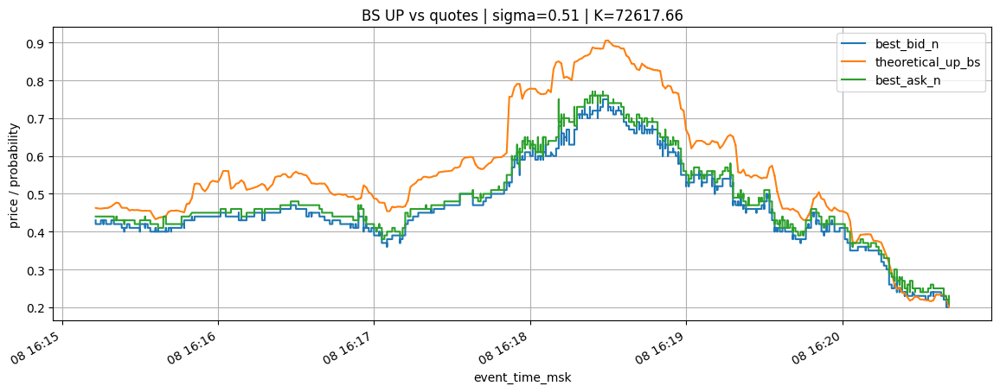

,event_time_msk,best_bid_n,theoretical_up_bs,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
109586,2026-04-08 16:20:41,0.21,0.199824,0.23,72486.704432,72617.66,-0.030176,0.010176
109587,2026-04-08 16:20:41,0.21,0.199824,0.23,72486.704432,72617.66,-0.030176,0.010176
109588,2026-04-08 16:20:41,0.21,0.199822,0.23,72486.704432,72617.66,-0.030178,0.010178
109589,2026-04-08 16:20:41,0.21,0.199821,0.23,72486.704432,72617.66,-0.030179,0.010179
109590,2026-04-08 16:20:41,0.21,0.199821,0.23,72486.704432,72617.66,-0.030179,0.010179
109591,2026-04-08 16:20:41,0.21,0.199821,0.23,72486.704432,72617.66,-0.030179,0.010179
109592,2026-04-08 16:20:41,0.21,0.199820,0.23,72486.704432,72617.66,-0.030180,0.010180
109593,2026-04-08 16:20:41,0.21,0.199819,0.23,72486.704432,72617.66,-0.030181,0.010181
109594,2026-04-08 16:20:41,0.21,0.199818,0.23,72486.704432,72617.66,-0.030182,0.010182
109595,2026-04-08 16:20:41,0.21,0.199817,0.23,72486.704432,72617.66,-0.030183,0.010183


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f"
sigma = 0.51
r = 0.0
min_total_size = 50.0
symbol = "btc/usd"

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) market_start / market_end / price_to_beat БЕЗ Gamma
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
price_to_beat_mode = "first_at_or_after_market_start"

if not p2b:
    p2b_sql_fb = f"""
    SELECT event_ts_ms, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
      AND event_ts_ms < {market_start_ts_ms}
    ORDER BY event_ts_ms DESC
    LIMIT 1
    """
    p2b = c.query(p2b_sql_fb).result_rows
    price_to_beat_mode = "last_before_market_start_fallback"

if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT ДЛЯ merge_asof
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {max(0, int(df_quotes['event_ts_ms'].min()) - 120000)}
  AND event_ts_ms <= {max(market_end_ts_ms, int(df_quotes['event_ts_ms'].max()))}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot в выбранном окне")

# =========================
# 4) BLACK-SCHOLES
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["sigma"] = sigma
df_bs["r"] = r
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_bs"] = np.where(df_bs["spot_value"] >= price_to_beat, 1.0, 0.0)

mask = (df_bs["tau_years"] > 0) & (df_bs["spot_value"] > 0)
d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / price_to_beat)
    + (r - 0.5 * sigma * sigma) * df_bs.loc[mask, "tau_years"]
) / (sigma * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_bs"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_bs"] = df_bs["theoretical_up_bs"].clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_bs"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_bs"]
df_bs["max_cross_side_edge_bs"] = df_bs[["buy_edge_bs", "sell_edge_bs"]].max(axis=1)
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_bs"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_bs"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "sigma": float(sigma),
    "market_start_ts_ms": int(market_start_ts_ms),
    "market_end_ts_ms": int(market_end_ts_ms),
    "price_to_beat": float(price_to_beat),
    "price_to_beat_mode": price_to_beat_mode,
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_bs"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_bs"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_bs"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_bs"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_bs", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"BS UP vs quotes | sigma={sigma} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_bs",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,154284.000000
price_to_beat,72617.660000
sigma_15m_abs_usd,198.505689
inside_spread_rate,0.077772
mae_to_mid,0.066841
rmse_to_mid,0.083411
pct_theory_above_ask,0.767604
pct_theory_below_bid,0.154624


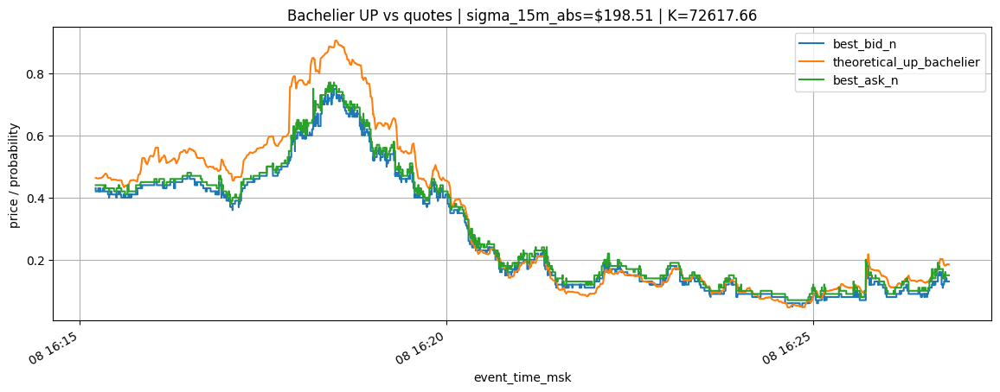

,event_time_msk,best_bid_n,theoretical_up_bachelier,best_ask_n,spot_value,price_to_beat,buy_edge_bach,sell_edge_bach
154254,2026-04-08 16:26:49,0.13,0.183881,0.15,72535.510562,72617.66,0.033881,-0.053881
154255,2026-04-08 16:26:49,0.13,0.183880,0.15,72535.510562,72617.66,0.033880,-0.053880
154256,2026-04-08 16:26:49,0.13,0.183879,0.15,72535.510562,72617.66,0.033879,-0.053879
154257,2026-04-08 16:26:50,0.13,0.185838,0.15,72536.181188,72617.66,0.035838,-0.055838
154258,2026-04-08 16:26:50,0.13,0.185802,0.15,72536.181188,72617.66,0.035802,-0.055802
154259,2026-04-08 16:26:50,0.13,0.185801,0.15,72536.181188,72617.66,0.035801,-0.055801
154260,2026-04-08 16:26:50,0.13,0.185796,0.15,72536.181188,72617.66,0.035796,-0.055796
154261,2026-04-08 16:26:50,0.13,0.185726,0.15,72536.181188,72617.66,0.035726,-0.055726
154262,2026-04-08 16:26:50,0.13,0.185718,0.15,72536.181188,72617.66,0.035718,-0.055718
154263,2026-04-08 16:26:50,0.13,0.185699,0.15,72536.181188,72617.66,0.035699,-0.055699


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f"
min_total_size = 50.0
symbol = "btc/usd"

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) НОРМАЛЬНАЯ ВОЛА В ДОЛЛАРАХ
# =========================
s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
d15 = s_1m.diff(15).dropna()

if len(d15) < 10:
    raise ValueError("Слишком мало данных для оценки нормальной 15m-волы")

sigma_15m_abs = float(d15.std(ddof=1))

# =========================
# 5) BACHELIER MODEL
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bach = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bach["event_time_msk"] = pd.to_datetime(df_bach["event_time_msk"])
df_bach["spot_value"] = df_bach["value"].ffill().bfill()
df_bach["price_to_beat"] = price_to_beat
df_bach["market_end_ts_ms"] = market_end_ts_ms
df_bach["time_to_expiry_sec"] = ((df_bach["market_end_ts_ms"] - df_bach["event_ts_ms"]) / 1000.0).clip(lower=0.0)

# Нормальная модель: S_T ~ N(S_t, sigma_abs^2 * tau/15m)
tau_scale = df_bach["time_to_expiry_sec"] / (15 * 60.0)
sigma_t_abs = sigma_15m_abs * np.sqrt(tau_scale.clip(lower=0.0))

z = (df_bach["spot_value"] - df_bach["price_to_beat"]) / sigma_t_abs.replace(0, np.nan)
df_bach["theoretical_up_bachelier"] = z.apply(lambda x: norm_cdf(x) if pd.notna(x) else np.nan)
df_bach["theoretical_up_bachelier"] = np.where(
    df_bach["time_to_expiry_sec"] <= 0,
    (df_bach["spot_value"] >= df_bach["price_to_beat"]).astype(float),
    df_bach["theoretical_up_bachelier"]
)
df_bach["theoretical_up_bachelier"] = pd.Series(df_bach["theoretical_up_bachelier"]).clip(0.0, 1.0)

df_bach["mid_n"] = (df_bach["best_bid_n"] + df_bach["best_ask_n"]) / 2.0
df_bach["buy_edge_bach"] = df_bach["theoretical_up_bachelier"] - df_bach["best_ask_n"]
df_bach["sell_edge_bach"] = df_bach["best_bid_n"] - df_bach["theoretical_up_bachelier"]
df_bach["inside_spread_bach"] = (
    (df_bach["theoretical_up_bachelier"] >= df_bach["best_bid_n"])
    & (df_bach["theoretical_up_bachelier"] <= df_bach["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bach)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_abs_usd": float(sigma_15m_abs),
    "inside_spread_rate": float(df_bach["inside_spread_bach"].mean()),
    "mae_to_mid": float((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bach["theoretical_up_bachelier"] > df_bach["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bach["theoretical_up_bachelier"] < df_bach["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bach.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_bachelier", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Bachelier UP vs quotes | sigma_15m_abs=${sigma_15m_abs:.2f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bach[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_bachelier",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bach",
    "sell_edge_bach"
]].tail(30))


,value
rows,96793.000000
price_to_beat,71630.920000
sigma_15m_abs_usd,198.499821
inside_spread_rate,0.087796
mae_to_mid,0.077334
rmse_to_mid,0.097758
pct_theory_above_ask,0.495831
pct_theory_below_bid,0.410743


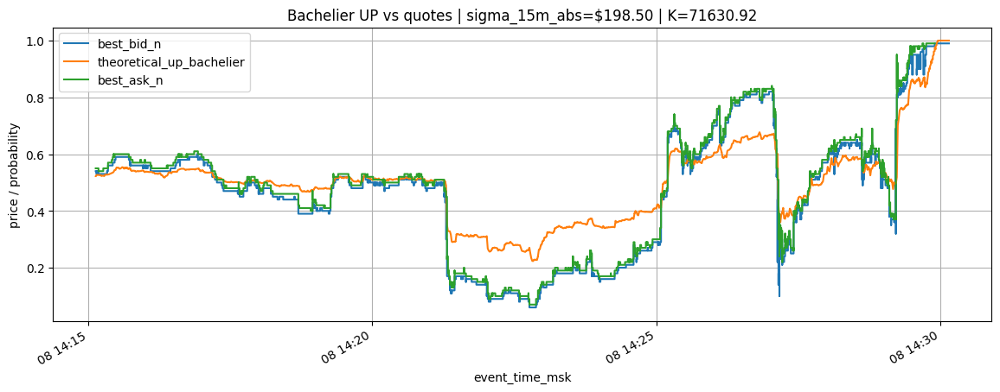

,event_time_msk,best_bid_n,theoretical_up_bachelier,best_ask_n,spot_value,price_to_beat,buy_edge_bach,sell_edge_bach
96763,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96764,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96765,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96766,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96767,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96768,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96769,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96770,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96771,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01
96772,2026-04-08 14:30:04,0.99,1.0,NaN,71659.978419,71630.92,NaN,-0.01


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x93ecde85f53892c69cc75a8755a86983f1240e919d59ad37cfbbc724875c75bb"
min_total_size = 50.0
symbol = "btc/usd"

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) НОРМАЛЬНАЯ ВОЛА В ДОЛЛАРАХ
# =========================
s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
d15 = s_1m.diff(15).dropna()

if len(d15) < 10:
    raise ValueError("Слишком мало данных для оценки нормальной 15m-волы")

sigma_15m_abs = float(d15.std(ddof=1))

# =========================
# 5) BACHELIER MODEL
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bach = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bach["event_time_msk"] = pd.to_datetime(df_bach["event_time_msk"])
df_bach["spot_value"] = df_bach["value"].ffill().bfill()
df_bach["price_to_beat"] = price_to_beat
df_bach["market_end_ts_ms"] = market_end_ts_ms
df_bach["time_to_expiry_sec"] = ((df_bach["market_end_ts_ms"] - df_bach["event_ts_ms"]) / 1000.0).clip(lower=0.0)

# Нормальная модель: S_T ~ N(S_t, sigma_abs^2 * tau/15m)
tau_scale = df_bach["time_to_expiry_sec"] / (15 * 60.0)
sigma_t_abs = sigma_15m_abs * np.sqrt(tau_scale.clip(lower=0.0))

z = (df_bach["spot_value"] - df_bach["price_to_beat"]) / sigma_t_abs.replace(0, np.nan)
df_bach["theoretical_up_bachelier"] = z.apply(lambda x: norm_cdf(x) if pd.notna(x) else np.nan)
df_bach["theoretical_up_bachelier"] = np.where(
    df_bach["time_to_expiry_sec"] <= 0,
    (df_bach["spot_value"] >= df_bach["price_to_beat"]).astype(float),
    df_bach["theoretical_up_bachelier"]
)
df_bach["theoretical_up_bachelier"] = pd.Series(df_bach["theoretical_up_bachelier"]).clip(0.0, 1.0)

df_bach["mid_n"] = (df_bach["best_bid_n"] + df_bach["best_ask_n"]) / 2.0
df_bach["buy_edge_bach"] = df_bach["theoretical_up_bachelier"] - df_bach["best_ask_n"]
df_bach["sell_edge_bach"] = df_bach["best_bid_n"] - df_bach["theoretical_up_bachelier"]
df_bach["inside_spread_bach"] = (
    (df_bach["theoretical_up_bachelier"] >= df_bach["best_bid_n"])
    & (df_bach["theoretical_up_bachelier"] <= df_bach["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bach)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_abs_usd": float(sigma_15m_abs),
    "inside_spread_rate": float(df_bach["inside_spread_bach"].mean()),
    "mae_to_mid": float((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bach["theoretical_up_bachelier"] > df_bach["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bach["theoretical_up_bachelier"] < df_bach["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bach.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_bachelier", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Bachelier UP vs quotes | sigma_15m_abs=${sigma_15m_abs:.2f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bach[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_bachelier",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bach",
    "sell_edge_bach"
]].tail(30))


,value
rows,104584.000000
price_to_beat,71938.804496
sigma_15m_abs_usd,198.853108
inside_spread_rate,0.063652
mae_to_mid,0.061710
rmse_to_mid,0.075439
pct_theory_above_ask,0.345330
pct_theory_below_bid,0.574390


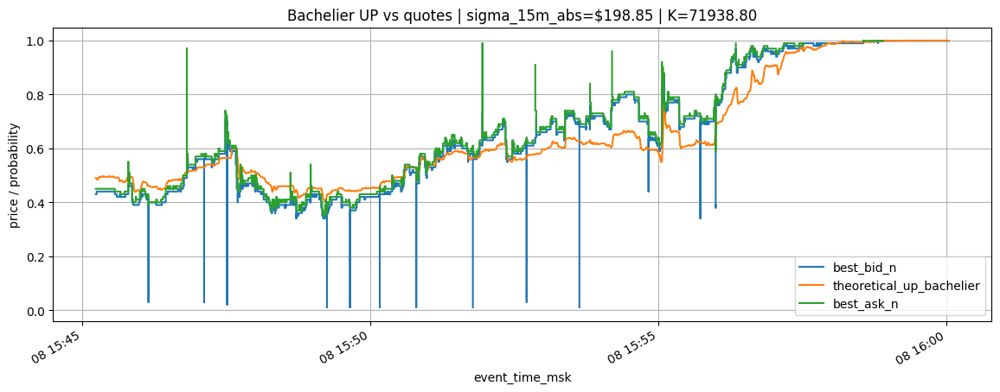

,event_time_msk,best_bid_n,theoretical_up_bachelier,best_ask_n,spot_value,price_to_beat,buy_edge_bach,sell_edge_bach
104554,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104555,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104556,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104557,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104558,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104559,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104560,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104561,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104562,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001
104563,2026-04-08 16:00:02,0.999,1.0,NaN,72075.881735,71938.804496,NaN,-0.001


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f"
min_total_size = 50.0
symbol = "btc/usd"

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) НОРМАЛЬНАЯ ВОЛА В ДОЛЛАРАХ
# =========================
s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
d15 = s_1m.diff(15).dropna()

if len(d15) < 10:
    raise ValueError("Слишком мало данных для оценки нормальной 15m-волы")

sigma_15m_abs = float(d15.std(ddof=1))

# =========================
# 5) BACHELIER MODEL
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bach = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bach["event_time_msk"] = pd.to_datetime(df_bach["event_time_msk"])
df_bach["spot_value"] = df_bach["value"].ffill().bfill()
df_bach["price_to_beat"] = price_to_beat
df_bach["market_end_ts_ms"] = market_end_ts_ms
df_bach["time_to_expiry_sec"] = ((df_bach["market_end_ts_ms"] - df_bach["event_ts_ms"]) / 1000.0).clip(lower=0.0)

# Нормальная модель: S_T ~ N(S_t, sigma_abs^2 * tau/15m)
tau_scale = df_bach["time_to_expiry_sec"] / (15 * 60.0)
sigma_t_abs = sigma_15m_abs * np.sqrt(tau_scale.clip(lower=0.0))

z = (df_bach["spot_value"] - df_bach["price_to_beat"]) / sigma_t_abs.replace(0, np.nan)
df_bach["theoretical_up_bachelier"] = z.apply(lambda x: norm_cdf(x) if pd.notna(x) else np.nan)
df_bach["theoretical_up_bachelier"] = np.where(
    df_bach["time_to_expiry_sec"] <= 0,
    (df_bach["spot_value"] >= df_bach["price_to_beat"]).astype(float),
    df_bach["theoretical_up_bachelier"]
)
df_bach["theoretical_up_bachelier"] = pd.Series(df_bach["theoretical_up_bachelier"]).clip(0.0, 1.0)

df_bach["mid_n"] = (df_bach["best_bid_n"] + df_bach["best_ask_n"]) / 2.0
df_bach["buy_edge_bach"] = df_bach["theoretical_up_bachelier"] - df_bach["best_ask_n"]
df_bach["sell_edge_bach"] = df_bach["best_bid_n"] - df_bach["theoretical_up_bachelier"]
df_bach["inside_spread_bach"] = (
    (df_bach["theoretical_up_bachelier"] >= df_bach["best_bid_n"])
    & (df_bach["theoretical_up_bachelier"] <= df_bach["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bach)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_abs_usd": float(sigma_15m_abs),
    "inside_spread_rate": float(df_bach["inside_spread_bach"].mean()),
    "mae_to_mid": float((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bach["theoretical_up_bachelier"] > df_bach["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bach["theoretical_up_bachelier"] < df_bach["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bach.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_bachelier", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Bachelier UP vs quotes | sigma_15m_abs=${sigma_15m_abs:.2f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bach[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_bachelier",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bach",
    "sell_edge_bach"
]].tail(30))


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
orderbook_table = os.getenv("ORDERBOOK_TABLE", "orderbook")
pricechange_table = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

sql = f"""
SELECT
    market,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    count() AS rows_cnt
FROM
(
    SELECT market, event_time_msk FROM {db}.{orderbook_table}
    UNION ALL
    SELECT market, event_time_msk FROM {db}.{pricechange_table}
)
GROUP BY market
ORDER BY first_time_msk DESC
"""

res = c.query(sql)
df_markets = pd.DataFrame(res.result_rows, columns=res.column_names)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)

display(df_markets)


,market,first_time_msk,last_time_msk,rows_cnt
0,0xf402846bced8b46e6c2104689ad485fe12b65495cf7efc4d94fbf82c79158584,2026-04-08 16:30:14,2026-04-08 16:33:42,53381
1,0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f,2026-04-08 16:15:13,2026-04-08 16:30:05,197898
2,0x409d039650387605abcecfcc2e76ab5d3d524280b968cb799c05c20549795704,2026-04-08 16:00:11,2026-04-08 16:15:09,115079
3,0x93ecde85f53892c69cc75a8755a86983f1240e919d59ad37cfbbc724875c75bb,2026-04-08 15:45:14,2026-04-08 16:00:03,133765
4,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb,2026-04-08 15:30:07,2026-04-08 15:45:06,91357
...,...,...,...,...
102,0xaa459ad788b034cd2f65add71feccba6ffbd989cfbb3ce387944ecb558005051,2026-04-07 15:00:08,2026-04-07 15:15:03,139076
103,0x3c4d9cb221319f503f428e4972ade7063542cb0a7ad4670de1609778a23c0e7a,2026-04-07 14:45:08,2026-04-07 15:00:00,108285
104,0xb3998ae4f73513ea3bc588066179c78ad59a1b870c4adc6a322960bde1a2ca3e,2026-04-07 14:30:06,2026-04-07 14:45:00,157741
105,0x4d9e7ba812a66821a2d70e40fb92c4db21805e7431a5f1dd52f4a4c3ba7d90d3,2026-04-07 14:15:08,2026-04-07 14:29:59,164642


,value
rows,165733.000000
price_to_beat,72617.660000
sigma_15m_abs_usd,200.423158
inside_spread_rate,0.077993
mae_to_mid,0.065234
rmse_to_mid,0.081154
pct_theory_above_ask,0.783356
pct_theory_below_bid,0.131326


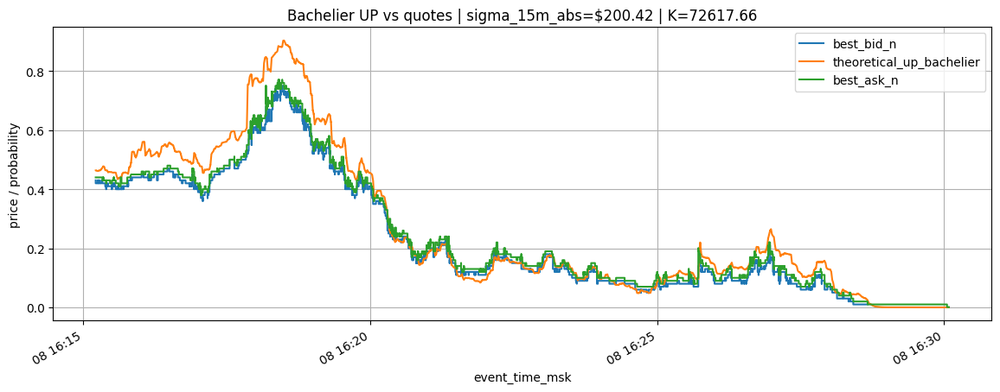

,event_time_msk,best_bid_n,theoretical_up_bachelier,best_ask_n,spot_value,price_to_beat,buy_edge_bach,sell_edge_bach
165703,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165704,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165705,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165706,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165707,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165708,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165709,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165710,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165711,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165712,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f"
min_total_size = 50.0
symbol = "btc/usd"

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) НОРМАЛЬНАЯ ВОЛА В ДОЛЛАРАХ
# =========================
s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
d15 = s_1m.diff(15).dropna()

if len(d15) < 10:
    raise ValueError("Слишком мало данных для оценки нормальной 15m-волы")

sigma_15m_abs = float(d15.std(ddof=1))

# =========================
# 5) BACHELIER MODEL
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bach = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bach["event_time_msk"] = pd.to_datetime(df_bach["event_time_msk"])
df_bach["spot_value"] = df_bach["value"].ffill().bfill()
df_bach["price_to_beat"] = price_to_beat
df_bach["market_end_ts_ms"] = market_end_ts_ms
df_bach["time_to_expiry_sec"] = ((df_bach["market_end_ts_ms"] - df_bach["event_ts_ms"]) / 1000.0).clip(lower=0.0)

# Нормальная модель: S_T ~ N(S_t, sigma_abs^2 * tau/15m)
tau_scale = df_bach["time_to_expiry_sec"] / (15 * 60.0)
sigma_t_abs = sigma_15m_abs * np.sqrt(tau_scale.clip(lower=0.0))

z = (df_bach["spot_value"] - df_bach["price_to_beat"]) / sigma_t_abs.replace(0, np.nan)
df_bach["theoretical_up_bachelier"] = z.apply(lambda x: norm_cdf(x) if pd.notna(x) else np.nan)
df_bach["theoretical_up_bachelier"] = np.where(
    df_bach["time_to_expiry_sec"] <= 0,
    (df_bach["spot_value"] >= df_bach["price_to_beat"]).astype(float),
    df_bach["theoretical_up_bachelier"]
)
df_bach["theoretical_up_bachelier"] = pd.Series(df_bach["theoretical_up_bachelier"]).clip(0.0, 1.0)

df_bach["mid_n"] = (df_bach["best_bid_n"] + df_bach["best_ask_n"]) / 2.0
df_bach["buy_edge_bach"] = df_bach["theoretical_up_bachelier"] - df_bach["best_ask_n"]
df_bach["sell_edge_bach"] = df_bach["best_bid_n"] - df_bach["theoretical_up_bachelier"]
df_bach["inside_spread_bach"] = (
    (df_bach["theoretical_up_bachelier"] >= df_bach["best_bid_n"])
    & (df_bach["theoretical_up_bachelier"] <= df_bach["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bach)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_abs_usd": float(sigma_15m_abs),
    "inside_spread_rate": float(df_bach["inside_spread_bach"].mean()),
    "mae_to_mid": float((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bach["theoretical_up_bachelier"] > df_bach["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bach["theoretical_up_bachelier"] < df_bach["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bach.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_bachelier", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Bachelier UP vs quotes | sigma_15m_abs=${sigma_15m_abs:.2f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bach[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_bachelier",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bach",
    "sell_edge_bach"
]].tail(30))


,value
rows,89803.000000
price_to_beat,68401.782000
sigma_15m_abs_usd,200.599871
inside_spread_rate,0.045355
mae_to_mid,0.112454
rmse_to_mid,0.134175
pct_theory_above_ask,0.918021
pct_theory_below_bid,0.033473


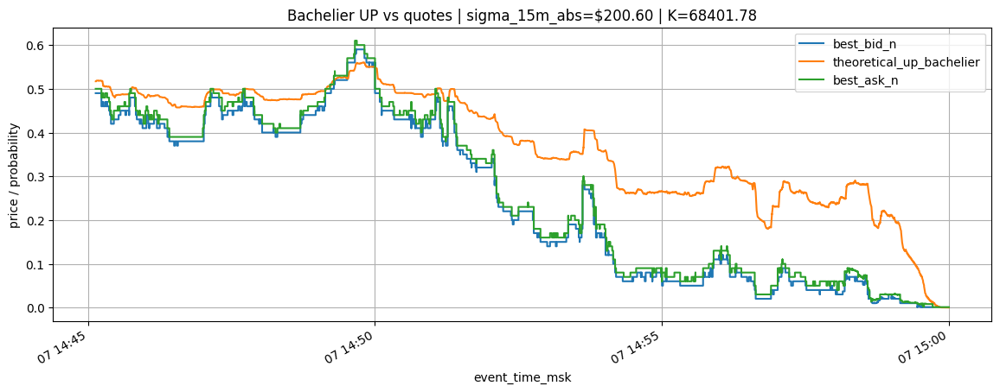

,event_time_msk,best_bid_n,theoretical_up_bachelier,best_ask_n,spot_value,price_to_beat,buy_edge_bach,sell_edge_bach
89773,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89774,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89775,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89776,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89777,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89778,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89779,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89780,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89781,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89782,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x3c4d9cb221319f503f428e4972ade7063542cb0a7ad4670de1609778a23c0e7a"
min_total_size = 50.0
symbol = "btc/usd"

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) НОРМАЛЬНАЯ ВОЛА В ДОЛЛАРАХ
# =========================
s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
d15 = s_1m.diff(15).dropna()

if len(d15) < 10:
    raise ValueError("Слишком мало данных для оценки нормальной 15m-волы")

sigma_15m_abs = float(d15.std(ddof=1))

# =========================
# 5) BACHELIER MODEL
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bach = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bach["event_time_msk"] = pd.to_datetime(df_bach["event_time_msk"])
df_bach["spot_value"] = df_bach["value"].ffill().bfill()
df_bach["price_to_beat"] = price_to_beat
df_bach["market_end_ts_ms"] = market_end_ts_ms
df_bach["time_to_expiry_sec"] = ((df_bach["market_end_ts_ms"] - df_bach["event_ts_ms"]) / 1000.0).clip(lower=0.0)

# Нормальная модель: S_T ~ N(S_t, sigma_abs^2 * tau/15m)
tau_scale = df_bach["time_to_expiry_sec"] / (15 * 60.0)
sigma_t_abs = sigma_15m_abs * np.sqrt(tau_scale.clip(lower=0.0))

z = (df_bach["spot_value"] - df_bach["price_to_beat"]) / sigma_t_abs.replace(0, np.nan)
df_bach["theoretical_up_bachelier"] = z.apply(lambda x: norm_cdf(x) if pd.notna(x) else np.nan)
df_bach["theoretical_up_bachelier"] = np.where(
    df_bach["time_to_expiry_sec"] <= 0,
    (df_bach["spot_value"] >= df_bach["price_to_beat"]).astype(float),
    df_bach["theoretical_up_bachelier"]
)
df_bach["theoretical_up_bachelier"] = pd.Series(df_bach["theoretical_up_bachelier"]).clip(0.0, 1.0)

df_bach["mid_n"] = (df_bach["best_bid_n"] + df_bach["best_ask_n"]) / 2.0
df_bach["buy_edge_bach"] = df_bach["theoretical_up_bachelier"] - df_bach["best_ask_n"]
df_bach["sell_edge_bach"] = df_bach["best_bid_n"] - df_bach["theoretical_up_bachelier"]
df_bach["inside_spread_bach"] = (
    (df_bach["theoretical_up_bachelier"] >= df_bach["best_bid_n"])
    & (df_bach["theoretical_up_bachelier"] <= df_bach["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bach)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_abs_usd": float(sigma_15m_abs),
    "inside_spread_rate": float(df_bach["inside_spread_bach"].mean()),
    "mae_to_mid": float((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bach["theoretical_up_bachelier"] - df_bach["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bach["theoretical_up_bachelier"] > df_bach["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bach["theoretical_up_bachelier"] < df_bach["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bach.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_bachelier", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Bachelier UP vs quotes | sigma_15m_abs=${sigma_15m_abs:.2f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bach[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_bachelier",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bach",
    "sell_edge_bach"
]].tail(30))


In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv("/root/project/.env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
tables = [
    os.getenv("ORDERBOOK_TABLE", "orderbook"),
    os.getenv("PRICECHANGE_TABLE", "pricechange"),
    os.getenv("SPOT_TABLE", "btc_spot"),
    os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat"),
    os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log"),
]

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = []
for t in tables:
    exists = c.query(f"EXISTS TABLE {db}.{t}").result_rows[0][0]
    if exists == 0:
        rows.append({"table": f"{db}.{t}", "exists": 0, "rows_cnt": None})
        continue
    cnt = c.query(f"SELECT count() FROM {db}.{t}").result_rows[0][0]
    rows.append({"table": f"{db}.{t}", "exists": 1, "rows_cnt": int(cnt)})

df_check = pd.DataFrame(rows)
display(df_check)


,table,exists,rows_cnt
0,polyk.orderbook,1,116883
1,polyk.pricechange,1,13687967
2,polyk.btc_spot,1,101991
3,polyk.ingest_heartbeat,1,8282
4,polyk.ingest_service_log,1,628


,value
rows,89803.000000
price_to_beat,68401.782000
sigma_15m_log,0.002950
sigma_ann,0.552191
inside_spread_rate,0.042482
mae_to_mid,0.112592
rmse_to_mid,0.134551
pct_theory_above_ask,0.917609
pct_theory_below_bid,0.036769


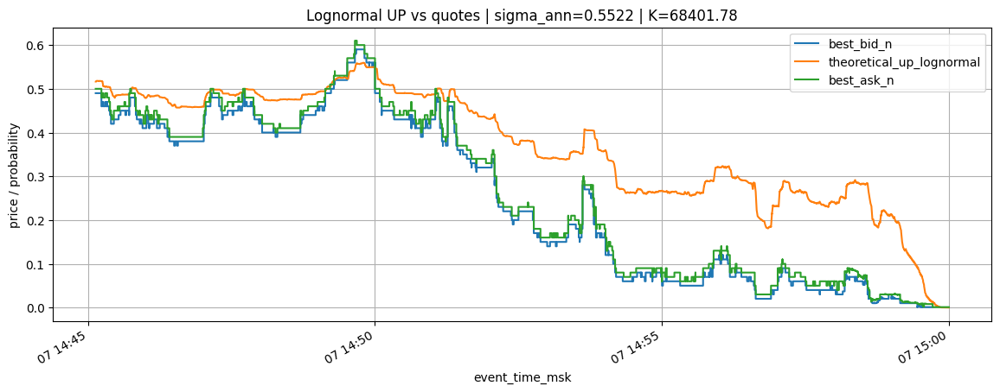

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
89773,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89774,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89775,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89776,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89777,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89778,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89779,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89780,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89781,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89782,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x3c4d9cb221319f503f428e4972ade7063542cb0a7ad4670de1609778a23c0e7a"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================
s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann = float(sigma_15m_log * math.sqrt(periods_per_year_15m))

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,89803.000000
price_to_beat,68401.782000
sigma_15m_log,0.002950
sigma_ann,0.410000
inside_spread_rate,0.051056
mae_to_mid,0.083839
rmse_to_mid,0.097389
pct_theory_above_ask,0.920905
pct_theory_below_bid,0.023741


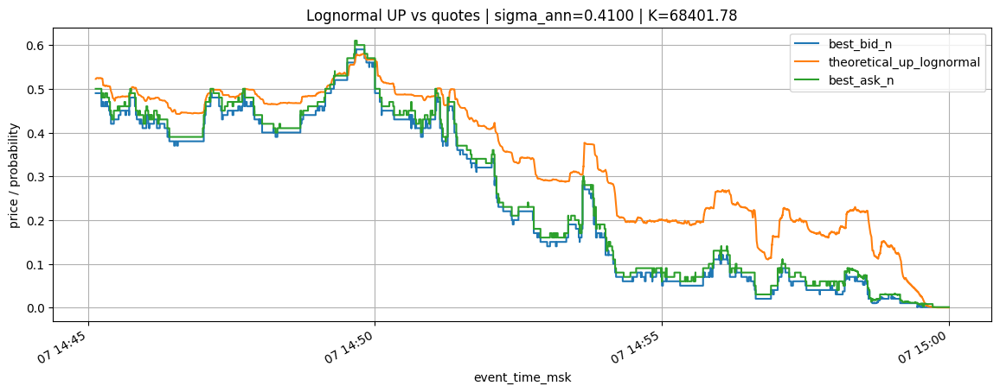

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
89773,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89774,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89775,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89776,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89777,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89778,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89779,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89780,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89781,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89782,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x3c4d9cb221319f503f428e4972ade7063542cb0a7ad4670de1609778a23c0e7a"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================
sigma_ann_manual = 0.41

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,89803.000000
price_to_beat,68401.782000
sigma_15m_log,0.002950
sigma_ann,0.110000
inside_spread_rate,0.072592
mae_to_mid,0.069355
rmse_to_mid,0.086334
pct_theory_above_ask,0.231228
pct_theory_below_bid,0.691558


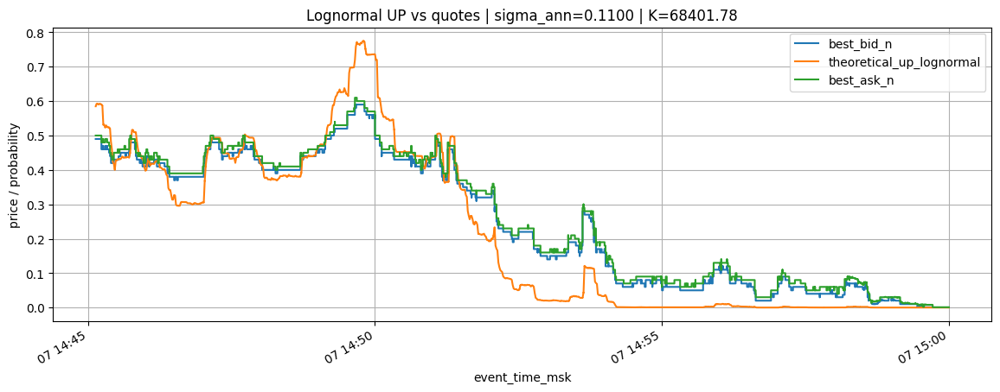

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
89773,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89774,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89775,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89776,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89777,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89778,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89779,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89780,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89781,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89782,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x3c4d9cb221319f503f428e4972ade7063542cb0a7ad4670de1609778a23c0e7a"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================
sigma_ann_manual = 0.11

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,89803.000000
price_to_beat,68401.782000
sigma_15m_log,0.002950
sigma_ann,0.210000
inside_spread_rate,0.170618
mae_to_mid,0.025855
rmse_to_mid,0.033320
pct_theory_above_ask,0.528223
pct_theory_below_bid,0.296538


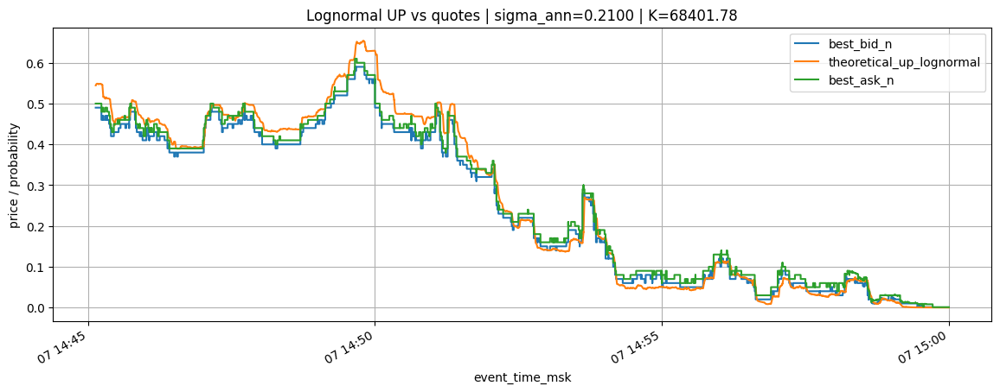

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
89773,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89774,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89775,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89776,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89777,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89778,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89779,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89780,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89781,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN
89782,2026-04-07 15:00:00,NaN,0.0,0.001,68336.783217,68401.782,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x3c4d9cb221319f503f428e4972ade7063542cb0a7ad4670de1609778a23c0e7a"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================
sigma_ann_manual = 0.21

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,165733.000000
price_to_beat,72617.660000
sigma_15m_log,0.002950
sigma_ann,0.210000
inside_spread_rate,0.031002
mae_to_mid,0.146992
rmse_to_mid,0.175493
pct_theory_above_ask,0.492823
pct_theory_below_bid,0.468139


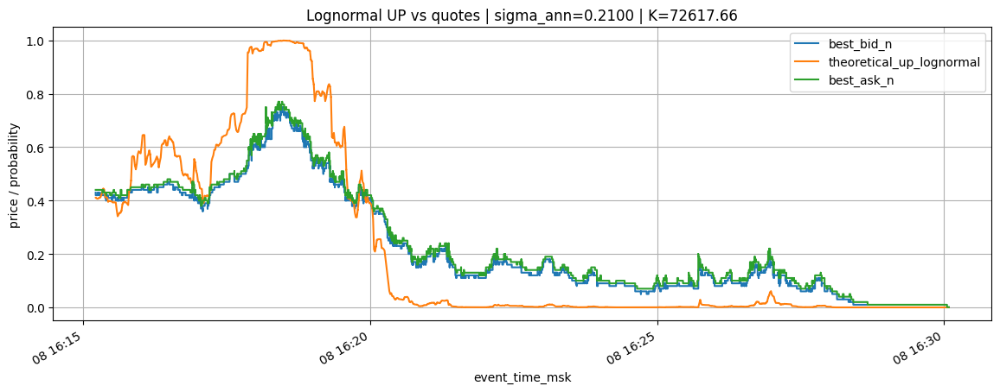

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
165703,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165704,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165705,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165706,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165707,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165708,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165709,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165710,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165711,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165712,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================
sigma_ann_manual = 0.21

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,165733.000000
price_to_beat,72617.660000
sigma_15m_log,0.002950
sigma_ann,0.410000
inside_spread_rate,0.049314
mae_to_mid,0.083164
rmse_to_mid,0.103771
pct_theory_above_ask,0.617427
pct_theory_below_bid,0.325222


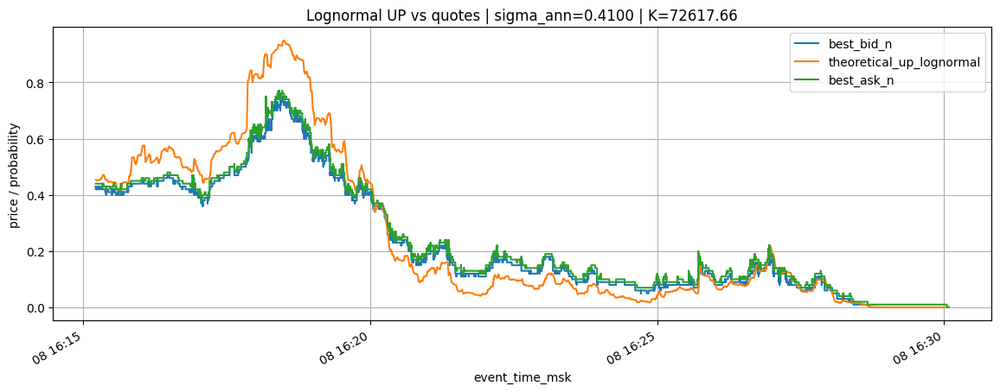

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
165703,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165704,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165705,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165706,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165707,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165708,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165709,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165710,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165711,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN
165712,2026-04-08 16:30:04,NaN,0.0,0.001,72588.303634,72617.66,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0x527ff3f0ffe0ea59a8b9ceda98de92447122d5f16df5482a005272c75f5b3c3f"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================
sigma_ann_manual = 0.41

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


81235286111213444509048182002679252239665382018486243109753549912399660894782

,value
rows,126467.000000
price_to_beat,68370.699850
sigma_15m_log,0.002950
sigma_ann,0.510000
inside_spread_rate,0.028403
mae_to_mid,0.067253
rmse_to_mid,0.076677
pct_theory_above_ask,0.528067
pct_theory_below_bid,0.500921


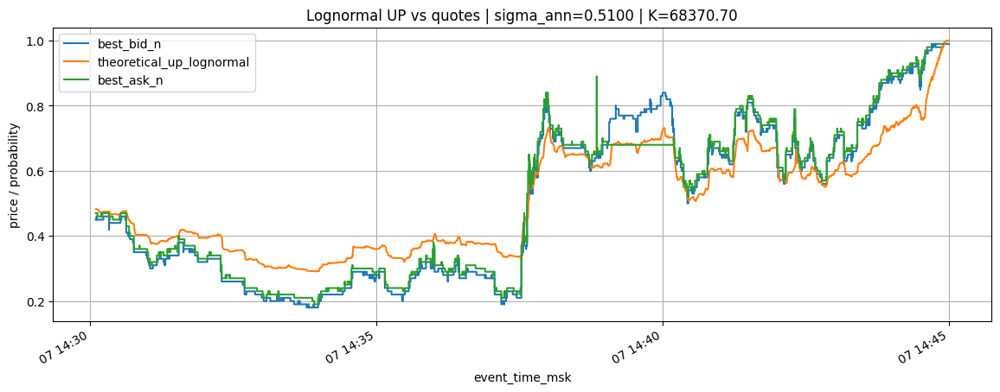

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
126437,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126438,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126439,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126440,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126441,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126442,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126443,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126444,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126445,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126446,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0xb3998ae4f73513ea3bc588066179c78ad59a1b870c4adc6a322960bde1a2ca3e"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann_manual = 0.51
# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,126467.000000
price_to_beat,68370.699850
sigma_15m_log,0.002950
sigma_ann,0.710000
inside_spread_rate,0.010548
mae_to_mid,0.102062
rmse_to_mid,0.112207
pct_theory_above_ask,0.464888
pct_theory_below_bid,0.522998


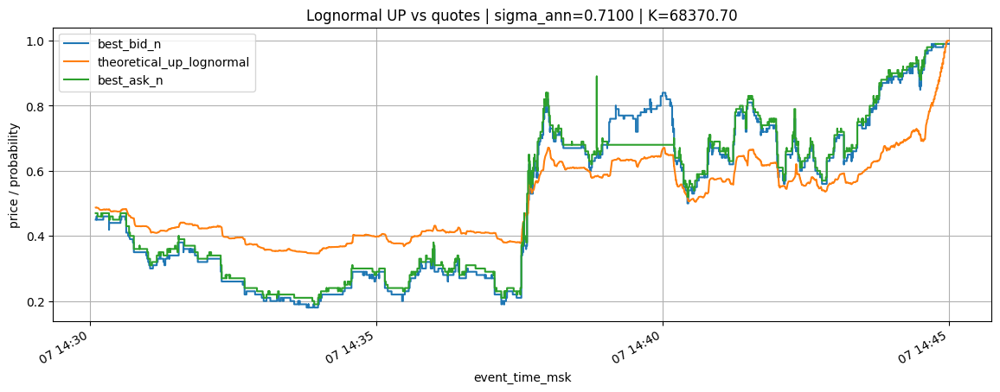

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
126437,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126438,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126439,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126440,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126441,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126442,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126443,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126444,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126445,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126446,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0xb3998ae4f73513ea3bc588066179c78ad59a1b870c4adc6a322960bde1a2ca3e"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann_manual = 0.71
# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,126467.000000
price_to_beat,68370.699850
sigma_15m_log,0.002950
sigma_ann,0.410000
inside_spread_rate,0.088869
mae_to_mid,0.041675
rmse_to_mid,0.050785
pct_theory_above_ask,0.567508
pct_theory_below_bid,0.412163


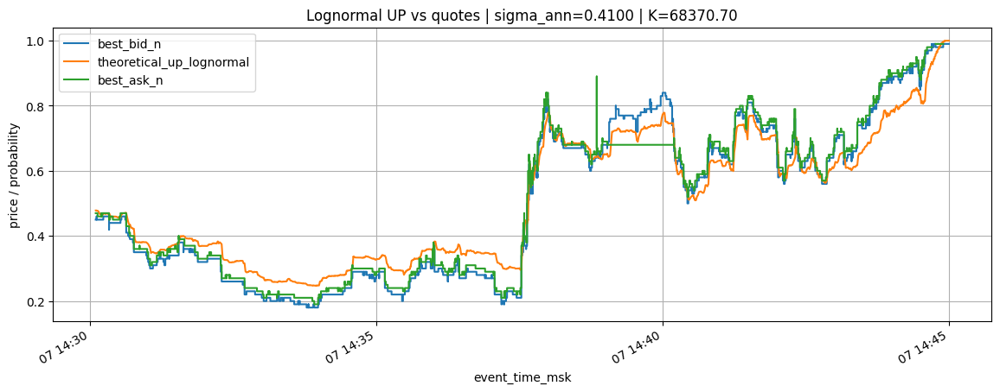

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
126437,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126438,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126439,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126440,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126441,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126442,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126443,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126444,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126445,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126446,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0xb3998ae4f73513ea3bc588066179c78ad59a1b870c4adc6a322960bde1a2ca3e"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann_manual = 0.41
# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,126467.000000
price_to_beat,68370.699850
sigma_15m_log,0.002950
sigma_ann,0.110000
inside_spread_rate,0.002783
mae_to_mid,0.202672
rmse_to_mid,0.211583
pct_theory_above_ask,0.521417
pct_theory_below_bid,0.471886


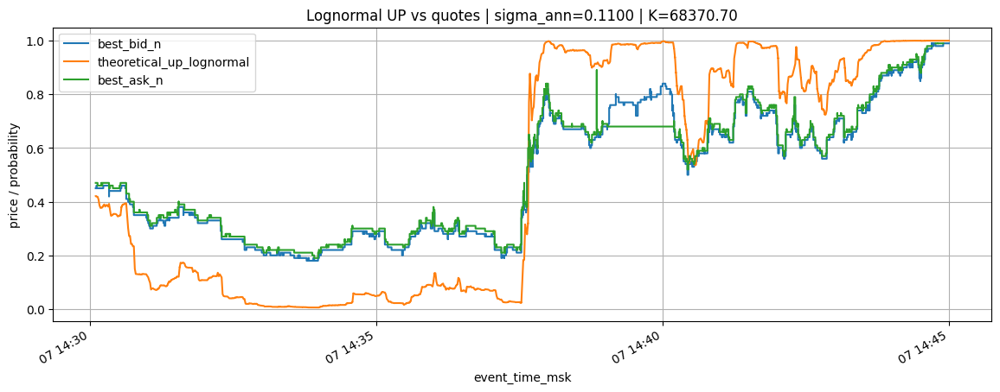

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
126437,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126438,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126439,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126440,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126441,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126442,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126443,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126444,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126445,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126446,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0xb3998ae4f73513ea3bc588066179c78ad59a1b870c4adc6a322960bde1a2ca3e"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann_manual = 0.11
# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,126467.000000
price_to_beat,68370.699850
sigma_15m_log,0.002950
sigma_ann,0.310000
inside_spread_rate,0.231855
mae_to_mid,0.027555
rmse_to_mid,0.036373
pct_theory_above_ask,0.442534
pct_theory_below_bid,0.344865


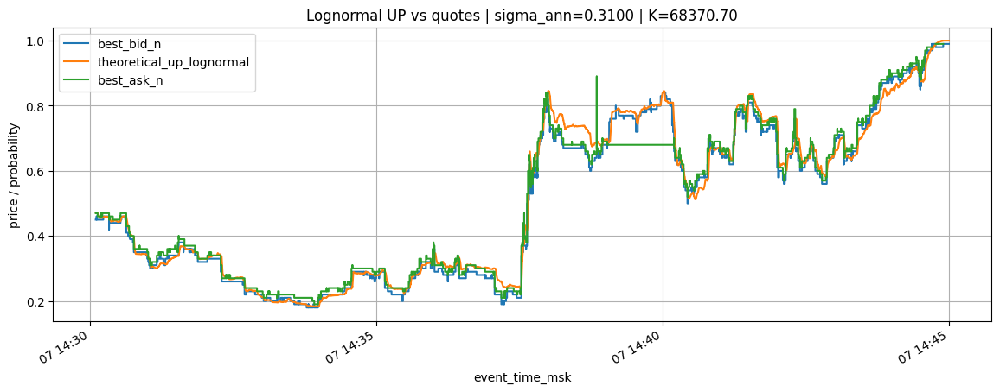

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
126437,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126438,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126439,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126440,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126441,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126442,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126443,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126444,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126445,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01
126446,2026-04-07 14:45:00,0.99,1.0,NaN,68401.782,68370.69985,NaN,-0.01


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0xb3998ae4f73513ea3bc588066179c78ad59a1b870c4adc6a322960bde1a2ca3e"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann_manual = 0.31
# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))


,value
rows,77991.000000
price_to_beat,72726.787122
sigma_15m_log,0.002950
sigma_ann,0.310000
inside_spread_rate,0.000000
mae_to_mid,0.132228
rmse_to_mid,0.162741
pct_theory_above_ask,0.000000
pct_theory_below_bid,0.965099


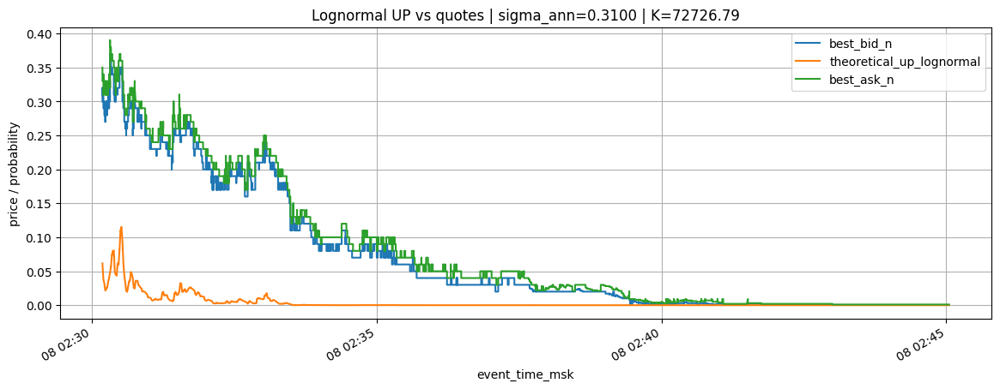

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
77961,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77962,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77963,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77964,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77965,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77966,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77967,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77968,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77969,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77970,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0xe35360725424e4ea60a46b5fc8437a4234bce0e8639718f1600237913c41df5a"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann_manual = 0.31
# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))




In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
orderbook_table = os.getenv("ORDERBOOK_TABLE", "orderbook")
pricechange_table = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

sql = f"""
SELECT DISTINCT market
FROM
(
    SELECT market FROM {db}.{orderbook_table}
    UNION ALL
    SELECT market FROM {db}.{pricechange_table}
)
ORDER BY market
"""

res = c.query(sql)
df_markets = pd.DataFrame(res.result_rows, columns=res.column_names)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_rows", None)

display(df_markets)


,market
0,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
1,0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
2,0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
3,0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
4,0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
5,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
6,0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
7,0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d
8,0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f
9,0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826


import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
orderbook_table = os.getenv("ORDERBOOK_TABLE", "orderbook")
pricechange_table = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

sql = f"""
SELECT DISTINCT market
FROM
(
    SELECT market FROM {db}.{orderbook_table}
    UNION ALL
    SELECT market FROM {db}.{pricechange_table}
)
ORDER BY market
"""

res = c.query(sql)
df_markets = pd.DataFrame(res.result_rows, columns=res.column_names)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_rows", None)

display(df_markets)


,value
rows,77991.000000
price_to_beat,72726.787122
sigma_15m_log,0.002950
sigma_ann,0.310000
inside_spread_rate,0.000000
mae_to_mid,0.132228
rmse_to_mid,0.162741
pct_theory_above_ask,0.000000
pct_theory_below_bid,0.965099


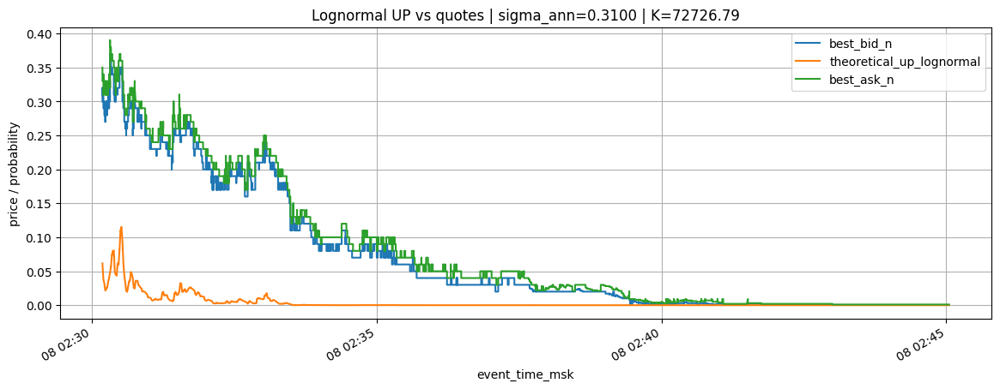

,event_time_msk,best_bid_n,theoretical_up_lognormal,best_ask_n,spot_value,price_to_beat,buy_edge_bs,sell_edge_bs
77961,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77962,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77963,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77964,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77965,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77966,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77967,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77968,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77969,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN
77970,2026-04-08 02:45:02,NaN,0.0,0.001,72021.905939,72726.787122,-0.001,NaN


In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market = "0xe35360725424e4ea60a46b5fc8437a4234bce0e8639718f1600237913c41df5a"
min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann_manual = 0.31
# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

# =========================
# 1) ВОССТАНОВЛЕНИЕ best_bid_n / best_ask_n
# =========================
meta_sql = f"""
SELECT
    market,
    asset_id,
    hash,
    max(event_ts_ms) AS snapshot_ts_ms,
    max(event_time_msk) AS snapshot_time_msk
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
GROUP BY market, asset_id, hash
ORDER BY snapshot_ts_ms DESC
LIMIT 1
"""
meta_res = c.query(meta_sql)
if not meta_res.result_rows:
    raise ValueError("Не найден snapshot для этого market в orderbook")

meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
asset_id = str(meta["asset_id"])
ob_hash = str(meta["hash"])
snapshot_ts_ms = int(meta["snapshot_ts_ms"])
snapshot_time_msk = meta["snapshot_time_msk"]

snap_sql = f"""
SELECT side, price, size
FROM {DB}.{ORDERBOOK_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND hash = {q(ob_hash)}
ORDER BY price ASC
"""
snap_res = c.query(snap_sql)
df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
if df_snap.empty:
    raise ValueError("Пустой snapshot")

price_grid = sorted(float(x) for x in df_snap["price"].tolist())
bid_prices_desc = list(reversed(price_grid))
ask_prices_asc = price_grid[:]

bid_sizes = {p: 0.0 for p in price_grid}
ask_sizes = {p: 0.0 for p in price_grid}

for row in df_snap.itertuples(index=False):
    p = float(row.price)
    s = float(row.size)
    if row.side == "bid":
        bid_sizes[p] = s
    elif row.side == "ask":
        ask_sizes[p] = s

records = []

bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
records.append({
    "event_time_msk": snapshot_time_msk,
    "event_ts_ms": snapshot_ts_ms,
    "best_bid_n": bb,
    "best_ask_n": ba,
})

pc_sql = f"""
SELECT event_time_msk, event_ts_ms, side, price, size
FROM {DB}.{PRICECHANGE_TABLE}
WHERE market = {q(market)}
  AND asset_id = {q(asset_id)}
  AND event_ts_ms >= {snapshot_ts_ms}
ORDER BY event_ts_ms ASC, price ASC
"""
pc_res = c.query(pc_sql)
df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

if not df_pc.empty:
    current_ts = None
    current_time = None

    for row in df_pc.itertuples(index=False):
        row_ts = int(row.event_ts_ms)

        if current_ts is None:
            current_ts = row_ts
            current_time = row.event_time_msk
        elif row_ts != current_ts:
            bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })
            current_ts = row_ts
            current_time = row.event_time_msk

        p = float(row.price)
        ds = float(row.size)

        if row.side == "bid":
            ns = bid_sizes.get(p, 0.0) + ds
            bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
        elif row.side == "ask":
            ns = ask_sizes.get(p, 0.0) + ds
            ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

    if current_ts is not None:
        bb, cb = depth_price(bid_sizes, bid_prices_desc, min_total_size)
        ba, ca = depth_price(ask_sizes, ask_prices_asc, min_total_size)
        records.append({
            "event_time_msk": current_time,
            "event_ts_ms": current_ts,
            "best_bid_n": bb,
            "best_ask_n": ba,
        })

df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
if df_quotes.empty:
    raise ValueError("df_quotes пустой")

# =========================
# 2) ВРЕМЯ РЫНКА И price_to_beat
# =========================
market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

p2b_sql = f"""
SELECT event_ts_ms, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
  AND event_ts_ms >= {market_start_ts_ms}
ORDER BY event_ts_ms ASC
LIMIT 1
"""
p2b = c.query(p2b_sql).result_rows
if not p2b:
    raise ValueError("Не найден price_to_beat в btc_spot")

price_to_beat = float(p2b[0][1])

# =========================
# 3) SPOT РЯД
# =========================
spot_sql = f"""
SELECT event_ts_ms, event_time_msk, value
FROM {DB}.{SPOT_TABLE}
WHERE symbol = {q(symbol.lower())}
ORDER BY event_ts_ms ASC
"""
spot_res = c.query(spot_sql)
df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
if df_spot.empty:
    raise ValueError("Пустой df_spot")

df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
df_spot["value"] = df_spot["value"].astype(float)
df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

# =========================
# 4) ЛОГНОРМАЛЬНАЯ ВОЛА
# =========================

s_1m = df_spot.set_index("event_time_msk")["value"].resample("1min").last().ffill().dropna()
logp = np.log(s_1m)
r15 = logp.diff(15).dropna()

if len(r15) < 10:
    raise ValueError("Слишком мало данных для оценки 15m лог-волы")

sigma_15m_log_empirical = float(r15.std(ddof=1))
periods_per_year_15m = 365 * 24 * 4
sigma_ann_empirical = float(sigma_15m_log_empirical * math.sqrt(periods_per_year_15m))

# В МОДЕЛЬ ИДЕТ ИМЕННО ЭТО ЗНАЧЕНИЕ
sigma_ann = sigma_ann_manual

# =========================
# 5) BLACK-SCHOLES BINARY UP
# =========================
df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

df_bs = pd.merge_asof(
    df_q,
    df_s[["event_ts_ms", "value"]],
    on="event_ts_ms",
    direction="backward"
)

df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
df_bs["spot_value"] = df_bs["value"].ffill().bfill()
df_bs["price_to_beat"] = price_to_beat
df_bs["market_end_ts_ms"] = market_end_ts_ms
df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

df_bs["theoretical_up_lognormal"] = np.where(
    df_bs["time_to_expiry_sec"] <= 0,
    (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
    np.nan
)

mask = (
    (df_bs["time_to_expiry_sec"] > 0)
    & (df_bs["spot_value"] > 0)
    & (df_bs["price_to_beat"] > 0)
)

d2 = (
    np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
    + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

df_bs["mid_n"] = (df_bs["best_bid_n"] + df_bs["best_ask_n"]) / 2.0
df_bs["buy_edge_bs"] = df_bs["theoretical_up_lognormal"] - df_bs["best_ask_n"]
df_bs["sell_edge_bs"] = df_bs["best_bid_n"] - df_bs["theoretical_up_lognormal"]
df_bs["inside_spread_bs"] = (
    (df_bs["theoretical_up_lognormal"] >= df_bs["best_bid_n"])
    & (df_bs["theoretical_up_lognormal"] <= df_bs["best_ask_n"])
).astype(int)

metrics = {
    "rows": int(len(df_bs)),
    "price_to_beat": float(price_to_beat),
    "sigma_15m_log": float(sigma_15m_log),
    "sigma_ann": float(sigma_ann),
    "inside_spread_rate": float(df_bs["inside_spread_bs"].mean()),
    "mae_to_mid": float((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]).abs().mean()),
    "rmse_to_mid": float(np.sqrt(((df_bs["theoretical_up_lognormal"] - df_bs["mid_n"]) ** 2).mean())),
    "pct_theory_above_ask": float((df_bs["theoretical_up_lognormal"] > df_bs["best_ask_n"]).mean()),
    "pct_theory_below_bid": float((df_bs["theoretical_up_lognormal"] < df_bs["best_bid_n"]).mean()),
}

display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

ax = df_bs.plot(
    x="event_time_msk",
    y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
    figsize=(14, 5),
    grid=True,
    title=f"Lognormal UP vs quotes | sigma_ann={sigma_ann:.4f} | K={price_to_beat:.2f}",
)
ax.set_ylabel("price / probability")
plt.show()

display(df_bs[[
    "event_time_msk",
    "best_bid_n",
    "theoretical_up_lognormal",
    "best_ask_n",
    "spot_value",
    "price_to_beat",
    "buy_edge_bs",
    "sell_edge_bs"
]].tail(30))




In [ ]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

db = os.getenv("CLICKHOUSE_DB", "polyk")
orderbook_table = os.getenv("ORDERBOOK_TABLE", "orderbook")
pricechange_table = os.getenv("PRICECHANGE_TABLE", "pricechange")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

sql = f"""
SELECT DISTINCT market
FROM
(
    SELECT market FROM {db}.{orderbook_table}
    UNION ALL
    SELECT market FROM {db}.{pricechange_table}
)
ORDER BY market
"""

res = c.query(sql)
df_markets = pd.DataFrame(res.result_rows, columns=res.column_names)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_rows", None)

display(df_markets)


,market
0,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
1,0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
2,0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
3,0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
4,0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
5,0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
6,0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
7,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
8,0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
9,0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1


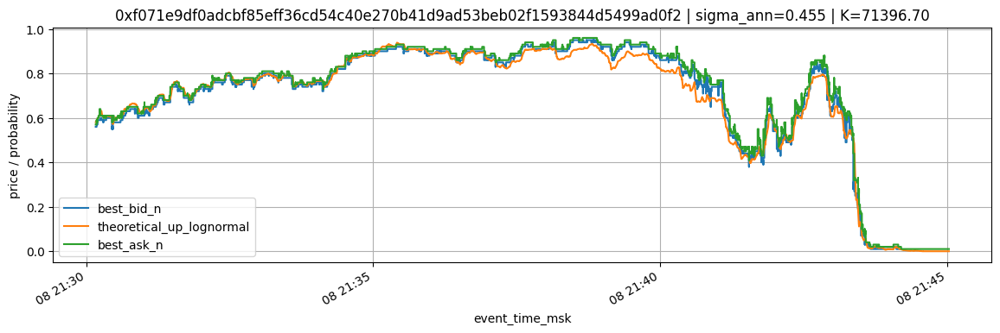

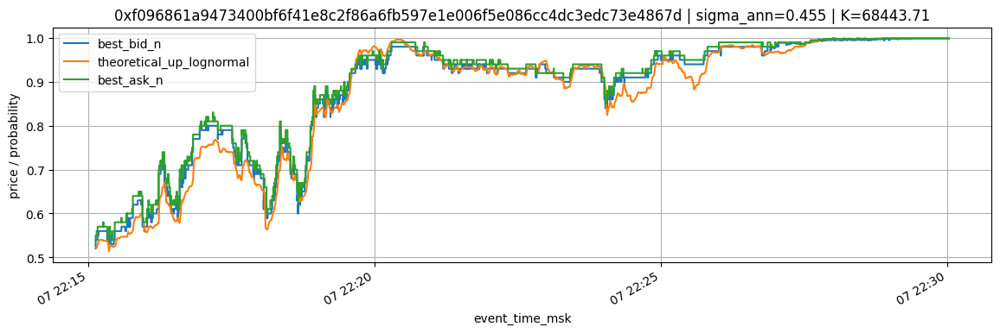

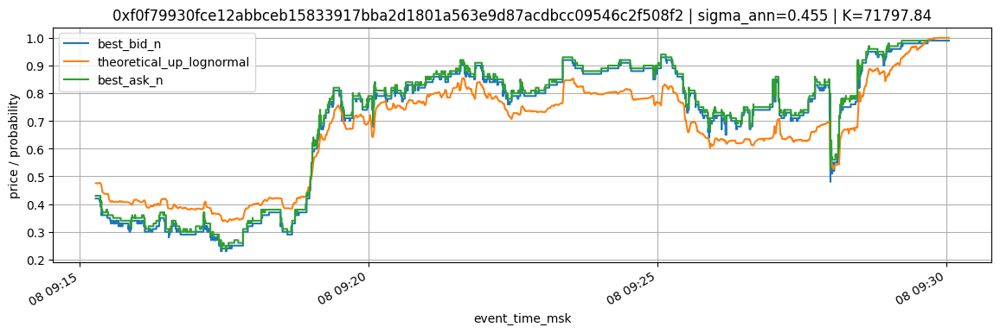

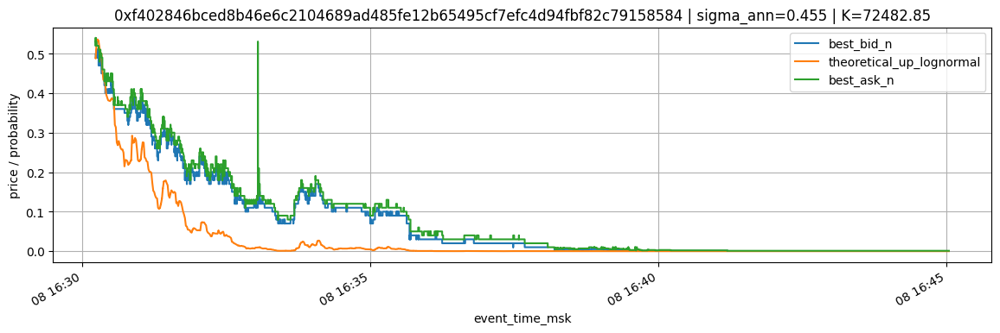

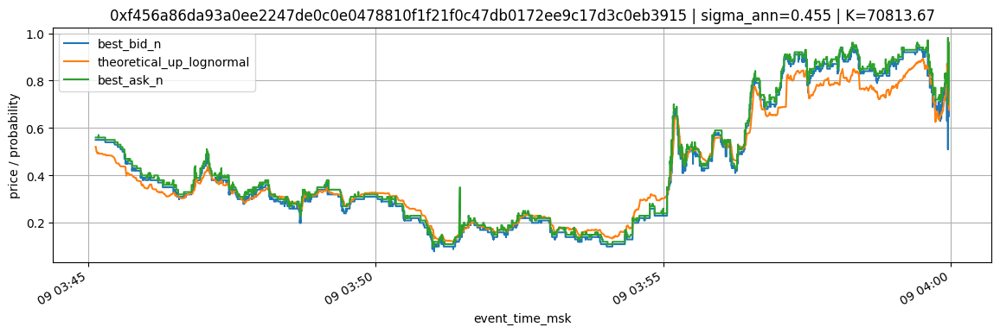

...

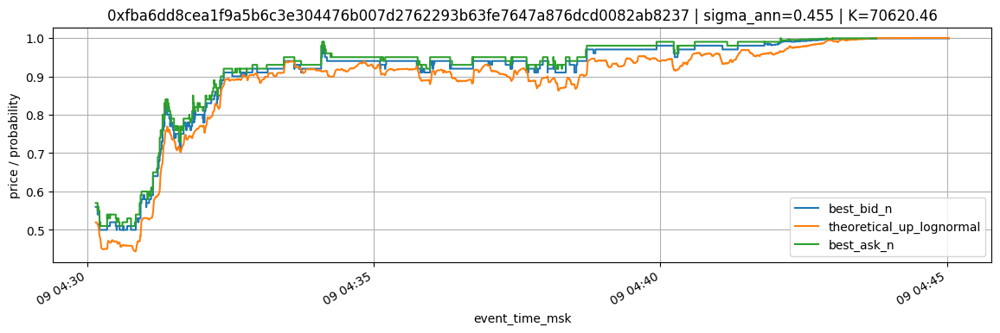

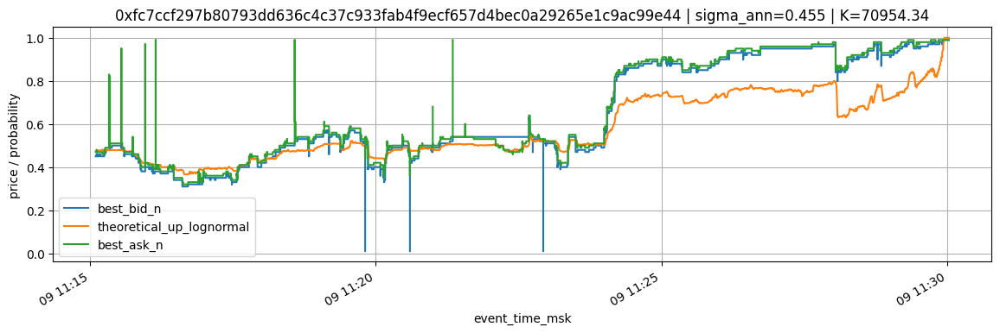

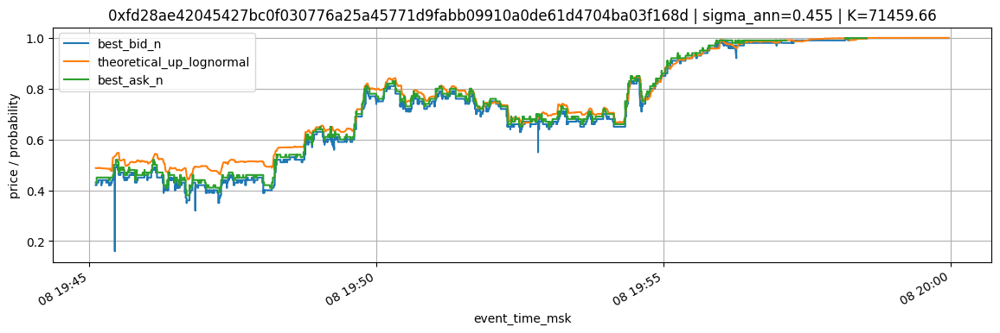

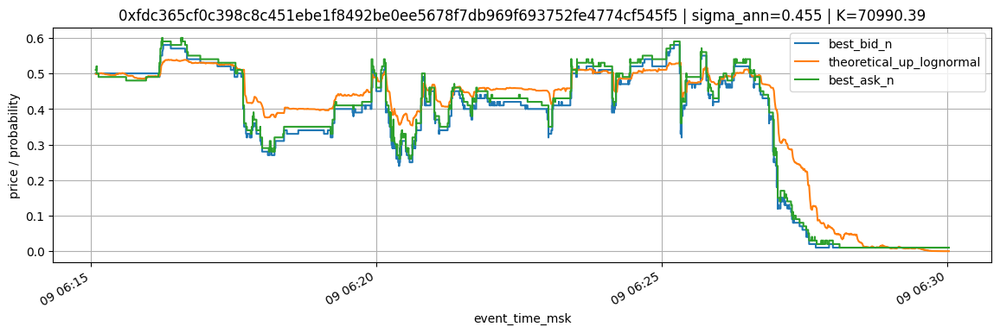

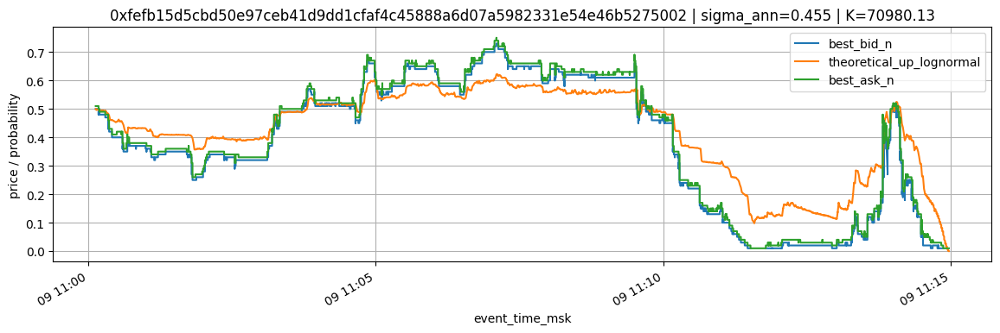

In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv

# =========================
# ПАРАМЕТРЫ
# =========================
market_ids = [
    "0xc66cf74473f7ecb2cec53a381c00ec510048e9f5b2590cb570830ad4780c0fdf",
    "0xc69014755c87a6afa660ddc3ba1228a4af76b65ac129f056f24f8b5341ea27b7",
    "0xc8342a0b2af9004b96f2a572230add68bb1975ce8a669771cf9f90f92532a2d6",
    "0xc8651912e1c3d9f2ed34bce3838a15a8599561bef9b5ebb7e3ad87e77d85aaac",
    "0xc8c72cc4d434f10edfa06fffb99a643e47a9ff761ed5d8077d65132f304659ed",
    "0xc8d4cfcd3dbfc36ab6aae90cad35f94c4528e4bacee21478c0e79c86848075b5",
    "0xc97bb66eadd5ac03c8dafc21739df72ace3d6e9d547884eb8942f97f9b7ec6ba",
    "0xcad8939ca0ca04f2391f01fe81be9d729c1fe776e6168416b74055b350a2ec17",
    "0xcb555db08c61e69e4c1915b2019ecd04a592ea074cce7058c5b7a05ffb1f121b",
    "0xcbaeb9259dc14ca20522f7527e435a97cce08d411082026e8e5d1d5c84b60d7f",
    "0xcf087d5cda40cfd1cc0b10d2bcc800899a51ccb7bc5fc6c305c35437effe00a0",
    "0xcf58666386cc4d582173f130084ca86fb5620a891d52179429a758ea2a6aff49",
    "0xcff791a0600f12bf486bb7ed2f102fd350b3bd91999509c844f1e29850f6368f",
    "0xd2fcfa85cec036ffad934b4b13d3f7d2ff7d8b79ba8826734817ba706938658b",
    "0xd315c3d90ac407c62399316749df11ffdff7ae4770dfa3e467a05f7429d60246",
    "0xd3f600c80576e30f145fb54bf44ce4340023f3aa69f5c61fa508b54e9e78776e",
    "0xd4866c074ba8a11194d0531b2c5c980eea219b277cd6b7a51a48de7dd30b2a8c",
    "0xd6721d774320949729ea04c29fd7c0f3855a1e915d8f50f3a9f7e17bb7154d70",
    "0xd79826ebb4a10ab6014e9b4edc5efd63ff5048086d4261dfb5ffecb341a40c3c",
    "0xd8099fd68c787ebd631ad90dcf6358174641e7d4bd006c82924f2db1f5cae710",
    "0xd8410a28d2123d45b451daca5d81057b40843bfbfd68ce63d97c3e6cbddd3d20",
    "0xdc23c47668ed31e677d67dadab60edb5b260f44f6b31758cc61003d7edb88d7d",
    "0xdca3fa1cdc355b1e1d7413d816d34546ec54d53555145b9f487dbd1925a48fe4",
    "0xdd352ddcd76511037889767d5e3d1f8621087208122e44229164f5ee7614eff9",
    "0xdd79290e98e397b766b5fc9927fc1adf725e82aff1f936afbbf5ee8d1caa91b6",
    "0xddbd05702c8a607a12fbe29817cfb8a02b77fd2ee8ca1681ae59b7380b08460a",
    "0xe036e7b24a68063a1a7ba6ea7834c89817c46e30dfb7feb684e2e56518dad5b9",
    "0xe1277848f1d6f4e1728c0a6c895d46ec7c12d0fbc8e2a8c8efbce4bfde1575e9",
]

min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann = 0.455

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def build_quotes_df(market: str, min_total_size: float) -> pd.DataFrame:
    meta_sql = f"""
    SELECT
        market,
        asset_id,
        hash,
        max(event_ts_ms) AS snapshot_ts_ms,
        max(event_time_msk) AS snapshot_time_msk
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
    GROUP BY market, asset_id, hash
    ORDER BY snapshot_ts_ms DESC
    LIMIT 1
    """
    meta_res = c.query(meta_sql)
    if not meta_res.result_rows:
        raise ValueError("Не найден snapshot")

    meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
    asset_id = str(meta["asset_id"])
    ob_hash = str(meta["hash"])
    snapshot_ts_ms = int(meta["snapshot_ts_ms"])
    snapshot_time_msk = meta["snapshot_time_msk"]

    snap_sql = f"""
    SELECT side, price, size
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND hash = {q(ob_hash)}
    ORDER BY price ASC
    """
    snap_res = c.query(snap_sql)
    df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
    if df_snap.empty:
        raise ValueError("Пустой snapshot")

    price_grid = sorted(float(x) for x in df_snap["price"].tolist())
    bid_prices_desc = list(reversed(price_grid))
    ask_prices_asc = price_grid[:]

    bid_sizes = {p: 0.0 for p in price_grid}
    ask_sizes = {p: 0.0 for p in price_grid}

    for row in df_snap.itertuples(index=False):
        p = float(row.price)
        s = float(row.size)
        if row.side == "bid":
            bid_sizes[p] = s
        elif row.side == "ask":
            ask_sizes[p] = s

    records = []

    bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
    ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
    records.append({
        "event_time_msk": snapshot_time_msk,
        "event_ts_ms": snapshot_ts_ms,
        "best_bid_n": bb,
        "best_ask_n": ba,
    })

    pc_sql = f"""
    SELECT event_time_msk, event_ts_ms, side, price, size
    FROM {DB}.{PRICECHANGE_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND event_ts_ms >= {snapshot_ts_ms}
    ORDER BY event_ts_ms ASC, price ASC
    """
    pc_res = c.query(pc_sql)
    df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

    if not df_pc.empty:
        current_ts = None
        current_time = None

        for row in df_pc.itertuples(index=False):
            row_ts = int(row.event_ts_ms)

            if current_ts is None:
                current_ts = row_ts
                current_time = row.event_time_msk
            elif row_ts != current_ts:
                bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
                ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
                records.append({
                    "event_time_msk": current_time,
                    "event_ts_ms": current_ts,
                    "best_bid_n": bb,
                    "best_ask_n": ba,
                })
                current_ts = row_ts
                current_time = row.event_time_msk

            p = float(row.price)
            ds = float(row.size)

            if row.side == "bid":
                ns = bid_sizes.get(p, 0.0) + ds
                bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
            elif row.side == "ask":
                ns = ask_sizes.get(p, 0.0) + ds
                ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

        if current_ts is not None:
            bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })

    df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
    if df_quotes.empty:
        raise ValueError("df_quotes пустой")

    return df_quotes

def build_spot_df() -> pd.DataFrame:
    spot_sql = f"""
    SELECT event_ts_ms, event_time_msk, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
    ORDER BY event_ts_ms ASC
    """
    spot_res = c.query(spot_sql)
    df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
    if df_spot.empty:
        raise ValueError("Пустой df_spot")

    df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
    df_spot["value"] = df_spot["value"].astype(float)
    df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)
    return df_spot

df_spot = build_spot_df()

for market in market_ids:
    try:
        df_quotes = build_quotes_df(market, min_total_size=min_total_size)

        market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
        market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

        p2b_sql = f"""
        SELECT event_ts_ms, value
        FROM {DB}.{SPOT_TABLE}
        WHERE symbol = {q(symbol.lower())}
          AND event_ts_ms >= {market_start_ts_ms}
        ORDER BY event_ts_ms ASC
        LIMIT 1
        """
        p2b = c.query(p2b_sql).result_rows
        if not p2b:
            print(f"SKIP {market}: не найден price_to_beat")
            continue

        price_to_beat = float(p2b[0][1])

        df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
        df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

        df_bs = pd.merge_asof(
            df_q,
            df_s[["event_ts_ms", "value"]],
            on="event_ts_ms",
            direction="backward"
        )

        df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
        df_bs["spot_value"] = df_bs["value"].ffill().bfill()
        df_bs["price_to_beat"] = price_to_beat
        df_bs["market_end_ts_ms"] = market_end_ts_ms
        df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
        df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

        df_bs["theoretical_up_lognormal"] = np.where(
            df_bs["time_to_expiry_sec"] <= 0,
            (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
            np.nan
        )

        mask = (
            (df_bs["time_to_expiry_sec"] > 0)
            & (df_bs["spot_value"] > 0)
            & (df_bs["price_to_beat"] > 0)
        )

        d2 = (
            np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
            + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
        ) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

        df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
        df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

        ax = df_bs.plot(
            x="event_time_msk",
            y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
            figsize=(14, 4),
            grid=True,
            title=f"{market} | sigma_ann={sigma_ann:.3f} | K={price_to_beat:.2f}",
        )
        ax.set_ylabel("price / probability")
        plt.show()

    except Exception as e:
        print(f"SKIP {market}: {e}")


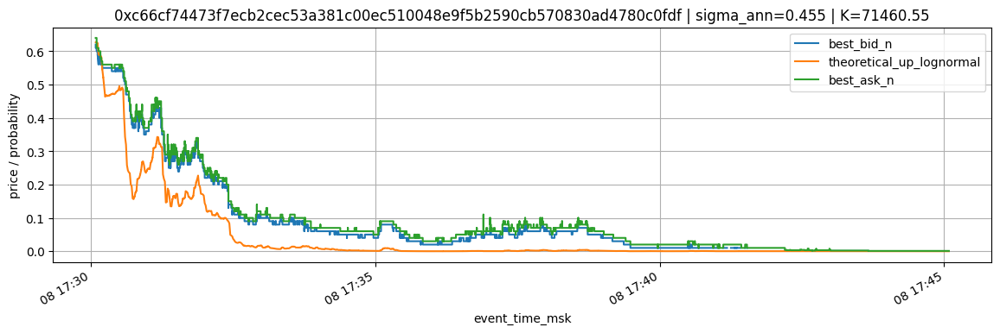

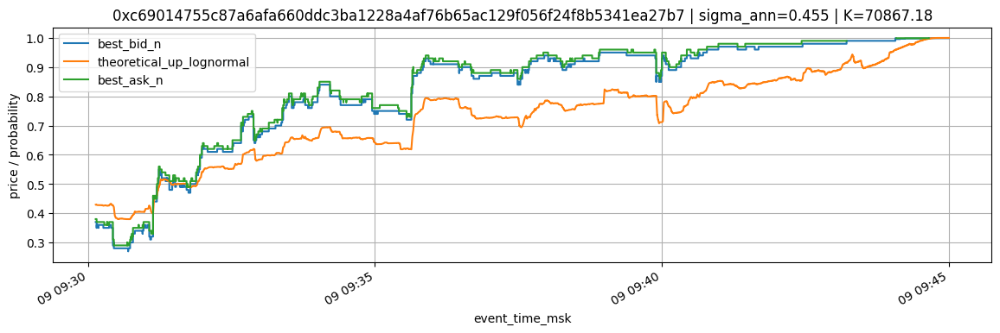

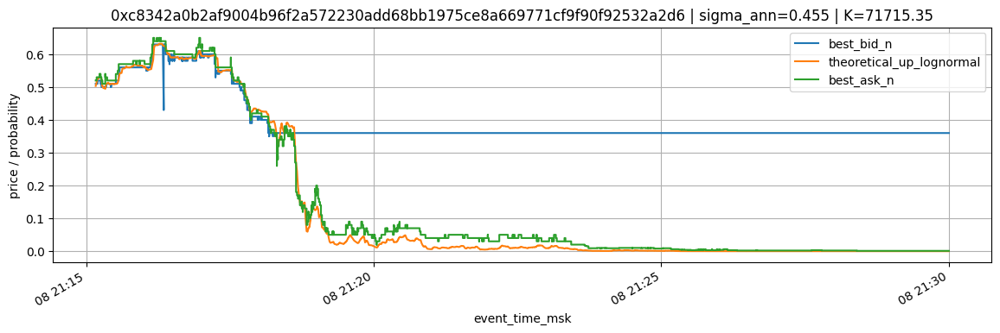

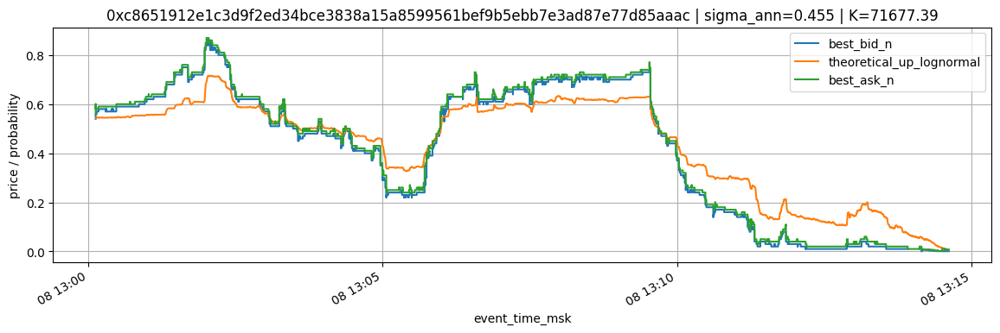

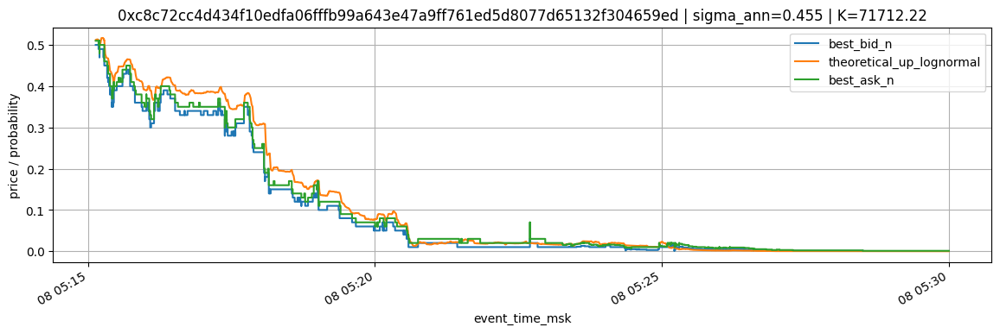

...

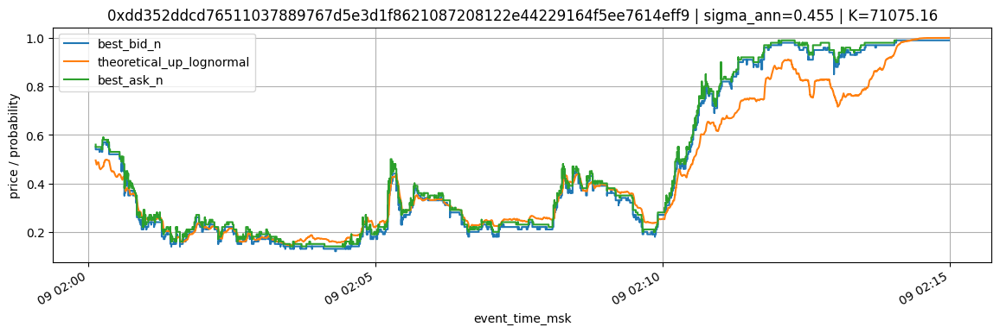

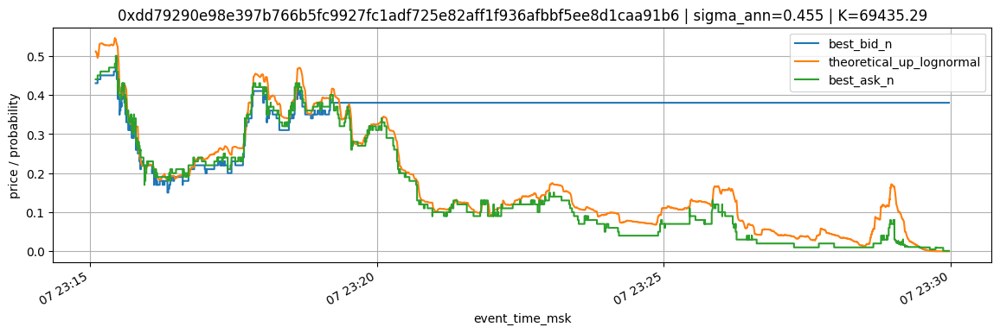

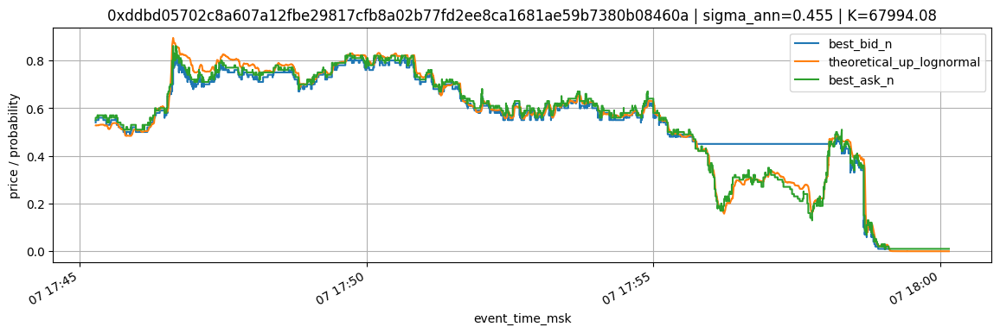

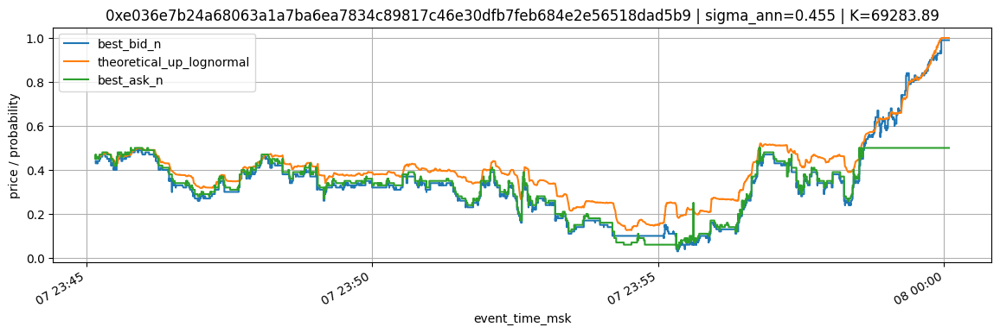

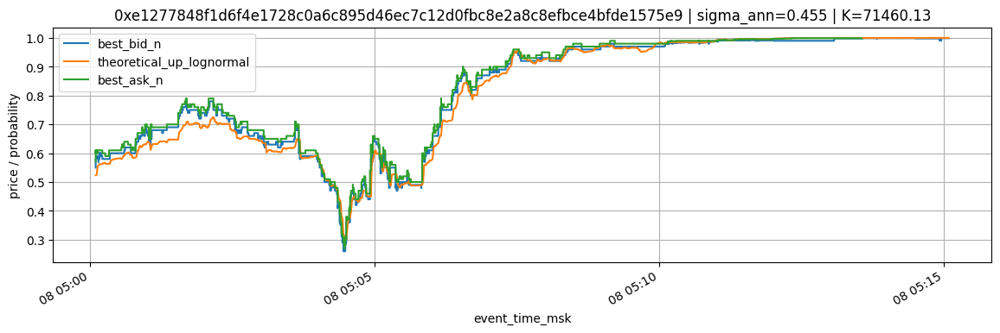

In [ ]:
import os
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv

# =========================
# ПАРАМЕТРЫ
# =========================
market_ids = [
    "0xc66cf74473f7ecb2cec53a381c00ec510048e9f5b2590cb570830ad4780c0fdf",
    "0xc69014755c87a6afa660ddc3ba1228a4af76b65ac129f056f24f8b5341ea27b7",
    "0xc8342a0b2af9004b96f2a572230add68bb1975ce8a669771cf9f90f92532a2d6",
    "0xc8651912e1c3d9f2ed34bce3838a15a8599561bef9b5ebb7e3ad87e77d85aaac",
    "0xc8c72cc4d434f10edfa06fffb99a643e47a9ff761ed5d8077d65132f304659ed",
    "0xc8d4cfcd3dbfc36ab6aae90cad35f94c4528e4bacee21478c0e79c86848075b5",
    "0xc97bb66eadd5ac03c8dafc21739df72ace3d6e9d547884eb8942f97f9b7ec6ba",
    "0xcad8939ca0ca04f2391f01fe81be9d729c1fe776e6168416b74055b350a2ec17",
    "0xcb555db08c61e69e4c1915b2019ecd04a592ea074cce7058c5b7a05ffb1f121b",
    "0xcbaeb9259dc14ca20522f7527e435a97cce08d411082026e8e5d1d5c84b60d7f",
    "0xcf087d5cda40cfd1cc0b10d2bcc800899a51ccb7bc5fc6c305c35437effe00a0",
    "0xcf58666386cc4d582173f130084ca86fb5620a891d52179429a758ea2a6aff49",
    "0xcff791a0600f12bf486bb7ed2f102fd350b3bd91999509c844f1e29850f6368f",
    "0xd2fcfa85cec036ffad934b4b13d3f7d2ff7d8b79ba8826734817ba706938658b",
    "0xd315c3d90ac407c62399316749df11ffdff7ae4770dfa3e467a05f7429d60246",
    "0xd3f600c80576e30f145fb54bf44ce4340023f3aa69f5c61fa508b54e9e78776e",
    "0xd4866c074ba8a11194d0531b2c5c980eea219b277cd6b7a51a48de7dd30b2a8c",
    "0xd6721d774320949729ea04c29fd7c0f3855a1e915d8f50f3a9f7e17bb7154d70",
    "0xd79826ebb4a10ab6014e9b4edc5efd63ff5048086d4261dfb5ffecb341a40c3c",
    "0xd8099fd68c787ebd631ad90dcf6358174641e7d4bd006c82924f2db1f5cae710",
    "0xd8410a28d2123d45b451daca5d81057b40843bfbfd68ce63d97c3e6cbddd3d20",
    "0xdc23c47668ed31e677d67dadab60edb5b260f44f6b31758cc61003d7edb88d7d",
    "0xdca3fa1cdc355b1e1d7413d816d34546ec54d53555145b9f487dbd1925a48fe4",
    "0xdd352ddcd76511037889767d5e3d1f8621087208122e44229164f5ee7614eff9",
    "0xdd79290e98e397b766b5fc9927fc1adf725e82aff1f936afbbf5ee8d1caa91b6",
    "0xddbd05702c8a607a12fbe29817cfb8a02b77fd2ee8ca1681ae59b7380b08460a",
    "0xe036e7b24a68063a1a7ba6ea7834c89817c46e30dfb7feb684e2e56518dad5b9",
    "0xe1277848f1d6f4e1728c0a6c895d46ec7c12d0fbc8e2a8c8efbce4bfde1575e9",
]

min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann = 0.455

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def build_quotes_df(market: str, min_total_size: float) -> pd.DataFrame:
    meta_sql = f"""
    SELECT
        market,
        asset_id,
        hash,
        max(event_ts_ms) AS snapshot_ts_ms,
        max(event_time_msk) AS snapshot_time_msk
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
    GROUP BY market, asset_id, hash
    ORDER BY snapshot_ts_ms DESC
    LIMIT 1
    """
    meta_res = c.query(meta_sql)
    if not meta_res.result_rows:
        raise ValueError("Не найден snapshot")

    meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
    asset_id = str(meta["asset_id"])
    ob_hash = str(meta["hash"])
    snapshot_ts_ms = int(meta["snapshot_ts_ms"])
    snapshot_time_msk = meta["snapshot_time_msk"]

    snap_sql = f"""
    SELECT side, price, size
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND hash = {q(ob_hash)}
    ORDER BY price ASC
    """
    snap_res = c.query(snap_sql)
    df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
    if df_snap.empty:
        raise ValueError("Пустой snapshot")

    price_grid = sorted(float(x) for x in df_snap["price"].tolist())
    bid_prices_desc = list(reversed(price_grid))
    ask_prices_asc = price_grid[:]

    bid_sizes = {p: 0.0 for p in price_grid}
    ask_sizes = {p: 0.0 for p in price_grid}

    for row in df_snap.itertuples(index=False):
        p = float(row.price)
        s = float(row.size)
        if row.side == "bid":
            bid_sizes[p] = s
        elif row.side == "ask":
            ask_sizes[p] = s

    records = []

    bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
    ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
    records.append({
        "event_time_msk": snapshot_time_msk,
        "event_ts_ms": snapshot_ts_ms,
        "best_bid_n": bb,
        "best_ask_n": ba,
    })

    pc_sql = f"""
    SELECT event_time_msk, event_ts_ms, side, price, size
    FROM {DB}.{PRICECHANGE_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND event_ts_ms >= {snapshot_ts_ms}
    ORDER BY event_ts_ms ASC, price ASC
    """
    pc_res = c.query(pc_sql)
    df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

    if not df_pc.empty:
        current_ts = None
        current_time = None

        for row in df_pc.itertuples(index=False):
            row_ts = int(row.event_ts_ms)

            if current_ts is None:
                current_ts = row_ts
                current_time = row.event_time_msk
            elif row_ts != current_ts:
                bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
                ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
                records.append({
                    "event_time_msk": current_time,
                    "event_ts_ms": current_ts,
                    "best_bid_n": bb,
                    "best_ask_n": ba,
                })
                current_ts = row_ts
                current_time = row.event_time_msk

            p = float(row.price)
            ds = float(row.size)

            if row.side == "bid":
                ns = bid_sizes.get(p, 0.0) + ds
                bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
            elif row.side == "ask":
                ns = ask_sizes.get(p, 0.0) + ds
                ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

        if current_ts is not None:
            bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })

    df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
    if df_quotes.empty:
        raise ValueError("df_quotes пустой")

    return df_quotes

def build_spot_df() -> pd.DataFrame:
    spot_sql = f"""
    SELECT event_ts_ms, event_time_msk, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
    ORDER BY event_ts_ms ASC
    """
    spot_res = c.query(spot_sql)
    df_spot = pd.DataFrame(spot_res.result_rows, columns=spot_res.column_names)
    if df_spot.empty:
        raise ValueError("Пустой df_spot")

    df_spot["event_time_msk"] = pd.to_datetime(df_spot["event_time_msk"])
    df_spot["value"] = df_spot["value"].astype(float)
    df_spot = df_spot.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)
    return df_spot

df_spot = build_spot_df()

for market in market_ids:
    try:
        df_quotes = build_quotes_df(market, min_total_size=min_total_size)

        market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
        market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

        p2b_sql = f"""
        SELECT event_ts_ms, value
        FROM {DB}.{SPOT_TABLE}
        WHERE symbol = {q(symbol.lower())}
          AND event_ts_ms >= {market_start_ts_ms}
        ORDER BY event_ts_ms ASC
        LIMIT 1
        """
        p2b = c.query(p2b_sql).result_rows
        if not p2b:
            print(f"SKIP {market}: не найден price_to_beat")
            continue

        price_to_beat = float(p2b[0][1])

        df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
        df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

        df_bs = pd.merge_asof(
            df_q,
            df_s[["event_ts_ms", "value"]],
            on="event_ts_ms",
            direction="backward"
        )

        df_bs["event_time_msk"] = pd.to_datetime(df_bs["event_time_msk"])
        df_bs["spot_value"] = df_bs["value"].ffill().bfill()
        df_bs["price_to_beat"] = price_to_beat
        df_bs["market_end_ts_ms"] = market_end_ts_ms
        df_bs["time_to_expiry_sec"] = ((df_bs["market_end_ts_ms"] - df_bs["event_ts_ms"]) / 1000.0).clip(lower=0.0)
        df_bs["tau_years"] = df_bs["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

        df_bs["theoretical_up_lognormal"] = np.where(
            df_bs["time_to_expiry_sec"] <= 0,
            (df_bs["spot_value"] >= df_bs["price_to_beat"]).astype(float),
            np.nan
        )

        mask = (
            (df_bs["time_to_expiry_sec"] > 0)
            & (df_bs["spot_value"] > 0)
            & (df_bs["price_to_beat"] > 0)
        )

        d2 = (
            np.log(df_bs.loc[mask, "spot_value"] / df_bs.loc[mask, "price_to_beat"])
            + (r - 0.5 * sigma_ann * sigma_ann) * df_bs.loc[mask, "tau_years"]
        ) / (sigma_ann * np.sqrt(df_bs.loc[mask, "tau_years"]))

        df_bs.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
        df_bs["theoretical_up_lognormal"] = pd.Series(df_bs["theoretical_up_lognormal"]).clip(0.0, 1.0)

        ax = df_bs.plot(
            x="event_time_msk",
            y=["best_bid_n", "theoretical_up_lognormal", "best_ask_n"],
            figsize=(14, 4),
            grid=True,
            title=f"{market} | sigma_ann={sigma_ann:.3f} | K={price_to_beat:.2f}",
        )
        ax.set_ylabel("price / probability")
        plt.show()

    except Exception as e:
        print(f"SKIP {market}: {e}")


In [33]:
import os
import re
import math
import numpy as np
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market_blob = r"""
0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81
0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e
0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f
0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216
0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f
0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524
0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d
0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f
0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826
0x1297284c2f0ba30a96cf2f42c5f7c6e04d1cadf69283ae5e182d776bf53fbc07
0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42
0x1456776819fdbe1973edc8dc49f6a3d16d3a36facfce6990f9278adb7da19a94
0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33
0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76
0x18278fbc17717faf47a21c033ddfc55281f976c14f31ae61b4bb4e65794ae1d4
0x18da6797a09676030d2c3506e4a050d9e92c60ff8466114464aeae86c62cad1e
0x194a3ecc437561e79e0154b03313680b2d3976ad2e9b7e5940e8de5c93d58092
0x19a4f6a6eb797f34df9e1092a763d32b0207cb25c3ffbad9e0b657a1ed20c9b5
0x1bf9497cf26ac62d3dfad5c7eb85a79efc716bff43e80763be93b93d73ac73f7
0x1ccd9f2a68e0ea92091d68b1457a715c46d5fc83cb413e735de559a11007e591
0x1e536a1659c230c0ebbafd838d3cb0c0d5dabc2094a0a6436405ad6dab5067ca
0x1eb9a51ddfb38683a6771d5d26f16e5f513421bd11dbd4f773a812c30651bd4f
0x1fa863a2ab2975463afa620a45b10440f7a3d3dfb5cd622a40dd87b335a441f7
0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6
0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9
0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70
0x24030a34823d17724ac4c0ce726e02f81a9c221b5854eacea51575d5ffe3f839
"""

min_total_size = 50.0
symbol = "btc/usd"
r = 0.0
sigma_ann = 0.455

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

# =========================
# MARKET IDS
# =========================
market_ids = re.findall(r"0x[a-fA-F0-9]{64}", market_blob)
market_ids = list(dict.fromkeys(market_ids))

if not market_ids:
    raise ValueError("Не удалось распарсить ни одного market id из market_blob")

print(f"market_ids parsed: {len(market_ids)}")
print(f"sigma_ann_used: {sigma_ann:.6f}")

# =========================
# HELPERS
# =========================
def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def build_spot_df():
    sql = f"""
    SELECT event_ts_ms, event_time_msk, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
    ORDER BY event_ts_ms ASC
    """
    res = c.query(sql)
    df = pd.DataFrame(res.result_rows, columns=res.column_names)
    if df.empty:
        raise ValueError("Пустой btc_spot")
    df["event_time_msk"] = pd.to_datetime(df["event_time_msk"])
    df["value"] = df["value"].astype(float)
    df = df.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)
    return df

def build_quotes_df(market: str, min_total_size: float):
    meta_sql = f"""
    SELECT
        market,
        asset_id,
        hash,
        max(event_ts_ms) AS snapshot_ts_ms,
        max(event_time_msk) AS snapshot_time_msk
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
    GROUP BY market, asset_id, hash
    ORDER BY snapshot_ts_ms DESC
    LIMIT 1
    """
    meta_res = c.query(meta_sql)
    if not meta_res.result_rows:
        raise ValueError("Не найден snapshot")

    meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
    asset_id = str(meta["asset_id"])
    ob_hash = str(meta["hash"])
    snapshot_ts_ms = int(meta["snapshot_ts_ms"])
    snapshot_time_msk = meta["snapshot_time_msk"]

    snap_sql = f"""
    SELECT side, price, size
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND hash = {q(ob_hash)}
    ORDER BY price ASC
    """
    snap_res = c.query(snap_sql)
    df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
    if df_snap.empty:
        raise ValueError("Пустой snapshot")

    price_grid = sorted(float(x) for x in df_snap["price"].tolist())
    bid_prices_desc = list(reversed(price_grid))
    ask_prices_asc = price_grid[:]

    bid_sizes = {p: 0.0 for p in price_grid}
    ask_sizes = {p: 0.0 for p in price_grid}

    for row in df_snap.itertuples(index=False):
        p = float(row.price)
        s = float(row.size)
        if row.side == "bid":
            bid_sizes[p] = s
        elif row.side == "ask":
            ask_sizes[p] = s

    records = []

    bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
    ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
    records.append({
        "event_time_msk": snapshot_time_msk,
        "event_ts_ms": snapshot_ts_ms,
        "best_bid_n": bb,
        "best_ask_n": ba,
    })

    pc_sql = f"""
    SELECT event_time_msk, event_ts_ms, side, price, size
    FROM {DB}.{PRICECHANGE_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND event_ts_ms >= {snapshot_ts_ms}
    ORDER BY event_ts_ms ASC, price ASC
    """
    pc_res = c.query(pc_sql)
    df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

    if not df_pc.empty:
        current_ts = None
        current_time = None

        for row in df_pc.itertuples(index=False):
            row_ts = int(row.event_ts_ms)

            if current_ts is None:
                current_ts = row_ts
                current_time = row.event_time_msk
            elif row_ts != current_ts:
                bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
                ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
                records.append({
                    "event_time_msk": current_time,
                    "event_ts_ms": current_ts,
                    "best_bid_n": bb,
                    "best_ask_n": ba,
                })
                current_ts = row_ts
                current_time = row.event_time_msk

            p = float(row.price)
            ds = float(row.size)

            if row.side == "bid":
                ns = bid_sizes.get(p, 0.0) + ds
                bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
            elif row.side == "ask":
                ns = ask_sizes.get(p, 0.0) + ds
                ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

        if current_ts is not None:
            bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "event_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })

    df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
    if df_quotes.empty:
        raise ValueError("df_quotes пустой")

    return df_quotes, asset_id

def first_price_to_beat(market_start_ts_ms: int):
    sql = f"""
    SELECT event_ts_ms, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
      AND event_ts_ms >= {market_start_ts_ms}
    ORDER BY event_ts_ms ASC
    LIMIT 1
    """
    rows = c.query(sql).result_rows
    mode = "first_at_or_after_market_start"

    if not rows:
        sql_fb = f"""
        SELECT event_ts_ms, value
        FROM {DB}.{SPOT_TABLE}
        WHERE symbol = {q(symbol.lower())}
          AND event_ts_ms < {market_start_ts_ms}
        ORDER BY event_ts_ms DESC
        LIMIT 1
        """
        rows = c.query(sql_fb).result_rows
        mode = "last_before_market_start_fallback"

    if not rows:
        raise ValueError("Не найден price_to_beat")

    return int(rows[0][0]), float(rows[0][1]), mode

# =========================
# SPOT
# =========================
df_spot = build_spot_df()

# =========================
# MAIN LOOP
# =========================
results = []

for i, market in enumerate(market_ids, start=1):
    print(f"[{i}/{len(market_ids)}] {market}")

    try:
        df_quotes, asset_id = build_quotes_df(market, min_total_size=min_total_size)

        market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
        market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

        p2b_ts_ms, price_to_beat, price_to_beat_mode = first_price_to_beat(market_start_ts_ms)

        df_q = df_quotes.sort_values("event_ts_ms").reset_index(drop=True).copy()
        df_s = df_spot.sort_values("event_ts_ms").reset_index(drop=True).copy()

        df = pd.merge_asof(
            df_q,
            df_s[["event_ts_ms", "value"]],
            on="event_ts_ms",
            direction="backward"
        )

        df["event_time_msk"] = pd.to_datetime(df["event_time_msk"])
        df["spot_value"] = df["value"].ffill().bfill()
        df["price_to_beat"] = price_to_beat
        df["market_end_ts_ms"] = market_end_ts_ms
        df["time_to_expiry_sec"] = ((df["market_end_ts_ms"] - df["event_ts_ms"]) / 1000.0).clip(lower=0.0)
        df["tau_years"] = df["time_to_expiry_sec"] / (365.0 * 24.0 * 60.0 * 60.0)

        df["theoretical_up_lognormal"] = np.where(
            df["time_to_expiry_sec"] <= 0,
            (df["spot_value"] >= df["price_to_beat"]).astype(float),
            np.nan
        )

        mask = (
            (df["time_to_expiry_sec"] > 0)
            & (df["spot_value"] > 0)
            & (df["price_to_beat"] > 0)
        )

        d2 = (
            np.log(df.loc[mask, "spot_value"] / df.loc[mask, "price_to_beat"])
            + (r - 0.5 * sigma_ann * sigma_ann) * df.loc[mask, "tau_years"]
        ) / (sigma_ann * np.sqrt(df.loc[mask, "tau_years"]))

        df.loc[mask, "theoretical_up_lognormal"] = d2.apply(norm_cdf).astype(float)
        df["theoretical_up_lognormal"] = pd.Series(df["theoretical_up_lognormal"]).clip(0.0, 1.0)

        valid_bid = df["best_bid_n"].notna()
        valid_ask = df["best_ask_n"].notna()
        valid_spread = valid_bid & valid_ask

        df["mid_n"] = np.where(valid_spread, (df["best_bid_n"] + df["best_ask_n"]) / 2.0, np.nan)
        df["buy_edge_bs"] = df["theoretical_up_lognormal"] - df["best_ask_n"]
        df["sell_edge_bs"] = df["best_bid_n"] - df["theoretical_up_lognormal"]
        df["cross_side_edge_bs"] = np.nanmax(
            np.vstack([df["buy_edge_bs"].to_numpy(), df["sell_edge_bs"].to_numpy()]),
            axis=0
        )

        inside_spread_rate = float(
            ((df.loc[valid_spread, "theoretical_up_lognormal"] >= df.loc[valid_spread, "best_bid_n"]) &
             (df.loc[valid_spread, "theoretical_up_lognormal"] <= df.loc[valid_spread, "best_ask_n"])).mean()
        ) if valid_spread.any() else np.nan

        mae_to_mid = float(
            (df.loc[valid_spread, "theoretical_up_lognormal"] - df.loc[valid_spread, "mid_n"]).abs().mean()
        ) if valid_spread.any() else np.nan

        rmse_to_mid = float(
            np.sqrt(((df.loc[valid_spread, "theoretical_up_lognormal"] - df.loc[valid_spread, "mid_n"]) ** 2).mean())
        ) if valid_spread.any() else np.nan

        pct_theory_above_ask = float(
            (df.loc[valid_ask, "theoretical_up_lognormal"] > df.loc[valid_ask, "best_ask_n"]).mean()
        ) if valid_ask.any() else np.nan

        pct_theory_below_bid = float(
            (df.loc[valid_bid, "theoretical_up_lognormal"] < df.loc[valid_bid, "best_bid_n"]).mean()
        ) if valid_bid.any() else np.nan

        mean_buy_edge = float(df.loc[valid_ask, "buy_edge_bs"].mean()) if valid_ask.any() else np.nan
        mean_sell_edge = float(df.loc[valid_bid, "sell_edge_bs"].mean()) if valid_bid.any() else np.nan
        p95_cross_side_edge = float(df["cross_side_edge_bs"].dropna().quantile(0.95)) if df["cross_side_edge_bs"].notna().any() else np.nan
        max_cross_side_edge = float(df["cross_side_edge_bs"].dropna().max()) if df["cross_side_edge_bs"].notna().any() else np.nan

        results.append({
            "market": market,
            "status": "ok",
            "asset_id_used": asset_id,
            "rows_total": int(len(df)),
            "rows_with_bid": int(valid_bid.sum()),
            "rows_with_ask": int(valid_ask.sum()),
            "rows_with_spread": int(valid_spread.sum()),
            "market_start_msk": pd.to_datetime(market_start_ts_ms, unit="ms"),
            "market_end_msk": pd.to_datetime(market_end_ts_ms, unit="ms"),
            "price_to_beat_ts_msk": pd.to_datetime(p2b_ts_ms, unit="ms"),
            "price_to_beat": float(price_to_beat),
            "price_to_beat_mode": price_to_beat_mode,
            "sigma_ann_used": float(sigma_ann),
            "inside_spread_rate": inside_spread_rate,
            "mae_to_mid": mae_to_mid,
            "rmse_to_mid": rmse_to_mid,
            "pct_theory_above_ask": pct_theory_above_ask,
            "pct_theory_below_bid": pct_theory_below_bid,
            "mean_buy_edge": mean_buy_edge,
            "mean_sell_edge": mean_sell_edge,
            "p95_cross_side_edge": p95_cross_side_edge,
            "max_cross_side_edge": max_cross_side_edge,
        })

    except Exception as e:
        results.append({
            "market": market,
            "status": "error",
            "error": str(e),
        })

# =========================
# RESULTS
# =========================
df_results = pd.DataFrame(results)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)

display(df_results)

df_ok = df_results[df_results["status"] == "ok"].copy()

if not df_ok.empty:
    df_summary = pd.DataFrame([{
        "markets_total": int(len(df_results)),
        "markets_ok": int(len(df_ok)),
        "markets_error": int((df_results["status"] != "ok").sum()),
        "sigma_ann_used": float(sigma_ann),
        "avg_inside_spread_rate": float(df_ok["inside_spread_rate"].mean()),
        "avg_mae_to_mid": float(df_ok["mae_to_mid"].mean()),
        "avg_rmse_to_mid": float(df_ok["rmse_to_mid"].mean()),
        "avg_pct_theory_above_ask": float(df_ok["pct_theory_above_ask"].mean()),
        "avg_pct_theory_below_bid": float(df_ok["pct_theory_below_bid"].mean()),
        "avg_mean_buy_edge": float(df_ok["mean_buy_edge"].mean()),
        "avg_mean_sell_edge": float(df_ok["mean_sell_edge"].mean()),
        "avg_p95_cross_side_edge": float(df_ok["p95_cross_side_edge"].mean()),
        "avg_max_cross_side_edge": float(df_ok["max_cross_side_edge"].mean()),
    }])
    display(df_summary)

    display(df_ok.sort_values("mae_to_mid").head(20))
    display(df_ok.sort_values("mae_to_mid", ascending=False).head(20))

    df_results.to_csv("lognormal_all_markets_results.csv", index=False)
    df_summary.to_csv("lognormal_all_markets_summary.csv", index=False)

    print("saved:", os.path.abspath("lognormal_all_markets_results.csv"))
    print("saved:", os.path.abspath("lognormal_all_markets_summary.csv"))
else:
    print("Нет ни одного успешно посчитанного market")


market_ids parsed: 37
sigma_ann_used: 0.455000
[1/37] 0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
[2/37] 0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
[3/37] 0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
[4/37] 0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
[5/37] 0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
[6/37] 0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
[7/37] 0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
[8/37] 0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
[9/37] 0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
[10/37] 0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
[11/37] 0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81
[12/37] 0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e
[13/37] 0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8

,market,status,asset_id_used,rows_total,rows_with_bid,rows_with_ask,rows_with_spread,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,sigma_ann_used,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge
0,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb,ok,46133898691135852191946990473600420351728155396936409603522956341486491279578,73609,73603,73583,73577,2026-04-08 12:30:00,2026-04-08 12:45:00,2026-04-08 12:30:00,71770.660417,first_at_or_after_market_start,0.455,0.151610,0.042389,0.053449,0.154547,0.701412,-0.041901,0.029023,0.095426,0.124124
1,0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e,ok,34106525841672834021821605244984054682110864497477902852705951246469427797026,157618,156938,157618,156938,2026-04-07 16:00:00,2026-04-07 16:15:00,2026-04-07 16:00:00,68152.512480,first_at_or_after_market_start,0.455,0.134372,0.028603,0.037547,0.561091,0.441996,0.005331,0.006366,0.151807,0.297760
2,0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540,ok,34285322346064691729556743646828861276772889473320070107564196630891369262683,155956,155956,155956,155956,2026-04-07 14:30:00,2026-04-07 14:45:00,2026-04-07 14:30:00,68140.650000,first_at_or_after_market_start,0.455,0.066936,0.062866,0.078908,0.173530,0.808215,-0.030190,0.081908,0.274922,0.350000
3,0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d,ok,22616365150679809665947117865155619440011481585666610349361207467291890292407,131100,131100,131020,131020,2026-04-08 19:45:00,2026-04-08 20:00:00,2026-04-08 19:45:00,71307.904765,first_at_or_after_market_start,0.455,0.148328,0.037500,0.050478,0.394260,0.457300,-0.009821,-0.010095,0.083988,0.313574
4,0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852,ok,3336719085405493733461543012801718175840606954576213943659919028303162668760,136130,132973,136130,132973,2026-04-08 14:45:00,2026-04-08 15:00:00,2026-04-08 14:45:00,71094.510121,first_at_or_after_market_start,0.455,0.029803,0.088791,0.102654,0.013215,0.956668,-0.093484,0.080186,0.158806,0.198428
5,0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80,ok,29476938569891943360775670024243449630118442821105986134658565608431475549979,62242,62242,60172,60172,2026-04-07 21:30:00,2026-04-07 21:45:00,2026-04-07 21:30:00,69578.170000,first_at_or_after_market_start,0.455,0.389018,0.011310,0.016875,0.356329,0.246184,-0.006987,-0.006386,0.022490,0.079340
6,0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec,ok,57508804808258598111747712419701215686348454986597988996742489934495598544425,92921,92921,92254,92254,2026-04-09 12:15:00,2026-04-09 12:30:00,2026-04-09 12:15:00,71197.430521,first_at_or_after_market_start,0.455,0.032454,0.097265,0.111143,0.583465,0.381550,0.038909,-0.050391,0.164284,0.206421
7,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c,ok,96467833269204558371972780053156551674465209699414894042105876518190549429939,50530,48927,50530,48927,2026-04-08 11:30:00,2026-04-08 11:45:00,2026-04-08 11:30:00,71661.297990,first_at_or_after_market_start,0.455,0.007910,0.092336,0.109025,0.966911,0.000000,0.082859,-0.099174,0.181531,0.210125
8,0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405,ok,17711286975773130269636681188536484801218941570255765573579845578451423402152,93404,92877,93372,92845,2026-04-08 04:45:00,2026-04-08 05:00:00,2026-04-08 04:45:01,71608.650000,first_at_or_after_market_start,0.455,0.099144,0.060189,0.075910,0.446333,0.498433,-0.000506,-0.011256,0.134031,0.198808
9,0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1,ok,46449049675950771704243213491155324865911216238387313676563771411008297195948,69217,68631,69217,68631,2026-04-09 09:30:00,2026-04-09 09:45:00,2026-04-09 09:30:00,71293.023046,first_at_or_after_market_start,0.455,0.048666,0.114200,0.129479,0.847162,0.098090,0.096366,-0.111832,0.

,markets_total,markets_ok,markets_error,sigma_ann_used,avg_inside_spread_rate,avg_mae_to_mid,avg_rmse_to_mid,avg_pct_theory_above_ask,avg_pct_theory_below_bid,avg_mean_buy_edge,avg_mean_sell_edge,avg_p95_cross_side_edge,avg_max_cross_side_edge
0,37,37,0,0.455,0.077542,0.064047,0.076808,0.467698,0.487546,-0.005494,-0.001322,0.140481,0.258665


,market,status,asset_id_used,rows_total,rows_with_bid,rows_with_ask,rows_with_spread,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,sigma_ann_used,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge
5,0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80,ok,29476938569891943360775670024243449630118442821105986134658565608431475549979,62242,62242,60172,60172,2026-04-07 21:30:00,2026-04-07 21:45:00,2026-04-07 21:30:00,69578.170000,first_at_or_after_market_start,0.455,0.389018,0.011310,0.016875,0.356329,0.246184,-0.006987,-0.006386,0.022490,0.079340
22,0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33,ok,111835696215053281171929348730393514232419903880979572868656783791713924350929,93456,93456,91657,91657,2026-04-07 12:15:00,2026-04-07 12:30:00,2026-04-07 12:15:01,68264.974425,first_at_or_after_market_start,0.455,0.264366,0.019238,0.025186,0.114863,0.613690,-0.021478,0.004624,0.044601,0.090686
17,0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f,ok,104978325160672555833996956238064225548682425156537748873976557669409024114908,125795,125511,125795,125511,2026-04-08 01:00:00,2026-04-08 01:15:00,2026-04-08 01:00:01,71706.931389,first_at_or_after_market_start,0.455,0.201879,0.025781,0.035025,0.179530,0.623364,-0.021359,0.002014,0.060331,0.181396
1,0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e,ok,34106525841672834021821605244984054682110864497477902852705951246469427797026,157618,156938,157618,156938,2026-04-07 16:00:00,2026-04-07 16:15:00,2026-04-07 16:00:00,68152.512480,first_at_or_after_market_start,0.455,0.134372,0.028603,0.037547,0.561091,0.441996,0.005331,0.006366,0.151807,0.297760
21,0x1456776819fdbe1973edc8dc49f6a3d16d3a36facfce6990f9278adb7da19a94,ok,94517142385396270906499751057248413170293807913544481009644655342698791984251,132672,132672,132672,132672,2026-04-07 15:30:00,2026-04-07 15:45:00,2026-04-07 15:30:00,68176.377338,first_at_or_after_market_start,0.455,0.109420,0.031352,0.040694,0.829640,0.258751,0.021255,-0.003979,0.210095,0.270000
12,0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f,ok,6582657683974201793282441535737783574904143016504044479247902048437606481737,101266,101266,100284,100284,2026-04-08 17:30:00,2026-04-08 17:45:00,2026-04-08 17:30:00,71651.760040,first_at_or_after_market_start,0.455,0.117177,0.034387,0.041850,0.823511,0.058736,0.023819,-0.040456,0.071624,0.113473
34,0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9,ok,20601805738227323703869814460678373816821762112721986426782436310507824233403,175286,175262,175286,175262,2026-04-09 14:00:00,2026-04-09 14:15:00,2026-04-09 14:00:00,70799.819530,first_at_or_after_market_start,0.455,0.141035,0.034805,0.042949,0.156858,0.702160,-0.029881,0.013513,0.067211,0.156476
26,0x194a3ecc437561e79e0154b03313680b2d3976ad2e9b7e5940e8de5c93d58092,ok,5801382466861755496393384613750261272700876318594988164309262996291232969780,112109,112109,112109,112109,2026-04-07 18:00:00,2026-04-07 18:15:00,2026-04-07 18:00:00,68693.710000,first_at_or_after_market_start,0.455,0.021791,0.037188,0.049526,0.962001,0.654479,0.054400,0.072449,0.285861,0.440000
3,0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d,ok,22616365150679809665947117865155619440011481585666610349361207467291890292407,131100,131100,131020,131020,2026-04-08 19:45:00,2026-04-08 20:00:00,2026-04-08 19:45:00,71307.904765,first_at_or_after_market_start,0.455,0.148328,0.037500,0.050478,0.394260,0.457300,-0.009821,-0.010095,0.083988,0.313574
16,0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d,ok,59872931384388686638883230321113574714254220075192725706393145054001548525405,95830,95830,92575,92575,2026-04-08 17:00:00,2026-04-08 17:15:00,2026-04-08 17:00:00,71608.305726,first_at_or_after_market_start,0.455,0.078844,0.040826,0.046056,0.804893,0.117844,0.0

,market,status,asset_id_used,rows_total,rows_with_bid,rows_with_ask,rows_with_spread,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,sigma_ann_used,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge
13,0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216,ok,72244566460682172680588642894649955931025336942478004435320189105175314639892,60813,60813,60218,60218,2026-04-09 12:00:00,2026-04-09 12:15:00,2026-04-09 12:00:00,71146.220000,first_at_or_after_market_start,0.455,0.005862,0.122549,0.128351,0.004633,0.979823,-0.128660,0.115206,0.171583,0.193630
9,0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1,ok,46449049675950771704243213491155324865911216238387313676563771411008297195948,69217,68631,69217,68631,2026-04-09 09:30:00,2026-04-09 09:45:00,2026-04-09 09:30:00,71293.023046,first_at_or_after_market_start,0.455,0.048666,0.114200,0.129479,0.847162,0.098090,0.096366,-0.111832,0.191094,0.243789
11,0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e,ok,56272107382448277191320596764782140436050456870215675807826346404933740282546,81467,81467,80887,80887,2026-04-09 10:30:00,2026-04-09 10:45:00,2026-04-09 10:30:00,71401.063570,first_at_or_after_market_start,0.455,0.028731,0.098186,0.119717,0.894099,0.077381,0.077466,-0.094533,0.223047,0.338935
6,0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec,ok,57508804808258598111747712419701215686348454986597988996742489934495598544425,92921,92921,92254,92254,2026-04-09 12:15:00,2026-04-09 12:30:00,2026-04-09 12:15:00,71197.430521,first_at_or_after_market_start,0.455,0.032454,0.097265,0.111143,0.583465,0.381550,0.038909,-0.050391,0.164284,0.206421
35,0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70,ok,83484002307131628314710762468023645777379621769375530328913254614658745104320,90760,90760,90394,90394,2026-04-08 09:00:00,2026-04-08 09:15:00,2026-04-08 09:00:00,71798.160000,first_at_or_after_market_start,0.455,0.012600,0.092416,0.102579,0.005520,0.979319,-0.100497,0.083593,0.165649,0.211065
7,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c,ok,96467833269204558371972780053156551674465209699414894042105876518190549429939,50530,48927,50530,48927,2026-04-08 11:30:00,2026-04-08 11:45:00,2026-04-08 11:30:00,71661.297990,first_at_or_after_market_start,0.455,0.007910,0.092336,0.109025,0.966911,0.000000,0.082859,-0.099174,0.181531,0.210125
33,0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6,ok,18454879985288930912852209375506599042867918694922547162151014335802962053427,75502,75502,75019,75019,2026-04-08 23:30:00,2026-04-08 23:45:00,2026-04-08 23:30:00,71036.209000,first_at_or_after_market_start,0.455,0.056506,0.090670,0.106715,0.170877,0.771489,-0.085825,0.066911,0.166355,0.195426
4,0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852,ok,3336719085405493733461543012801718175840606954576213943659919028303162668760,136130,132973,136130,132973,2026-04-08 14:45:00,2026-04-08 15:00:00,2026-04-08 14:45:00,71094.510121,first_at_or_after_market_start,0.455,0.029803,0.088791,0.102654,0.013215,0.956668,-0.093484,0.080186,0.158806,0.198428
14,0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f,ok,18560010662628816800203978682180163219785665130780338846404731280145716991791,87267,86707,87267,86707,2026-04-09 11:45:00,2026-04-09 12:00:00,2026-04-09 11:45:00,71167.870000,first_at_or_after_market_start,0.455,0.055382,0.087066,0.102704,0.250908,0.692966,-0.040053,0.024690,0.174391,0.279906
23,0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76,ok,78330389790965465402842741104745088532014002564639086844590552210709576835848,80163,79471,80163,79471,2026-04-08 06:30:00,2026-04-08 06:45:00,2026-04-08 06:30:00,71851.740000,first_at_or_after_market_start,0.455,0.029772,0.081393,0.093013,0.913925,0.052887,0.070244,-0.086464,0.153119,0

saved: /Users/roman230901gmail.com/Desktop/project/lognormal_all_markets_results.csv
saved: /Users/roman230901gmail.com/Desktop/project/lognormal_all_markets_summary.csv


In [34]:
import os
import re
import math
import numpy as np
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market_blob = r"""
0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81
0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e
0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f
0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216
0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f
0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524
0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d
0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f
0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826
0x1297284c2f0ba30a96cf2f42c5f7c6e04d1cadf69283ae5e182d776bf53fbc07
0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42
0x1456776819fdbe1973edc8dc49f6a3d16d3a36facfce6990f9278adb7da19a94
0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33
0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76
0x18278fbc17717faf47a21c033ddfc55281f976c14f31ae61b4bb4e65794ae1d4
0x18da6797a09676030d2c3506e4a050d9e92c60ff8466114464aeae86c62cad1e
0x194a3ecc437561e79e0154b03313680b2d3976ad2e9b7e5940e8de5c93d58092
0x19a4f6a6eb797f34df9e1092a763d32b0207cb25c3ffbad9e0b657a1ed20c9b5
0x1bf9497cf26ac62d3dfad5c7eb85a79efc716bff43e80763be93b93d73ac73f7
0x1ccd9f2a68e0ea92091d68b1457a715c46d5fc83cb413e735de559a11007e591
0x1e536a1659c230c0ebbafd838d3cb0c0d5dabc2094a0a6436405ad6dab5067ca
0x1eb9a51ddfb38683a6771d5d26f16e5f513421bd11dbd4f773a812c30651bd4f
0x1fa863a2ab2975463afa620a45b10440f7a3d3dfb5cd622a40dd87b335a441f7
0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6
0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9
0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70
0x24030a34823d17724ac4c0ce726e02f81a9c221b5854eacea51575d5ffe3f839
"""

symbol = "btc/usd"

# частота spot для внешней модели
spot_freq = "5s"

# частота котировок рынка, на которой считаем fair probability
quote_freq = "5s"

# горизонты, для которых строим историческое эмпирическое распределение
# потом для каждого момента внутри рынка берем ближайший горизонт
horizons_sec = [60, 120, 180, 300, 420, 600, 780, 900]

# параметры KNN
k_neighbors = 500
max_train_rows_per_horizon = 50000
min_train_rows_per_horizon = 500

# восстановление best bid / ask
min_total_size = 50.0

# строить ли график по каждому рынку
plot_each_market = False

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

# =========================
# MARKET IDS
# =========================
market_ids = re.findall(r"0x[a-fA-F0-9]{64}", market_blob)
market_ids = list(dict.fromkeys(market_ids))

if not market_ids:
    raise ValueError("Не удалось распарсить ни одного market id из market_blob")

print(f"market_ids parsed: {len(market_ids)}")

# =========================
# HELPERS
# =========================
def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def nearest_horizon(h_sec: float, horizons: list[int]) -> int:
    return min(horizons, key=lambda x: abs(float(h_sec) - x))

# =========================
# 1) SPOT
# =========================
def load_spot(symbol: str) -> pd.DataFrame:
    sql = f"""
    SELECT event_ts_ms, event_time_msk, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
    ORDER BY event_ts_ms ASC
    """
    res = c.query(sql)
    df = pd.DataFrame(res.result_rows, columns=res.column_names)
    if df.empty:
        raise ValueError("Пустой btc_spot")
    df["event_time_msk"] = pd.to_datetime(df["event_time_msk"])
    df["value"] = df["value"].astype(float)
    df = df.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)
    return df

df_spot_raw = load_spot(symbol)

# =========================
# 2) FEATURE ENGINEERING НА BTC
# =========================
def build_spot_features(df_spot_raw: pd.DataFrame, freq: str = "5s") -> tuple[pd.DataFrame, int]:
    s = (
        df_spot_raw.set_index("event_time_msk")["value"]
        .resample(freq).last()
        .ffill()
        .dropna()
    )

    step_sec = int(pd.Timedelta(freq).total_seconds())
    if 60 % step_sec != 0:
        raise ValueError("spot_freq должен делить 60 секунд без остатка")

    n_1m = 60 // step_sec
    n_5m = 5 * 60 // step_sec
    n_15m = 15 * 60 // step_sec
    n_1h = 60 * 60 // step_sec
    n_4h = 4 * 60 * 60 // step_sec

    logp = np.log(s)
    r = logp.diff()

    minute_of_day = s.index.hour * 60 + s.index.minute + s.index.second / 60.0

    df = pd.DataFrame({
        "spot_time_msk": s.index,
        "event_ts_ms": (s.index.astype("int64") // 1_000_000).astype(np.int64),
        "spot_value": s.values,
        "ret_1m": logp.diff(n_1m).values,
        "ret_5m": logp.diff(n_5m).values,
        "ret_15m": logp.diff(n_15m).values,
        "rv_15m": np.sqrt(r.pow(2).rolling(n_15m).sum()).values,
        "rv_1h": np.sqrt(r.pow(2).rolling(n_1h).sum()).values,
        "rv_4h": np.sqrt(r.pow(2).rolling(n_4h).sum()).values,
        "hour_sin": np.sin(2.0 * np.pi * minute_of_day / 1440.0),
        "hour_cos": np.cos(2.0 * np.pi * minute_of_day / 1440.0),
    })

    df["vol_ratio_15m_1h"] = df["rv_15m"] / df["rv_1h"]
    df["vol_ratio_1h_4h"] = df["rv_1h"] / df["rv_4h"]

    return df.reset_index(drop=True), step_sec

df_spot_feat, step_sec = build_spot_features(df_spot_raw, freq=spot_freq)

feature_cols = [
    "ret_1m",
    "ret_5m",
    "ret_15m",
    "rv_15m",
    "rv_1h",
    "rv_4h",
    "vol_ratio_15m_1h",
    "vol_ratio_1h_4h",
    "hour_sin",
    "hour_cos",
]

display(df_spot_feat.tail(5))

# =========================
# 3) QUOTES ДЛЯ ОДНОГО MARKET
# =========================
def build_quotes_df(market: str, min_total_size: float = 50.0) -> tuple[pd.DataFrame, str]:
    meta_sql = f"""
    SELECT
        market,
        asset_id,
        hash,
        max(event_ts_ms) AS snapshot_ts_ms,
        max(event_time_msk) AS snapshot_time_msk
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
    GROUP BY market, asset_id, hash
    ORDER BY snapshot_ts_ms DESC
    LIMIT 1
    """
    meta_res = c.query(meta_sql)
    if not meta_res.result_rows:
        raise ValueError("Не найден snapshot по market")

    meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
    asset_id = str(meta["asset_id"])
    ob_hash = str(meta["hash"])
    snapshot_ts_ms = int(meta["snapshot_ts_ms"])
    snapshot_time_msk = meta["snapshot_time_msk"]

    snap_sql = f"""
    SELECT side, price, size
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND hash = {q(ob_hash)}
    ORDER BY price ASC
    """
    snap_res = c.query(snap_sql)
    df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
    if df_snap.empty:
        raise ValueError("Пустой snapshot")

    price_grid = sorted(float(x) for x in df_snap["price"].tolist())
    bid_prices_desc = list(reversed(price_grid))
    ask_prices_asc = price_grid[:]

    bid_sizes = {p: 0.0 for p in price_grid}
    ask_sizes = {p: 0.0 for p in price_grid}

    for row in df_snap.itertuples(index=False):
        p = float(row.price)
        s = float(row.size)
        if row.side == "bid":
            bid_sizes[p] = s
        elif row.side == "ask":
            ask_sizes[p] = s

    records = []

    bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
    ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
    records.append({
        "quote_time_msk": snapshot_time_msk,
        "event_ts_ms": snapshot_ts_ms,
        "best_bid_n": bb,
        "best_ask_n": ba,
    })

    pc_sql = f"""
    SELECT event_time_msk, event_ts_ms, side, price, size
    FROM {DB}.{PRICECHANGE_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND event_ts_ms >= {snapshot_ts_ms}
    ORDER BY event_ts_ms ASC, price ASC
    """
    pc_res = c.query(pc_sql)
    df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

    if not df_pc.empty:
        current_ts = None
        current_time = None

        for row in df_pc.itertuples(index=False):
            row_ts = int(row.event_ts_ms)

            if current_ts is None:
                current_ts = row_ts
                current_time = row.event_time_msk
            elif row_ts != current_ts:
                bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
                ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
                records.append({
                    "quote_time_msk": current_time,
                    "event_ts_ms": current_ts,
                    "best_bid_n": bb,
                    "best_ask_n": ba,
                })
                current_ts = row_ts
                current_time = row.event_time_msk

            p = float(row.price)
            ds = float(row.size)

            if row.side == "bid":
                ns = bid_sizes.get(p, 0.0) + ds
                bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
            elif row.side == "ask":
                ns = ask_sizes.get(p, 0.0) + ds
                ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

        if current_ts is not None:
            bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "quote_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })

    df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
    if df_quotes.empty:
        raise ValueError("df_quotes пустой")

    df_quotes["quote_time_msk"] = pd.to_datetime(df_quotes["quote_time_msk"])

    # downsample к нужной частоте
    df_quotes = (
        df_quotes.set_index("quote_time_msk")[["best_bid_n", "best_ask_n"]]
        .resample(quote_freq).last()
        .ffill()
        .dropna(how="all")
        .reset_index()
    )
    df_quotes["event_ts_ms"] = (df_quotes["quote_time_msk"].astype("int64") // 1_000_000).astype(np.int64)

    return df_quotes, asset_id

# =========================
# 4) PRICE TO BEAT
# =========================
def first_price_to_beat(market_start_ts_ms: int):
    sql = f"""
    SELECT event_ts_ms, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
      AND event_ts_ms >= {market_start_ts_ms}
    ORDER BY event_ts_ms ASC
    LIMIT 1
    """
    rows = c.query(sql).result_rows
    mode = "first_at_or_after_market_start"

    if not rows:
        sql_fb = f"""
        SELECT event_ts_ms, value
        FROM {DB}.{SPOT_TABLE}
        WHERE symbol = {q(symbol.lower())}
          AND event_ts_ms < {market_start_ts_ms}
        ORDER BY event_ts_ms DESC
        LIMIT 1
        """
        rows = c.query(sql_fb).result_rows
        mode = "last_before_market_start_fallback"

    if not rows:
        raise ValueError("Не найден price_to_beat")

    return int(rows[0][0]), float(rows[0][1]), mode

# =========================
# 5) TRAIN STORE ДЛЯ KNN
# =========================
def fit_empirical_knn_store(
    df_feat: pd.DataFrame,
    train_end_ts_ms: int,
    feature_cols: list[str],
    horizons_sec: list[int],
    step_sec: int,
    max_train_rows_per_horizon: int | None = None,
    min_train_rows_per_horizon: int = 200,
):
    store = {}

    log_spot = np.log(df_feat["spot_value"])

    for h_sec in horizons_sec:
        steps_h = h_sec // step_sec
        if steps_h <= 0:
            continue

        future_log_ret = log_spot.shift(-steps_h) - log_spot
        z = future_log_ret / (df_feat["rv_15m"] * np.sqrt(h_sec / 900.0))

        train_mask = (
            (df_feat["event_ts_ms"] < train_end_ts_ms)
            & ((df_feat["event_ts_ms"] + h_sec * 1000) <= train_end_ts_ms)
            & np.isfinite(z)
            & np.isfinite(df_feat["rv_15m"])
            & (df_feat["rv_15m"] > 0)
        )

        for col in feature_cols:
            train_mask &= np.isfinite(df_feat[col])

        train = df_feat.loc[train_mask, ["event_ts_ms"] + feature_cols].copy()
        train["z"] = z.loc[train_mask].astype(float).values

        if max_train_rows_per_horizon and len(train) > max_train_rows_per_horizon:
            train = train.tail(max_train_rows_per_horizon).copy()

        if len(train) < min_train_rows_per_horizon:
            continue

        X = train[feature_cols].to_numpy(dtype=float)
        mu = X.mean(axis=0)
        sd = X.std(axis=0)
        sd[sd < 1e-12] = 1.0
        Xn = (X - mu) / sd

        store[h_sec] = {
            "Xn": Xn,
            "z": train["z"].to_numpy(dtype=float),
            "mu": mu,
            "sd": sd,
            "n_train": len(train),
        }

    if not store:
        raise ValueError("Не удалось собрать train store: мало истории до старта рынка")

    return store

def predict_knn_probability(row, store, feature_cols, k_neighbors):
    h_sec_raw = float(row["time_to_expiry_sec"])
    if h_sec_raw <= 0:
        return float(row["spot_value"] >= row["price_to_beat"])

    h_sec = nearest_horizon(h_sec_raw, sorted(store.keys()))
    bucket = store[h_sec]

    qx = row[feature_cols].to_numpy(dtype=float)
    if not np.isfinite(qx).all():
        return np.nan

    qn = (qx - bucket["mu"]) / bucket["sd"]

    Xn = bucket["Xn"]
    z_hist = bucket["z"]

    dist2 = np.sum((Xn - qn) ** 2, axis=1)
    k_eff = min(k_neighbors, len(dist2))
    idx = np.argpartition(dist2, k_eff - 1)[:k_eff]

    d = np.sqrt(dist2[idx])
    w = 1.0 / (d + 1e-6)

    barrier = math.log(float(row["price_to_beat"]) / float(row["spot_value"]))
    scale = float(row["rv_15m"]) * math.sqrt(h_sec / 900.0)

    if not np.isfinite(scale) or scale <= 0:
        return np.nan

    m = barrier / scale

    y = (z_hist[idx] >= m).astype(float)
    p = np.average(y, weights=w)
    return float(np.clip(p, 0.0, 1.0))

# =========================
# 6) ПРОГОН ПО ВСЕМ РЫНКАМ
# =========================
store_cache = {}
results = []

for i, market in enumerate(market_ids, start=1):
    print(f"[{i}/{len(market_ids)}] {market}")

    try:
        df_quotes, asset_id = build_quotes_df(market, min_total_size=min_total_size)

        market_start_ts_ms = int((df_quotes["event_ts_ms"].min() // 900_000) * 900_000)
        market_end_ts_ms = market_start_ts_ms + 15 * 60 * 1000

        p2b_ts_ms, price_to_beat, price_to_beat_mode = first_price_to_beat(market_start_ts_ms)

        # кэш train-store по старту рынка
        if market_start_ts_ms not in store_cache:
            store_cache[market_start_ts_ms] = fit_empirical_knn_store(
                df_feat=df_spot_feat,
                train_end_ts_ms=market_start_ts_ms,
                feature_cols=feature_cols,
                horizons_sec=horizons_sec,
                step_sec=step_sec,
                max_train_rows_per_horizon=max_train_rows_per_horizon,
                min_train_rows_per_horizon=min_train_rows_per_horizon,
            )

        knn_store = store_cache[market_start_ts_ms]

        df_eval = pd.merge_asof(
            df_quotes.sort_values("event_ts_ms"),
            df_spot_feat.sort_values("event_ts_ms")[["event_ts_ms", "spot_time_msk", "spot_value"] + feature_cols],
            on="event_ts_ms",
            direction="backward"
        )

        df_eval["price_to_beat"] = price_to_beat
        df_eval["market_end_ts_ms"] = market_end_ts_ms
        df_eval["time_to_expiry_sec"] = ((df_eval["market_end_ts_ms"] - df_eval["event_ts_ms"]) / 1000.0).clip(lower=0.0)

        valid_mask = (
            np.isfinite(df_eval["spot_value"])
            & np.isfinite(df_eval["rv_15m"])
            & (df_eval["rv_15m"] > 0)
        )
        for col in feature_cols:
            valid_mask &= np.isfinite(df_eval[col])

        df_eval["theoretical_up_empirical_knn"] = np.nan
        df_eval.loc[valid_mask, "theoretical_up_empirical_knn"] = df_eval.loc[valid_mask].apply(
            lambda row: predict_knn_probability(row, knn_store, feature_cols, k_neighbors),
            axis=1
        )

        df_eval["mid_n"] = (df_eval["best_bid_n"] + df_eval["best_ask_n"]) / 2.0

        spread_mask = (
            df_eval["best_bid_n"].notna()
            & df_eval["best_ask_n"].notna()
            & df_eval["theoretical_up_empirical_knn"].notna()
        )
        bid_mask = df_eval["best_bid_n"].notna() & df_eval["theoretical_up_empirical_knn"].notna()
        ask_mask = df_eval["best_ask_n"].notna() & df_eval["theoretical_up_empirical_knn"].notna()

        inside_spread_rate = float(
            ((df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] >= df_eval.loc[spread_mask, "best_bid_n"]) &
             (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] <= df_eval.loc[spread_mask, "best_ask_n"])).mean()
        ) if spread_mask.any() else np.nan

        mae_to_mid = float(
            (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] - df_eval.loc[spread_mask, "mid_n"]).abs().mean()
        ) if spread_mask.any() else np.nan

        rmse_to_mid = float(
            np.sqrt(((df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] - df_eval.loc[spread_mask, "mid_n"]) ** 2).mean())
        ) if spread_mask.any() else np.nan

        pct_theory_above_ask = float(
            (df_eval.loc[ask_mask, "theoretical_up_empirical_knn"] > df_eval.loc[ask_mask, "best_ask_n"]).mean()
        ) if ask_mask.any() else np.nan

        pct_theory_below_bid = float(
            (df_eval.loc[bid_mask, "theoretical_up_empirical_knn"] < df_eval.loc[bid_mask, "best_bid_n"]).mean()
        ) if bid_mask.any() else np.nan

        df_eval["buy_edge_knn"] = df_eval["theoretical_up_empirical_knn"] - df_eval["best_ask_n"]
        df_eval["sell_edge_knn"] = df_eval["best_bid_n"] - df_eval["theoretical_up_empirical_knn"]
        df_eval["cross_side_edge_knn"] = np.nanmax(
            np.vstack([df_eval["buy_edge_knn"].to_numpy(), df_eval["sell_edge_knn"].to_numpy()]),
            axis=0
        )

        mean_buy_edge = float(df_eval.loc[ask_mask, "buy_edge_knn"].mean()) if ask_mask.any() else np.nan
        mean_sell_edge = float(df_eval.loc[bid_mask, "sell_edge_knn"].mean()) if bid_mask.any() else np.nan
        p95_cross_side_edge = float(df_eval["cross_side_edge_knn"].dropna().quantile(0.95)) if df_eval["cross_side_edge_knn"].notna().any() else np.nan
        max_cross_side_edge = float(df_eval["cross_side_edge_knn"].dropna().max()) if df_eval["cross_side_edge_knn"].notna().any() else np.nan

        total_train_rows = int(sum(bucket["n_train"] for bucket in knn_store.values()))
        horizons_used = ",".join(str(h) for h in sorted(knn_store.keys()))

        results.append({
            "market": market,
            "status": "ok",
            "asset_id_used": asset_id,
            "rows_total": int(len(df_eval)),
            "rows_predicted": int(df_eval["theoretical_up_empirical_knn"].notna().sum()),
            "market_start_msk": pd.to_datetime(market_start_ts_ms, unit="ms"),
            "market_end_msk": pd.to_datetime(market_end_ts_ms, unit="ms"),
            "price_to_beat_ts_msk": pd.to_datetime(p2b_ts_ms, unit="ms"),
            "price_to_beat": float(price_to_beat),
            "price_to_beat_mode": price_to_beat_mode,
            "spot_freq_used": spot_freq,
            "quote_freq_used": quote_freq,
            "k_neighbors": int(k_neighbors),
            "train_rows_total": total_train_rows,
            "horizons_used_sec": horizons_used,
            "inside_spread_rate": inside_spread_rate,
            "mae_to_mid": mae_to_mid,
            "rmse_to_mid": rmse_to_mid,
            "pct_theory_above_ask": pct_theory_above_ask,
            "pct_theory_below_bid": pct_theory_below_bid,
            "mean_buy_edge": mean_buy_edge,
            "mean_sell_edge": mean_sell_edge,
            "p95_cross_side_edge": p95_cross_side_edge,
            "max_cross_side_edge": max_cross_side_edge,
        })

        if plot_each_market:
            ax = df_eval.plot(
                x="quote_time_msk",
                y=["best_bid_n", "theoretical_up_empirical_knn", "best_ask_n"],
                figsize=(14, 4),
                grid=True,
                title=f"{market[:12]}... | empirical KNN | K={price_to_beat:.2f}",
            )
            ax.set_ylabel("price / probability")

    except Exception as e:
        results.append({
            "market": market,
            "status": "error",
            "error": str(e),
        })

# =========================
# 7) RESULTS
# =========================
df_results = pd.DataFrame(results)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)

display(df_results)

df_ok = df_results[df_results["status"] == "ok"].copy()

if not df_ok.empty:
    df_summary = pd.DataFrame([{
        "markets_total": int(len(df_results)),
        "markets_ok": int(len(df_ok)),
        "markets_error": int((df_results["status"] != "ok").sum()),
        "avg_inside_spread_rate": float(df_ok["inside_spread_rate"].mean()),
        "avg_mae_to_mid": float(df_ok["mae_to_mid"].mean()),
        "avg_rmse_to_mid": float(df_ok["rmse_to_mid"].mean()),
        "avg_pct_theory_above_ask": float(df_ok["pct_theory_above_ask"].mean()),
        "avg_pct_theory_below_bid": float(df_ok["pct_theory_below_bid"].mean()),
        "avg_mean_buy_edge": float(df_ok["mean_buy_edge"].mean()),
        "avg_mean_sell_edge": float(df_ok["mean_sell_edge"].mean()),
        "avg_p95_cross_side_edge": float(df_ok["p95_cross_side_edge"].mean()),
        "avg_max_cross_side_edge": float(df_ok["max_cross_side_edge"].mean()),
    }])

    display(df_summary)
    display(df_ok.sort_values("mae_to_mid").head(20))
    display(df_ok.sort_values("mae_to_mid", ascending=False).head(20))

    df_results.to_csv("empirical_knn_all_markets_results.csv", index=False)
    df_summary.to_csv("empirical_knn_all_markets_summary.csv", index=False)

    print("saved:", os.path.abspath("empirical_knn_all_markets_results.csv"))
    print("saved:", os.path.abspath("empirical_knn_all_markets_summary.csv"))
else:
    print("Нет ни одного успешно посчитанного market")


market_ids parsed: 37


,spot_time_msk,event_ts_ms,spot_value,ret_1m,ret_5m,ret_15m,rv_15m,rv_1h,rv_4h,hour_sin,hour_cos,vol_ratio_15m_1h,vol_ratio_1h_4h
38086,2026-04-09 18:54:50,1775760890,72233.594897,-0.000021,0.001232,0.005123,0.003726,0.007687,0.011047,-0.971515,0.236979,0.484762,0.695836
38087,2026-04-09 18:54:55,1775760895,72238.434280,0.000363,0.001620,0.004900,0.003716,0.007682,0.011046,-0.971428,0.237333,0.483644,0.695508
38088,2026-04-09 18:55:00,1775760900,72235.980000,0.000309,0.001964,0.004307,0.003673,0.007675,0.011045,-0.971342,0.237686,0.478645,0.694830
38089,2026-04-09 18:55:05,1775760905,72248.853190,0.000253,0.001749,0.004626,0.003675,0.007677,0.011047,-0.971256,0.238039,0.478734,0.694921
38090,2026-04-09 18:55:10,1775760910,72270.223927,0.000364,0.002008,0.004685,0.003679,0.007682,0.011051,-0.971169,0.238392,0.478971,0.695142


[1/37] 0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
[2/37] 0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
[3/37] 0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
[4/37] 0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
[5/37] 0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
[6/37] 0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
[7/37] 0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
[8/37] 0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
[9/37] 0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
[10/37] 0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
[11/37] 0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81
[12/37] 0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e
[13/37] 0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f
[14/37] 0x0b7efcab9754408f0636b061

,market,status,error,asset_id_used,rows_total,rows_predicted,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,spot_freq_used,quote_freq_used,k_neighbors,train_rows_total,horizons_used_sec,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge
0,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec,ok,NaN,57508804808258598111747712419701215686348454986597988996742489934495598544425,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.631094,0.719765,1.0,0.0,0.626294,-0.635894,0.9800,0.985
7,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405,error,Не удалось собрать train store: мало истории до старта рынка,NaN,NaN,NaN,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1,ok,NaN,46449049675950771704243213491155324865911216238387313676563771411008297195948,181.0,181.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.771409,0.792091,1.0,0.0,0.764807,-0.778011,0.9700,0.990


,markets_total,markets_ok,markets_error,avg_inside_spread_rate,avg_mae_to_mid,avg_rmse_to_mid,avg_pct_theory_above_ask,avg_pct_theory_below_bid,avg_mean_buy_edge,avg_mean_sell_edge,avg_p95_cross_side_edge,avg_max_cross_side_edge
0,37,10,27,0.0,0.510043,0.552084,1.0,0.0,0.503622,-0.516465,0.79305,0.8664


,market,status,error,asset_id_used,rows_total,rows_predicted,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,spot_freq_used,quote_freq_used,k_neighbors,train_rows_total,horizons_used_sec,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge
13,0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216,ok,NaN,72244566460682172680588642894649955931025336942478004435320189105175314639892,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.148450,0.190711,1.0,0.0,0.143233,-0.153667,0.3605,0.440
15,0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524,ok,NaN,68292748905265958789381576819291591364950080593238323200182644539137728624982,181.0,181.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.275967,0.345087,1.0,0.0,0.269392,-0.282541,0.5500,0.600
33,0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6,ok,NaN,18454879985288930912852209375506599042867918694922547162151014335802962053427,179.0,179.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.296648,0.383360,1.0,0.0,0.288939,-0.304358,0.7200,0.760
14,0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f,ok,NaN,18560010662628816800203978682180163219785665130780338846404731280145716991791,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.423417,0.458136,1.0,0.0,0.416944,-0.429889,0.8100,0.990
20,0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42,ok,NaN,66104500619763411244310538950315710879332594251684004531620040103589530692977,179.0,179.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.463156,0.489890,1.0,0.0,0.456425,-0.469888,0.7310,0.990
6,0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec,ok,NaN,57508804808258598111747712419701215686348454986597988996742489934495598544425,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.631094,0.719765,1.0,0.0,0.626294,-0.635894,0.9800,0.985
11,0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e,ok,NaN,56272107382448277191320596764782140436050456870215675807826346404933740282546,181.0,181.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.640912,0.659984,1.0,0.0,0.633702,-0.648122,0.8900,0.920
34,0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9,ok,NaN,20601805738227323703869814460678373816821762112721986426782436310507824233403,179.0,179.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.662542,0.680165,1.0,0.0,0.655307,-0.669777,0.9300,0.990
9,0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1,ok,NaN,46449049675950771704243213491155324865911216238387313676563771411008297195948,181.0,181.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.771409,0.792091,1.0,0.0,0.764807,-0.778011,0.9700,0.990
10,0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81,ok,NaN,30005828241427680747323292148461135543614379013859318013859292407166660229724,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.786836,0.801657,1.0,0.0,0.781172,-0.792500,0.9890,0.999


,market,status,error,asset_id_used,rows_total,rows_predicted,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,spot_freq_used,quote_freq_used,k_neighbors,train_rows_total,horizons_used_sec,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge
10,0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81,ok,NaN,30005828241427680747323292148461135543614379013859318013859292407166660229724,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.786836,0.801657,1.0,0.0,0.781172,-0.792500,0.9890,0.999
9,0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1,ok,NaN,46449049675950771704243213491155324865911216238387313676563771411008297195948,181.0,181.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.771409,0.792091,1.0,0.0,0.764807,-0.778011,0.9700,0.990
34,0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9,ok,NaN,20601805738227323703869814460678373816821762112721986426782436310507824233403,179.0,179.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.662542,0.680165,1.0,0.0,0.655307,-0.669777,0.9300,0.990
11,0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e,ok,NaN,56272107382448277191320596764782140436050456870215675807826346404933740282546,181.0,181.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.640912,0.659984,1.0,0.0,0.633702,-0.648122,0.8900,0.920
6,0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec,ok,NaN,57508804808258598111747712419701215686348454986597988996742489934495598544425,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.631094,0.719765,1.0,0.0,0.626294,-0.635894,0.9800,0.985
20,0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42,ok,NaN,66104500619763411244310538950315710879332594251684004531620040103589530692977,179.0,179.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.463156,0.489890,1.0,0.0,0.456425,-0.469888,0.7310,0.990
14,0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f,ok,NaN,18560010662628816800203978682180163219785665130780338846404731280145716991791,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.423417,0.458136,1.0,0.0,0.416944,-0.429889,0.8100,0.990
33,0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6,ok,NaN,18454879985288930912852209375506599042867918694922547162151014335802962053427,179.0,179.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.296648,0.383360,1.0,0.0,0.288939,-0.304358,0.7200,0.760
15,0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524,ok,NaN,68292748905265958789381576819291591364950080593238323200182644539137728624982,181.0,181.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.275967,0.345087,1.0,0.0,0.269392,-0.282541,0.5500,0.600
13,0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216,ok,NaN,72244566460682172680588642894649955931025336942478004435320189105175314639892,180.0,180.0,1970-01-21 13:15:00,1970-01-21 13:30:00,2026-04-07 11:01:03,68174.357415,first_at_or_after_market_start,5s,5s,500.0,11029.0,60,0.0,0.148450,0.190711,1.0,0.0,0.143233,-0.153667,0.3605,0.440


saved: /Users/roman230901gmail.com/Desktop/project/empirical_knn_all_markets_results.csv
saved: /Users/roman230901gmail.com/Desktop/project/empirical_knn_all_markets_summary.csv


In [35]:
import os
import re
import math
import numpy as np
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market_blob = r"""
0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81
0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e
0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f
0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216
0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f
0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524
0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d
0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f
0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826
0x1297284c2f0ba30a96cf2f42c5f7c6e04d1cadf69283ae5e182d776bf53fbc07
0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42
0x1456776819fdbe1973edc8dc49f6a3d16d3a36facfce6990f9278adb7da19a94
0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33
0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76
0x18278fbc17717faf47a21c033ddfc55281f976c14f31ae61b4bb4e65794ae1d4
0x18da6797a09676030d2c3506e4a050d9e92c60ff8466114464aeae86c62cad1e
0x194a3ecc437561e79e0154b03313680b2d3976ad2e9b7e5940e8de5c93d58092
0x19a4f6a6eb797f34df9e1092a763d32b0207cb25c3ffbad9e0b657a1ed20c9b5
0x1bf9497cf26ac62d3dfad5c7eb85a79efc716bff43e80763be93b93d73ac73f7
0x1ccd9f2a68e0ea92091d68b1457a715c46d5fc83cb413e735de559a11007e591
0x1e536a1659c230c0ebbafd838d3cb0c0d5dabc2094a0a6436405ad6dab5067ca
0x1eb9a51ddfb38683a6771d5d26f16e5f513421bd11dbd4f773a812c30651bd4f
0x1fa863a2ab2975463afa620a45b10440f7a3d3dfb5cd622a40dd87b335a441f7
0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6
0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9
0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70
0x24030a34823d17724ac4c0ce726e02f81a9c221b5854eacea51575d5ffe3f839
"""

symbol = "btc/usd"

spot_freq = "5s"
quote_freq = "5s"

horizons_sec = [60, 120, 180, 300, 420, 600, 780, 900]

k_neighbors = 300
max_train_rows_per_horizon = 30000
min_train_rows_per_horizon = 300

min_total_size = 50.0
debug_print = True

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

market_ids = re.findall(r"0x[a-fA-F0-9]{64}", market_blob)
market_ids = list(dict.fromkeys(market_ids))
if not market_ids:
    raise ValueError("Не удалось распарсить market ids")

print(f"market_ids parsed: {len(market_ids)}")

# =========================
# HELPERS
# =========================
def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def nearest_horizon(h_sec: float, horizons: list[int]) -> int:
    return min(horizons, key=lambda x: abs(float(h_sec) - x))

# =========================
# 1) SPOT
# =========================
def load_spot(symbol: str) -> pd.DataFrame:
    sql = f"""
    SELECT event_ts_ms, event_time_msk, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
    ORDER BY event_ts_ms ASC
    """
    res = c.query(sql)
    df = pd.DataFrame(res.result_rows, columns=res.column_names)
    if df.empty:
        raise ValueError("Пустой btc_spot")

    df["event_time_msk"] = pd.to_datetime(df["event_time_msk"])
    df["value"] = df["value"].astype(float)
    df = df.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)

    return df

df_spot_raw = load_spot(symbol)

# =========================
# 2) FEATURE ENGINEERING
# =========================
def build_spot_features(df_spot_raw: pd.DataFrame, freq: str = "5s") -> tuple[pd.DataFrame, int]:
    s = (
        df_spot_raw.set_index("event_time_msk")["value"]
        .resample(freq).last()
        .ffill()
        .dropna()
    )

    step_sec = int(pd.Timedelta(freq).total_seconds())

    n_1m = int(pd.Timedelta("1min").total_seconds() // step_sec)
    n_5m = int(pd.Timedelta("5min").total_seconds() // step_sec)
    n_15m = int(pd.Timedelta("15min").total_seconds() // step_sec)
    n_1h = int(pd.Timedelta("1h").total_seconds() // step_sec)
    n_4h = int(pd.Timedelta("4h").total_seconds() // step_sec)

    logp = np.log(s)
    r = logp.diff()

    minute_of_day = s.index.hour * 60 + s.index.minute + s.index.second / 60.0

    df = pd.DataFrame({
        "spot_time_msk": s.index,
        "event_ts_ms": (s.index.asi8 // 1_000_000).astype(np.int64),
        "spot_value": s.values,
        "ret_1m": logp.diff(n_1m).values,
        "ret_5m": logp.diff(n_5m).values,
        "ret_15m": logp.diff(n_15m).values,
        "rv_15m": np.sqrt(r.pow(2).rolling(n_15m).sum()).values,
        "rv_1h": np.sqrt(r.pow(2).rolling(n_1h).sum()).values,
        "rv_4h": np.sqrt(r.pow(2).rolling(n_4h).sum()).values,
        "hour_sin": np.sin(2.0 * np.pi * minute_of_day / 1440.0),
        "hour_cos": np.cos(2.0 * np.pi * minute_of_day / 1440.0),
    })

    df["vol_ratio_15m_1h"] = df["rv_15m"] / df["rv_1h"]
    df["vol_ratio_1h_4h"] = df["rv_1h"] / df["rv_4h"]

    return df.reset_index(drop=True), step_sec

df_spot_feat, step_sec = build_spot_features(df_spot_raw, freq=spot_freq)

feature_cols = [
    "ret_1m",
    "ret_5m",
    "ret_15m",
    "rv_15m",
    "rv_1h",
    "rv_4h",
    "vol_ratio_15m_1h",
    "vol_ratio_1h_4h",
    "hour_sin",
    "hour_cos",
]

if debug_print:
    print("spot ts sample:", df_spot_feat["event_ts_ms"].iloc[0])
    print("spot time sample:", pd.to_datetime(df_spot_feat["event_ts_ms"].iloc[0], unit="ms"))
    print("spot_time_msk sample:", df_spot_feat["spot_time_msk"].iloc[0])
    assert df_spot_feat["event_ts_ms"].median() > 10**12

# =========================
# 3) QUOTES
# =========================
def build_quotes_df(market: str, min_total_size: float = 50.0) -> tuple[pd.DataFrame, str]:
    meta_sql = f"""
    SELECT
        market,
        asset_id,
        hash,
        max(event_ts_ms) AS snapshot_ts_ms,
        max(event_time_msk) AS snapshot_time_msk
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
    GROUP BY market, asset_id, hash
    ORDER BY snapshot_ts_ms DESC
    LIMIT 1
    """
    meta_res = c.query(meta_sql)
    if not meta_res.result_rows:
        raise ValueError("Не найден snapshot по market")

    meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
    asset_id = str(meta["asset_id"])
    ob_hash = str(meta["hash"])
    snapshot_ts_ms = int(meta["snapshot_ts_ms"])
    snapshot_time_msk = meta["snapshot_time_msk"]

    snap_sql = f"""
    SELECT side, price, size
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND hash = {q(ob_hash)}
    ORDER BY price ASC
    """
    snap_res = c.query(snap_sql)
    df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
    if df_snap.empty:
        raise ValueError("Пустой snapshot")

    price_grid = sorted(float(x) for x in df_snap["price"].tolist())
    bid_prices_desc = list(reversed(price_grid))
    ask_prices_asc = price_grid[:]

    bid_sizes = {p: 0.0 for p in price_grid}
    ask_sizes = {p: 0.0 for p in price_grid}

    for row in df_snap.itertuples(index=False):
        p = float(row.price)
        s = float(row.size)
        if row.side == "bid":
            bid_sizes[p] = s
        elif row.side == "ask":
            ask_sizes[p] = s

    records = []

    bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
    ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
    records.append({
        "quote_time_msk": snapshot_time_msk,
        "event_ts_ms": snapshot_ts_ms,
        "best_bid_n": bb,
        "best_ask_n": ba,
    })

    pc_sql = f"""
    SELECT event_time_msk, event_ts_ms, side, price, size
    FROM {DB}.{PRICECHANGE_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND event_ts_ms >= {snapshot_ts_ms}
    ORDER BY event_ts_ms ASC, price ASC
    """
    pc_res = c.query(pc_sql)
    df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

    if not df_pc.empty:
        current_ts = None
        current_time = None

        for row in df_pc.itertuples(index=False):
            row_ts = int(row.event_ts_ms)

            if current_ts is None:
                current_ts = row_ts
                current_time = row.event_time_msk
            elif row_ts != current_ts:
                bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
                ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
                records.append({
                    "quote_time_msk": current_time,
                    "event_ts_ms": current_ts,
                    "best_bid_n": bb,
                    "best_ask_n": ba,
                })
                current_ts = row_ts
                current_time = row.event_time_msk

            p = float(row.price)
            ds = float(row.size)

            if row.side == "bid":
                ns = bid_sizes.get(p, 0.0) + ds
                bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
            elif row.side == "ask":
                ns = ask_sizes.get(p, 0.0) + ds
                ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

        if current_ts is not None:
            bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "quote_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })

    df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
    if df_quotes.empty:
        raise ValueError("df_quotes пустой")

    df_quotes["quote_time_msk"] = pd.to_datetime(df_quotes["quote_time_msk"])

    df_quotes = (
        df_quotes.set_index("quote_time_msk")[["best_bid_n", "best_ask_n"]]
        .resample(quote_freq).last()
        .ffill()
        .dropna(how="all")
        .reset_index()
    )

    df_quotes["event_ts_ms"] = (df_quotes["quote_time_msk"].asi8 // 1_000_000).astype(np.int64)

    if debug_print:
        print("quotes ts sample:", df_quotes["event_ts_ms"].iloc[0])
        print("quotes time sample:", pd.to_datetime(df_quotes["event_ts_ms"].iloc[0], unit="ms"))
        print("quote_time_msk sample:", df_quotes["quote_time_msk"].iloc[0])
        assert df_quotes["event_ts_ms"].median() > 10**12

    return df_quotes, asset_id

# =========================
# 4) PRICE TO BEAT
# =========================
def first_price_to_beat(market_start_ts_ms: int):
    sql = f"""
    SELECT event_ts_ms, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
      AND event_ts_ms >= {market_start_ts_ms}
    ORDER BY event_ts_ms ASC
    LIMIT 1
    """
    rows = c.query(sql).result_rows
    mode = "first_at_or_after_market_start"

    if not rows:
        sql_fb = f"""
        SELECT event_ts_ms, value
        FROM {DB}.{SPOT_TABLE}
        WHERE symbol = {q(symbol.lower())}
          AND event_ts_ms < {market_start_ts_ms}
        ORDER BY event_ts_ms DESC
        LIMIT 1
        """
        rows = c.query(sql_fb).result_rows
        mode = "last_before_market_start_fallback"

    if not rows:
        raise ValueError("Не найден price_to_beat")

    return int(rows[0][0]), float(rows[0][1]), mode

# =========================
# 5) KNN TRAIN STORE
# =========================
def fit_empirical_knn_store(
    df_feat: pd.DataFrame,
    train_end_ts_ms: int,
    feature_cols: list[str],
    horizons_sec: list[int],
    step_sec: int,
    max_train_rows_per_horizon: int | None = None,
    min_train_rows_per_horizon: int = 300,
):
    store = {}

    log_spot = np.log(df_feat["spot_value"])

    for h_sec in horizons_sec:
        steps_h = int(h_sec // step_sec)
        if steps_h <= 0:
            continue

        future_log_ret = log_spot.shift(-steps_h) - log_spot
        z = future_log_ret / (df_feat["rv_15m"] * np.sqrt(h_sec / 900.0))

        train_mask = (
            (df_feat["event_ts_ms"] < train_end_ts_ms)
            & ((df_feat["event_ts_ms"] + h_sec * 1000) <= train_end_ts_ms)
            & np.isfinite(z)
            & np.isfinite(df_feat["rv_15m"])
            & (df_feat["rv_15m"] > 0)
        )

        for col in feature_cols:
            train_mask &= np.isfinite(df_feat[col])

        train = df_feat.loc[train_mask, ["event_ts_ms"] + feature_cols].copy()
        train["z"] = z.loc[train_mask].astype(float).values

        if max_train_rows_per_horizon and len(train) > max_train_rows_per_horizon:
            train = train.tail(max_train_rows_per_horizon).copy()

        if len(train) < min_train_rows_per_horizon:
            continue

        X = train[feature_cols].to_numpy(dtype=float)
        mu = X.mean(axis=0)
        sd = X.std(axis=0)
        sd[sd < 1e-12] = 1.0
        Xn = (X - mu) / sd

        store[h_sec] = {
            "Xn": Xn,
            "z": train["z"].to_numpy(dtype=float),
            "mu": mu,
            "sd": sd,
            "n_train": len(train),
        }

    if not store:
        raise ValueError("Не удалось собрать train store: мало истории до старта рынка")

    return store

def predict_knn_probability(row, store, feature_cols, k_neighbors):
    h_sec_raw = float(row["time_to_expiry_sec"])
    if h_sec_raw <= 0:
        return float(row["spot_value"] >= row["price_to_beat"])

    h_sec = nearest_horizon(h_sec_raw, sorted(store.keys()))
    bucket = store[h_sec]

    qx = row[feature_cols].to_numpy(dtype=float)
    if not np.isfinite(qx).all():
        return np.nan

    qn = (qx - bucket["mu"]) / bucket["sd"]

    Xn = bucket["Xn"]
    z_hist = bucket["z"]

    dist2 = np.sum((Xn - qn) ** 2, axis=1)
    k_eff = min(k_neighbors, len(dist2))
    idx = np.argpartition(dist2, k_eff - 1)[:k_eff]

    d = np.sqrt(dist2[idx])
    w = 1.0 / (d + 1e-6)

    barrier = math.log(float(row["price_to_beat"]) / float(row["spot_value"]))
    scale = float(row["rv_15m"]) * math.sqrt(h_sec / 900.0)

    if not np.isfinite(scale) or scale <= 0:
        return np.nan

    m = barrier / scale

    y = (z_hist[idx] >= m).astype(float)
    p = np.average(y, weights=w)
    return float(np.clip(p, 0.0, 1.0))

# =========================
# 6) MAIN LOOP
# =========================
store_cache = {}
results = []

for i, market in enumerate(market_ids, start=1):
    print(f"[{i}/{len(market_ids)}] {market}")

    try:
        df_quotes, asset_id = build_quotes_df(market, min_total_size=min_total_size)

        quote_start = df_quotes["quote_time_msk"].min()
        market_start = quote_start.floor("15min")
        market_end = market_start + pd.Timedelta(minutes=15)

        market_start_ts_ms = int(market_start.value // 1_000_000)
        market_end_ts_ms = int(market_end.value // 1_000_000)

        p2b_ts_ms, price_to_beat, price_to_beat_mode = first_price_to_beat(market_start_ts_ms)

        if market_start_ts_ms not in store_cache:
            store_cache[market_start_ts_ms] = fit_empirical_knn_store(
                df_feat=df_spot_feat,
                train_end_ts_ms=market_start_ts_ms,
                feature_cols=feature_cols,
                horizons_sec=horizons_sec,
                step_sec=step_sec,
                max_train_rows_per_horizon=max_train_rows_per_horizon,
                min_train_rows_per_horizon=min_train_rows_per_horizon,
            )

        knn_store = store_cache[market_start_ts_ms]

        df_eval = pd.merge_asof(
            df_quotes.sort_values("event_ts_ms"),
            df_spot_feat.sort_values("event_ts_ms")[["event_ts_ms", "spot_time_msk", "spot_value"] + feature_cols],
            on="event_ts_ms",
            direction="backward"
        )

        df_eval["price_to_beat"] = price_to_beat
        df_eval["market_end_ts_ms"] = market_end_ts_ms
        df_eval["time_to_expiry_sec"] = ((df_eval["market_end_ts_ms"] - df_eval["event_ts_ms"]) / 1000.0).clip(lower=0.0)

        valid_mask = (
            np.isfinite(df_eval["spot_value"])
            & np.isfinite(df_eval["rv_15m"])
            & (df_eval["rv_15m"] > 0)
        )
        for col in feature_cols:
            valid_mask &= np.isfinite(df_eval[col])

        df_eval["theoretical_up_empirical_knn"] = np.nan
        df_eval.loc[valid_mask, "theoretical_up_empirical_knn"] = df_eval.loc[valid_mask].apply(
            lambda row: predict_knn_probability(row, knn_store, feature_cols, k_neighbors),
            axis=1
        )

        df_eval["mid_n"] = (df_eval["best_bid_n"] + df_eval["best_ask_n"]) / 2.0

        spread_mask = (
            df_eval["best_bid_n"].notna()
            & df_eval["best_ask_n"].notna()
            & df_eval["theoretical_up_empirical_knn"].notna()
        )
        bid_mask = df_eval["best_bid_n"].notna() & df_eval["theoretical_up_empirical_knn"].notna()
        ask_mask = df_eval["best_ask_n"].notna() & df_eval["theoretical_up_empirical_knn"].notna()

        inside_spread_rate = float(
            ((df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] >= df_eval.loc[spread_mask, "best_bid_n"]) &
             (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] <= df_eval.loc[spread_mask, "best_ask_n"])).mean()
        ) if spread_mask.any() else np.nan

        mae_to_mid = float(
            (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] - df_eval.loc[spread_mask, "mid_n"]).abs().mean()
        ) if spread_mask.any() else np.nan

        rmse_to_mid = float(
            np.sqrt(((df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] - df_eval.loc[spread_mask, "mid_n"]) ** 2).mean())
        ) if spread_mask.any() else np.nan

        pct_theory_above_ask = float(
            (df_eval.loc[ask_mask, "theoretical_up_empirical_knn"] > df_eval.loc[ask_mask, "best_ask_n"]).mean()
        ) if ask_mask.any() else np.nan

        pct_theory_below_bid = float(
            (df_eval.loc[bid_mask, "theoretical_up_empirical_knn"] < df_eval.loc[bid_mask, "best_bid_n"]).mean()
        ) if bid_mask.any() else np.nan

        df_eval["buy_edge_knn"] = df_eval["theoretical_up_empirical_knn"] - df_eval["best_ask_n"]
        df_eval["sell_edge_knn"] = df_eval["best_bid_n"] - df_eval["theoretical_up_empirical_knn"]
        df_eval["cross_side_edge_knn"] = np.nanmax(
            np.vstack([df_eval["buy_edge_knn"].to_numpy(), df_eval["sell_edge_knn"].to_numpy()]),
            axis=0
        )

        mean_buy_edge = float(df_eval.loc[ask_mask, "buy_edge_knn"].mean()) if ask_mask.any() else np.nan
        mean_sell_edge = float(df_eval.loc[bid_mask, "sell_edge_knn"].mean()) if bid_mask.any() else np.nan
        p95_cross_side_edge = float(df_eval["cross_side_edge_knn"].dropna().quantile(0.95)) if df_eval["cross_side_edge_knn"].notna().any() else np.nan
        max_cross_side_edge = float(df_eval["cross_side_edge_knn"].dropna().max()) if df_eval["cross_side_edge_knn"].notna().any() else np.nan

        total_train_rows = int(sum(bucket["n_train"] for bucket in knn_store.values()))
        horizons_used = ",".join(str(h) for h in sorted(knn_store.keys()))

        results.append({
            "market": market,
            "status": "ok",
            "asset_id_used": asset_id,
            "quote_start_msk": quote_start,
            "market_start_msk": market_start,
            "market_end_msk": market_end,
            "price_to_beat_ts_msk": pd.to_datetime(p2b_ts_ms, unit="ms"),
            "price_to_beat": float(price_to_beat),
            "price_to_beat_mode": price_to_beat_mode,
            "rows_total": int(len(df_eval)),
            "rows_predicted": int(df_eval["theoretical_up_empirical_knn"].notna().sum()),
            "spot_freq_used": spot_freq,
            "quote_freq_used": quote_freq,
            "k_neighbors": int(k_neighbors),
            "train_rows_total": total_train_rows,
            "horizons_used_sec": horizons_used,
            "inside_spread_rate": inside_spread_rate,
            "mae_to_mid": mae_to_mid,
            "rmse_to_mid": rmse_to_mid,
            "pct_theory_above_ask": pct_theory_above_ask,
            "pct_theory_below_bid": pct_theory_below_bid,
            "mean_buy_edge": mean_buy_edge,
            "mean_sell_edge": mean_sell_edge,
            "p95_cross_side_edge": p95_cross_side_edge,
            "max_cross_side_edge": max_cross_side_edge,
        })

    except Exception as e:
        results.append({
            "market": market,
            "status": "error",
            "error": str(e),
        })

# =========================
# 7) RESULTS
# =========================
df_results = pd.DataFrame(results)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)

display(df_results)

df_ok = df_results[df_results["status"] == "ok"].copy()

if not df_ok.empty:
    df_summary = pd.DataFrame([{
        "markets_total": int(len(df_results)),
        "markets_ok": int(len(df_ok)),
        "markets_error": int((df_results["status"] != "ok").sum()),
        "avg_inside_spread_rate": float(df_ok["inside_spread_rate"].mean()),
        "avg_mae_to_mid": float(df_ok["mae_to_mid"].mean()),
        "avg_rmse_to_mid": float(df_ok["rmse_to_mid"].mean()),
        "avg_pct_theory_above_ask": float(df_ok["pct_theory_above_ask"].mean()),
        "avg_pct_theory_below_bid": float(df_ok["pct_theory_below_bid"].mean()),
        "avg_mean_buy_edge": float(df_ok["mean_buy_edge"].mean()),
        "avg_mean_sell_edge": float(df_ok["mean_sell_edge"].mean()),
        "avg_p95_cross_side_edge": float(df_ok["p95_cross_side_edge"].mean()),
        "avg_max_cross_side_edge": float(df_ok["max_cross_side_edge"].mean()),
    }])

    display(df_summary)
    display(df_ok.sort_values("mae_to_mid").head(20))
    display(df_ok.sort_values("mae_to_mid", ascending=False).head(20))

    df_results.to_csv("empirical_knn_all_markets_results_v2.csv", index=False)
    df_summary.to_csv("empirical_knn_all_markets_summary_v2.csv", index=False)

    print("saved:", os.path.abspath("empirical_knn_all_markets_results_v2.csv"))
    print("saved:", os.path.abspath("empirical_knn_all_markets_summary_v2.csv"))
else:
    print("Нет ни одного успешно посчитанного market")


market_ids parsed: 37
spot ts sample: 1775570460
spot time sample: 1970-01-21 13:12:50.460000
spot_time_msk sample: 2026-04-07 14:01:00


AssertionError: 

In [ ]:
import os
import re
import math
import numpy as np
import pandas as pd
import clickhouse_connect
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from IPython.display import display

# =========================
# ПАРАМЕТРЫ
# =========================
market_blob = r"""
0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81
0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e
0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f
0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216
0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f
0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524
0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d
0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f
0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826
0x1297284c2f0ba30a96cf2f42c5f7c6e04d1cadf69283ae5e182d776bf53fbc07
0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42
0x1456776819fdbe1973edc8dc49f6a3d16d3a36facfce6990f9278adb7da19a94
0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33
0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76
0x18278fbc17717faf47a21c033ddfc55281f976c14f31ae61b4bb4e65794ae1d4
0x18da6797a09676030d2c3506e4a050d9e92c60ff8466114464aeae86c62cad1e
0x194a3ecc437561e79e0154b03313680b2d3976ad2e9b7e5940e8de5c93d58092
0x19a4f6a6eb797f34df9e1092a763d32b0207cb25c3ffbad9e0b657a1ed20c9b5
0x1bf9497cf26ac62d3dfad5c7eb85a79efc716bff43e80763be93b93d73ac73f7
0x1ccd9f2a68e0ea92091d68b1457a715c46d5fc83cb413e735de559a11007e591
0x1e536a1659c230c0ebbafd838d3cb0c0d5dabc2094a0a6436405ad6dab5067ca
0x1eb9a51ddfb38683a6771d5d26f16e5f513421bd11dbd4f773a812c30651bd4f
0x1fa863a2ab2975463afa620a45b10440f7a3d3dfb5cd622a40dd87b335a441f7
0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6
0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9
0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70
0x24030a34823d17724ac4c0ce726e02f81a9c221b5854eacea51575d5ffe3f839
"""

symbol = "btc/usd"

spot_freq = "5s"
quote_freq = "5s"

horizons_sec = [60, 120, 180, 300, 420, 600, 780, 900]

k_neighbors = 300
max_train_rows_per_horizon = 30000
min_train_rows_per_horizon = 300

min_total_size = 50.0

plot_each_market = False
debug_print = True

# =========================
# ПОДКЛЮЧЕНИЕ
# =========================
load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "btc_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

# =========================
# MARKET IDS
# =========================
market_ids = re.findall(r"0x[a-fA-F0-9]{64}", market_blob)
market_ids = list(dict.fromkeys(market_ids))

if not market_ids:
    raise ValueError("Не удалось распарсить market ids из market_blob")

print(f"market_ids parsed: {len(market_ids)}")

# =========================
# HELPERS
# =========================
def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"

def to_epoch_ms(dt_values) -> np.ndarray:
    dt_idx = pd.DatetimeIndex(pd.to_datetime(dt_values))
    arr_ns = dt_idx.to_numpy(dtype="datetime64[ns]")
    return (arr_ns.astype("int64") // 1_000_000).astype(np.int64)

def depth_price(level_sizes: dict, ordered_prices: list, n: float):
    total = 0.0
    for p in ordered_prices:
        s = float(level_sizes.get(p, 0.0) or 0.0)
        if s <= 0:
            continue
        total += s
        if total + 1e-12 >= float(n):
            return float(p), float(total)
    return float("nan"), float(total)

def nearest_horizon(h_sec: float, horizons: list[int]) -> int:
    return min(horizons, key=lambda x: abs(float(h_sec) - x))

# =========================
# 1) SPOT
# =========================
def load_spot(symbol: str) -> pd.DataFrame:
    sql = f"""
    SELECT event_ts_ms, event_time_msk, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
    ORDER BY event_ts_ms ASC
    """
    res = c.query(sql)
    df = pd.DataFrame(res.result_rows, columns=res.column_names)
    if df.empty:
        raise ValueError("Пустой btc_spot")

    df["event_time_msk"] = pd.to_datetime(df["event_time_msk"])
    df["value"] = df["value"].astype(float)
    df = df.drop_duplicates("event_ts_ms").sort_values("event_ts_ms").reset_index(drop=True)
    return df

df_spot_raw = load_spot(symbol)

# =========================
# 2) FEATURE ENGINEERING
# =========================
def build_spot_features(df_spot_raw: pd.DataFrame, freq: str = "5s") -> tuple[pd.DataFrame, int]:
    s = (
        df_spot_raw.set_index("event_time_msk")["value"]
        .resample(freq).last()
        .ffill()
        .dropna()
    )

    step_sec = int(pd.Timedelta(freq).total_seconds())

    n_1m = int(pd.Timedelta("1min").total_seconds() // step_sec)
    n_5m = int(pd.Timedelta("5min").total_seconds() // step_sec)
    n_15m = int(pd.Timedelta("15min").total_seconds() // step_sec)
    n_1h = int(pd.Timedelta("1h").total_seconds() // step_sec)
    n_4h = int(pd.Timedelta("4h").total_seconds() // step_sec)

    logp = np.log(s)
    r = logp.diff()

    spot_times = pd.DatetimeIndex(s.index)
    minute_of_day = spot_times.hour * 60 + spot_times.minute + spot_times.second / 60.0

    df = pd.DataFrame({
        "spot_time_msk": spot_times,
        "event_ts_ms": to_epoch_ms(spot_times),
        "spot_value": s.values,
        "ret_1m": logp.diff(n_1m).values,
        "ret_5m": logp.diff(n_5m).values,
        "ret_15m": logp.diff(n_15m).values,
        "rv_15m": np.sqrt(r.pow(2).rolling(n_15m).sum()).values,
        "rv_1h": np.sqrt(r.pow(2).rolling(n_1h).sum()).values,
        "rv_4h": np.sqrt(r.pow(2).rolling(n_4h).sum()).values,
        "hour_sin": np.sin(2.0 * np.pi * minute_of_day / 1440.0),
        "hour_cos": np.cos(2.0 * np.pi * minute_of_day / 1440.0),
    })

    df["vol_ratio_15m_1h"] = df["rv_15m"] / df["rv_1h"]
    df["vol_ratio_1h_4h"] = df["rv_1h"] / df["rv_4h"]

    return df.reset_index(drop=True), step_sec

df_spot_feat, step_sec = build_spot_features(df_spot_raw, freq=spot_freq)

feature_cols = [
    "ret_1m",
    "ret_5m",
    "ret_15m",
    "rv_15m",
    "rv_1h",
    "rv_4h",
    "vol_ratio_15m_1h",
    "vol_ratio_1h_4h",
    "hour_sin",
    "hour_cos",
]

if debug_print:
    print("spot ts sample:", df_spot_feat["event_ts_ms"].iloc[0])
    print("spot time sample:", pd.to_datetime(df_spot_feat["event_ts_ms"].iloc[0], unit="ms"))
    print("spot_time_msk sample:", df_spot_feat["spot_time_msk"].iloc[0])
    assert df_spot_feat["event_ts_ms"].median() > 10**12

# =========================
# 3) QUOTES
# =========================
def build_quotes_df(market: str, min_total_size: float = 50.0) -> tuple[pd.DataFrame, str]:
    meta_sql = f"""
    SELECT
        market,
        asset_id,
        hash,
        max(event_ts_ms) AS snapshot_ts_ms,
        max(event_time_msk) AS snapshot_time_msk
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
    GROUP BY market, asset_id, hash
    ORDER BY snapshot_ts_ms DESC
    LIMIT 1
    """
    meta_res = c.query(meta_sql)
    if not meta_res.result_rows:
        raise ValueError("Не найден snapshot по market")

    meta = dict(zip(meta_res.column_names, meta_res.result_rows[0]))
    asset_id = str(meta["asset_id"])
    ob_hash = str(meta["hash"])
    snapshot_ts_ms = int(meta["snapshot_ts_ms"])
    snapshot_time_msk = meta["snapshot_time_msk"]

    snap_sql = f"""
    SELECT side, price, size
    FROM {DB}.{ORDERBOOK_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND hash = {q(ob_hash)}
    ORDER BY price ASC
    """
    snap_res = c.query(snap_sql)
    df_snap = pd.DataFrame(snap_res.result_rows, columns=snap_res.column_names)
    if df_snap.empty:
        raise ValueError("Пустой snapshot")

    price_grid = sorted(float(x) for x in df_snap["price"].tolist())
    bid_prices_desc = list(reversed(price_grid))
    ask_prices_asc = price_grid[:]

    bid_sizes = {p: 0.0 for p in price_grid}
    ask_sizes = {p: 0.0 for p in price_grid}

    for row in df_snap.itertuples(index=False):
        p = float(row.price)
        s = float(row.size)
        if row.side == "bid":
            bid_sizes[p] = s
        elif row.side == "ask":
            ask_sizes[p] = s

    records = []

    bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
    ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
    records.append({
        "quote_time_msk": snapshot_time_msk,
        "event_ts_ms": snapshot_ts_ms,
        "best_bid_n": bb,
        "best_ask_n": ba,
    })

    pc_sql = f"""
    SELECT event_time_msk, event_ts_ms, side, price, size
    FROM {DB}.{PRICECHANGE_TABLE}
    WHERE market = {q(market)}
      AND asset_id = {q(asset_id)}
      AND event_ts_ms >= {snapshot_ts_ms}
    ORDER BY event_ts_ms ASC, price ASC
    """
    pc_res = c.query(pc_sql)
    df_pc = pd.DataFrame(pc_res.result_rows, columns=pc_res.column_names)

    if not df_pc.empty:
        current_ts = None
        current_time = None

        for row in df_pc.itertuples(index=False):
            row_ts = int(row.event_ts_ms)

            if current_ts is None:
                current_ts = row_ts
                current_time = row.event_time_msk
            elif row_ts != current_ts:
                bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
                ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
                records.append({
                    "quote_time_msk": current_time,
                    "event_ts_ms": current_ts,
                    "best_bid_n": bb,
                    "best_ask_n": ba,
                })
                current_ts = row_ts
                current_time = row.event_time_msk

            p = float(row.price)
            ds = float(row.size)

            if row.side == "bid":
                ns = bid_sizes.get(p, 0.0) + ds
                bid_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns
            elif row.side == "ask":
                ns = ask_sizes.get(p, 0.0) + ds
                ask_sizes[p] = 0.0 if abs(ns) <= 1e-12 else ns

        if current_ts is not None:
            bb, _ = depth_price(bid_sizes, bid_prices_desc, min_total_size)
            ba, _ = depth_price(ask_sizes, ask_prices_asc, min_total_size)
            records.append({
                "quote_time_msk": current_time,
                "event_ts_ms": current_ts,
                "best_bid_n": bb,
                "best_ask_n": ba,
            })

    df_quotes = pd.DataFrame(records).sort_values("event_ts_ms").reset_index(drop=True)
    if df_quotes.empty:
        raise ValueError("df_quotes пустой")

    df_quotes["quote_time_msk"] = pd.to_datetime(df_quotes["quote_time_msk"])

    df_quotes = (
        df_quotes.set_index("quote_time_msk")[["best_bid_n", "best_ask_n"]]
        .resample(quote_freq).last()
        .ffill()
        .dropna(how="all")
        .reset_index()
    )

    df_quotes["event_ts_ms"] = to_epoch_ms(df_quotes["quote_time_msk"])

    return df_quotes, asset_id

# =========================
# 4) PRICE TO BEAT
# =========================
def first_price_to_beat(market_start_ts_ms: int):
    sql = f"""
    SELECT event_ts_ms, value
    FROM {DB}.{SPOT_TABLE}
    WHERE symbol = {q(symbol.lower())}
      AND event_ts_ms >= {market_start_ts_ms}
    ORDER BY event_ts_ms ASC
    LIMIT 1
    """
    rows = c.query(sql).result_rows
    mode = "first_at_or_after_market_start"

    if not rows:
        sql_fb = f"""
        SELECT event_ts_ms, value
        FROM {DB}.{SPOT_TABLE}
        WHERE symbol = {q(symbol.lower())}
          AND event_ts_ms < {market_start_ts_ms}
        ORDER BY event_ts_ms DESC
        LIMIT 1
        """
        rows = c.query(sql_fb).result_rows
        mode = "last_before_market_start_fallback"

    if not rows:
        raise ValueError("Не найден price_to_beat")

    return int(rows[0][0]), float(rows[0][1]), mode

# =========================
# 5) KNN TRAIN STORE
# =========================
def fit_empirical_knn_store(
    df_feat: pd.DataFrame,
    train_end_ts_ms: int,
    feature_cols: list[str],
    horizons_sec: list[int],
    step_sec: int,
    max_train_rows_per_horizon: int | None = None,
    min_train_rows_per_horizon: int = 300,
):
    store = {}

    log_spot = np.log(df_feat["spot_value"])

    for h_sec in horizons_sec:
        steps_h = int(h_sec // step_sec)
        if steps_h <= 0:
            continue

        future_log_ret = log_spot.shift(-steps_h) - log_spot
        z = future_log_ret / (df_feat["rv_15m"] * np.sqrt(h_sec / 900.0))

        train_mask = (
            (df_feat["event_ts_ms"] < train_end_ts_ms)
            & ((df_feat["event_ts_ms"] + h_sec * 1000) <= train_end_ts_ms)
            & np.isfinite(z)
            & np.isfinite(df_feat["rv_15m"])
            & (df_feat["rv_15m"] > 0)
        )

        for col in feature_cols:
            train_mask &= np.isfinite(df_feat[col])

        train = df_feat.loc[train_mask, ["event_ts_ms"] + feature_cols].copy()
        train["z"] = z.loc[train_mask].astype(float).values

        if max_train_rows_per_horizon and len(train) > max_train_rows_per_horizon:
            train = train.tail(max_train_rows_per_horizon).copy()

        if len(train) < min_train_rows_per_horizon:
            continue

        X = train[feature_cols].to_numpy(dtype=float)
        mu = X.mean(axis=0)
        sd = X.std(axis=0)
        sd[sd < 1e-12] = 1.0
        Xn = (X - mu) / sd

        store[h_sec] = {
            "Xn": Xn,
            "z": train["z"].to_numpy(dtype=float),
            "mu": mu,
            "sd": sd,
            "n_train": len(train),
        }

    if not store:
        raise ValueError("Не удалось собрать train store: мало истории до старта рынка")

    return store

def predict_knn_probability(row, store, feature_cols, k_neighbors):
    h_sec_raw = float(row["time_to_expiry_sec"])
    if h_sec_raw <= 0:
        return float(row["spot_value"] >= row["price_to_beat"])

    h_sec = nearest_horizon(h_sec_raw, sorted(store.keys()))
    bucket = store[h_sec]

    qx = row[feature_cols].to_numpy(dtype=float)
    if not np.isfinite(qx).all():
        return np.nan

    qn = (qx - bucket["mu"]) / bucket["sd"]

    Xn = bucket["Xn"]
    z_hist = bucket["z"]

    dist2 = np.sum((Xn - qn) ** 2, axis=1)
    k_eff = min(k_neighbors, len(dist2))
    idx = np.argpartition(dist2, k_eff - 1)[:k_eff]

    d = np.sqrt(dist2[idx])
    w = 1.0 / (d + 1e-6)

    barrier = math.log(float(row["price_to_beat"]) / float(row["spot_value"]))
    scale = float(row["rv_15m"]) * math.sqrt(h_sec / 900.0)

    if not np.isfinite(scale) or scale <= 0:
        return np.nan

    m = barrier / scale
    y = (z_hist[idx] >= m).astype(float)
    p = np.average(y, weights=w)

    return float(np.clip(p, 0.0, 1.0))

# =========================
# 6) MAIN LOOP
# =========================
store_cache = {}
results = []

for i, market in enumerate(market_ids, start=1):
    print(f"[{i}/{len(market_ids)}] {market}")

    try:
        df_quotes, asset_id = build_quotes_df(market, min_total_size=min_total_size)

        if debug_print and i == 1:
            print("quotes ts sample:", df_quotes["event_ts_ms"].iloc[0])
            print("quotes time sample:", pd.to_datetime(df_quotes["event_ts_ms"].iloc[0], unit="ms"))
            print("quote_time_msk sample:", df_quotes["quote_time_msk"].iloc[0])
            assert df_quotes["event_ts_ms"].median() > 10**12

        quote_start = df_quotes["quote_time_msk"].min()
        market_start = quote_start.floor("15min")
        market_end = market_start + pd.Timedelta(minutes=15)

        market_start_ts_ms = int(to_epoch_ms([market_start])[0])
        market_end_ts_ms = int(to_epoch_ms([market_end])[0])

        p2b_ts_ms, price_to_beat, price_to_beat_mode = first_price_to_beat(market_start_ts_ms)

        if market_start_ts_ms not in store_cache:
            store_cache[market_start_ts_ms] = fit_empirical_knn_store(
                df_feat=df_spot_feat,
                train_end_ts_ms=market_start_ts_ms,
                feature_cols=feature_cols,
                horizons_sec=horizons_sec,
                step_sec=step_sec,
                max_train_rows_per_horizon=max_train_rows_per_horizon,
                min_train_rows_per_horizon=min_train_rows_per_horizon,
            )

        knn_store = store_cache[market_start_ts_ms]

        df_eval = pd.merge_asof(
            df_quotes.sort_values("event_ts_ms"),
            df_spot_feat.sort_values("event_ts_ms")[["event_ts_ms", "spot_time_msk", "spot_value"] + feature_cols],
            on="event_ts_ms",
            direction="backward"
        )

        df_eval["price_to_beat"] = price_to_beat
        df_eval["market_end_ts_ms"] = market_end_ts_ms
        df_eval["time_to_expiry_sec"] = ((df_eval["market_end_ts_ms"] - df_eval["event_ts_ms"]) / 1000.0).clip(lower=0.0)

        valid_mask = (
            np.isfinite(df_eval["spot_value"])
            & np.isfinite(df_eval["rv_15m"])
            & (df_eval["rv_15m"] > 0)
        )
        for col in feature_cols:
            valid_mask &= np.isfinite(df_eval[col])

        df_eval["theoretical_up_empirical_knn"] = np.nan
        df_eval.loc[valid_mask, "theoretical_up_empirical_knn"] = df_eval.loc[valid_mask].apply(
            lambda row: predict_knn_probability(row, knn_store, feature_cols, k_neighbors),
            axis=1
        )

        df_eval["mid_n"] = (df_eval["best_bid_n"] + df_eval["best_ask_n"]) / 2.0

        spread_mask = (
            df_eval["best_bid_n"].notna()
            & df_eval["best_ask_n"].notna()
            & df_eval["theoretical_up_empirical_knn"].notna()
        )
        bid_mask = df_eval["best_bid_n"].notna() & df_eval["theoretical_up_empirical_knn"].notna()
        ask_mask = df_eval["best_ask_n"].notna() & df_eval["theoretical_up_empirical_knn"].notna()

        inside_spread_rate = float(
            ((df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] >= df_eval.loc[spread_mask, "best_bid_n"]) &
             (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] <= df_eval.loc[spread_mask, "best_ask_n"])).mean()
        ) if spread_mask.any() else np.nan

        mae_to_mid = float(
            (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] - df_eval.loc[spread_mask, "mid_n"]).abs().mean()
        ) if spread_mask.any() else np.nan

        rmse_to_mid = float(
            np.sqrt(((df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] - df_eval.loc[spread_mask, "mid_n"]) ** 2).mean())
        ) if spread_mask.any() else np.nan

        pct_theory_above_ask = float(
            (df_eval.loc[ask_mask, "theoretical_up_empirical_knn"] > df_eval.loc[ask_mask, "best_ask_n"]).mean()
        ) if ask_mask.any() else np.nan

        pct_theory_below_bid = float(
            (df_eval.loc[bid_mask, "theoretical_up_empirical_knn"] < df_eval.loc[bid_mask, "best_bid_n"]).mean()
        ) if bid_mask.any() else np.nan

        df_eval["buy_edge_knn"] = df_eval["theoretical_up_empirical_knn"] - df_eval["best_ask_n"]
        df_eval["sell_edge_knn"] = df_eval["best_bid_n"] - df_eval["theoretical_up_empirical_knn"]
        df_eval["cross_side_edge_knn"] = np.nanmax(
            np.vstack([df_eval["buy_edge_knn"].to_numpy(), df_eval["sell_edge_knn"].to_numpy()]),
            axis=0
        )

        mean_buy_edge = float(df_eval.loc[ask_mask, "buy_edge_knn"].mean()) if ask_mask.any() else np.nan
        mean_sell_edge = float(df_eval.loc[bid_mask, "sell_edge_knn"].mean()) if bid_mask.any() else np.nan
        p95_cross_side_edge = float(df_eval["cross_side_edge_knn"].dropna().quantile(0.95)) if df_eval["cross_side_edge_knn"].notna().any() else np.nan
        max_cross_side_edge = float(df_eval["cross_side_edge_knn"].dropna().max()) if df_eval["cross_side_edge_knn"].notna().any() else np.nan

        total_train_rows = int(sum(bucket["n_train"] for bucket in knn_store.values()))
        horizons_used = ",".join(str(h) for h in sorted(knn_store.keys()))

        results.append({
            "market": market,
            "status": "ok",
            "asset_id_used": asset_id,
            "quote_start_msk": quote_start,
            "market_start_msk": market_start,
            "market_end_msk": market_end,
            "price_to_beat_ts_msk": pd.to_datetime(p2b_ts_ms, unit="ms"),
            "price_to_beat": float(price_to_beat),
            "price_to_beat_mode": price_to_beat_mode,
            "rows_total": int(len(df_eval)),
            "rows_predicted": int(df_eval["theoretical_up_empirical_knn"].notna().sum()),
            "spot_freq_used": spot_freq,
            "quote_freq_used": quote_freq,
            "k_neighbors": int(k_neighbors),
            "train_rows_total": total_train_rows,
            "horizons_used_sec": horizons_used,
            "inside_spread_rate": inside_spread_rate,
            "mae_to_mid": mae_to_mid,
            "rmse_to_mid": rmse_to_mid,
            "pct_theory_above_ask": pct_theory_above_ask,
            "pct_theory_below_bid": pct_theory_below_bid,
            "mean_buy_edge": mean_buy_edge,
            "mean_sell_edge": mean_sell_edge,
            "p95_cross_side_edge": p95_cross_side_edge,
            "max_cross_side_edge": max_cross_side_edge,
        })

        if plot_each_market:
            ax = df_eval.plot(
                x="quote_time_msk",
                y=["best_bid_n", "theoretical_up_empirical_knn", "best_ask_n"],
                figsize=(14, 4),
                grid=True,
                title=f"{market[:12]}... | empirical KNN | K={price_to_beat:.2f}",
            )
            ax.set_ylabel("price / probability")
            plt.show()

    except Exception as e:
        results.append({
            "market": market,
            "status": "error",
            "error": str(e),
        })

# =========================
# 7) RESULTS
# =========================
df_results = pd.DataFrame(results)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)

display(df_results)

df_ok = df_results[df_results["status"] == "ok"].copy()

if not df_ok.empty:
    df_summary = pd.DataFrame([{
        "markets_total": int(len(df_results)),
        "markets_ok": int(len(df_ok)),
        "markets_error": int((df_results["status"] != "ok").sum()),
        "avg_inside_spread_rate": float(df_ok["inside_spread_rate"].mean()),
        "avg_mae_to_mid": float(df_ok["mae_to_mid"].mean()),
        "avg_rmse_to_mid": float(df_ok["rmse_to_mid"].mean()),
        "avg_pct_theory_above_ask": float(df_ok["pct_theory_above_ask"].mean()),
        "avg_pct_theory_below_bid": float(df_ok["pct_theory_below_bid"].mean()),
        "avg_mean_buy_edge": float(df_ok["mean_buy_edge"].mean()),
        "avg_mean_sell_edge": float(df_ok["mean_sell_edge"].mean()),
        "avg_p95_cross_side_edge": float(df_ok["p95_cross_side_edge"].mean()),
        "avg_max_cross_side_edge": float(df_ok["max_cross_side_edge"].mean()),
    }])

    display(df_summary)
    display(df_ok.sort_values("mae_to_mid").head(20))
    display(df_ok.sort_values("mae_to_mid", ascending=False).head(20))

    df_results.to_csv("empirical_knn_all_markets_results_v3.csv", index=False)
    df_summary.to_csv("empirical_knn_all_markets_summary_v3.csv", index=False)

    print("saved:", os.path.abspath("empirical_knn_all_markets_results_v3.csv"))
    print("saved:", os.path.abspath("empirical_knn_all_markets_summary_v3.csv"))
else:
    print("Нет ни одного успешно посчитанного market")


market_ids parsed: 37
spot ts sample: 1775570460000
spot time sample: 2026-04-07 14:01:00
spot_time_msk sample: 2026-04-07 14:01:00
[1/37] 0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
quotes ts sample: 1775662205000
quotes time sample: 2026-04-08 15:30:05
quote_time_msk sample: 2026-04-08 15:30:05
[2/37] 0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
[3/37] 0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
[4/37] 0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
[5/37] 0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
[6/37] 0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
[7/37] 0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
[8/37] 0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
[9/37] 0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
[10/37] 0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
[11/37] 0x09

,market,status,asset_id_used,quote_start_msk,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,rows_total,rows_predicted,spot_freq_used,quote_freq_used,k_neighbors,train_rows_total,horizons_used_sec,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge,error
0,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb,ok,46133898691135852191946990473600420351728155396936409603522956341486491279578,2026-04-08 15:30:05,2026-04-08 15:30:00,2026-04-08 15:45:00,2026-04-08 15:30:00,71177.488332,first_at_or_after_market_start,181.0,181.0,5s,5s,300.0,123080.0,"60,120,180,300,420,600,780,900",0.000000,0.182262,0.272891,1.000000,0.000000,0.178315,-0.186210,0.550000,0.570000,NaN
1,0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e,ok,34106525841672834021821605244984054682110864497477902852705951246469427797026,2026-04-07 19:00:10,2026-04-07 19:00:00,2026-04-07 19:15:00,2026-04-07 19:00:00,68430.574000,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,5000.0,"60,120,180,300,420,600,780,900",0.000000,0.551131,0.591229,0.000000,1.000000,-0.540742,0.561520,0.818565,0.864132,NaN
2,0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540,error,NaN,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Не удалось собрать train store: мало истории до старта рынка
3,0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d,ok,22616365150679809665947117865155619440011481585666610349361207467291890292407,2026-04-08 22:45:05,2026-04-08 22:45:00,2026-04-08 23:00:00,2026-04-08 22:45:00,71244.165723,first_at_or_after_market_start,179.0,179.0,5s,5s,300.0,164840.0,"60,120,180,300,420,600,780,900",0.011173,0.272388,0.304568,0.988827,0.000000,0.264235,-0.280324,0.521299,0.669498,NaN
4,0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852,ok,3336719085405493733461543012801718175840606954576213943659919028303162668760,2026-04-08 17:45:10,2026-04-08 17:45:00,2026-04-08 18:00:00,2026-04-08 17:45:01,71855.389992,first_at_or_after_market_start,178.0,178.0,5s,5s,300.0,136040.0,"60,120,180,300,420,600,780,900",0.000000,0.268142,0.360016,0.000000,1.000000,-0.273443,0.262842,0.620000,0.670000,NaN
5,0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80,ok,29476938569891943360775670024243449630118442821105986134658565608431475549979,2026-04-08 00:30:05,2026-04-08 00:30:00,2026-04-08 00:45:00,2026-04-08 00:30:00,71908.572811,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,36680.0,"60,120,180,300,420,600,780,900",0.000000,0.868697,0.877976,0.000000,1.000000,-0.873161,0.864233,0.999000,0.999000,NaN
6,0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec,ok,57508804808258598111747712419701215686348454986597988996742489934495598544425,2026-04-09 15:15:10,2026-04-09 15:15:00,2026-04-09 15:30:00,2026-04-09 15:15:00,71351.205732,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,240000.0,"60,120,180,300,420,600,780,900",0.000000,0.363555,0.497438,0.000000,1.000000,-0.368355,0.358755,0.985617,0.999000,NaN
7,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c,ok,96467833269204558371972780053156551674465209699414894042105876518190549429939,2026-04-08 14:30:10,2026-04-08 14:30:00,2026-04-08 14:45:00,2026-04-08 14:30:00,71460.551970,first_at_or_after_market_start,179.0,179.0,5s,5s,300.0,117320.0,"60,120,180,300,420,600,780,900",0.000000,0.806229,0.820545,1.000000,0.000000,0.801544,-0.810913,0.981183,0.999000,NaN
8,0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405,ok,17711286975773130269636681188536484801218941570255765573579845578451423402152,2026-04-08 07:45:05,2026-04-08 07:45:00,2026-04-08 08:00:00,2026-04-08 07:45:00,71646.600140,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,78440.0,"60,120,180,300,420,600,780,900",0.044444,0.091289,0.116028,0.322222,0.633333,-0.061043,0.0558

,markets_total,markets_ok,markets_error,avg_inside_spread_rate,avg_mae_to_mid,avg_rmse_to_mid,avg_pct_theory_above_ask,avg_pct_theory_below_bid,avg_mean_buy_edge,avg_mean_sell_edge,avg_p95_cross_side_edge,avg_max_cross_side_edge
0,37,33,4,0.007248,0.378578,0.416159,0.461137,0.539031,-0.049473,0.049114,0.61981,0.705204


,market,status,asset_id_used,quote_start_msk,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,rows_total,rows_predicted,spot_freq_used,quote_freq_used,k_neighbors,train_rows_total,horizons_used_sec,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge,error
18,0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826,ok,113637392248440824373694477158424712158113774126219710332429741167502542254678,2026-04-08 02:15:10,2026-04-08 02:15:00,2026-04-08 02:30:00,2026-04-08 02:15:00,71712.220641,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,46760.0,"60,120,180,300,420,600,780,900",0.016667,0.075870,0.106207,0.638889,0.400000,-0.006084,0.008545,0.233426,0.275389,NaN
8,0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405,ok,17711286975773130269636681188536484801218941570255765573579845578451423402152,2026-04-08 07:45:05,2026-04-08 07:45:00,2026-04-08 08:00:00,2026-04-08 07:45:00,71646.600140,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,78440.0,"60,120,180,300,420,600,780,900",0.044444,0.091289,0.116028,0.322222,0.633333,-0.061043,0.055820,0.234552,0.267099,NaN
13,0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216,ok,72244566460682172680588642894649955931025336942478004435320189105175314639892,2026-04-09 15:00:10,2026-04-09 15:00:00,2026-04-09 15:15:00,2026-04-09 15:00:00,71130.855398,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,240000.0,"60,120,180,300,420,600,780,900",0.005556,0.092068,0.104125,0.038889,0.955556,-0.096551,0.086118,0.153392,0.211175,NaN
10,0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81,ok,30005828241427680747323292148461135543614379013859318013859292407166660229724,2026-04-09 15:30:10,2026-04-09 15:30:00,2026-04-09 15:45:00,2026-04-09 15:30:00,71344.126338,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,240000.0,"60,120,180,300,420,600,780,900",0.033333,0.099441,0.134206,0.038889,0.927778,-0.103297,0.091970,0.302334,0.362505,NaN
29,0x1ccd9f2a68e0ea92091d68b1457a715c46d5fc83cb413e735de559a11007e591,ok,48917427990901381296652863723549243431888564092106014569615834207461259207520,2026-04-08 22:30:10,2026-04-08 22:30:00,2026-04-08 22:45:00,2026-04-08 22:30:00,71171.807015,first_at_or_after_market_start,179.0,179.0,5s,5s,300.0,163400.0,"60,120,180,300,420,600,780,900",0.061453,0.099685,0.139119,0.089385,0.899441,-0.102168,0.094000,0.331673,0.416371,NaN
15,0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524,ok,68292748905265958789381576819291591364950080593238323200182644539137728624982,2026-04-09 08:30:05,2026-04-09 08:30:00,2026-04-09 08:45:00,2026-04-09 08:30:00,70981.132985,first_at_or_after_market_start,181.0,181.0,5s,5s,300.0,221000.0,"60,120,180,300,420,600,780,900",0.016575,0.117983,0.146030,0.933702,0.049724,0.110275,-0.123424,0.267439,0.324283,NaN
35,0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70,ok,83484002307131628314710762468023645777379621769375530328913254614658745104320,2026-04-08 12:00:05,2026-04-08 12:00:00,2026-04-08 12:15:00,2026-04-08 12:00:00,71679.643739,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,102920.0,"60,120,180,300,420,600,780,900",0.000000,0.179998,0.215419,1.000000,0.000000,0.172526,-0.187471,0.397538,0.420000,NaN
31,0x1eb9a51ddfb38683a6771d5d26f16e5f513421bd11dbd4f773a812c30651bd4f,ok,102410263033674078745779012915766974712257720263905368688188194561940233998487,2026-04-08 08:30:05,2026-04-08 08:30:00,2026-04-08 08:45:00,2026-04-08 08:30:00,71749.726515,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,82760.0,"60,120,180,300,420,600,780,900",0.005556,0.181089,0.220968,0.388889,0.611111,-0.103784,0.091118,0.442630,0.587427,NaN
0,0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb,ok,46133898691135852191946990473600420351728155396936409603522956341486491279578,2026-04-08 15:30:05,2026-04-08 15:30:00,20

,market,status,asset_id_used,quote_start_msk,market_start_msk,market_end_msk,price_to_beat_ts_msk,price_to_beat,price_to_beat_mode,rows_total,rows_predicted,spot_freq_used,quote_freq_used,k_neighbors,train_rows_total,horizons_used_sec,inside_spread_rate,mae_to_mid,rmse_to_mid,pct_theory_above_ask,pct_theory_below_bid,mean_buy_edge,mean_sell_edge,p95_cross_side_edge,max_cross_side_edge,error
24,0x18278fbc17717faf47a21c033ddfc55281f976c14f31ae61b4bb4e65794ae1d4,ok,54343544511454719971839690518744054633429126273947646901416722888655650004575,2026-04-08 01:00:05,2026-04-08 01:00:00,2026-04-08 01:15:00,2026-04-08 01:00:01,71706.931389,first_at_or_after_market_start,181.0,181.0,5s,5s,300.0,39560.0,"60,120,180,300,420,600,780,900",0.000000,0.886603,0.896367,0.000000,1.000000,-0.891101,0.882106,0.999000,0.999000,NaN
30,0x1e536a1659c230c0ebbafd838d3cb0c0d5dabc2094a0a6436405ad6dab5067ca,ok,72628485762236531187007652276365157968990099926851877663322111211926769653512,2026-04-08 07:00:10,2026-04-08 07:00:00,2026-04-08 07:15:00,2026-04-08 07:00:00,71726.811238,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,74120.0,"60,120,180,300,420,600,780,900",0.000000,0.880708,0.893969,0.000000,1.000000,-0.884783,0.876633,0.999000,0.999000,NaN
5,0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80,ok,29476938569891943360775670024243449630118442821105986134658565608431475549979,2026-04-08 00:30:05,2026-04-08 00:30:00,2026-04-08 00:45:00,2026-04-08 00:30:00,71908.572811,first_at_or_after_market_start,180.0,180.0,5s,5s,300.0,36680.0,"60,120,180,300,420,600,780,900",0.000000,0.868697,0.877976,0.000000,1.000000,-0.873161,0.864233,0.999000,0.999000,NaN
7,0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c,ok,96467833269204558371972780053156551674465209699414894042105876518190549429939,2026-04-08 14:30:10,2026-04-08 14:30:00,2026-04-08 14:45:00,2026-04-08 14:30:00,71460.551970,first_at_or_after_market_start,179.0,179.0,5s,5s,300.0,117320.0,"60,120,180,300,420,600,780,900",0.000000,0.806229,0.820545,1.000000,0.000000,0.801544,-0.810913,0.981183,0.999000,NaN
23,0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76,ok,78330389790965465402842741104745088532014002564639086844590552210709576835848,2026-04-08 09:30:10,2026-04-08 09:30:00,2026-04-08 09:45:00,2026-04-08 09:30:00,71677.456618,first_at_or_after_market_start,179.0,179.0,5s,5s,300.0,88520.0,"60,120,180,300,420,600,780,900",0.000000,0.718015,0.737155,1.000000,0.000000,0.711535,-0.724495,0.990000,0.990000,NaN
11,0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e,ok,56272107382448277191320596764782140436050456870215675807826346404933740282546,2026-04-09 13:30:05,2026-04-09 13:30:00,2026-04-09 13:45:00,2026-04-09 13:30:00,71104.661000,first_at_or_after_market_start,181.0,181.0,5s,5s,300.0,240000.0,"60,120,180,300,420,600,780,900",0.000000,0.640912,0.659984,1.000000,0.000000,0.633702,-0.648122,0.890000,0.920000,NaN
17,0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f,ok,104978325160672555833996956238064225548682425156537748873976557669409024114908,2026-04-08 04:00:15,2026-04-08 04:00:00,2026-04-08 04:15:00,2026-04-08 04:00:00,71286.233000,first_at_or_after_market_start,178.0,178.0,5s,5s,300.0,56840.0,"60,120,180,300,420,600,780,900",0.000000,0.599620,0.617621,1.000000,0.000000,0.591333,-0.607906,0.785221,0.990000,NaN
36,0x24030a34823d17724ac4c0ce726e02f81a9c221b5854eacea51575d5ffe3f839,ok,43106937733699459006417120882789460863148103508230423381882848708970852321778,2026-04-08 01:45:10,2026-04-08 01:45:00,2026-04-08 02:00:00,2026-04-08 01:45:00,71470.637704,first_at_or_after_market_start,179.0,179.0,5s,5s,300.0,43880.0,"60,120,180,300,420,600,780,900",0.000000,0.582369,0.618327,0.005587,0.994413,-0.584361,0.580176,0.848383,0.922830,NaN
1,0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e,ok,34106525841672834021821605244984054682110864497477902852705951246469427797026,2026-04-07 19:00:10,2026-04-07 19:00:00,2026-04

saved: /Users/roman230901gmail.com/Desktop/project/empirical_knn_all_markets_results_v3.csv
saved: /Users/roman230901gmail.com/Desktop/project/empirical_knn_all_markets_summary_v3.csv


markets_to_plot: 37
[1/37] 0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb


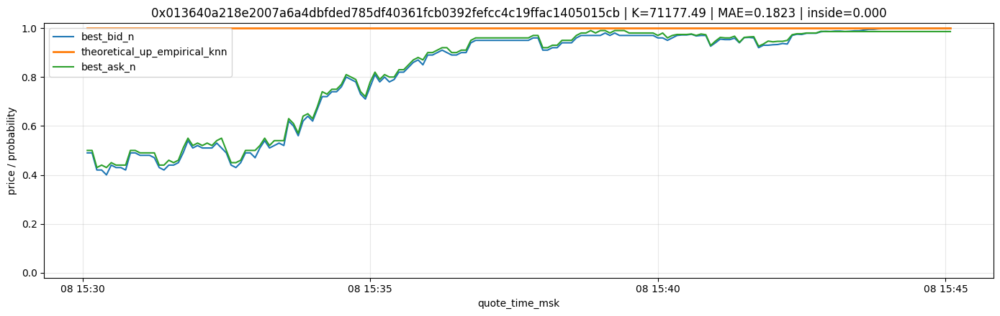

[2/37] 0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e


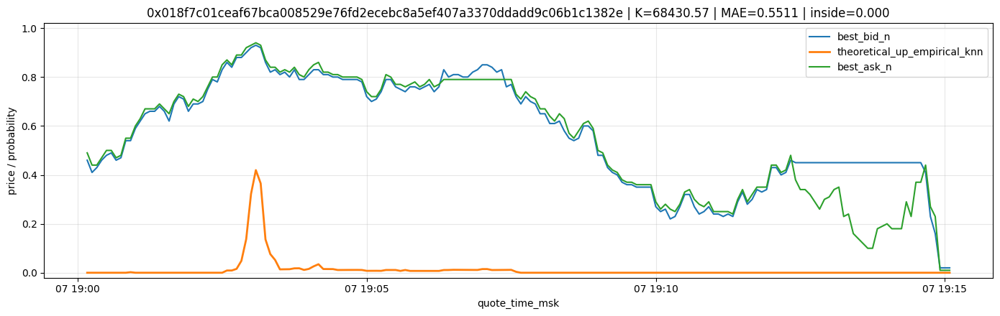

[3/37] 0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
SKIP 0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540: Не удалось собрать train store: мало истории до старта рынка
[4/37] 0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d


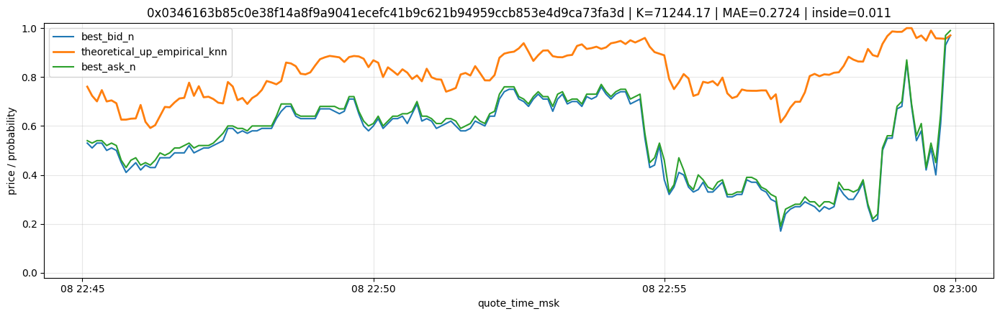

[5/37] 0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852


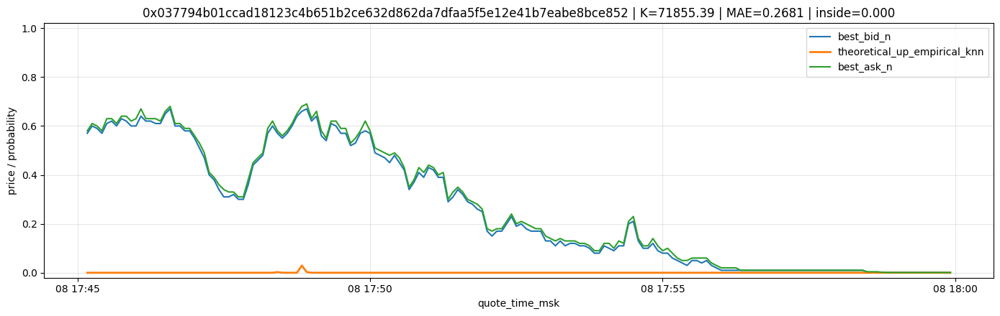

[6/37] 0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80


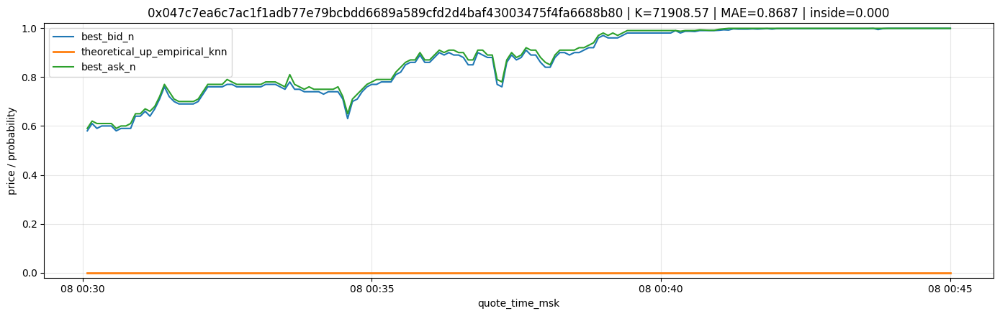

[7/37] 0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec


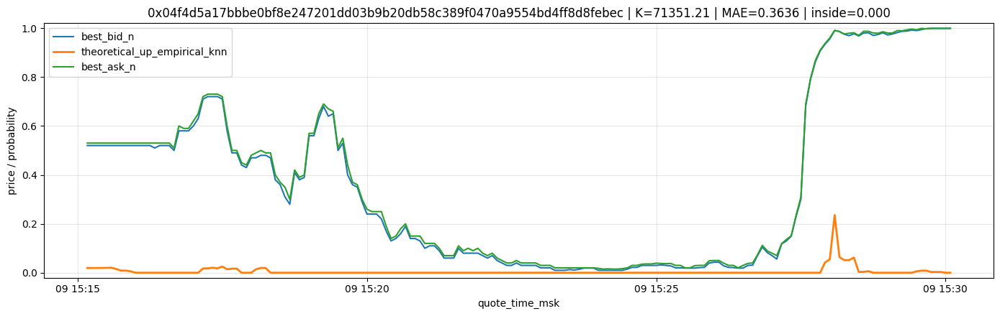

[8/37] 0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c


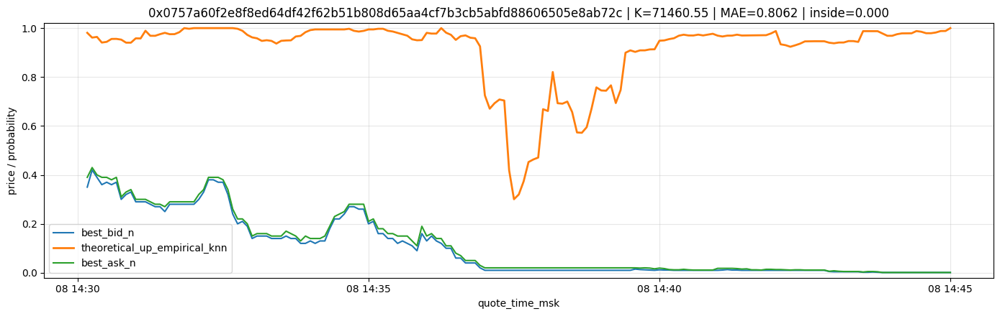

[9/37] 0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405


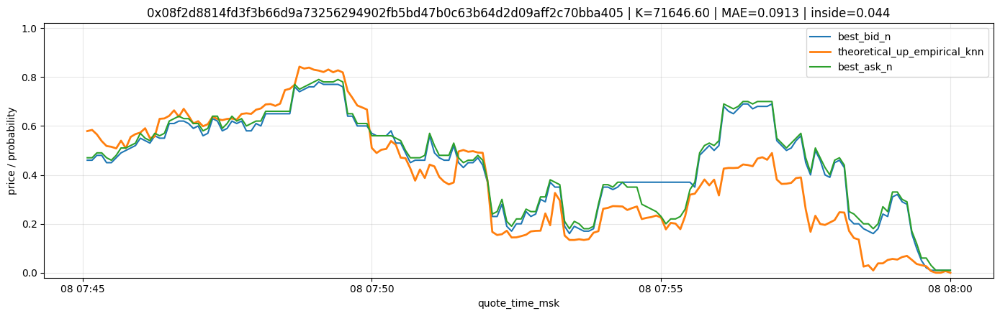

[10/37] 0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1


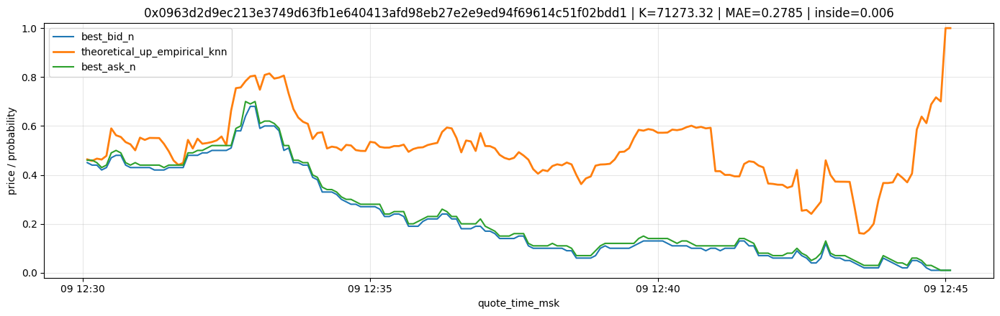

[11/37] 0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81


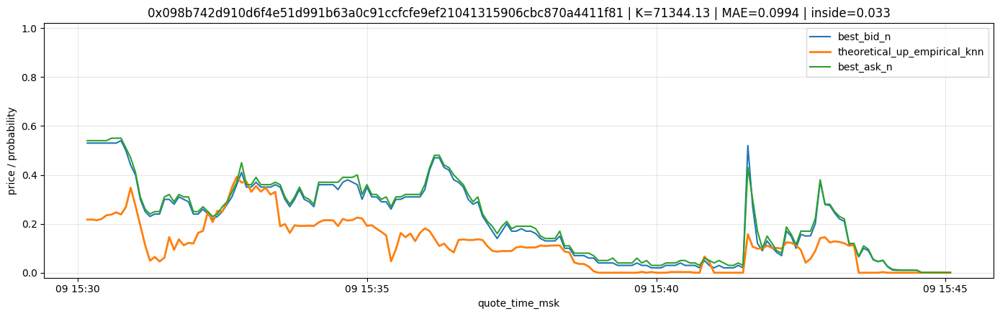

[12/37] 0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e


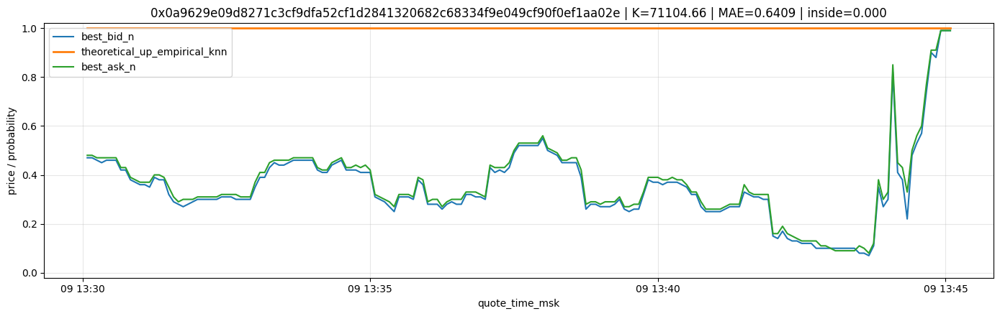

[13/37] 0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f


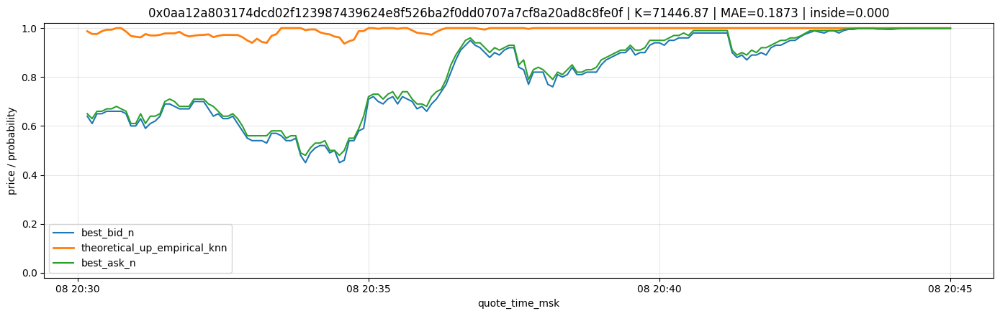

[14/37] 0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216


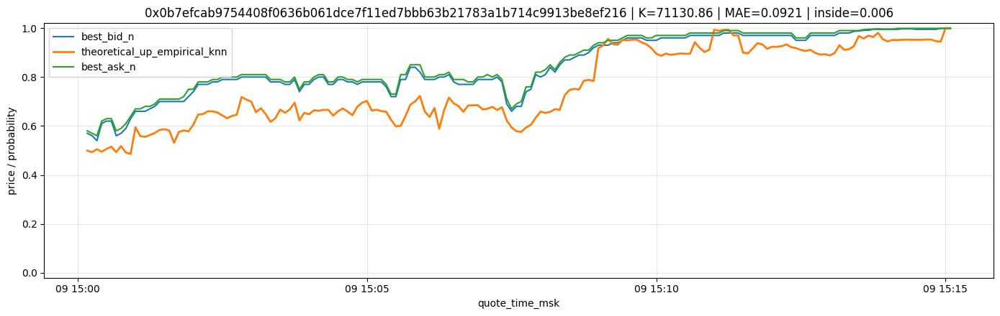

[15/37] 0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f


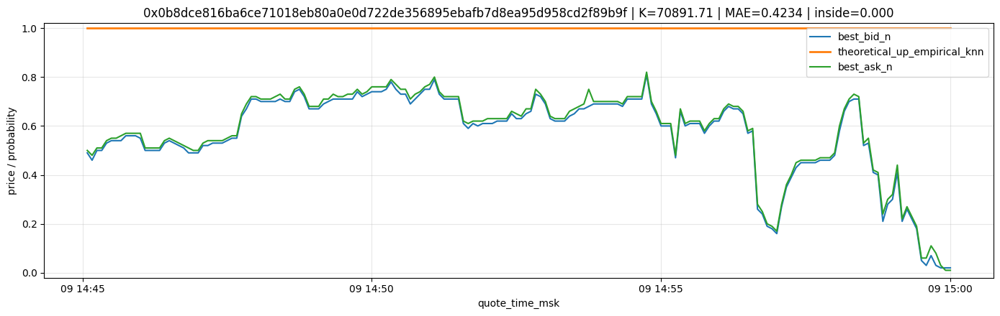

[16/37] 0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524


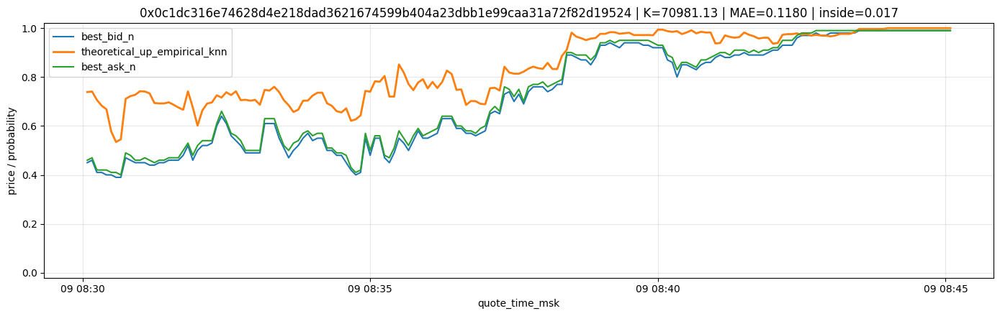

[17/37] 0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d


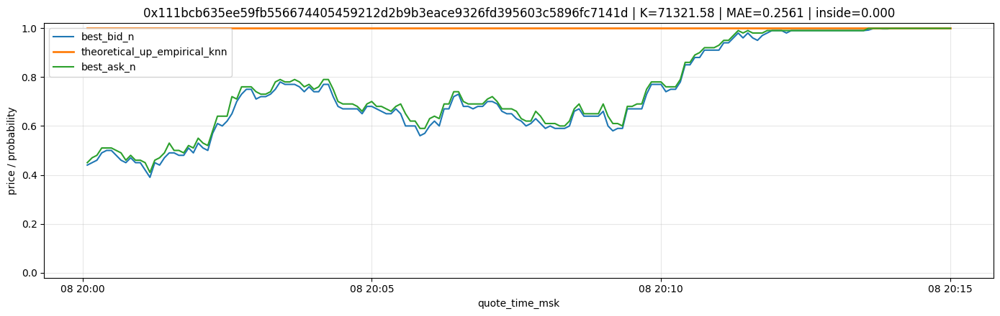

[18/37] 0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f


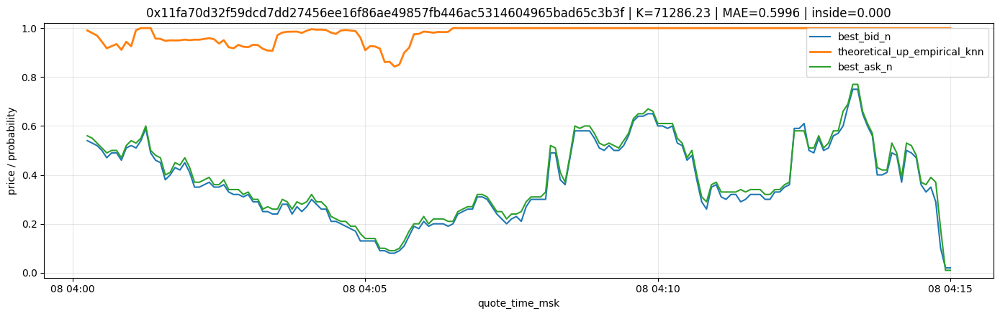

[19/37] 0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826


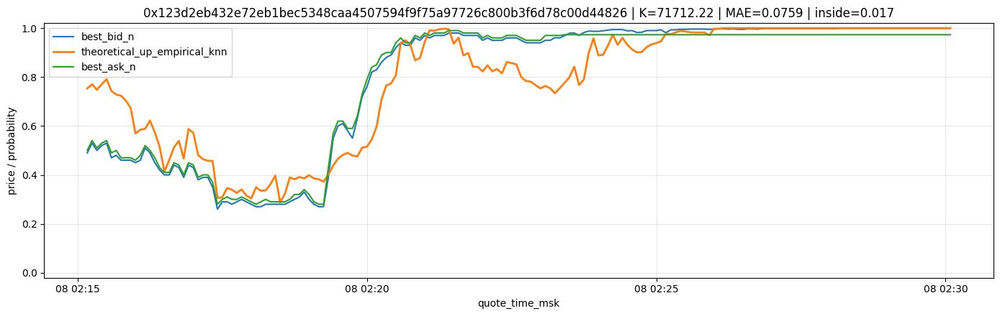

[20/37] 0x1297284c2f0ba30a96cf2f42c5f7c6e04d1cadf69283ae5e182d776bf53fbc07
SKIP 0x1297284c2f0ba30a96cf2f42c5f7c6e04d1cadf69283ae5e182d776bf53fbc07: Не удалось собрать train store: мало истории до старта рынка
[21/37] 0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42


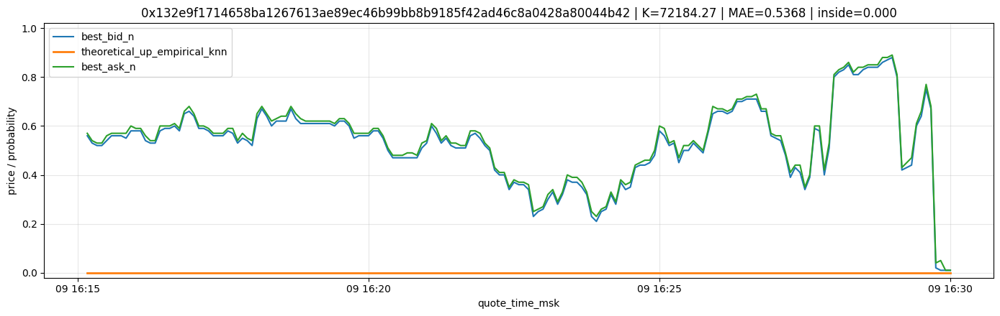

[22/37] 0x1456776819fdbe1973edc8dc49f6a3d16d3a36facfce6990f9278adb7da19a94


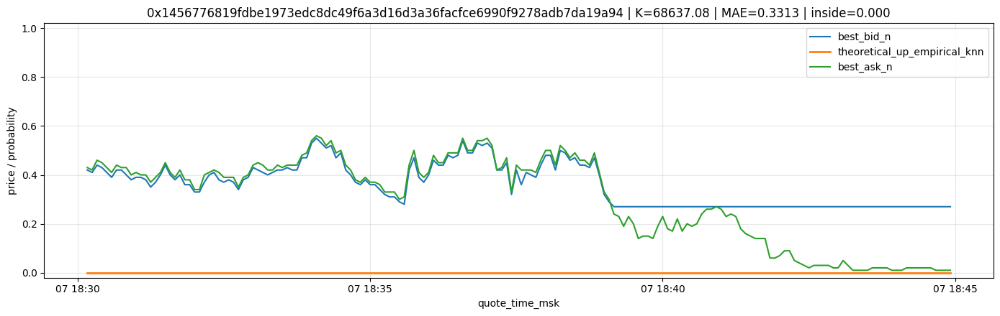

[23/37] 0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33
SKIP 0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33: Не удалось собрать train store: мало истории до старта рынка
[24/37] 0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76


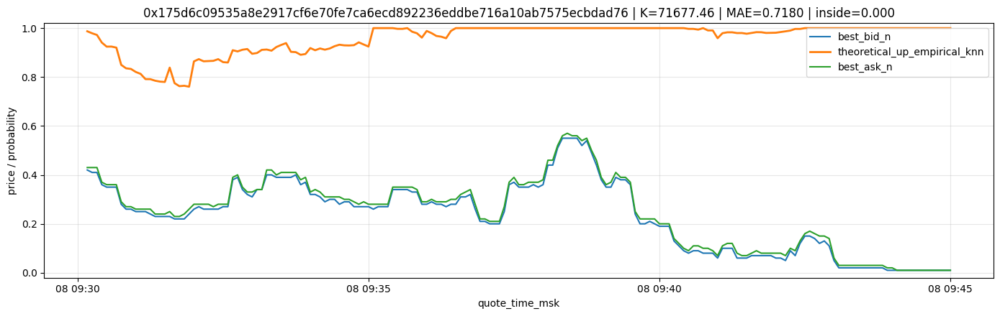

[25/37] 0x18278fbc17717faf47a21c033ddfc55281f976c14f31ae61b4bb4e65794ae1d4


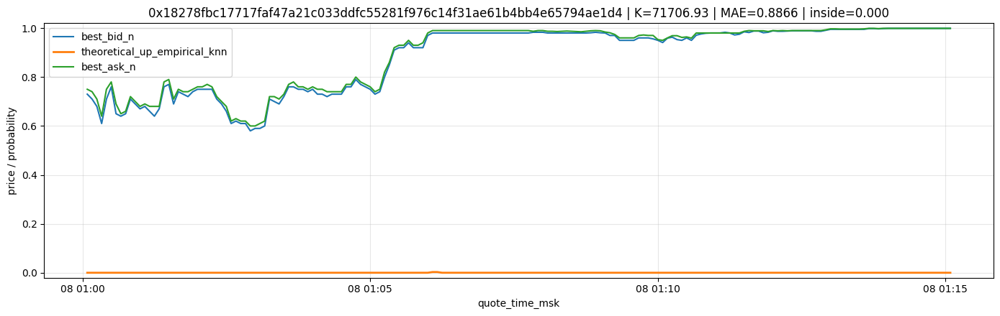

[26/37] 0x18da6797a09676030d2c3506e4a050d9e92c60ff8466114464aeae86c62cad1e


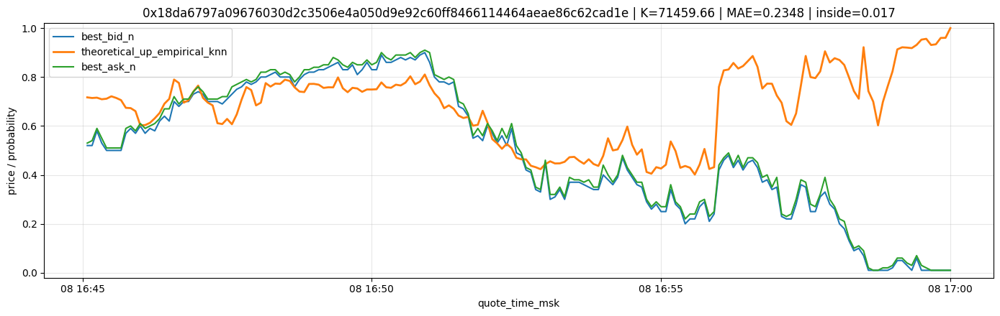

[27/37] 0x194a3ecc437561e79e0154b03313680b2d3976ad2e9b7e5940e8de5c93d58092


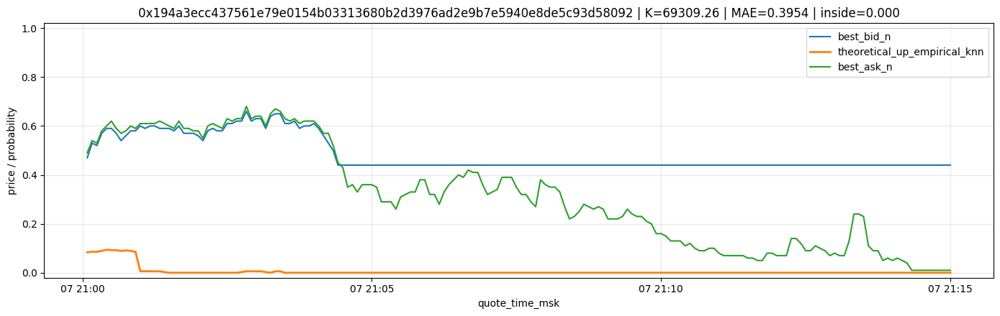

[28/37] 0x19a4f6a6eb797f34df9e1092a763d32b0207cb25c3ffbad9e0b657a1ed20c9b5
SKIP 0x19a4f6a6eb797f34df9e1092a763d32b0207cb25c3ffbad9e0b657a1ed20c9b5: Не удалось собрать train store: мало истории до старта рынка
[29/37] 0x1bf9497cf26ac62d3dfad5c7eb85a79efc716bff43e80763be93b93d73ac73f7


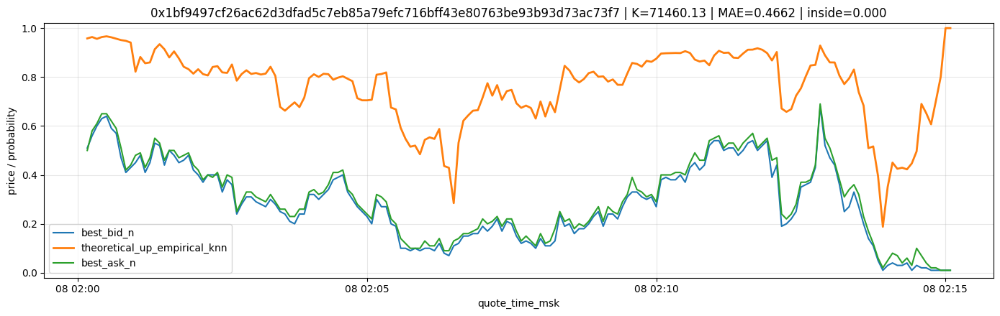

[30/37] 0x1ccd9f2a68e0ea92091d68b1457a715c46d5fc83cb413e735de559a11007e591


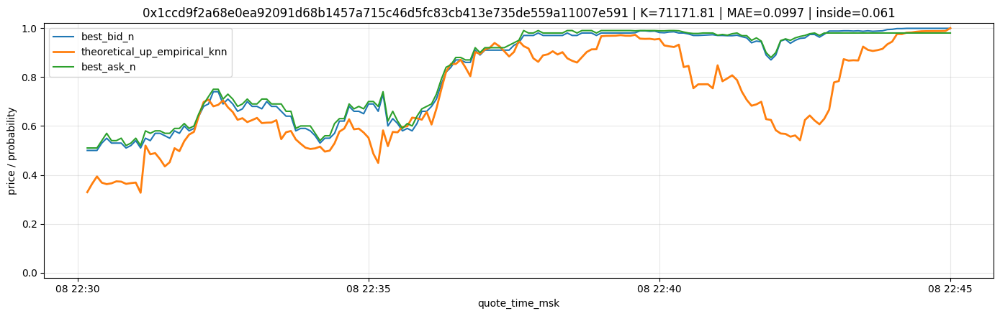

[31/37] 0x1e536a1659c230c0ebbafd838d3cb0c0d5dabc2094a0a6436405ad6dab5067ca


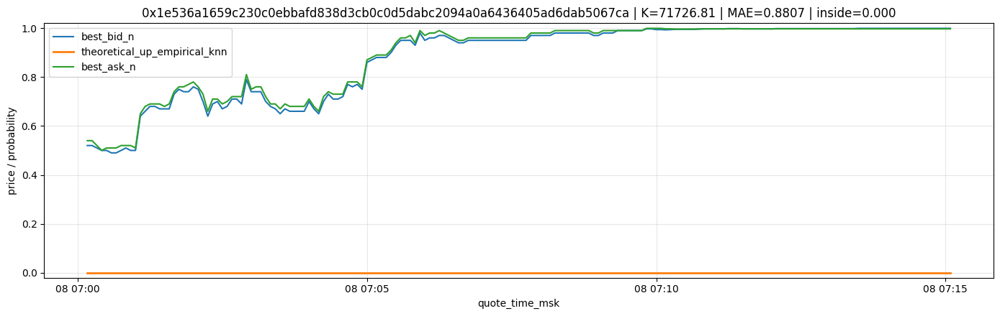

[32/37] 0x1eb9a51ddfb38683a6771d5d26f16e5f513421bd11dbd4f773a812c30651bd4f


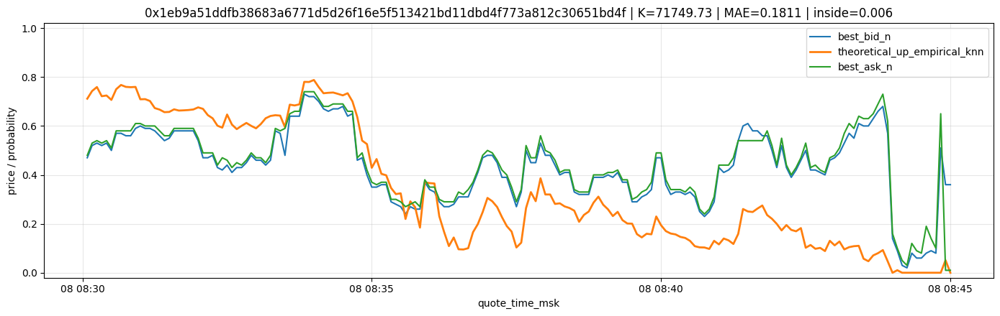

[33/37] 0x1fa863a2ab2975463afa620a45b10440f7a3d3dfb5cd622a40dd87b335a441f7


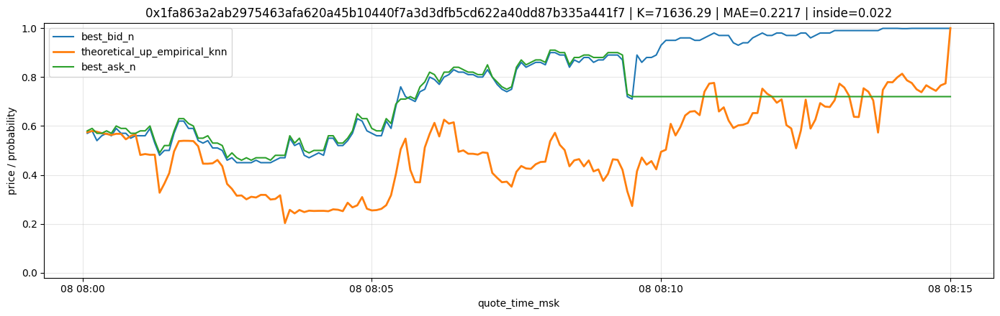

[34/37] 0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6


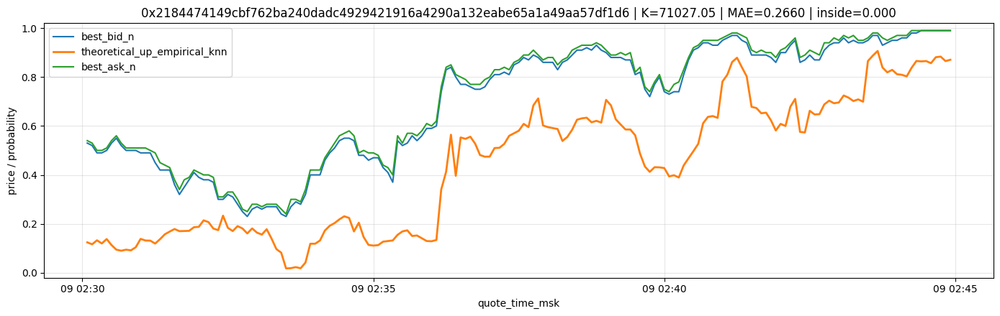

[35/37] 0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9


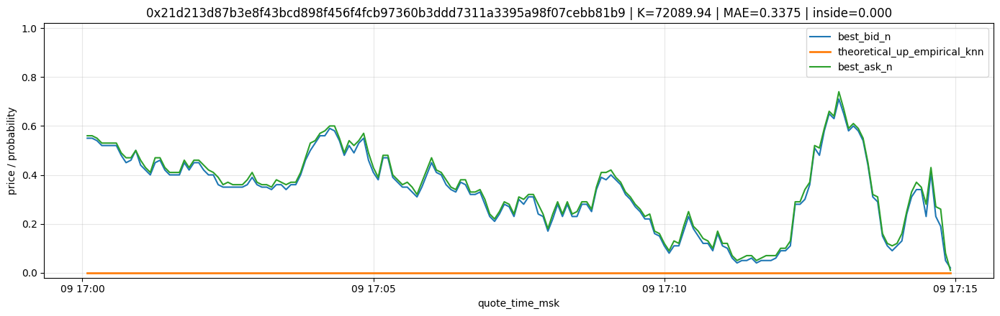

[36/37] 0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70


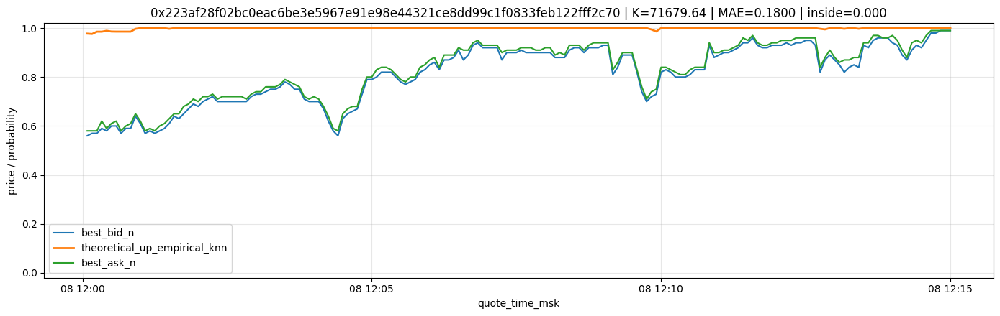

[37/37] 0x24030a34823d17724ac4c0ce726e02f81a9c221b5854eacea51575d5ffe3f839


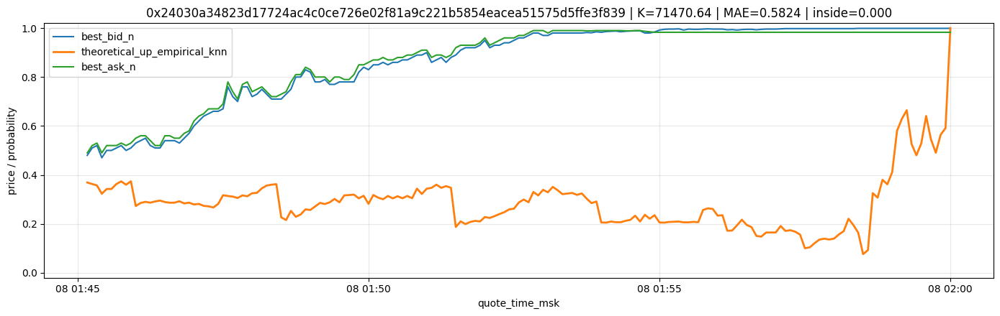

In [37]:
import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# КАКИЕ РЫНКИ РИСУЕМ
# =========================

# Вариант 1: взять markets из твоего текста
market_blob = r"""
0x013640a218e2007a6a4dbfded785df40361fcb0392fefcc4c19ffac1405015cb
0x018f7c01ceaf67bca008529e76fd2ecebc8a5ef407a3370ddadd9c06b1c1382e
0x033f9706c99c1e5fc547cbe26ac5ca18b57b631f48d0af2b4e0cfb67fb1a3540
0x0346163b85c0e38f14a8f9a9041ecefc41b9c621b94959ccb853e4d9ca73fa3d
0x037794b01ccad18123c4b651b2ce632d862da7dfaa5f5e12e41b7eabe8bce852
0x047c7ea6c7ac1f1adb77e79bcbdd6689a589cfd2d4baf43003475f4fa6688b80
0x04f4d5a17bbbe0bf8e247201dd03b9b20db58c389f0470a9554bd4ff8d8febec
0x0757a60f2e8f8ed64df42f62b51b808d65aa4cf7b3cb5abfd88606505e8ab72c
0x08f2d8814fd3f3b66d9a73256294902fb5bd47b0c63b64d2d09aff2c70bba405
0x0963d2d9ec213e3749d63fb1e640413afd98eb27e2e9ed94f69614c51f02bdd1
0x098b742d910d6f4e51d991b63a0c91ccfcfe9ef21041315906cbc870a4411f81
0x0a9629e09d8271c3cf9dfa52cf1d2841320682c68334f9e049cf90f0ef1aa02e
0x0aa12a803174dcd02f123987439624e8f526ba2f0dd0707a7cf8a20ad8c8fe0f
0x0b7efcab9754408f0636b061dce7f11ed7bbb63b21783a1b714c9913be8ef216
0x0b8dce816ba6ce71018eb80a0e0d722de356895ebafb7d8ea95d958cd2f89b9f
0x0c1dc316e74628d4e218dad3621674599b404a23dbb1e99caa31a72f82d19524
0x111bcb635ee59fb556674405459212d2b9b3eace9326fd395603c5896fc7141d
0x11fa70d32f59dcd7dd27456ee16f86ae49857fb446ac5314604965bad65c3b3f
0x123d2eb432e72eb1bec5348caa4507594f9f75a97726c800b3f6d78c00d44826
0x1297284c2f0ba30a96cf2f42c5f7c6e04d1cadf69283ae5e182d776bf53fbc07
0x132e9f1714658ba1267613ae89ec46b99bb8b9185f42ad46c8a0428a80044b42
0x1456776819fdbe1973edc8dc49f6a3d16d3a36facfce6990f9278adb7da19a94
0x14916262e125ae9512ae512f65d7496f98528daf009973411006cafd62660f33
0x175d6c09535a8e2917cf6e70fe7ca6ecd892236eddbe716a10ab7575ecbdad76
0x18278fbc17717faf47a21c033ddfc55281f976c14f31ae61b4bb4e65794ae1d4
0x18da6797a09676030d2c3506e4a050d9e92c60ff8466114464aeae86c62cad1e
0x194a3ecc437561e79e0154b03313680b2d3976ad2e9b7e5940e8de5c93d58092
0x19a4f6a6eb797f34df9e1092a763d32b0207cb25c3ffbad9e0b657a1ed20c9b5
0x1bf9497cf26ac62d3dfad5c7eb85a79efc716bff43e80763be93b93d73ac73f7
0x1ccd9f2a68e0ea92091d68b1457a715c46d5fc83cb413e735de559a11007e591
0x1e536a1659c230c0ebbafd838d3cb0c0d5dabc2094a0a6436405ad6dab5067ca
0x1eb9a51ddfb38683a6771d5d26f16e5f513421bd11dbd4f773a812c30651bd4f
0x1fa863a2ab2975463afa620a45b10440f7a3d3dfb5cd622a40dd87b335a441f7
0x2184474149cbf762ba240dadc4929421916a4290a132eabe65a1a49aa57df1d6
0x21d213d87b3e8f43bcd898f456f4fcb97360b3ddd7311a3395a98f07cebb81b9
0x223af28f02bc0eac6be3e5967e91e98e44321ce8dd99c1f0833feb122fff2c70
0x24030a34823d17724ac4c0ce726e02f81a9c221b5854eacea51575d5ffe3f839
"""
markets_to_plot = re.findall(r"0x[a-fA-F0-9]{64}", market_blob)
markets_to_plot = list(dict.fromkeys(markets_to_plot))

# Вариант 2: взять только успешно посчитанные рынки из CSV
# markets_to_plot = pd.read_csv("empirical_knn_all_markets_results_v3.csv").query("status == 'ok'")["market"].tolist()

plot_limit = None
save_plots = False
save_dir = "empirical_knn_plots_v3"

if plot_limit is not None:
    markets_to_plot = markets_to_plot[:plot_limit]

if save_plots:
    os.makedirs(save_dir, exist_ok=True)

print(f"markets_to_plot: {len(markets_to_plot)}")

# =========================
# ПРОГОН И ГРАФИКИ
# =========================
store_cache = {}

for i, market in enumerate(markets_to_plot, start=1):
    print(f"[{i}/{len(markets_to_plot)}] {market}")

    try:
        df_quotes, asset_id = build_quotes_df(market, min_total_size=min_total_size)

        quote_start = df_quotes["quote_time_msk"].min()
        market_start = quote_start.floor("15min")
        market_end = market_start + pd.Timedelta(minutes=15)

        market_start_ts_ms = int(to_epoch_ms([market_start])[0])
        market_end_ts_ms = int(to_epoch_ms([market_end])[0])

        p2b_ts_ms, price_to_beat, price_to_beat_mode = first_price_to_beat(market_start_ts_ms)

        if market_start_ts_ms not in store_cache:
            store_cache[market_start_ts_ms] = fit_empirical_knn_store(
                df_feat=df_spot_feat,
                train_end_ts_ms=market_start_ts_ms,
                feature_cols=feature_cols,
                horizons_sec=horizons_sec,
                step_sec=step_sec,
                max_train_rows_per_horizon=max_train_rows_per_horizon,
                min_train_rows_per_horizon=min_train_rows_per_horizon,
            )

        knn_store = store_cache[market_start_ts_ms]

        df_eval = pd.merge_asof(
            df_quotes.sort_values("event_ts_ms"),
            df_spot_feat.sort_values("event_ts_ms")[["event_ts_ms", "spot_time_msk", "spot_value"] + feature_cols],
            on="event_ts_ms",
            direction="backward"
        )

        df_eval["price_to_beat"] = price_to_beat
        df_eval["market_end_ts_ms"] = market_end_ts_ms
        df_eval["time_to_expiry_sec"] = ((df_eval["market_end_ts_ms"] - df_eval["event_ts_ms"]) / 1000.0).clip(lower=0.0)

        valid_mask = (
            np.isfinite(df_eval["spot_value"])
            & np.isfinite(df_eval["rv_15m"])
            & (df_eval["rv_15m"] > 0)
        )
        for col in feature_cols:
            valid_mask &= np.isfinite(df_eval[col])

        df_eval["theoretical_up_empirical_knn"] = np.nan
        df_eval.loc[valid_mask, "theoretical_up_empirical_knn"] = df_eval.loc[valid_mask].apply(
            lambda row: predict_knn_probability(row, knn_store, feature_cols, k_neighbors),
            axis=1
        )

        df_eval["mid_n"] = (df_eval["best_bid_n"] + df_eval["best_ask_n"]) / 2.0

        spread_mask = (
            df_eval["best_bid_n"].notna()
            & df_eval["best_ask_n"].notna()
            & df_eval["theoretical_up_empirical_knn"].notna()
        )

        mae = float(
            (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] - df_eval.loc[spread_mask, "mid_n"]).abs().mean()
        ) if spread_mask.any() else np.nan

        inside = float(
            ((df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] >= df_eval.loc[spread_mask, "best_bid_n"]) &
             (df_eval.loc[spread_mask, "theoretical_up_empirical_knn"] <= df_eval.loc[spread_mask, "best_ask_n"])).mean()
        ) if spread_mask.any() else np.nan

        fig, ax = plt.subplots(figsize=(14, 4.5))

        ax.plot(
            df_eval["quote_time_msk"],
            df_eval["best_bid_n"],
            label="best_bid_n",
            linewidth=1.5
        )
        ax.plot(
            df_eval["quote_time_msk"],
            df_eval["theoretical_up_empirical_knn"],
            label="theoretical_up_empirical_knn",
            linewidth=2.0
        )
        ax.plot(
            df_eval["quote_time_msk"],
            df_eval["best_ask_n"],
            label="best_ask_n",
            linewidth=1.5
        )

        ax.set_ylim(-0.02, 1.02)
        ax.set_ylabel("price / probability")
        ax.set_xlabel("quote_time_msk")
        ax.grid(True, alpha=0.3)

        ax.set_title(
            f"{market} | K={price_to_beat:.2f} | "
            f"MAE={mae:.4f} | inside={inside:.3f}"
        )

        ax.legend()
        plt.tight_layout()
        plt.show()

        if save_plots:
            safe_name = market.replace("0x", "")
            fig.savefig(
                os.path.join(save_dir, f"{safe_name}.png"),
                dpi=150,
                bbox_inches="tight"
            )
            plt.close(fig)

    except Exception as e:
        print(f"SKIP {market}: {e}")


In [38]:
sql = f"""
SELECT
    symbol,
    event_time_msk,
    event_ts_ms,
    value,
    full_accuracy_value
FROM {DB}.{SPOT_TABLE}
ORDER BY symbol, event_ts_ms DESC
LIMIT 5 BY symbol
"""
df_last = c.query_df(sql)
display(df_last.sort_values(["symbol", "event_ts_ms"], ascending=[True, False]))


,symbol,event_time_msk,event_ts_ms,value,full_accuracy_value
0,btc/usd,2026-04-10 21:31:11,1775845871000,73009.378074,73009378074201810000000
1,btc/usd,2026-04-10 21:31:10,1775845870000,73009.378074,73009378074201810000000
2,btc/usd,2026-04-10 21:31:09,1775845869000,73008.234173,73008234173156930000000
3,btc/usd,2026-04-10 21:31:08,1775845868000,73005.674550,73005674549532935000000
4,btc/usd,2026-04-10 21:31:07,1775845867000,73001.872813,73001872813414110000000


In [39]:
import os
import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
SPOT_TABLE = os.getenv("SPOT_TABLE", "crypto_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

expected_symbols = ["btc/usd", "eth/usd", "sol/usd", "xrp/usd"]

sql = f"""
SELECT
    symbol,
    count() AS rows_total,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    countIf(event_time_msk >= now() + INTERVAL 3 HOUR - INTERVAL 10 MINUTE) AS rows_last_10m
FROM {DB}.{SPOT_TABLE}
GROUP BY symbol
ORDER BY symbol
"""
df = c.query_df(sql)

display(df)

got = set(df["symbol"].tolist())
missing = sorted(set(expected_symbols) - got)
extra = sorted(got - set(expected_symbols))

print("missing_symbols:", missing)
print("extra_symbols:", extra)


,symbol,rows_total,first_time_msk,last_time_msk,rows_last_10m
0,btc/usd,150,2026-04-10 21:35:27,2026-04-10 21:38:03,150


missing_symbols: ['eth/usd', 'sol/usd', 'xrp/usd']
extra_symbols: []


In [40]:
import os
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
SPOT_TABLE = os.getenv("SPOT_TABLE", "crypto_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

sql = f"""
SELECT
    symbol,
    count() AS rows_total,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    countIf(event_time_msk >= now() + INTERVAL 3 HOUR - INTERVAL 10 MINUTE) AS rows_last_10m,
    dateDiff('second', max(event_time_msk), now() + INTERVAL 3 HOUR) AS lag_sec
FROM {DB}.{SPOT_TABLE}
GROUP BY symbol
ORDER BY symbol
"""

df = c.query_df(sql)
display(df)

expected = {"btc/usd", "eth/usd", "sol/usd", "xrp/usd"}
got = set(df["symbol"].tolist())

print("missing:", sorted(expected - got))
print("extra:", sorted(got - expected))


,symbol,rows_total,first_time_msk,last_time_msk,rows_last_10m,lag_sec
0,btc/usd,1681,2026-04-10 21:35:27,2026-04-10 23:51:35,0,47357
1,xrp/usd,238,2026-04-11 12:56:45,2026-04-11 13:00:42,238,10


missing: ['eth/usd', 'sol/usd']
extra: []


In [41]:
import os
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(".env", override=True)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
SPOT_TABLE = os.getenv("SPOT_TABLE", "crypto_spot")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=DB,
)

sql = f"""
SELECT
    symbol,
    count() AS rows_total,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    countIf(event_time_msk >= now() + INTERVAL 3 HOUR - INTERVAL 10 MINUTE) AS rows_last_10m,
    dateDiff('second', max(event_time_msk), now() + INTERVAL 3 HOUR) AS lag_sec
FROM {DB}.{SPOT_TABLE}
GROUP BY symbol
ORDER BY symbol
"""

df = c.query_df(sql)
display(df)

expected = {"btc/usd", "eth/usd", "sol/usd", "xrp/usd"}
got = set(df["symbol"].tolist())

print("missing:", sorted(expected - got))
print("extra:", sorted(got - expected))


,symbol,rows_total,first_time_msk,last_time_msk,rows_last_10m,lag_sec
0,btc/usd,1681,2026-04-10 21:35:27,2026-04-10 23:51:35,0,47422
1,xrp/usd,238,2026-04-11 12:56:45,2026-04-11 13:00:42,238,75


missing: ['eth/usd', 'sol/usd']
extra: []


In [42]:
sql = f"""
SELECT
    symbol,
    event_time_msk,
    event_ts_ms,
    value
FROM {DB}.{SPOT_TABLE}
ORDER BY event_ts_ms DESC
LIMIT 100
"""
df_last100 = c.query_df(sql)
display(df_last100)
display(df_last100["symbol"].value_counts())


,symbol,event_time_msk,event_ts_ms,value
0,xrp/usd,2026-04-11 13:00:42,1775901642000,1.348015
1,xrp/usd,2026-04-11 13:00:41,1775901641000,1.348015
2,xrp/usd,2026-04-11 13:00:40,1775901640000,1.348005
3,xrp/usd,2026-04-11 13:00:39,1775901639000,1.348000
4,xrp/usd,2026-04-11 13:00:38,1775901638000,1.347995
5,xrp/usd,2026-04-11 13:00:37,1775901637000,1.347985
6,xrp/usd,2026-04-11 13:00:36,1775901636000,1.347980
7,xrp/usd,2026-04-11 13:00:35,1775901635000,1.347965
8,xrp/usd,2026-04-11 13:00:34,1775901634000,1.347965
9,xrp/usd,2026-04-11 13:00:33,1775901633000,1.347970


symbol
xrp/usd    100
Name: count, dtype: Int64

In [43]:
sql = f"""
SELECT
    symbol,
    count() AS rows_total,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    dateDiff('second', max(event_time_msk), now() + INTERVAL 3 HOUR) AS lag_sec
FROM {DB}.{SPOT_TABLE}
WHERE event_time_msk >= now() + INTERVAL 3 HOUR - INTERVAL 30 MINUTE
GROUP BY symbol
ORDER BY symbol
"""
df_30m = c.query_df(sql)
display(df_30m)


,symbol,rows_total,first_time_msk,last_time_msk,lag_sec
0,xrp/usd,238,2026-04-11 12:56:45,2026-04-11 13:00:42,168


In [44]:
sql = f"""
SELECT
    symbol,
    count() AS rows_total,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk
FROM {DB}.{SPOT_TABLE}
WHERE event_time_msk >= '2026-04-11 13:00:00'
GROUP BY symbol
ORDER BY symbol
"""
df_after_restart = c.query_df(sql)
display(df_after_restart)


,symbol,rows_total,first_time_msk,last_time_msk
0,xrp/usd,43,2026-04-11 13:00:00,2026-04-11 13:00:42


In [ ]:
sql = f"""
SELECT
    symbol,
    count() AS rows_total,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    countIf(event_time_msk >= now() + INTERVAL 3 HOUR - INTERVAL 10 MINUTE) AS rows_last_10m,
    dateDiff('second', max(event_time_msk), now() + INTERVAL 3 HOUR) AS lag_sec
FROM {DB}.{SPOT_TABLE}
GROUP BY symbol
ORDER BY symbol
"""

df = c.query_df(sql)
display(df)

expected = {"btc/usd", "eth/usd", "sol/usd", "xrp/usd"}
got = set(df["symbol"].tolist())

print("missing:", sorted(expected - got))
print("extra:", sorted(got - expected))


,symbol,rows_total,first_time_msk,last_time_msk,rows_last_10m,lag_sec
0,btc/usd,2648,2026-04-10 21:35:27,2026-04-11 13:35:16,591,9
1,eth/usd,967,2026-04-11 13:18:27,2026-04-11 13:35:16,591,9
2,sol/usd,967,2026-04-11 13:18:27,2026-04-11 13:35:16,591,9
3,xrp/usd,1205,2026-04-11 12:56:45,2026-04-11 13:35:16,591,9


missing: []
extra: []


In [46]:
import os
import sys
import time
import importlib
from pathlib import Path

import pandas as pd
import clickhouse_connect
from dotenv import load_dotenv
from IPython.display import display

# =========================
# BIG INGEST HEALTH CHECK
# =========================

PROJECT_DIR = Path("/Users/roman230901gmail.com/Desktop/project")
sys.path.insert(0, str(PROJECT_DIR))

load_dotenv(PROJECT_DIR / ".env", override=False)

DB = os.getenv("CLICKHOUSE_DB", "polyk")
ORDERBOOK_TABLE = os.getenv("ORDERBOOK_TABLE", "orderbook")
PRICECHANGE_TABLE = os.getenv("PRICECHANGE_TABLE", "pricechange")
SPOT_TABLE = os.getenv("SPOT_TABLE", "crypto_spot")
HEARTBEAT_TABLE = os.getenv("INGEST_HEARTBEAT_TABLE", "ingest_heartbeat")
SERVICE_LOG_TABLE = os.getenv("INGEST_SERVICE_LOG_TABLE", "ingest_service_log")
INGEST_SERVICE_NAME = os.getenv("INGEST_SERVICE_NAME", "ws_ingest")

EXPECTED_SPOT_SYMBOLS = [
    x.strip().lower()
    for x in os.getenv("SPOT_SYMBOLS", os.getenv("SPOT_SYMBOL", "btc/usd")).split(",")
    if x.strip()
]

EXPECTED_POLY_SYMBOLS = [
    x.strip().upper()
    for x in os.getenv("POLY_SYMBOLS", "BTC,ETH,SOL,XRP").split(",")
    if x.strip()
]

NOW_MS = int(time.time() * 1000)

SPOT_LAG_WARN_SEC = 120
PRICECHANGE_LAG_WARN_SEC = 120
HEARTBEAT_WARN_SEC = 60
SPOT_WINDOW_MIN = 10
PRICECHANGE_WINDOW_MIN = 10
ORDERBOOK_WINDOW_MIN = 60

checks = []


def q(v: str) -> str:
    return "'" + str(v).replace("'", "''") + "'"


def section(title: str):
    print("\n" + "=" * 110)
    print(title)
    print("=" * 110)


def add_check(name: str, status: str, details: str = ""):
    checks.append({"check": name, "status": status, "details": details})


def query_df(sql: str, check_name: str | None = None) -> pd.DataFrame:
    try:
        return c.query_df(sql)
    except Exception as e:
        if check_name:
            add_check(check_name, "FAIL", repr(e))
        print(f"[QUERY ERROR] {check_name or ''}: {repr(e)}")
        return pd.DataFrame()


def table_exists(table: str) -> bool:
    try:
        return int(c.command(f"EXISTS TABLE {DB}.{table}")) == 1
    except Exception:
        return False


def status_by_lag(rows: int, lag_sec, warn_sec: int) -> str:
    if rows <= 0:
        return "FAIL"
    if lag_sec is None or pd.isna(lag_sec):
        return "WARN"
    if float(lag_sec) > warn_sec:
        return "WARN"
    return "OK"


# =========================
# 0) CONFIG + CLICKHOUSE
# =========================

section("0) CONFIG + CLICKHOUSE")

config_df = pd.DataFrame([{
    "DB": DB,
    "ORDERBOOK_TABLE": ORDERBOOK_TABLE,
    "PRICECHANGE_TABLE": PRICECHANGE_TABLE,
    "SPOT_TABLE": SPOT_TABLE,
    "HEARTBEAT_TABLE": HEARTBEAT_TABLE,
    "SERVICE_LOG_TABLE": SERVICE_LOG_TABLE,
    "EXPECTED_SPOT_SYMBOLS": ",".join(EXPECTED_SPOT_SYMBOLS),
    "EXPECTED_POLY_SYMBOLS": ",".join(EXPECTED_POLY_SYMBOLS),
    "POLY_TIMEFRAMES": os.getenv("POLY_TIMEFRAMES", ""),
    "POLY_TRACK_CURRENT_ONLY": os.getenv("POLY_TRACK_CURRENT_ONLY", ""),
    "POLY_MAX_MATCHED_MARKETS": os.getenv("POLY_MAX_MATCHED_MARKETS", ""),
    "POLY_DEBUG_MARKETS": os.getenv("POLY_DEBUG_MARKETS", ""),
}])
display(config_df)

try:
    c = clickhouse_connect.get_client(
        host=os.getenv("CLICKHOUSE_HOST"),
        port=int(os.getenv("CLICKHOUSE_PORT", "8123")),
        username=os.getenv("CLICKHOUSE_USER"),
        password=os.getenv("CLICKHOUSE_PASSWORD"),
        database=DB,
    )
    ch_info = c.query_df("SELECT version() AS version, timezone() AS timezone, now() AS server_now")
    display(ch_info)
    add_check("ClickHouse connection", "OK", "connected")
except Exception as e:
    raise RuntimeError(f"ClickHouse connection failed: {repr(e)}")

tables_df = pd.DataFrame([
    {"table": SPOT_TABLE, "exists": table_exists(SPOT_TABLE)},
    {"table": ORDERBOOK_TABLE, "exists": table_exists(ORDERBOOK_TABLE)},
    {"table": PRICECHANGE_TABLE, "exists": table_exists(PRICECHANGE_TABLE)},
    {"table": HEARTBEAT_TABLE, "exists": table_exists(HEARTBEAT_TABLE)},
    {"table": SERVICE_LOG_TABLE, "exists": table_exists(SERVICE_LOG_TABLE)},
])
display(tables_df)

missing_tables = tables_df.loc[~tables_df["exists"], "table"].tolist()
add_check(
    "Required tables exist",
    "OK" if not missing_tables else "FAIL",
    "missing=" + ",".join(missing_tables) if missing_tables else "all required tables exist"
)


# =========================
# 1) SPOT INGEST HEALTH
# =========================

section("1) SPOT INGEST HEALTH")

spot_symbols_sql = ",".join(q(s) for s in EXPECTED_SPOT_SYMBOLS)
spot_cutoff_ms = NOW_MS - SPOT_WINDOW_MIN * 60_000

df_spot = query_df(f"""
SELECT
    symbol,
    count() AS rows_total,
    min(event_time_msk) AS first_time_msk,
    max(event_time_msk) AS last_time_msk,
    countIf(event_ts_ms >= {spot_cutoff_ms}) AS rows_last_{SPOT_WINDOW_MIN}m,
    intDiv({NOW_MS} - max(event_ts_ms), 1000) AS lag_sec,
    argMax(value, event_ts_ms) AS last_value
FROM {DB}.{SPOT_TABLE}
WHERE symbol IN ({spot_symbols_sql})
GROUP BY symbol
ORDER BY symbol
""", "spot health query")

display(df_spot)

df_spot_recent_symbols = query_df(f"""
SELECT DISTINCT symbol
FROM {DB}.{SPOT_TABLE}
WHERE event_ts_ms >= {NOW_MS - 30 * 60_000}
ORDER BY symbol
""", "spot recent symbols query")

got_recent = set(df_spot.loc[df_spot[f"rows_last_{SPOT_WINDOW_MIN}m"] > 0, "symbol"].astype(str))
missing_spot = sorted(set(EXPECTED_SPOT_SYMBOLS) - got_recent)
extra_spot = sorted(set(df_spot_recent_symbols.get("symbol", pd.Series(dtype=str)).astype(str)) - set(EXPECTED_SPOT_SYMBOLS))

if df_spot.empty:
    add_check("Spot ingest", "FAIL", "no rows for expected symbols")
else:
    max_spot_lag = float(df_spot["lag_sec"].max())
    if missing_spot:
        add_check("Spot ingest", "FAIL", f"missing recent symbols={missing_spot}")
    elif max_spot_lag > SPOT_LAG_WARN_SEC:
        add_check("Spot ingest", "WARN", f"max lag_sec={max_spot_lag:.0f}")
    else:
        add_check("Spot ingest", "OK", f"all expected symbols active; max lag_sec={max_spot_lag:.0f}")

add_check(
    "Spot extra symbols",
    "OK" if not extra_spot else "WARN",
    f"extra={extra_spot}"
)

print("missing_spot:", missing_spot)
print("extra_spot:", extra_spot)


# =========================
# 2) GAMMA MARKET DISCOVERY
# =========================

section("2) GAMMA MARKET DISCOVERY")

gamma_ok = False
markets = []
asset_ids = []
outcome_map = {}
market_symbol_map = {}

try:
    import ws_ingest
    importlib.reload(ws_ingest)

    markets = ws_ingest.fetch_filtered_markets()
    asset_ids, outcome_map = ws_ingest.build_outcome_map(markets)
    dbg = ws_ingest._market_selection_debug(markets, limit=16)

    market_symbol_map = {
        str(ws_ingest._extract_market_id(m)).lower(): sorted(ws_ingest._infer_market_symbols(m))
        for m in markets
        if ws_ingest._extract_market_id(m)
    }

    gamma_summary = pd.DataFrame([{
        "matched_markets": len(markets),
        "subscribed_assets": len(asset_ids),
        "up_assets": sum(1 for v in outcome_map.values() if str(v).upper() == "UP"),
        "down_assets": sum(1 for v in outcome_map.values() if str(v).upper() == "DOWN"),
        "symbol_counts": dbg["symbol_counts"],
    }])
    display(gamma_summary)
    display(pd.DataFrame(dbg["samples"]))

    missing_gamma_symbols = sorted(set(EXPECTED_POLY_SYMBOLS) - set(dbg["symbol_counts"].keys()))
    zero_gamma_symbols = [
        s for s in EXPECTED_POLY_SYMBOLS
        if int(dbg["symbol_counts"].get(s, 0)) <= 0
    ]

    if not markets:
        add_check("Gamma market discovery", "FAIL", "matched_markets=0")
    elif missing_gamma_symbols or zero_gamma_symbols:
        add_check(
            "Gamma market discovery",
            "FAIL",
            f"missing={missing_gamma_symbols}; zero={zero_gamma_symbols}; counts={dbg['symbol_counts']}"
        )
    else:
        add_check(
            "Gamma market discovery",
            "OK",
            f"matched_markets={len(markets)}; assets={len(asset_ids)}; counts={dbg['symbol_counts']}"
        )
        gamma_ok = True

except Exception as e:
    add_check("Gamma market discovery", "FAIL", repr(e))
    print("[GAMMA ERROR]", repr(e))


# =========================
# 3) ORDERBOOK / PRICECHANGE DB ACTIVITY
# =========================

section("3) ORDERBOOK / PRICECHANGE DB ACTIVITY")

def activity_summary(table: str, window_min: int) -> pd.DataFrame:
    cutoff = NOW_MS - window_min * 60_000
    return query_df(f"""
    SELECT
        {q(table)} AS table_name,
        {window_min} AS window_min,
        count() AS rows,
        countDistinct(market) AS markets,
        countDistinct(asset_id) AS assets,
        min(event_time_msk) AS first_time_msk,
        max(event_time_msk) AS last_time_msk,
        if(count() = 0, NULL, intDiv({NOW_MS} - max(event_ts_ms), 1000)) AS lag_sec
    FROM {DB}.{table}
    WHERE event_ts_ms >= {cutoff}
    """, f"{table} activity summary")


df_ob_activity = activity_summary(ORDERBOOK_TABLE, ORDERBOOK_WINDOW_MIN)
df_pc_activity = activity_summary(PRICECHANGE_TABLE, PRICECHANGE_WINDOW_MIN)
df_activity = pd.concat([df_ob_activity, df_pc_activity], ignore_index=True)
display(df_activity)

if not df_ob_activity.empty:
    ob_rows = int(df_ob_activity.loc[0, "rows"])
    ob_lag = df_ob_activity.loc[0, "lag_sec"]
    ob_status = status_by_lag(ob_rows, ob_lag, 20 * 60)
    add_check(
        "Orderbook recent activity",
        ob_status,
        f"rows={ob_rows}; markets={int(df_ob_activity.loc[0, 'markets'])}; assets={int(df_ob_activity.loc[0, 'assets'])}; lag_sec={ob_lag}"
    )

if not df_pc_activity.empty:
    pc_rows = int(df_pc_activity.loc[0, "rows"])
    pc_lag = df_pc_activity.loc[0, "lag_sec"]
    pc_status = status_by_lag(pc_rows, pc_lag, PRICECHANGE_LAG_WARN_SEC)
    add_check(
        "Pricechange recent activity",
        pc_status,
        f"rows={pc_rows}; markets={int(df_pc_activity.loc[0, 'markets'])}; assets={int(df_pc_activity.loc[0, 'assets'])}; lag_sec={pc_lag}"
    )


def recent_markets(table: str, window_min: int, limit: int = 30) -> pd.DataFrame:
    cutoff = NOW_MS - window_min * 60_000
    df = query_df(f"""
    SELECT
        market,
        count() AS rows,
        countDistinct(asset_id) AS assets,
        min(event_time_msk) AS first_time_msk,
        max(event_time_msk) AS last_time_msk,
        intDiv({NOW_MS} - max(event_ts_ms), 1000) AS lag_sec
    FROM {DB}.{table}
    WHERE event_ts_ms >= {cutoff}
    GROUP BY market
    ORDER BY max(event_ts_ms) DESC
    LIMIT {limit}
    """, f"{table} recent markets")
    if not df.empty:
        df["symbol_guess"] = df["market"].astype(str).str.lower().map(
            lambda x: ",".join(market_symbol_map.get(x, [])) if market_symbol_map else "?"
        )
    return df


print(f"\nRecent orderbook markets, last {ORDERBOOK_WINDOW_MIN}m:")
df_recent_ob = recent_markets(ORDERBOOK_TABLE, ORDERBOOK_WINDOW_MIN)
display(df_recent_ob)

print(f"\nRecent pricechange markets, last {PRICECHANGE_WINDOW_MIN}m:")
df_recent_pc = recent_markets(PRICECHANGE_TABLE, PRICECHANGE_WINDOW_MIN)
display(df_recent_pc)


# =========================
# 4) PRICECHANGE HAS SNAPSHOT CHECK
# =========================

section("4) PRICECHANGE HAS ORDERBOOK SNAPSHOT CHECK")

pc_assets_recent = query_df(f"""
SELECT DISTINCT asset_id, market
FROM {DB}.{PRICECHANGE_TABLE}
WHERE event_ts_ms >= {NOW_MS - PRICECHANGE_WINDOW_MIN * 60_000}
""", "recent pricechange assets")

ob_assets_all = query_df(f"""
SELECT DISTINCT asset_id
FROM {DB}.{ORDERBOOK_TABLE}
""", "all orderbook assets")

if pc_assets_recent.empty:
    add_check("Pricechange snapshot consistency", "WARN", "no recent pricechange assets to check")
else:
    missing_snapshot_assets = sorted(
        set(pc_assets_recent["asset_id"].astype(str))
        - set(ob_assets_all.get("asset_id", pd.Series(dtype=str)).astype(str))
    )
    add_check(
        "Pricechange snapshot consistency",
        "OK" if not missing_snapshot_assets else "FAIL",
        f"pricechange assets without any orderbook snapshot={len(missing_snapshot_assets)}"
    )
    if missing_snapshot_assets:
        display(pc_assets_recent[pc_assets_recent["asset_id"].astype(str).isin(missing_snapshot_assets)].head(20))


# =========================
# 5) HEARTBEAT + SERVICE LOG
# =========================

section("5) HEARTBEAT + SERVICE LOG")

if table_exists(HEARTBEAT_TABLE):
    df_hb = query_df(f"""
    SELECT
        ts,
        service,
        status,
        tracked_markets,
        subscribed_assets,
        last_ws_msg_time_msk,
        last_event_ts_ms,
        intDiv(lag_ms, 1000) AS ingest_lag_sec,
        orderbook_buffer_len,
        pricechange_buffer_len,
        last_error,
        dateDiff('second', ts, now() + INTERVAL 3 HOUR) AS heartbeat_age_sec
    FROM {DB}.{HEARTBEAT_TABLE}
    WHERE service = {q(INGEST_SERVICE_NAME)}
    ORDER BY ts DESC
    LIMIT 10
    """, "heartbeat query")
    display(df_hb)

    if df_hb.empty:
        add_check("ws_ingest heartbeat", "WARN", "no heartbeat rows")
    else:
        age = float(df_hb.loc[0, "heartbeat_age_sec"])
        status = str(df_hb.loc[0, "status"])
        subscribed_assets = int(df_hb.loc[0, "subscribed_assets"])
        tracked_markets = int(df_hb.loc[0, "tracked_markets"])
        last_error = str(df_hb.loc[0, "last_error"] or "")

        if age > HEARTBEAT_WARN_SEC:
            add_check("ws_ingest heartbeat", "WARN", f"heartbeat_age_sec={age:.0f}; service may be stopped")
        elif last_error:
            add_check("ws_ingest heartbeat", "WARN", f"last_error={last_error}")
        elif subscribed_assets <= 0 or tracked_markets <= 0:
            add_check("ws_ingest heartbeat", "WARN", f"status={status}; tracked_markets={tracked_markets}; subscribed_assets={subscribed_assets}")
        else:
            add_check("ws_ingest heartbeat", "OK", f"status={status}; tracked_markets={tracked_markets}; subscribed_assets={subscribed_assets}; age={age:.0f}s")
else:
    add_check("ws_ingest heartbeat", "WARN", f"table {HEARTBEAT_TABLE} does not exist")


if table_exists(SERVICE_LOG_TABLE):
    df_log = query_df(f"""
    SELECT
        ts,
        service,
        level,
        event,
        status,
        market,
        asset_id,
        details,
        error_text
    FROM {DB}.{SERVICE_LOG_TABLE}
    WHERE service = {q(INGEST_SERVICE_NAME)}
    ORDER BY ts DESC
    LIMIT 30
    """, "service log query")
    display(df_log)

    recent_errors = df_log[df_log["level"].astype(str).str.upper().isin(["ERROR", "CRITICAL"])] if not df_log.empty else pd.DataFrame()
    add_check(
        "ws_ingest service log errors",
        "OK" if recent_errors.empty else "WARN",
        f"recent error rows={len(recent_errors)}"
    )
else:
    add_check("ws_ingest service log", "WARN", f"table {SERVICE_LOG_TABLE} does not exist")


# =========================
# 6) FINAL VERDICT
# =========================

section("6) FINAL VERDICT")

df_checks = pd.DataFrame(checks)
status_order = {"FAIL": 0, "WARN": 1, "OK": 2}
df_checks["rank"] = df_checks["status"].map(status_order).fillna(1)
df_checks = df_checks.sort_values(["rank", "check"]).drop(columns=["rank"]).reset_index(drop=True)

display(df_checks)

if (df_checks["status"] == "FAIL").any():
    verdict = "FAIL"
elif (df_checks["status"] == "WARN").any():
    verdict = "WARN"
else:
    verdict = "OK"

print("\nVERDICT:", verdict)

if verdict == "OK":
    print("Все основные части пайплайна выглядят живыми: spot, Gamma discovery, orderbook, pricechange, heartbeat/logs.")
elif verdict == "WARN":
    print("Пайплайн частично живой, но есть предупреждения. Обычно это lag, остановленный ws_ingest или мало свежих orderbook snapshots.")
else:
    print("Есть критичная проблема. Смотри строки FAIL выше: чаще всего это не запущенный ingest, нет сети до Gamma/ClickHouse или не те env-переменные.")

print("\nExpected behavior:")
print("- spot_ingest должен давать свежие строки по btc/usd, eth/usd, sol/usd, xrp/usd.")
print("- ws_ingest должен находить сотни 15m рынков Gamma по BTC/ETH/SOL/XRP.")
print("- orderbook пишет snapshots постепенно, обычно не все рынки появляются мгновенно.")
print("- pricechange должен быть свежим, если ws_ingest сейчас запущен.")
print("- текущая версия ws_ingest сохраняет UP-side orderbook/pricechange, потому что модель дальше оценивает UP probability.")




0) CONFIG + CLICKHOUSE


,DB,ORDERBOOK_TABLE,PRICECHANGE_TABLE,SPOT_TABLE,HEARTBEAT_TABLE,SERVICE_LOG_TABLE,EXPECTED_SPOT_SYMBOLS,EXPECTED_POLY_SYMBOLS,POLY_TIMEFRAMES,POLY_TRACK_CURRENT_ONLY,POLY_MAX_MATCHED_MARKETS,POLY_DEBUG_MARKETS
0,polyk,orderbook,pricechange,crypto_spot,ingest_heartbeat,ingest_service_log,"btc/usd,eth/usd,sol/usd,xrp/usd","BTC,ETH,SOL,XRP",15m,false,0,true


,version,timezone,server_now
0,18.16.1,Etc/UTC,2026-04-11 11:18:16


,table,exists
0,crypto_spot,True
1,orderbook,True
2,pricechange,True
3,ingest_heartbeat,True
4,ingest_service_log,True



1) SPOT INGEST HEALTH


,symbol,rows_total,first_time_msk,last_time_msk,rows_last_10m,lag_sec,last_value
0,btc/usd,2648,2026-04-10 21:35:27,2026-04-11 13:35:16,0,2580,72893.280000
1,eth/usd,967,2026-04-11 13:18:27,2026-04-11 13:35:16,0,2580,2242.304320
2,sol/usd,967,2026-04-11 13:18:27,2026-04-11 13:35:16,0,2580,84.306485
3,xrp/usd,1205,2026-04-11 12:56:45,2026-04-11 13:35:16,0,2580,1.347989


missing_spot: ['btc/usd', 'eth/usd', 'sol/usd', 'xrp/usd']
extra_spot: []

2) GAMMA MARKET DISCOVERY


,matched_markets,subscribed_assets,up_assets,down_assets,symbol_counts
0,386,766,383,383,"{'BTC': 96, 'ETH': 97, 'SOL': 96, 'XRP': 97}"


,symbols,label
0,[SOL],id=0x2b2dd64624e3afc54aadbed3e67cf565c66b60d43d484c0343af7c246054980c slug=sol-updown-15m-1775906100 end_utc=2026-04-11T11:30:00+00:00
1,[XRP],id=0x8c4cdeabd31b4f38efd7f0fe673471024a96e8d23c6c9838cde98927ffdbe60f slug=xrp-updown-15m-1775906100 end_utc=2026-04-11T11:30:00+00:00
2,[ETH],id=0xa53e0fc0c679305aa9cfbf5a8d910f4996c029bc3f6585dea129222ea1d07cd7 slug=eth-updown-15m-1775906100 end_utc=2026-04-11T11:30:00+00:00
3,[BTC],id=0x3ce7e6c21bf6c1bc47c3d8f825af84049d79fa68e639d007606564316eff1fdd slug=btc-updown-15m-1775906100 end_utc=2026-04-11T11:30:00+00:00
4,[ETH],id=0x9ce52de7c6194c3ec6a7997e2c93cf42b50ed3436c4a8a6ae589533b6c669d70 slug=eth-updown-15m-1775907000 end_utc=2026-04-11T11:45:00+00:00
5,[SOL],id=0x479faa237c52d6389d3b00f7df6586b076e372f381bffec53c283e1ec7bbcea4 slug=sol-updown-15m-1775907000 end_utc=2026-04-11T11:45:00+00:00
6,[BTC],id=0x2f38f81f15adf089da79f0dc18cfb059e3bb1dc1e5ed1e7a5efc2352fad38e6b slug=btc-updown-15m-1775907000 end_utc=2026-04-11T11:45:00+00:00
7,[XRP],id=0x9bf5f281a298ad4c6fb30cc83ae15c8009a1d9b26640c4cc32ff5d0d449b2bce slug=xrp-updown-15m-1775907000 end_utc=2026-04-11T11:45:00+00:00
8,[BTC],id=0x6114f2296b1ed477b2d77c6c26566bb98fb42d1c4770130fbe1e21a17b90015e slug=btc-updown-15m-1775907900 end_utc=2026-04-11T12:00:00+00:00
9,[XRP],id=0xfeff6ceba0fdcd00e53c437771faa386f3ac2341bb0b45d8570548bc96698e86 slug=xrp-updown-15m-1775907900 end_utc=2026-04-11T12:00:00+00:00



3) ORDERBOOK / PRICECHANGE DB ACTIVITY


,table_name,window_min,rows,markets,assets,first_time_msk,last_time_msk,lag_sec
0,orderbook,60,26973,16,16,2026-04-11 13:58:43,2026-04-11 14:13:39,277
1,pricechange,10,42223,11,11,2026-04-11 14:08:16,2026-04-11 14:14:00,256



Recent orderbook markets, last 60m:


,market,rows,assets,first_time_msk,last_time_msk,lag_sec,symbol_guess
0,0x479faa237c52d6389d3b00f7df6586b076e372f381bffec53c283e1ec7bbcea4,999,1,2026-04-11 14:13:39,2026-04-11 14:13:39,277,SOL
1,0x824641bb089d0d399c7007cbb839bcb234f4eca47d0630ed8c73d42def3e63d9,999,1,2026-04-11 14:11:14,2026-04-11 14:11:14,422,ETH
2,0x9ce52de7c6194c3ec6a7997e2c93cf42b50ed3436c4a8a6ae589533b6c669d70,999,1,2026-04-11 14:08:01,2026-04-11 14:08:01,615,ETH
3,0x2f38f81f15adf089da79f0dc18cfb059e3bb1dc1e5ed1e7a5efc2352fad38e6b,1998,1,2026-04-11 14:00:08,2026-04-11 14:07:25,651,BTC
4,0xa53e0fc0c679305aa9cfbf5a8d910f4996c029bc3f6585dea129222ea1d07cd7,999,1,2026-04-11 14:05:44,2026-04-11 14:05:44,752,ETH
5,0x8c4cdeabd31b4f38efd7f0fe673471024a96e8d23c6c9838cde98927ffdbe60f,999,1,2026-04-11 14:05:40,2026-04-11 14:05:40,756,XRP
6,0x3ce7e6c21bf6c1bc47c3d8f825af84049d79fa68e639d007606564316eff1fdd,1998,1,2026-04-11 14:00:02,2026-04-11 14:05:21,774,BTC
7,0x2b2dd64624e3afc54aadbed3e67cf565c66b60d43d484c0343af7c246054980c,999,1,2026-04-11 14:05:02,2026-04-11 14:05:02,794,SOL
8,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,2997,1,2026-04-11 13:59:38,2026-04-11 14:03:44,872,
9,0xda55d08494c91cf4e9ab260dfa26a599dfbc02efd7d7a542dd3564fa60b4a9bc,2997,1,2026-04-11 13:59:05,2026-04-11 14:03:40,876,



Recent pricechange markets, last 10m:


,market,rows,assets,first_time_msk,last_time_msk,lag_sec,symbol_guess
0,0xa53e0fc0c679305aa9cfbf5a8d910f4996c029bc3f6585dea129222ea1d07cd7,240,1,2026-04-11 14:08:23,2026-04-11 14:14:00,256,ETH
1,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,13459,1,2026-04-11 14:08:16,2026-04-11 14:14:00,256,
2,0xf1bb66c46bb3ff22c316d691ece7ff17d39315ca73fc4506f59ec0280f1598f2,13917,1,2026-04-11 14:08:16,2026-04-11 14:14:00,256,
3,0x3ce7e6c21bf6c1bc47c3d8f825af84049d79fa68e639d007606564316eff1fdd,426,1,2026-04-11 14:08:18,2026-04-11 14:14:00,256,BTC
4,0xda55d08494c91cf4e9ab260dfa26a599dfbc02efd7d7a542dd3564fa60b4a9bc,7315,1,2026-04-11 14:08:16,2026-04-11 14:14:00,256,
5,0xd2590c62429f6fea41cfaa79f42af83aebd1819999e91c7d59ce8eaef99f258b,6240,1,2026-04-11 14:08:16,2026-04-11 14:14:00,256,
6,0x8c4cdeabd31b4f38efd7f0fe673471024a96e8d23c6c9838cde98927ffdbe60f,149,1,2026-04-11 14:11:00,2026-04-11 14:14:00,256,XRP
7,0x2b2dd64624e3afc54aadbed3e67cf565c66b60d43d484c0343af7c246054980c,291,1,2026-04-11 14:08:20,2026-04-11 14:14:00,256,SOL
8,0x479faa237c52d6389d3b00f7df6586b076e372f381bffec53c283e1ec7bbcea4,35,1,2026-04-11 14:13:39,2026-04-11 14:13:49,267,SOL
9,0x9ce52de7c6194c3ec6a7997e2c93cf42b50ed3436c4a8a6ae589533b6c669d70,63,1,2026-04-11 14:10:01,2026-04-11 14:13:49,267,ETH



4) PRICECHANGE HAS ORDERBOOK SNAPSHOT CHECK

5) HEARTBEAT + SERVICE LOG


,ts,service,status,tracked_markets,subscribed_assets,last_ws_msg_time_msk,last_event_ts_ms,ingest_lag_sec,orderbook_buffer_len,pricechange_buffer_len,last_error,heartbeat_age_sec
0,2026-04-11 14:13:53,ws_ingest,subscribed,389,774,2026-04-11 14:13:53,1775906032492,1,0,514,,271
1,2026-04-11 14:13:40,ws_ingest,subscribed,389,774,2026-04-11 14:13:40,1775906020184,0,999,293,,284
2,2026-04-11 14:13:27,ws_ingest,subscribed,389,774,2026-04-11 14:13:27,1775906007362,0,0,318,,297
3,2026-04-11 14:13:14,ws_ingest,subscribed,389,774,2026-04-11 14:13:14,1775905994282,0,0,351,,310
4,2026-04-11 14:13:01,ws_ingest,subscribed,389,774,2026-04-11 14:13:01,1775905980852,0,0,524,,323
5,2026-04-11 14:12:47,ws_ingest,subscribed,389,774,2026-04-11 14:12:47,1775905967871,0,0,241,,337
6,2026-04-11 14:12:34,ws_ingest,subscribed,389,774,2026-04-11 14:12:34,1775905954757,0,0,398,,350
7,2026-04-11 14:12:21,ws_ingest,subscribed,389,774,2026-04-11 14:12:21,1775905940176,1,0,384,,363
8,2026-04-11 14:12:07,ws_ingest,disconnected,392,774,2026-04-11 14:12:07,1775905922666,4,0,4,,377
9,2026-04-11 14:11:52,ws_ingest,subscribed,388,774,2026-04-11 14:11:52,1775905912617,0,0,490,,392


,ts,service,level,event,status,market,asset_id,details,error_text
0,2026-04-11 14:13:40,ws_ingest,INFO,orderbook_snapshot_written,subscribed,0x479faa237c52d6389d3b00f7df6586b076e372f381bffec53c283e1ec7bbcea4,94028725284845815661587791622693085360923561762067610436201910540097203075094,"{""rows"":999,""non_zero_bid"":46,""non_zero_ask"":44}",
1,2026-04-11 14:12:12,ws_ingest,INFO,ws_connected,connected,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,"{""assets_ids"":774}",
2,2026-04-11 14:12:12,ws_ingest,INFO,ws_subscribed,subscribed,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,"{""assets_ids"":774}",
3,2026-04-11 14:12:07,ws_ingest,INFO,ws_reload_requested,reload_reconnect,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,,
4,2026-04-11 14:12:07,ws_ingest,INFO,refresh_selection_changed,subscribed,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,"{""markets"":392,""assets"":774,""market_end_ts"":1775906100.0,""next_refresh_sec"":10.0}",
5,2026-04-11 14:11:14,ws_ingest,INFO,orderbook_snapshot_written,subscribed,0x824641bb089d0d399c7007cbb839bcb234f4eca47d0630ed8c73d42def3e63d9,110186383141420800253348206177734145006111399920342741430699481295306487704907,"{""rows"":999,""non_zero_bid"":37,""non_zero_ask"":37}",
6,2026-04-11 14:09:32,ws_ingest,INFO,ws_connected,connected,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,"{""assets_ids"":774}",
7,2026-04-11 14:09:32,ws_ingest,INFO,ws_subscribed,subscribed,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,"{""assets_ids"":774}",
8,2026-04-11 14:09:27,ws_ingest,INFO,ws_reload_requested,reload_reconnect,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,,
9,2026-04-11 14:09:27,ws_ingest,INFO,refresh_selection_changed,subscribed,0x5df90f5d5a326135837a5ece1ced88f8d8156f507ca9736a9c32aeacaadbb5fd,100621795696526507084949926667028193154204008464172716143012605562056315670072,"{""markets"":388,""assets"":774,""market_end_ts"":1775906100.0,""next_refresh_sec"":10.0}",



6) FINAL VERDICT


,check,status,details
0,Spot ingest,FAIL,"missing recent symbols=['btc/usd', 'eth/usd', 'sol/usd', 'xrp/usd']"
1,Pricechange recent activity,WARN,rows=42223; markets=11; assets=11; lag_sec=256
2,ws_ingest heartbeat,WARN,heartbeat_age_sec=271; service may be stopped
3,ClickHouse connection,OK,connected
4,Gamma market discovery,OK,"matched_markets=386; assets=766; counts={'BTC': 96, 'ETH': 97, 'SOL': 96, 'XRP': 97}"
5,Orderbook recent activity,OK,rows=26973; markets=16; assets=16; lag_sec=277
6,Pricechange snapshot consistency,OK,pricechange assets without any orderbook snapshot=0
7,Required tables exist,OK,all required tables exist
8,Spot extra symbols,OK,extra=[]
9,ws_ingest service log errors,OK,recent error rows=0



VERDICT: FAIL
Есть критичная проблема. Смотри строки FAIL выше: чаще всего это не запущенный ingest, нет сети до Gamma/ClickHouse или не те env-переменные.

Expected behavior:
- spot_ingest должен давать свежие строки по btc/usd, eth/usd, sol/usd, xrp/usd.
- ws_ingest должен находить сотни 15m рынков Gamma по BTC/ETH/SOL/XRP.
- orderbook пишет snapshots постепенно, обычно не все рынки появляются мгновенно.
- pricechange должен быть свежим, если ws_ingest сейчас запущен.
- текущая версия ws_ingest сохраняет UP-side orderbook/pricechange, потому что модель дальше оценивает UP probability.


In [1]:
cd /root/project
source .venv/bin/activate

python - <<'PY'
import os, clickhouse_connect
from dotenv import load_dotenv
load_dotenv(".env", override=False)

db = os.getenv("CLICKHOUSE_DB","polyk")
hb = os.getenv("INGEST_HEARTBEAT_TABLE","ingest_heartbeat")

c = clickhouse_connect.get_client(
    host=os.getenv("CLICKHOUSE_HOST"),
    port=int(os.getenv("CLICKHOUSE_PORT","8123")),
    username=os.getenv("CLICKHOUSE_USER"),
    password=os.getenv("CLICKHOUSE_PASSWORD"),
    database=db,
)

rows = c.query_df(f"""
SELECT
  ts,
  status,
  tracked_markets,
  subscribed_assets,
  last_error
FROM {db}.{hb}
ORDER BY ts DESC
LIMIT 50
""")
print(rows.to_string(index=False))
PY


SyntaxError: invalid syntax (163895038.py, line 4)